# Publication figures

Consolidated, publication-quality figures for the digital-bat paper. Every analysis loads the **17 `DEFAULT_SESSIONS` once** (`use_kinematics=False`) and uses the single consensus joint model `joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth` throughout. Shared style/stat/plot helpers live in `plotting_helpers.py`.

In [552]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import optuna
import hashlib
from sklearn.neighbors import KNeighborsRegressor


sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
import cebra, cebra.data, cebra.models, cebra.solver
from cebra import CEBRA

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
import notebook_helpers as nh
import plotting_helpers as ph

ph.set_pub_style()
ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Canonical display name for the joint encode/decode transformer (used in all labels).
OUR_MODEL = 'Twin'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda


## Shared setup

Load the 17 `DEFAULT_SESSIONS` **once** (`use_kinematics=False`, `behavior_dim==3`, Krishna excluded) and instantiate the single consensus joint model used throughout the paper. Downstream figures reuse these objects; nothing below re-loads data or re-instantiates the model.

In [2]:
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders

# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
session_names = list(DEFAULT_SESSION_NAMES)
data_config = make_data_config(session_names=session_names)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

bats = ph.bat_order()
BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [692]:
# === Dataset descriptive statistics (paper "Methods"/Table 1 numbers) ===
# Summarises the recording sessions loaded above: neuron / session / bat /
# environment counts, plus per-session flight counts. Everything derives from the
# single joint flight universe (`unit_num_dict` + `dataloaders`), so these numbers
# match every downstream analysis in the paper.
from collections import Counter


def _room(s):
    """3-config recording environment: indoor lab / Dataset-2 outdoor / Krishna flight room."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


# Per-session unique-flight counts, split by train/valid/test, from the shared loaders.
_flight_counts = {}
for _split, _sd in dataloaders.items():
    for _s, _dl in _sd.items():
        _fids = set()
        for _b in _dl:
            _fids.update(np.unique(_b.flight_path_index.numpy()).tolist())
        _flight_counts.setdefault(_s, {})[_split] = len(_fids)

# One row per session.
sess_df = pd.DataFrame([{
    'session': s,
    'bat': parse_bat(s),
    'dataset': s.split('_')[0] + '_' + s.split('_')[1],   # Dataset_1 / Dataset_2 / Dataset_3
    'environment': _room(s),
    'indoor': bool(ph.is_indoor(s)),
    'n_neurons': int(unit_num_dict[s]),
    'n_flights_train': _flight_counts.get(s, {}).get('train', 0),
    'n_flights_valid': _flight_counts.get(s, {}).get('valid', 0),
    'n_flights_test': _flight_counts.get(s, {}).get('test', 0),
} for s in session_names])
sess_df['n_flights'] = sess_df[['n_flights_train', 'n_flights_valid', 'n_flights_test']].sum(axis=1)

# Neurons-per-session summary (mean +/- sem, sd, median, range).
_n = sess_df['n_neurons']
_mean, _sd = _n.mean(), _n.std(ddof=1)
_sem = _sd / np.sqrt(len(_n))

# Per-bat and per-environment rollups.
bat_summary = (sess_df.groupby('bat')
               .agg(n_sessions=('session', 'size'), n_neurons=('n_neurons', 'sum'),
                    n_flights=('n_flights', 'sum'))
               .reset_index().sort_values('bat'))
env_summary = (sess_df.groupby('environment')
               .agg(n_sessions=('session', 'size'), n_bats=('bat', 'nunique'),
                    n_neurons=('n_neurons', 'sum'), n_flights=('n_flights', 'sum'))
               .reset_index())

# Putative cell-type breakdown across all neurons, if available in meta.
_ptype = Counter()
for s in session_names:
    _pt = meta_info_dict.get('pType', {}).get(s)
    if _pt is not None:
        _ptype.update(str(x) for x in np.asarray(_pt).ravel())

# ---- Headline numbers ----
print('=' * 64)
print('DATASET DESCRIPTIVE STATISTICS')
print('=' * 64)
print(f'Sessions          : {len(session_names)}')
print(f'Bats              : {sess_df["bat"].nunique()}  ({", ".join(sorted(sess_df["bat"].unique()))})')
print(f'Environments      : {sess_df["environment"].nunique()}  ({", ".join(sorted(sess_df["environment"].unique()))})')
print(f'Datasets          : {sess_df["dataset"].nunique()}  ({", ".join(sorted(sess_df["dataset"].unique()))})')
print(f'Indoor / outdoor  : {int(sess_df["indoor"].sum())} / {int((~sess_df["indoor"]).sum())} sessions')
print(f'Total neurons     : {int(_n.sum())}')
print(f'Total flights     : {int(sess_df["n_flights"].sum())} '
      f'(train {int(sess_df["n_flights_train"].sum())} / '
      f'valid {int(sess_df["n_flights_valid"].sum())} / '
      f'test {int(sess_df["n_flights_test"].sum())})')
print(f'Bin width         : {bin_width * 1e3:.0f} ms   |   behavior_dim = {behavior_dim}')
print('-' * 64)
print(f'Neurons / session : {_mean:.1f} +/- {_sem:.1f} (sem), sd {_sd:.1f}, '
      f'median {_n.median():.0f} [range {_n.min()}-{_n.max()}]')
print(f'Sessions / bat    : mean {bat_summary["n_sessions"].mean():.1f} '
      f'[range {bat_summary["n_sessions"].min()}-{bat_summary["n_sessions"].max()}]')
if _ptype:
    print(f'Putative types    : {dict(_ptype)}')
print('=' * 64)

display(sess_df)
display(bat_summary)
display(env_summary)


DATASET DESCRIPTIVE STATISTICS
Sessions          : 17
Bats              : 6  (00000, 14445, 14543, 14611, 29959, 32622)
Environments      : 2  (dataset_2, lab)
Datasets          : 3  (Dataset_1, Dataset_2, Dataset_3)
Indoor / outdoor  : 13 / 4 sessions
Total neurons     : 3080
Total flights     : 1738 (train 1208 / valid 252 / test 278)
Bin width         : 100 ms   |   behavior_dim = 3
----------------------------------------------------------------
Neurons / session : 181.2 +/- 20.2 (sem), sd 83.1, median 168 [range 54-394]
Sessions / bat    : mean 2.8 [range 2-4]
Putative types    : {'pPYR': 1893, 'pINT': 207, '[]': 462, 'unclassified': 518}


,session,bat,dataset,environment,indoor,n_neurons,n_flights_train,n_flights_valid,n_flights_test,n_flights
0,Dataset_3_14543_240420,14543,Dataset_3,lab,True,126,94,20,21,135
1,Dataset_3_14543_240421,14543,Dataset_3,lab,True,100,78,16,18,112
2,Dataset_3_29959_240402,29959,Dataset_3,lab,True,317,101,21,23,145
3,Dataset_3_29959_240403,29959,Dataset_3,lab,True,191,88,19,20,127
4,Dataset_3_29959_240404,29959,Dataset_3,lab,True,190,54,11,13,78
5,Dataset_2_14445_231208,14445,Dataset_2,dataset_2,False,237,53,11,13,77
6,Dataset_2_14445_231209,14445,Dataset_2,dataset_2,False,168,53,11,12,76
7,Dataset_1_32622_231009,32622,Dataset_1,lab,True,95,54,11,13,78
8,Dataset_1_32622_231010,32622,Dataset_1,lab,True,54,65,14,15,94
9,Dataset_1_32622_231007,32622,Dataset_1,lab,True,167,67,14,16,97


,bat,n_sessions,n_neurons,n_flights
0,00000,4,870,466
1,14445,2,405,153
2,14543,2,226,247
3,14611,2,422,127
4,29959,4,841,476
5,32622,3,316,269


,environment,n_sessions,n_bats,n_neurons,n_flights
0,dataset_2,4,2,827,280
1,lab,13,4,2253,1458


In [4]:
from digitalbat.models.joint import JointMaskedTransformer

# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (encode+decode+cross, tuned 1000 ep; joint-encode-decode.ipynb §6.10).
JOINT_CKPT = './out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth'  # cross_1000 production model (encode+decode+cross, tuned 1000ep; joint-encode-decode.ipynb §6.10)
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft.pth'  # warm-started 6-scheme finetune (md5 79f7f15b) -- overwritten by cross weights 07-09
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft_5scheme.pth'  # original 5-scheme finetune (md5 726b6ab) -- true infillft weights that produced the old figures
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [5]:
# Encode-arm adapter + per-neuron encode-metric helper now live in the package
# (digitalbat.models.joint), keeping this notebook focused on the figures.
from digitalbat.models.joint import JointEncoderAdapter, encode_eval_records

bat_former = JointEncoderAdapter(joint_model, unit_num_dict).to(device).eval()

### Training utilities (train-if-missing)

Every model below loads its cached checkpoint if present; otherwise it is **trained
here** (the training code is ported from the source notebooks — `model_comparison`,
`decode-position-comparison`, `perturbations`) and saved, so `figures.ipynb` is
reproducible from scratch and fast on re-runs. Set `FORCE_RETRAIN = True` to ignore
the cache.

In [6]:
# === Training utilities: load-or-train for every model ===
import optuna
from copy import deepcopy
from digitalbat.models.former_defaults import make_trainer_config
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.models.glm import coupling_group_penalty

optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm import tqdm as _tqdm


def _optuna_progress(study, trial):
    """Print one line after every Optuna trial so searches are never silent."""
    v = f'{trial.value:.4f}' if trial.value is not None else str(trial.value)
    try:
        best = f'{study.best_value:.4f}'
    except ValueError:
        best = 'n/a'
    print(f'    [optuna] trial {trial.number + 1} value={v} best={best} params={trial.params}', flush=True)
FORCE_RETRAIN = False
GLM_N_TRIALS, GLM_WD_RANGE, GLM_ALPHA_RANGE = 10, (1e-4, 50.0), (1e-4, 1e2)
NB_N_TRIALS = 20


def _exists(path):
    return (not FORCE_RETRAIN) and os.path.exists(path)


# --- GLM trainer (Poisson NLL; coupling params get lower LR + group-lasso) ---
def _val_fde_glm(model, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dataloaders['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, alpha=0.0, weight_decay=1.0, flight_cluster=None, n_epochs=1000,
              lr=1e-2, coup_lr=1e-3, grad_clip=5.0, patience=20, label=''):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False); use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    opt = torch.optim.AdamW(
        [{'params': [p for p in model.parameters() if id(p) not in coup_ids], 'weight_decay': weight_decay, 'lr': lr},
         {'params': [p for p in model.parameters() if id(p) in coup_ids], 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp = -np.inf, None, 0
    bar = _tqdm(range(n_epochs), desc=f'  train_glm{label}', leave=False)
    for _ in bar:
        model.train()
        for s, sd in dataloaders['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X, Y, M = b.behavior.to(device), b.spike.to(device), b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci); v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip); opt.step()
        val = _val_fde_glm(model, flight_cluster)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        bar.set_postfix(val=f'{val:.4f}', best=f'{best:.4f}', no_imp=no_imp)
        if no_imp >= patience:
            break
    bar.close()
    if best_w is not None:
        model.load_state_dict(best_w)
    return best


def ensure_glm(path, make_model, cond='position', search_alpha=False):
    """GLM train-if-missing: Optuna over weight_decay (+ coupling alpha), then save."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    fc = flight_cluster if cond == 'joint' else None
    print(f'  [train GLM] {os.path.basename(path)}')

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        a = trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True) if search_alpha else 0.0
        set_random_state(seed)
        return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                         label=f' t{trial.number + 1}/{GLM_N_TRIALS}')

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=GLM_N_TRIALS, callbacks=[_optuna_progress])
    bp = study.best_params
    print(f'    [GLM] best params: {bp}', flush=True)
    set_random_state(seed); m = make_model().to(device)
    train_glm(m, alpha=bp.get('alpha', 0.0), weight_decay=bp['weight_decay'], flight_cluster=fc,
              label=' [final]')
    os.makedirs(os.path.dirname(path), exist_ok=True); torch.save(m.state_dict(), path)
    return m.eval()


def ensure_former(path, make_model, loaders=None):
    """Encoder (Bat_Transformer) train-if-missing via bat_former_trainer."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train encoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tc = make_trainer_config(model=m, dataloaders=loaders or dataloaders, device=device, model_name=path)
    tc['verbose'] = True  # show per-epoch tqdm progress instead of training silently
    _, best_w, _ = bat_former_trainer(**tc)
    torch.save(best_w, path); m.load_state_dict(best_w)
    return m.eval()


def ensure_nb_params(path, ndim, build_arrays):
    """NB Optuna hyperparameter search, train-if-missing. `build_arrays()` returns
    {session: (train, valid, r_lim)} of gathered arrays; caches the study to `path`."""
    import pickle as _pk
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()

    def objective(trial):
        p = dict(sigma=trial.suggest_float('sigma', 0.5, 4.0),
                 n_bins_x=trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50]),
                 n_bins_y=trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50]),
                 min_occupancy=trial.suggest_int('min_occupancy', 1, 10),
                 use_uniform_prior=trial.suggest_categorical('use_uniform_prior', [True, False]))
        if ndim == 3:
            p['n_bins_z'] = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nb = make_nb(ndim, r_lim, p).fit(tr['spikes'], np.column_stack([tr[c] for c in cols]))
                pdec, _ = nb.predict(va['spikes'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_decoder(path, make_model, loaders=None, n_epochs=1000, lr=1e-3, weight_decay=1e-2):
    """Transformer decoder (Bat_Transformer_Decoder) train-if-missing."""
    from digitalbat.models.decoder import bat_decoder_trainer
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train decoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    bat_decoder_trainer(model=m, dataloaders=loaders or dataloaders, device=device, pos_dims=3,
                        n_epochs=n_epochs, lr=lr, weight_decay=weight_decay,
                        loss_fn=nn.SmoothL1Loss(), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
                        valid_stat='median', early_stopping_patience=30, save_model=True, model_name=path)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()


---
## Figure 1 — Transformer encoding/decoding models outperform standard approaches

**a** Model schematic (dual-branch architecture; drawn separately). **b** Example decoded 3-D trajectory (Twin). **c** Decoding accuracy (3-D Fréchet distance per flight) for `NB (place)', `unified CEBRA', and the Twin. **d** Dual-field example unit on two flight clusters (rows): observed spikes (*left*), empirical rate map (*center*), Twin predicted-rate map (*right*). **e–f** Per-neuron encoding fit — Poisson FDE (**e**) and Pearson r (**f**) — for `GLM (place)', `GLM (trajectory-specific place)', and the Twin. **g–h** Transfer-analysis schematics (frozen base model, fine-tuned session readouts; drawn separately). **i** Poisson FDE for the Twin trained from scratch, transferred (frozen base + fine-tuned readouts), or the full 17-session model, cross-validated leave-one-session-out.

In [522]:
# --- Joint DECODE arm: predict 3D position from spikes (all behaviour masked).
# Per-timestep records feed the trajectory panel (1f) and per-flight Fréchet
# distance (1g). Uses the joint decode loaders + meta.
from digitalbat.decoding import discrete_frechet

TRUTH_3D = ['x_true', 'y_true', 'z_true']
PRED_3D = ['x_pred', 'y_pred', 'z_pred']


@torch.no_grad()
def joint_decode_records(split='test'):
    recs = []
    for sn, sd in joint_loaders[split].items():
        bm = np.asarray(joint_meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(joint_meta['behavior_std'][sn]).reshape(-1)[:3]
        bat = parse_bat(sn)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.clone().to(device)      # decode: all behaviour masked
            nt = torch.zeros_like(bt)
            _, beh_pred, _ = joint_model(sn, batch.spike.to(device),
                                         batch.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy() * bs + bm
            yt = batch.behavior[:, :, :3].numpy() * bs + bm
            mn = batch.mask.numpy().astype(bool)
            B, T = mn.shape
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=bat, session=sn, flight_id=int(fpi[mn][i]),
                                 t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_2d=float(np.linalg.norm(ytf[i, :2] - ypf[i, :2])),
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs).assign(decoder='joint')


def frechet_per_flight(df, truth=TRUTH_3D, pred=PRED_3D):
    """Per-(decoder, session, flight) discrete 3D Fréchet distance."""
    rows = []
    gcols = ['bat', 'session', 'flight_id']
    gcols = (['decoder'] + gcols) if 'decoder' in df else gcols
    for keys, grp in df.groupby(gcols, sort=False, observed=True):
        grp = grp.sort_values('t_idx')
        row = dict(zip(gcols, keys if isinstance(keys, tuple) else (keys,)))
        row['frechet_3d'] = discrete_frechet(grp[truth].to_numpy(float),
                                             grp[pred].to_numpy(float))
        rows.append(row)
    return pd.DataFrame(rows)


joint_decode_test = joint_decode_records('test')
joint_frechet = frechet_per_flight(joint_decode_test)
print('joint decode: %d timepoints, %d flights' % (len(joint_decode_test), len(joint_frechet)))

joint decode: 8072 timepoints, 278 flights


In [523]:
# === Fig 1b: pick one example decoded flight — a cleanly decoded rew→rew loop ===
from digitalbat.decoding import polylines_from_per_timestep_df, plot_trajectory_zoom_3d
from digitalbat.utility.utils import frechet_distance
from notebook_helpers import DIST_THRESH, get_target_locs

# Per-flight route from the TRUE endpoints (1 rew→rew, 2 rew→perch, 3 perch→rew;
# ph.route_id). Keep indoor rew→rew loops (route 1) and show the best-decoded one.
# Ranking on Fréchet ALONE is a trap: the rew→rew flight that is easiest to decode is the
# one whose return leg retraces the outbound leg, and that is also the flight that
# collapses into a single sliver at the panel's 3-D viewing angle. Candidates are
# therefore gated on loop geometry first — the flight has to close (start ≈ end) and its
# two legs have to stay apart — and only the survivors are ranked by per-flight 3-D
# Fréchet. The gate costs little accuracy (0.242 vs 0.232 m for the ungated winner).
LOOP_ROUTES = {1}
CLOSURE_MAX = 0.5    # m; |start - end|, so route 1 means a loop, not a feeder→feeder traverse
LEG_SEP_MIN = 0.7    # m; mean distance from each outbound sample to the nearest return sample
FIG1B_PIN = None     # (session, flight_id) to override the automatic pick
_rows = []
for (sn, fid), g in joint_decode_test.groupby(['session', 'flight_id'], sort=False):
    if not ph.is_indoor(sn):
        continue
    pos = g.sort_values('t_idx')[['x_true', 'y_true', 'z_true']].to_numpy()
    rew, perch = get_target_locs(sn)
    route = ph.route_id(ph.endpoint_class(pos[0], rew, perch, DIST_THRESH),
                        ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH))
    if route not in LOOP_ROUTES:
        continue
    _half = len(pos) // 2
    _rows.append(dict(session=sn, flight_id=int(fid), route=route, n=len(g),
                      path_len=float(np.linalg.norm(np.diff(pos, axis=0), axis=1).sum()),
                      closure=float(np.linalg.norm(pos[0] - pos[-1])),
                      leg_sep=float(np.linalg.norm(pos[:_half, None] - pos[None, _half:],
                                                   axis=-1).min(axis=1).mean())))
_ex = pd.DataFrame(_rows).merge(
    joint_frechet[['session', 'flight_id', 'frechet_3d']], on=['session', 'flight_id'])
if _ex.empty:
    raise RuntimeError('No indoor rew→rew loop flight found in the decoded test set.')
_open = _ex[(_ex['closure'] < CLOSURE_MAX) & (_ex['leg_sep'] >= LEG_SEP_MIN)]
if _open.empty:
    print(f'WARNING: no loop passes the geometry gate; falling back to all {len(_ex)} rew→rew flights.')
    _open = _ex
print(f'indoor rew→rew flights: {len(_ex)}; open loops after the geometry gate: {len(_open)}')
print(_open.nsmallest(6, 'frechet_3d')[['session', 'flight_id', 'n', 'path_len', 'closure',
                                        'leg_sep', 'frechet_3d']].round(3).to_string(index=False))
if FIG1B_PIN is not None:
    _pin = _ex[(_ex['session'] == FIG1B_PIN[0]) & (_ex['flight_id'] == int(FIG1B_PIN[1]))]
    if _pin.empty:
        raise RuntimeError(f'FIG1B_PIN {FIG1B_PIN} is not an indoor rew→rew flight in the test set.')
    _best = _pin.iloc[0]
else:
    _best = _open.loc[_open['frechet_3d'].idxmin()]
zoom_session = _best['session']
example_flight = int(_best['flight_id'])
print('\nchosen zoom_session:', zoom_session)
print(f"  loop flight {example_flight}: route={ph.ROUTE_LABELS[int(_best['route'])]}, "
      f"Fréchet={_best['frechet_3d']:.3f} m, {int(_best['n'])} timesteps, "
      f"path {_best['path_len']:.1f} m, closure {_best['closure']:.2f} m, "
      f"leg gap {_best['leg_sep']:.2f} m")

# example_flight drawn in the merged Fig 1 cell below (panel b).

chosen zoom_session: Dataset_3_29959_240404
  loop flight 36: route=rew→rew, Fréchet=0.232 m, 41 timesteps


In [524]:
# === Fig 1c baseline: naïve-Bayes (place) decoder ===
# Ported from decode-position-comparison.ipynb: per-session NB-2D/3D on the base
# dataloaders, hyperparameters from the cached Optuna studies.
from digitalbat.models.decoder import NaiveBayes_Decoder

# nb_best (NB hyperparameters) is computed below, after make_nb / gather_session_arrays.


def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool)); fpi.append(batch.flight_path_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))


def make_nb(ndim, r_lim, p):
    n_bins = (p['n_bins_x'], p['n_bins_y'], p['n_bins_z']) if ndim == 3 else (p['n_bins_x'], p['n_bins_y'])
    return NaiveBayes_Decoder(n_bins=n_bins, lims=[tuple(r_lim[d]) for d in range(ndim)],
                              sigma=p['sigma'], dt=bin_width, min_occupancy=p['min_occupancy'],
                              use_uniform_prior=p['use_uniform_prior'])


def _nb_session_arrays():
    sa = {}
    for s in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][s], meta_info_dict['behavior_std'][s]
        r_lim = meta_info_dict['r_lim'][s]
        tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
        va = gather_session_arrays(dataloaders['valid'][s], bm, bs)
        if tr['spikes'].shape[0] >= 100 and va['spikes'].shape[0] >= 10:
            sa[s] = (tr, va, r_lim)
    return sa


nb_best = {n: ensure_nb_params(f'./out/nb_decoder/nb_decoder_{n}d_seed_{seed}_optuna.pkl',
                               n, _nb_session_arrays) for n in (2, 3)}


def eval_nb_records():
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        te3 = np.column_stack([te['pos_x'], te['pos_y'], te['pos_z']])
        nb3 = make_nb(3, r_lim, nb_best[3]).fit(tr['spikes'], tr3)
        pd3, _ = nb3.predict(te['spikes'])
        err3 = np.sqrt(((te3 - pd3) ** 2).sum(1))
        for i in range(len(err3)):
            recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(te['flight_id'][i]),
                             t_idx=int(te['t_idx'][i]), x_true=te3[i, 0], y_true=te3[i, 1],
                             z_true=te3[i, 2], x_pred=pd3[i, 0], y_pred=pd3[i, 1], z_pred=pd3[i, 2],
                             err_3d=float(err3[i])))
    return pd.DataFrame(recs)


nb_decode_test = eval_nb_records()
nb_frechet = frechet_per_flight(nb_decode_test)
print('NB (place) decode: %d points, %d flights' % (len(nb_decode_test), len(nb_frechet)))

NB (place) decode: 8072 points, 278 flights


loaded cached CEBRA study (20 trials)
 number    value  params_learning_rate params_model_architecture  params_num_hidden_units  params_output_dimension  params_temperature  params_time_offsets  user_attrs_median_err_3d  user_attrs_median_frechet    state
      0 2.095803              0.000468            offset36-model                       64                        3            0.106509                   10                  1.988164                   3.025811 COMPLETE
      1 1.098785              0.000264            offset36-model                       64                       32            0.125414                   10                  0.825224                   2.386467 COMPLETE
      2 0.361967              0.000197             offset5-model                       32                       32            0.810206                    5                  0.246174                   0.489537 COMPLETE
      3 0.488863              0.000260             offset5-model                       32 

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



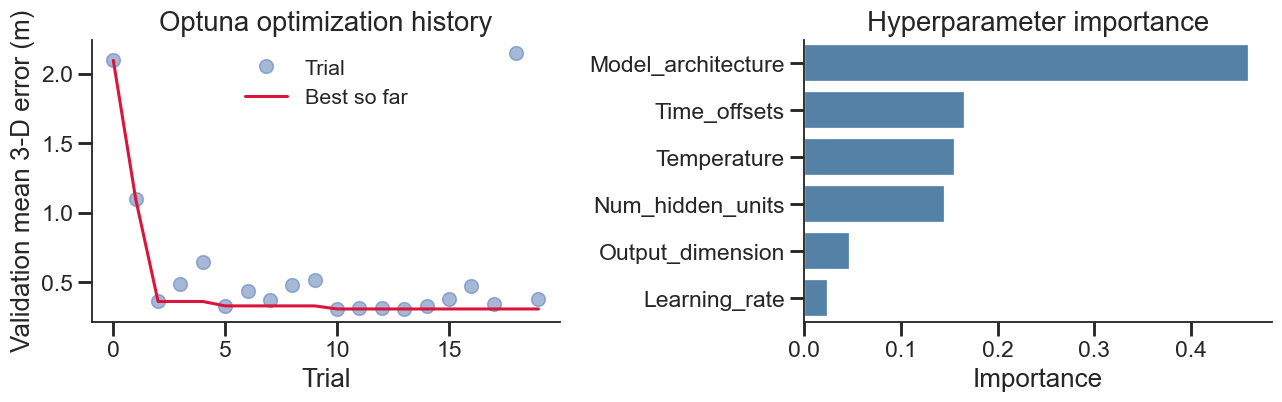

In [525]:
# === CEBRA hyperparameter search (Optuna) over the high-impact set ===
# TPE search minimising mean 3-D KNN-decoding error of position on the VALIDATION
# split (same KNN_N / cosine readout as Fig 1c; the test split is held out for the
# final Fig 1c report). Axes: num_hidden_units & output_dimension (same
# options as the coarse grid) plus temperature, time_offsets, learning_rate and
# the encoder receptive-field (offset) architecture. Each trial trains one
# unified CEBRA model, cached by _hp_tag(); the study is pickled (run-once).
# NOTE: cold cost ~= N_TRIALS CEBRA trainings (minus _hp_tag cache hits).

OUT_DIR, CEBRA_MAX_ITER, KNN_N, UNI_VARIANT = './out/cebra', 6000, 36, 'cebra_pos'
UNIFIED_MASKS = {'RandomNeuronMask': (0.3, 0.9, 0.05), 'RandomTimestepMask': (0.3, 0.9, 0.05)}
N_TRIALS = 20                                            # Optuna trials (encoded in the study/model paths)
_sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
# Hyperparameters are the Optuna sweep's best trial (no hardcoded default); the
# study pickle is produced by the CEBRA hyperparameter-search cell below.
CEBRA_STUDY_PATH = (f'{OUT_DIR}/cebra_hparam_optuna__it{CEBRA_MAX_ITER}_t{N_TRIALS}'
                    f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pkl')
CEBRA_HP = {}                                            # locked to the study's best trial below


def _hp_tag():
    a = CEBRA_HP['model_architecture'].replace('-model', '')
    return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
            f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}_h{CEBRA_HP['num_hidden_units']}")

def session_flights(session, split):
    bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
    bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
    out = []
    for batch in dataloaders[split][session]:
        m = batch.mask.numpy().astype(bool)
        spike = batch.spike.numpy(); pos_z = batch.behavior[:, :, :3].numpy()
        fpi = batch.flight_path_index.numpy()
        for b in range(m.shape[0]):
            sel = m[b]
            if sel.sum() == 0:
                continue
            out.append(dict(spike=spike[b, sel].astype(np.float32),
                            pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                            flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
    return out

def build_unified_solver(neuron_counts):
    model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                                num_units=CEBRA_HP['num_hidden_units'],
                                num_output=CEBRA_HP['output_dimension']).to(device)
    crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
    opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
    return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)

def fit_unified(Xs, Ys, path):
    solver = build_unified_solver([X.shape[1] for X in Xs])
    if os.path.exists(path):
        solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
        return solver
    dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                        continuous=Ys[i].astype(np.float32), device=device)
                for i in range(len(Xs))]
    dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
    dataset.set_masks(UNIFIED_MASKS); dataset.to(device)
    loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                        batch_size=512, time_offset=CEBRA_HP['time_offsets'])
    dataset.configure_for(solver.model)
    set_random_state(seed); solver.fit(loader)
    solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
    return solver

def unified_embed_split(solver, split):
    fb = {s: session_flights(s, split) for s in session_names}
    Xs_all = [np.vstack([f['spike'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Ys_all = [np.vstack([f['pos'] for f in fb[s]]).astype(np.float32) for s in session_names]
    Xt, Yt = [torch.from_numpy(X) for X in Xs_all], [torch.from_numpy(Y) for Y in Ys_all]
    solver = solver.to('cpu'); out = {}
    for i, s in enumerate(session_names):
        bs_ = min(512, max(2, len(Xs_all[i]) // 3))
        emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs_).cpu().numpy()
        pieces, c = [], 0
        for f in fb[s]:
            L = len(f['spike']); pieces.append((emb[c:c + L], f)); c += L
        out[s] = pieces
    solver.to(device)
    return out

# Unified-model training data: every session's train-split flights (shared by the Optuna
# search below and the Fig 1c decoder cell).
_train_by = {s: session_flights(s, 'train') for s in session_names}
Xs = [np.vstack([f['spike'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
Ys = [np.vstack([f['pos'] for f in _train_by[s]]).astype(np.float32) for s in session_names]

if optuna is not None:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HU_GRID = [32, 64, 128]                 # num_hidden_units (encoder width)
    OD_GRID = [3, 8, 32, 64]                # output_dimension (embedding dim)
    TO_GRID = [1, 5, 10, 20]                # time_offsets (positive-pair lag)
    ARCH_GRID = ['offset5-model', 'offset10-model', 'offset36-model']  # receptive field

    def _decode_score(model, split='valid'):
        """KNN(train)-decode 3-D position on the given split; per-point df. HP selection
        uses validation; the held-out test split is scored only for the final Fig 1c report."""
        tr, ev = unified_embed_split(model, 'train'), unified_embed_split(model, split)
        recs = []
        for s in session_names:
            Etr = np.vstack([e for e, _ in tr[s]]); Ytr = np.vstack([f['pos'] for _, f in tr[s]])
            knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, f in ev[s]:
                pred, true = np.asarray(knn.predict(emb)), f['pos']
                e3 = np.sqrt(((true - pred) ** 2).sum(1))
                for i in range(len(true)):
                    recs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                        t_idx=int(f['t_idx'][i]),
                                        x_true=true[i, 0], y_true=true[i, 1], z_true=true[i, 2],
                                        x_pred=pred[i, 0], y_pred=pred[i, 1], z_pred=pred[i, 2],
                                        err_3d=float(e3[i])))
        return pd.DataFrame(recs)

    def objective(trial):
        CEBRA_HP['num_hidden_units'] = trial.suggest_categorical('num_hidden_units', HU_GRID)
        CEBRA_HP['output_dimension'] = trial.suggest_categorical('output_dimension', OD_GRID)
        CEBRA_HP['time_offsets'] = trial.suggest_categorical('time_offsets', TO_GRID)
        CEBRA_HP['model_architecture'] = trial.suggest_categorical('model_architecture', ARCH_GRID)
        CEBRA_HP['temperature'] = trial.suggest_float('temperature', 0.1, 1.0, log=True)
        CEBRA_HP['learning_rate'] = trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True)
        path = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
        try:
            model = fit_unified(Xs, Ys, path)
            dfc = _decode_score(model, 'valid')
        except Exception as exc:
            print(f'  [prune] hu={CEBRA_HP["num_hidden_units"]} od={CEBRA_HP["output_dimension"]} '
                    f'arch={CEBRA_HP["model_architecture"]}: {type(exc).__name__}: {exc}')
            raise optuna.TrialPruned()
        trial.set_user_attr('median_frechet', float(frechet_per_flight(dfc)['frechet_3d'].median()))
        trial.set_user_attr('median_err_3d', float(dfc['err_3d'].median()))
        return float(dfc['err_3d'].mean())

    study_path = CEBRA_STUDY_PATH
    if os.path.exists(study_path):
        with open(study_path, 'rb') as fh:
            study = pickle.load(fh)
        print(f'loaded cached CEBRA study ({len(study.trials)} trials)')
    else:
        def _progress(study, trial):
            try:
                best = f'{study.best_value:.3f} m'
            except ValueError:
                best = 'n/a'
            err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
            ps = ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                            for k, v in trial.params.items())
            print(f'[trial {trial.number + 1}/{N_TRIALS}] err={err} | best={best} | {ps}', flush=True)

        set_random_state(seed)
        study = optuna.create_study(direction='minimize',
                                    sampler=optuna.samplers.TPESampler(seed=seed))
        print(f'CEBRA hyperparameter search: {N_TRIALS} trials...', flush=True)
        study.optimize(objective, n_trials=N_TRIALS, callbacks=[_progress])
        with open(study_path, 'wb') as fh:
            pickle.dump(study, fh)
    CEBRA_HP.clear(); CEBRA_HP.update(study.best_params)  # lock CEBRA_HP to the best trial

    res = study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs', 'state'))
    print(res.to_string(index=False))
    print('\nBest validation mean 3-D error: %.3f m' % study.best_value)
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    _done = sorted((t for t in study.trials if t.value is not None), key=lambda t: t.number)
    _vals = [t.value for t in _done]
    fig_o, axo = plt.subplots(1, 2, figsize=(12, 4))
    axo[0].plot(range(len(_vals)), _vals, 'o', alpha=0.5, label='trial')
    axo[0].plot(range(len(_vals)), np.minimum.accumulate(_vals), '-', color='crimson', label='best so far')
    axo[0].set_xlabel('trial'); axo[0].set_ylabel('validation mean 3-D error (m)')
    axo[0].set_title('Optuna optimization history'); axo[0].legend(frameon=False)
    try:
        imp = optuna.importance.get_param_importances(study)
        sns.barplot(x=list(imp.values()), y=list(imp.keys()), color='steelblue', ax=axo[1])
        axo[1].set_xlabel('importance'); axo[1].set_title('Hyperparameter importance')
    except Exception as exc:
        axo[1].text(0.5, 0.5, f'importance n/a\n{exc}', ha='center', va='center', transform=axo[1].transAxes)
    fig_o.tight_layout(); ph.save_fig(fig_o, 'cebra_hparam_optuna'); plt.show()

In [526]:
# === Fig 1c baseline: unified CEBRA decoder ===
# Load the frozen unified-CEBRA model at the Optuna-best HP -- the checkpoint selected by the
# search cell above (trained once there). A single forward pass yields BOTH the per-flight
# embeddings (uni_te, cached for the Fig 2 RSA) and the kNN 3-D position decode
# (cebra_decode_test, Fig 1c accuracy), so decode and RSA use the identical CEBRA model.
_CEBRA_CACHE = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
unified_model = fit_unified(Xs, Ys, _CEBRA_CACHE)        # loads the selected checkpoint (trains once if absent)
print(f'[CEBRA] unified model: {os.path.basename(_CEBRA_CACHE)}')

# `session_flights(s, 'train')` reads a SubsetRandomSampler loader, so the train flights come
# back in a fresh order every call, and CEBRA's unified transform is order-sensitive -- the kNN
# reference embeddings (and so the Fig 1c decode) jitter run to run. CEBRA_EMBED_SEED pins them;
# the test embed is already deterministic (SubsetSequentialSampler).
CEBRA_EMBED_SEED = 1
# The checkpoint above loads instantly, but embedding every flight through it costs ~2 min, and
# the result is fully determined by (checkpoint, CEBRA_EMBED_SEED, KNN_N) -- so cache the
# embeddings and the decode as well. The key is derived from _CEBRA_CACHE, so a new HP set /
# seed / session list gets its own file automatically; _split_tag additionally busts the cache
# when the loaders hand back a different number of flights (e.g. after a data-config change),
# which the session-name hash alone would not catch.
_split_tag = hashlib.md5(str([(s, len(dataloaders['train'][s].sampler),
                               len(dataloaders['test'][s].sampler))
                              for s in session_names]).encode()).hexdigest()[:6]
_CEBRA_EMBED_CACHE = _CEBRA_CACHE.replace(
    '.pt', f'__embed{CEBRA_EMBED_SEED}_k{KNN_N}_{_split_tag}__decode.pkl')


def _cebra_slim(split_emb):
    """Drop the per-flight spike matrices; Fig 1c and the Fig 2 cells only ever read the
    embedding plus flight_id / pos / t_idx, and the spikes would triple the cache size."""
    return {s: [(np.asarray(e, np.float32), {k: f[k] for k in ('flight_id', 'pos', 't_idx')})
                for e, f in v] for s, v in split_emb.items()}


if os.path.exists(_CEBRA_EMBED_CACHE):
    _cb = pd.read_pickle(_CEBRA_EMBED_CACHE)
    uni_tr, uni_te, cebra_decode_test = _cb['uni_tr'], _cb['uni_te'], _cb['decode']
    print(f'[CEBRA] embeddings + decode from cache: {os.path.basename(_CEBRA_EMBED_CACHE)}')
else:
    set_random_state(CEBRA_EMBED_SEED)
    uni_tr, uni_te = unified_embed_split(unified_model, 'train'), unified_embed_split(unified_model, 'test')
    crecs = []
    for s in session_names:
        Etr = np.vstack([e for e, _ in uni_tr[s]]); Ytr = np.vstack([f['pos'] for _, f in uni_tr[s]])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for _emb, f in uni_te[s]:   # `_emb`: a bare `emb` here would clobber the shared latent dict
            pred, true = np.asarray(knn.predict(_emb)), f['pos']
            e3 = np.sqrt(((true - pred) ** 2).sum(1))
            for i in range(len(true)):
                crecs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                  t_idx=int(f['t_idx'][i]), x_true=true[i, 0], y_true=true[i, 1],
                                  z_true=true[i, 2], x_pred=pred[i, 0], y_pred=pred[i, 1],
                                  z_pred=pred[i, 2], err_3d=float(e3[i])))
    cebra_decode_test = pd.DataFrame(crecs)
    # slim BEFORE saving so a cold run and a cache hit expose the identical structure
    uni_tr, uni_te = _cebra_slim(uni_tr), _cebra_slim(uni_te)
    pd.to_pickle(dict(uni_tr=uni_tr, uni_te=uni_te, decode=cebra_decode_test), _CEBRA_EMBED_CACHE)
    print(f'[CEBRA] embeddings + decode cached -> {os.path.basename(_CEBRA_EMBED_CACHE)}')
cebra_frechet = frechet_per_flight(cebra_decode_test)
print('unified CEBRA decode: %d points, %d flights' % (len(cebra_decode_test), len(cebra_frechet)))


[CEBRA] unified model: unified_cebra_pos__offset5_lr2e-04_t0.21_to1_d64_h32__it6000__seed1__s17_1f02daca.pt
[CEBRA] embeddings + decode from cache: unified_cebra_pos__offset5_lr2e-04_t0.21_to1_d64_h32__it6000__seed1__s17_1f02daca__embed1_k36_a381ed__decode.pkl
unified CEBRA decode: 8072 points, 278 flights


In [527]:
# === Fig 1c: decoding accuracy for NB (place), unified CEBRA, joint ===
DECODE_LABELS = {'naive_bayes': 'Naive Bayes', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
DECODE_ORDER = ['naive_bayes', 'cebra', 'joint']

# Assemble per-flight Fréchet (1g) across decoders.
_fr = [joint_frechet.assign(decoder='joint'), nb_frechet.assign(decoder='naive_bayes')]
if cebra_frechet is not None:
    _fr.append(cebra_frechet.assign(decoder='cebra'))

decode_frechet_df = pd.concat(_fr, ignore_index=True)
present = [d for d in DECODE_ORDER if d in set(decode_frechet_df['decoder'])]
decode_frechet_df['decoder'] = pd.Categorical(decode_frechet_df['decoder'], present, ordered=True)

# decode_frechet_df drawn in the merged Fig 1 cell below (panel c).


In [528]:
# === Fig 1d: dual-field example unit (spikes / empirical rate / predicted rate) ===
# The paper's reference "Dataset_3_26659_240404 unit 148" was a typo for bat 29959;
# we plot ONLY this one unit (Dataset_3_29959_240404 unit 148) and ONLY its 3-D maps.
# Edit FIG1C_PICKS to override.
FIG1C_PICKS = [('Dataset_3_29959_240404', 148)]   # the only unit plotted
# Flight clusters drawn as the panel-d rows, in order. select_dual_field_cells only
# ever returns the single *most separated* pair, but the panel needs three rows. The
# two point-to-point routes come first and each shows a single field: cluster 1
# (perch -> reward) fires at the perch, cluster 15 (reward -> perch, the return leg)
# fires at the reward. The loop (cluster 12, perch -> reward -> perch) is the payoff
# row and carries BOTH fields at once. Set to None to keep the auto-selected pair.
FIG1D_CLUSTERS = (1, 15, 12)

from scipy.ndimage import gaussian_filter1d
from notebook_helpers import (build_flight_records, select_dual_field_cells,
                              plot_dual_field_cell, loc_bin_width_rm)

dt = bin_width
dual_candidates = []
for sn, sd in dataloaders['test'].items():
    Xl, yl, pl, ml, fl = [], [], [], [], []
    with torch.no_grad():
        for batch in sd:
            X = batch.behavior.to(device); m = batch.mask.to(device)
            rate = bat_former(sn, X, m)
            Xl.append(X.cpu().numpy()); yl.append(batch.spike.numpy())
            pl.append(rate.cpu().numpy()); ml.append(m.cpu().numpy())
            fl.append(batch.flight_type_index.numpy())
    Xa, ya, pa = np.vstack(Xl), np.vstack(yl), np.vstack(pl)
    ma, fa = np.vstack(ml), np.hstack(fl)
    yflat, pflat = ya[ma == 1.0], pa[ma == 1.0]
    ncorr = corr(yflat, pflat, axis=0)
    nfde = poisson_fde_population(yflat, pflat)
    r_lim = meta_info_dict['r_lim'][sn]
    flights = build_flight_records(Xa, ya, pa, ma, fa,
                                   meta_info_dict['behavior_mean'][sn],
                                   meta_info_dict['behavior_std'][sn])
    # n_top large so a specifically-requested unit is captured, not just the top 2.
    for c in select_dual_field_cells(flights, ya.shape[2], dt, r_lim,
                                     loc_bin_width=loc_bin_width_rm, n_top=100):
        dual_candidates.append(dict(session=sn, bat=parse_bat(sn), flights=flights,
                                    r_lim=r_lim, corr=float(ncorr[c['neuron']]),
                                    fde=float(nfde[c['neuron']]), **c))

by_key = {(d['session'], d['neuron']): d for d in dual_candidates}
cand_df = pd.DataFrame([{k: d[k] for k in ('session', 'bat', 'neuron', 'sep', 'corr', 'fde')}
                        for d in dual_candidates]).sort_values('sep', ascending=False)
print('Top dual-field candidates:'); print(cand_df.head(12).to_string(index=False))

dual_candidates.sort(key=lambda d: d['sep'], reverse=True)
picks = []
for p in (FIG1C_PICKS or []):
    if tuple(p) in by_key:
        picks.append(by_key[tuple(p)])
    else:
        print(f'WARNING: {p} not a dual-field candidate (thresholds); skipping pin.')
if not picks:                                   # fall back: best-separated cell
    picks = [dual_candidates[0]]

pk = picks[0]   # dual-field example unit; drawn in the merged Fig 1 cell below
if FIG1D_CLUSTERS:                              # override the auto-selected pair
    _have = {f['cluster'] for f in pk['flights']}
    _missing = [c for c in FIG1D_CLUSTERS if c not in _have]
    if _missing:
        print(f'WARNING: clusters {_missing} absent from the test set; keeping {pk["clusters"]}.')
    else:
        pk = dict(pk, clusters=tuple(FIG1D_CLUSTERS))


def resample_along_path(a, n=120):
    """Resample a per-timestep array onto ``n`` evenly spaced points along the flight."""
    a = np.asarray(a, float)
    t, tn = np.linspace(0, 1, len(a)), np.linspace(0, 1, n)
    if a.ndim == 1:
        return np.interp(tn, t, a)
    return np.stack([np.interp(tn, t, a[:, k]) for k in range(a.shape[1])], 1)


# Per-cluster field location for the chosen unit, so the row-to-row alignment the
# panel claims is checkable rather than eyeballed.
pd_rows = []
for i, c in enumerate(pk['clusters']):
    fls = [f for f in pk['flights'] if f['cluster'] == c]
    path = np.mean([resample_along_path(f['xyz'][:, :3]) for f in fls], axis=0)
    prof = np.mean([gaussian_filter1d(resample_along_path(f['obs'][:, pk['neuron']] / dt),
                                      4.0, mode='nearest') for f in fls], axis=0)
    j = int(np.argmax(prof))
    pd_rows.append(dict(row=i + 1, cluster=c, n_flights=len(fls),
                        spikes=int(sum(f['obs'][:, pk['neuron']].sum() for f in fls)),
                        peak_hz=round(float(prof.max()), 1),
                        pct_along=round(100 * j / (len(prof) - 1)),
                        x=round(float(path[j, 0]), 2), y=round(float(path[j, 1]), 2),
                        z=round(float(path[j, 2]), 2)))
pd_field_df = pd.DataFrame(pd_rows)
print(f'\nFig 1d rows -- {pk["session"]} unit {pk["neuron"]} '
      f'(corr {pk["corr"]:.3f}, Poisson FDE {pk["fde"]:.3f}):')
print(pd_field_df.to_string(index=False))
_pk_xy = pd_field_df[['x', 'y']].to_numpy()
print('row-to-row field distance (m): '
      + ', '.join(f'{a}-{b}: {np.linalg.norm(_pk_xy[a - 1] - _pk_xy[b - 1]):.2f}'
                  for a in range(1, len(_pk_xy) + 1) for b in range(a + 1, len(_pk_xy) + 1)))

Top dual-field candidates:
               session   bat  neuron       sep     corr       fde
Dataset_2_14611_231209 14611      78 11.148543 0.176415  0.071404
Dataset_2_14611_231209 14611      52 10.568349 0.122482 -0.060501
Dataset_2_14611_231209 14611     101 10.504285 0.190466  0.059115
Dataset_2_14611_231209 14611      46 10.120277 0.472971  0.225906
Dataset_2_14611_231209 14611      39 10.062306 0.693367  0.472762
Dataset_2_14611_231209 14611     117 10.057833 0.455561  0.232107
Dataset_2_14611_231209 14611     141  9.918165 0.198467  0.132640
Dataset_2_14445_231209 14445     128  9.600000 0.494947  0.042341
Dataset_2_14611_231209 14611      50  9.319335 0.500841  0.210504
Dataset_2_14611_231209 14611     133  9.266067 0.526483  0.291148
Dataset_2_14611_231209 14611      38  9.044888 0.410632  0.143588
Dataset_2_14611_231209 14611      49  9.019978 0.460736  0.191572

Fig 1d rows -- Dataset_3_29959_240404 unit 148 (corr 0.697, Poisson FDE 0.510):
 row  cluster  n_flights  spikes  

In [529]:
# === Fig 1e/f (+ ED Fig 1e–h): per-neuron encoding fit for GLM place, GLM
# trajectory-specific place, and the joint transformer ===
# Train-only Fréchet single-linkage flight clustering (alpha=0.8) supplies the
# trajectory-cluster place fields for the "joint"-conditioned GLM (matches
# model_comparison.ipynb / decode-position-comparison.ipynb).
from collections import Counter
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from digitalbat.utility.utils import frechet_distance
from digitalbat.models.glm import (GLM_3DCosineBasis, GLM_Coupled,
                                   make_log_raised_cosine_basis)

CLUSTER_ALPHA, CLUSTER_DS, MIN_CLUSTER_FLIGHTS = 0.8, 7, 3
CLUSTER_MAX_ALPHA, UNCLUSTERED, N_LAGS = 1.5, -1, 10


def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    out = np.full((pos_xyz.shape[0], ds, 3), np.nan)
    for i in range(pos_xyz.shape[0]):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(loaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys = {}, {}
    for sn in loaders['train']:
        # meta is 13-dim (kinematic) under make_joint_dataloaders; take position (first 3).
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)[:3]
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = loaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
    return flight_cluster, cluster_keys


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array], dtype=torch.long)


flight_cluster, cluster_keys_by_session = compute_flight_clusters(dataloaders, meta_info_dict)

# --- Build + load the two GLMs and evaluate per-neuron FDE/corr on test.
# Searched anisotropic per-axis place-basis resolutions (fewer z; selected by the
# sparse->dense grid search in tmp/train_glm_flight_ladder.py, val-FDE-maximising).
# Coarse bases generalise better than the old fixed 16^3 (which was ~0 val FDE).
PLACE_RES, TRAJ_RES = (6, 6, 3), (4, 4, 2)
_glm_base = dict(pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                 activation='exp', bin_width=bin_width)


@torch.no_grad()
def eval_glm_metrics(model, joint_cond=False):
    model = model.to(device).eval()
    rows = []
    is_coupled = isinstance(model, GLM_Coupled)
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), sn, flight_cluster).to(device)
                  if (is_coupled and joint_cond) else None)
            if is_coupled:
                out = model(sn, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
            else:
                out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u,
                             corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


glm_place = ensure_glm('./out/bat_glm/bat_glm_position_seed_1_optuna_acc50_zbasis17.pth',
                       lambda: GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=PLACE_RES,
                                                 output_dim_dict=unit_num_dict),
                       cond='position')
glm_traj = ensure_glm('./out/bat_glm/bat_glm_joint_seed_1_optuna_acc50_zbasis17.pth',
                      lambda: GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base,
                                          n_bases_per_axis=TRAJ_RES, hist_basis=None,
                                          coup_basis=None, acausal_basis=None, n_lags=N_LAGS,
                                          cluster_keys=cluster_keys_by_session),
                      cond='joint', search_alpha=False)

ENC_LABELS = {'glm_place': 'GLM (place)', 'glm_traj': 'GLM (trajectory)', 'joint': OUR_MODEL}
ENC_ORDER = ['glm_place', 'glm_traj', 'joint']
encode_metrics_df = pd.concat([
    eval_glm_metrics(glm_place, joint_cond=False).assign(model='glm_place'),
    eval_glm_metrics(glm_traj, joint_cond=True).assign(model='glm_traj'),
    encode_eval_records(bat_former, dataloaders, device).assign(model='joint'),
], ignore_index=True)
encode_metrics_df['model'] = pd.Categorical(encode_metrics_df['model'], ENC_ORDER, ordered=True)
print('encode metrics rows:', len(encode_metrics_df))

encode metrics rows: 9240


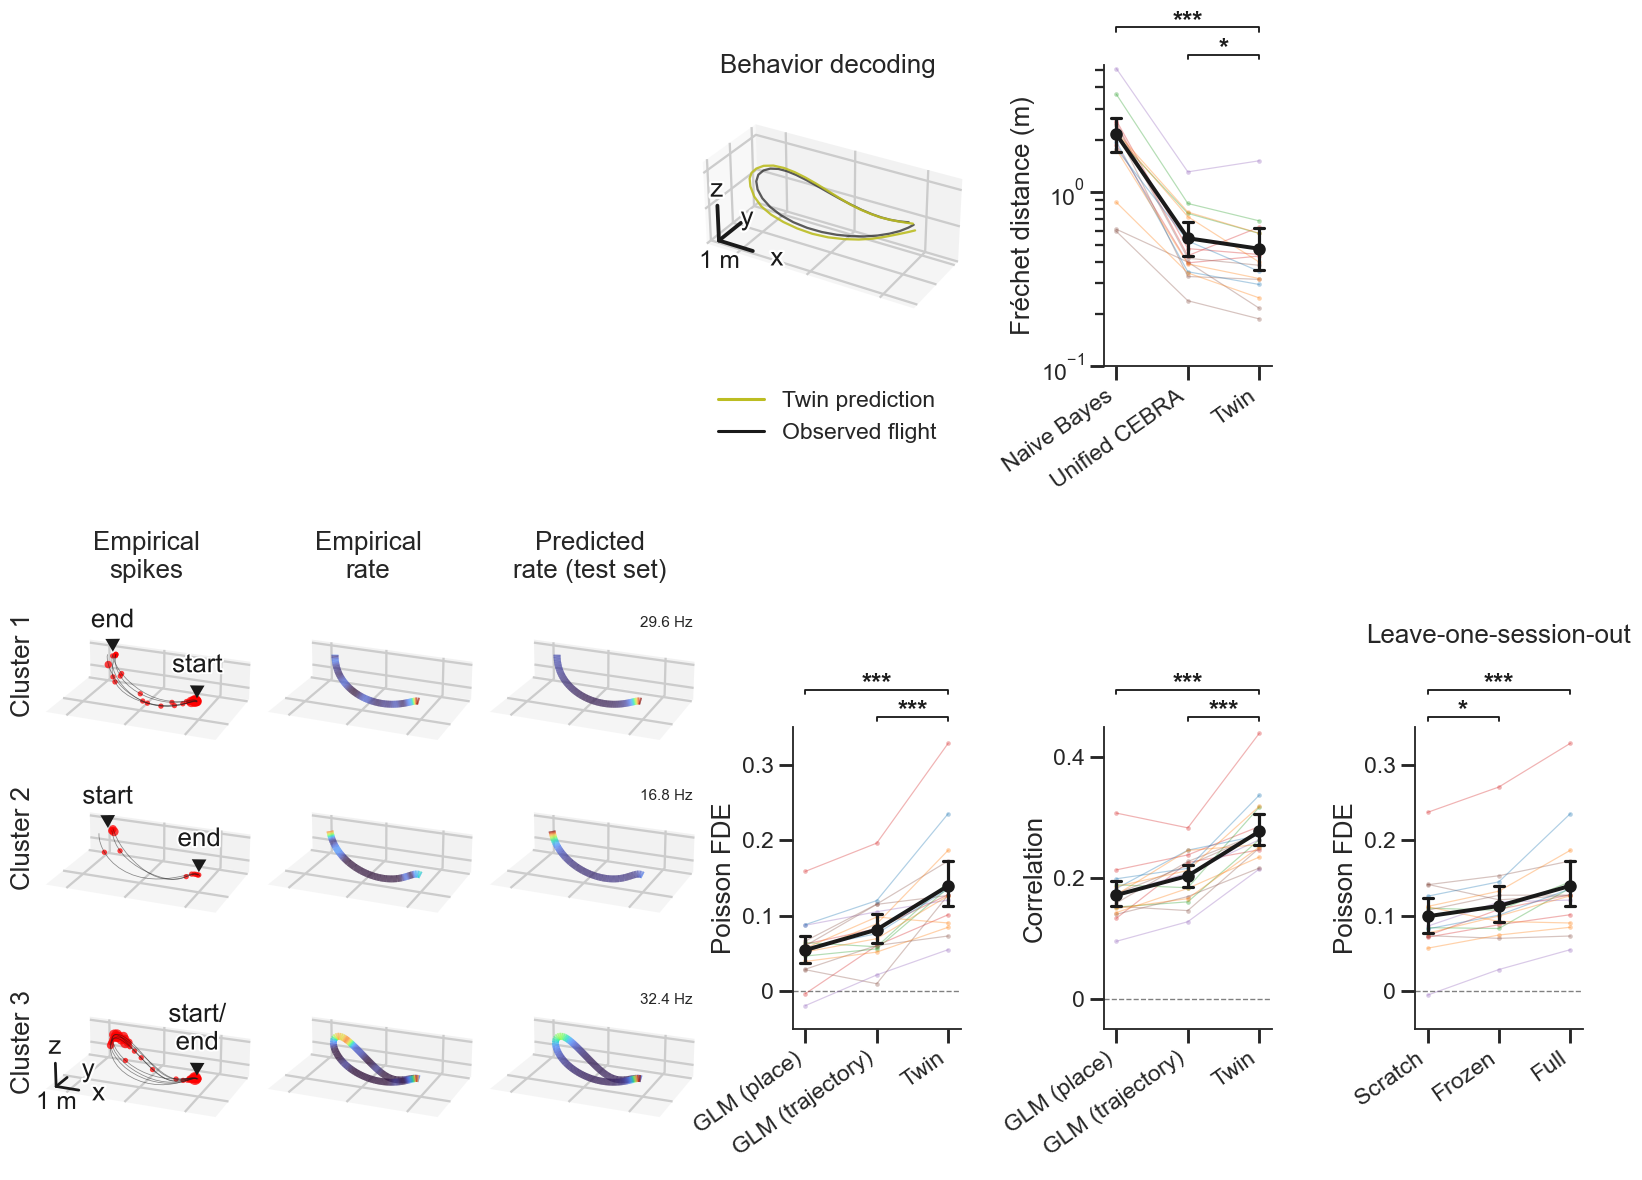


Fig 1e FDE - session-level Wilcoxon vs Twin (session medians):
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.0782 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.05691 3.052e-05   *** P < 0.001

Fig 1f Pearson r - session-level Wilcoxon vs Twin (session medians):
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1019 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.05515 1.526e-05   *** P < 0.001

Fig 1c Frechet - session-level Wilcoxon vs Twin (session medians):
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
      cebra joint 17      0.06751   0.04477     * P = 0.045

Fig 1c Frechet (per-flight) - pooled unit-level Wilcoxon vs Twin (per-unit stats, no panel):
      model    vs   n  median_diff         p stars         P
naive_bayes joint 278        1.306 4.971e-44   *** P < 0.001
      cebra joint 278      0.04117  0.003338    ** P =

In [847]:
# === Figure 1 (b-i) on a single canvas ===
# a is an external schematic (provided separately). Layout (wide canvas; the
# 3-D maps packed left, decode + encode metrics on the right):
#   top-left gap (schematic a)      | b (decoded 3D) | c(sess) c(flight)
#   d (left | center | right)  -- one row per flight cluster -- dual-field triptych
#   FDE(sess) FDE(neuron)  r(sess) r(neuron) -- one row, centred on the map rows
# Panels: b = decoding example; c = Fréchet distance; d = dual-field example
#   (left spikes | center empirical rate | right predicted rate); e = Poisson FDE; f = Pearson r.
#   i = leave-one-session-out transfer FDE (appended to the right of f).
# Font sizes are applied per-panel at the end (see _apply_panel_fonts) so every
# individual title / axis label / tick label / legend is the same size, whether
# or not ph.set_pub_style() was re-run this session.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 17, 17, 15, 15
FS_PEAK = 10          # per-row peak-rate annotation in panel d (deliberately small)

# Panel d contributes one map row per flight cluster. The canvas and the gridspec grow
# with it (6 in per row), so the row height -- and therefore every other panel -- is
# unchanged whether panel d shows 2 clusters or 3.
N_MAP_ROWS = len(pk['clusters'])
fig1 = plt.figure(figsize=(26, 6 * (1 + N_MAP_ROWS)))
gs1 = fig1.add_gridspec(1 + N_MAP_ROWS, 8, hspace=0.6, wspace=0.55,
                        width_ratios=[1, 1, 1, 0.3, 1, 1, 1, 1])

# b: example decoded 3-D trajectory (row 1, col 2; cols 0-1 are left as a gap)
ax_b = fig1.add_subplot(gs1[0, 4], projection='3d')
# draw the single example flight chosen above (a cleanly decoded rew→rew loop;
# see the Fig 1b selection cell) so the panel stays legible
_zoom_dec = joint_decode_test[joint_decode_test['session'] == zoom_session]
gfl = _zoom_dec[_zoom_dec['flight_id'] == example_flight].sort_values('t_idx')
ax_b.plot(gfl['x_true'], gfl['y_true'], gfl['z_true'], color='k', lw=1.5, alpha=0.7)
ax_b.plot(gfl['x_pred'], gfl['y_pred'], gfl['z_pred'], color='tab:olive', lw=1.5, alpha=0.9)
# axis limits: the room's full x and z (arena width, floor to ceiling), but only a
# padded y window around the flight -- set_box_aspect keeps 1 m equal on all three
# axes, so the room's 5.2 m depth squeezed this 1.7 m-deep loop into a ribbon.
_B_YPAD = 0.35      # m of room kept either side of the flight in y
_rlim_b = np.asarray(meta_info_dict['r_lim'][zoom_session], float)
_b_y = np.concatenate([gfl['y_true'].to_numpy(), gfl['y_pred'].to_numpy()])
ax_b.set_xlim(*_rlim_b[0]); ax_b.set_zlim(*_rlim_b[2])
ax_b.set_ylim(max(_b_y.min() - _B_YPAD, _rlim_b[1, 0]), min(_b_y.max() + _B_YPAD, _rlim_b[1, 1]))
ax_b.set_box_aspect([max(np.ptp(_l), 1e-3) for _l in (ax_b.get_xlim(), ax_b.get_ylim(), ax_b.get_zlim())])  # 1 m equal on x/y/z
nh.add_3d_scalebar(ax_b, corner=(0, 0, 0), fontsize=FS_LABEL, z_nudge=(0.0, 0.0, 0.075), hide_frame=False, label_weight='normal')  # scale bar; keep gridlines, drop tick/axis labels
ax_b.set_title('Behavior decoding')
# legend below the axes
ax_b.legend(handles=[plt.Line2D([], [], color='tab:olive', label=f'{OUR_MODEL} prediction'),
                     plt.Line2D([], [], color='k', label='observed flight')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=FS_LEG)

# c: decoding accuracy as per-flight 3-D Fréchet distance (row 1, cols 3-4)
ax_c = fig1.add_subplot(gs1[0, 5])   # decoding accuracy: session medians only
_, ptab_c = ph.compare_models_fig(
    decode_frechet_df, 'frechet_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False,
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_c, None))
# log y-axis for the Frechet (decoding-accuracy) panel
_flo, _fhi = ax_c.get_ylim()
ax_c.set_yscale('log')
ax_c.set_ylim(max(_flo, 0.1), _fhi)

# d: dual-field example unit, 3-D maps (map rows, cols 1-3); the three columns are the
# left (spikes), center (empirical rate), right (predicted rate) sub-panels, and there
# is one row per flight cluster in pk['clusters'].
ax_ex = np.array([[fig1.add_subplot(gs1[r + 1, cc], projection='3d') for cc in range(3)]
                 for r in range(len(pk['clusters']))], dtype=object)
# zoom the maps to the plotted flights (bigger trajectories than the full-arena r_lim)
_fl_plot = [f for f in pk['flights'] if f['cluster'] in pk['clusters']]
_fl_xyz = np.vstack([f['xyz'][:, :3] for f in _fl_plot])
_fl_lo, _fl_hi = _fl_xyz.min(0), _fl_xyz.max(0)
_fl_pad = 0.16 * (_fl_hi - _fl_lo) + 0.05       # small margin so start/end labels fit in-frame
_tight_rlim = [(float(_fl_lo[i] - _fl_pad[i]), float(_fl_hi[i] + _fl_pad[i])) for i in range(3)]
# turbo over its full range: both ends (navy, dark red) stay legible against the light
# grid panes, so the peak-normalised rate needs no cropping the way inferno did.
_RATE_CMAP = plt.get_cmap('turbo')
sm_ex = plot_dual_field_cell(pk['flights'], pk['neuron'], pk['clusters'], dt, _tight_rlim,
                            peaks=pk['peaks'], axes3d=ax_ex, col_title_fs=FS_TITLE, row_label_fs=FS_LABEL,
                            row_labels=[f'Cluster {i + 1}' for i in range(len(pk['clusters']))],
                            rate_cmap=_RATE_CMAP, startend='none')  # start/end drawn below
for _r, _cc in np.ndindex(ax_ex.shape):
    _axm = ax_ex[_r, _cc]
    nh.style_3d_grid_frame(_axm)  # panel-b look: keep the box + gridlines, drop ticks/labels
    nh.hide_3d_plane(_axm, 'yz')  # open the box: no constant-x wall, just floor + back
    _axm.patch.set_alpha(0.0)     # transparent canvas so neighbours do not cover overflow
    # the panes are opaque and the map slots overlap, so draw the columns back-to-front:
    # the spike column's start/end labels overflow rightward over its neighbour
    _axm.set_zorder(0.1 * (2 - _cc))
nh.add_3d_scalebar(ax_ex[-1, 0], corner=(0, 0, 0), fontsize=FS_LABEL, lw=1.8, y_nudge=(0.1, 0.0, 0.15), z_nudge=(0.0, 0.0, 0.3), origin_shift=(0.0, 0.0, 0.0), alpha=1.0, label_weight='normal', hide_frame=False)  # single triad for all panel-d maps (frame kept by the loop above)
ax_ex[0, 0].set_title('Empirical\nspikes', fontsize=FS_TITLE)
ax_ex[0, 1].set_title('Empirical\nrate', fontsize=FS_TITLE)
ax_ex[0, 2].set_title('Predicted\nrate (test set)', fontsize=FS_TITLE)  # wrap the long column title
# thicken the rate-coloured trajectory lines so the colour scale reads (empirical +
# predicted columns only; the spike-panel path/arrows are left untouched)
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DC
for _rr in range(ax_ex.shape[0]):
    for _cc in (1, 2):
        for _col in ax_ex[_rr, _cc].collections:
            if isinstance(_col, _L3DC):
                _col.set_linewidth(3.5); _col.set_alpha(0.9)
# enlarge the 3-D content inside each map panel (zoom>1 counteracts the default 3-D margin)
for _axm in ax_ex.flat:
    _axm.set_box_aspect([_h - _l for _l, _h in _tight_rlim], zoom=1.0)
# --- E/F: replace the many overlapping flights with ONE average trajectory coloured
# by the mean empirical / predicted rate (alpha declutter failed) ---
from mpl_toolkits.mplot3d.art3d import Line3DCollection as _L3DCavg
def _resamp(_a, _n):
    _a = np.asarray(_a, float); _t = np.linspace(0, 1, len(_a)); _tn = np.linspace(0, 1, _n)
    if _a.ndim == 1:
        return np.interp(_tn, _t, _a)
    return np.stack([np.interp(_tn, _t, _a[:, _d]) for _d in range(_a.shape[1])], 1)
_NAVG, _neu, _SM_SEC = 480, pk['neuron'], 0.05    # resample points; smoothing SD in seconds
# _NAVG=480 puts the resampled grid at ~5-9 ms/sample: the peaks are converged (they move by
# <0.02 Hz from 480 to 1920) and the drawn tube stops showing interpolation facets. Sigma is
# specified in real time, so it is invariant to _NAVG. NB _SM_SEC below dt (100 ms bins) only
# rounds the interpolation between bins; it cannot suppress Poisson noise, which lives at the
# bin scale.
from scipy.ndimage import gaussian_filter1d as _gf1d
def _smooth(_r, _n_bins):
    """Gaussian with sigma fixed at _SM_SEC seconds of REAL time (0 disables it). Every flight
    is resampled to _NAVG points from its own length, so a sigma constant in resampled samples
    would smooth the long loop flights (~42 bins) nearly twice as hard as the short
    point-to-point ones (~23)."""
    if not _SM_SEC:
        return _r
    return _gf1d(_r, _SM_SEC / dt * _NAVG / _n_bins, mode='nearest')
# Each cluster is peak-normalised on its own, so a quiet row is not washed out by a loud
# one, and the empirical/predicted pair of a row shares one scale so the amplitude
# difference between them stays readable. The divisor is the PAIR's peak rather than the
# empirical peak because this unit is over-predicted (6-49% here) -- normalising on the
# empirical peak would push the predicted map past the top of the colour scale and clip it.
# The absolute scale is not lost: each row is annotated with its empirical peak in Hz.
_avg, _row_peak = {}, {}
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _axyz = np.mean([_resamp(f['xyz'][:, :3], _NAVG) for f in _fls], axis=0)
    # both maps get the identical kernel (SD = _SM_SEC of real time). Filtering only the
    # empirical side maximises the peak asymmetry, since the prediction carries no Poisson
    # noise for a filter to remove; treating them the same keeps the comparison like-for-like.
    _emp = np.mean([_smooth(_resamp(f['obs'][:, _neu] / dt, _NAVG), len(f['obs']))
                    for f in _fls], axis=0)
    _prd = np.mean([_smooth(_resamp(f['pred'][:, _neu] / dt, _NAVG), len(f['obs']))
                    for f in _fls], axis=0)
    # the row's normalising constant = the larger of the two peaks, so the 'X.X Hz' label
    # below is exactly what full colour saturation means (usually the empirical peak; the
    # predicted one where the model over-predicts)
    _row_peak[_ci] = max(float(_emp.max()), float(_prd.max()), 1e-9)
    _avg[_ci] = (_axyz, _emp / _row_peak[_ci], _prd / _row_peak[_ci])
_norm = plt.Normalize(0.0, 1.0)
sm_ex.set_norm(_norm)          # trajectory colours are in peak-normalised units now
for _ci, (_axyz, _emp, _prd) in _avg.items():
    for _colc, _rate in ((1, _emp), (2, _prd)):
        _axm2 = ax_ex[_ci, _colc]
        for _oldc in list(_axm2.collections):
            _oldc.remove()
        # draw late->early so the early part of the flight is painted last within
        # the collection (on top), not occluded by the returning trajectory
        _axyz_r, _rate_r = _axyz[::-1], _rate[::-1]
        _pp = _axyz_r.reshape(-1, 1, 3); _sg = np.concatenate([_pp[:-1], _pp[1:]], axis=1)
        _lc = _L3DCavg(_sg, cmap=sm_ex.cmap, norm=_norm)
        _lc.set_array(0.5 * (_rate_r[:-1] + _rate_r[1:])); _lc.set_linewidth(4.5)
        _axm2.add_collection(_lc)
    # the colours are peak-normalised and no bar is drawn, so state the row's absolute
    # scale in its top-right corner.
    # y=0.79, not 1.0: a 3-D box only fills ~54% of its axes height, so the axes corner
    # floats halfway to the row above and the label loses its row
    ax_ex[_ci, 2].text2D(1.0, 0.79, f'{_row_peak[_ci]:.1f} Hz',
                         transform=ax_ex[_ci, 2].transAxes, ha='right', va='bottom',
                         fontsize=FS_PEAK, clip_on=False)
# --- start/end labels: raised, arrow straight down; 'start/end' wrapped for the loop ---
import matplotlib.patheffects as _peSE
from matplotlib.patches import FancyArrowPatch as _FAP
from mpl_toolkits.mplot3d import proj3d as _proj3d
class _Arrow3D(_FAP):
    def __init__(self, _xs, _ys, _zs, *a, **k):
        super().__init__((0, 0), (0, 0), *a, **k); self._v3d = (_xs, _ys, _zs)
    def do_3d_projection(self, renderer=None):
        _x, _y, _z = self._v3d
        _xp, _yp, _zp = _proj3d.proj_transform(_x, _y, _z, self.axes.M)
        self.set_positions((_xp[0], _yp[0]), (_xp[1], _yp[1]))
        return float(np.min(_zp))
def _draw_se(_ax, _starts, _ends):
    _stk = [_peSE.withStroke(linewidth=2.5, foreground='white')]
    _dz = 0.6 * (_tight_rlim[2][1] - _tight_rlim[2][0])
    _cs = np.asarray(_starts, float).mean(0); _ce = np.asarray(_ends, float).mean(0)
    _items = [((_cs + _ce) / 2, 'start/\nend')] if np.linalg.norm(_cs - _ce) < 0.6 \
        else [(_cs, 'start'), (_ce, 'end')]
    for _pt, _lab in _items:
        _top = _pt + np.array([0.0, 0.0, _dz])
        _ar = _Arrow3D([_top[0], _pt[0]], [_top[1], _pt[1]], [_top[2], _pt[2]], color='k',
                       arrowstyle='-|>,head_width=0.4,head_length=0.7', mutation_scale=12,
                       lw=0, zorder=6, clip_on=False)   # stem hidden, just the head
        _ax.add_artist(_ar)
        _ax.text(_top[0], _top[1], _top[2], _lab, color='k', fontsize=FS_LABEL,
                 ha='center', va='bottom', zorder=7,
                 path_effects=_stk, clip_on=False)
for _ci, _c in enumerate(pk['clusters']):
    _fls = [f for f in pk['flights'] if f['cluster'] == _c]
    _draw_se(ax_ex[_ci, 0], [f['xyz'][0, :3] for f in _fls], [f['xyz'][-1, :3] for f in _fls])
# let the start/end labels + arrows overflow their panels instead of clipping
for _rr in range(ax_ex.shape[0]):
    for _ch in ax_ex[_rr, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text() in ('start', 'end', 'start/end'):
            _ch.set_clip_on(False)
    for _col in ax_ex[_rr, 0].collections:
        _col.set_clip_on(False)
# nudge the "Cluster N" row labels up a bit
for _r in range(ax_ex.shape[0]):
    for _ch in ax_ex[_r, 0].get_children():
        if hasattr(_ch, 'get_text') and _ch.get_text().startswith('Cluster'):
            _lx, _ly = _ch.get_position()
            _ch.set_position((_lx, _ly + 0.12))
# shrink horizontal gaps between the 3 map columns to match the comparison-pair pull:
# pull the outer columns (c spikes, e predicted) toward the fixed centre (d empirical)
_MAP_PULL = 0.030
for _r in range(ax_ex.shape[0]):
    for _cc, _sh in ((0, _MAP_PULL), (2, -_MAP_PULL)):
        _pm = ax_ex[_r, _cc].get_position()
        ax_ex[_r, _cc].set_position([_pm.x0 + _sh, _pm.y0, _pm.width, _pm.height])
# raise every map row below the first to tighten the inter-cluster gaps. The shift
# is fixed in inches rather than figure fractions, so the gap reads the same at any
# row count.
_ROW_UP = 0.18 * 18 / fig1.get_figheight()
for _r2 in range(1, ax_ex.shape[0]):
    for _axm2 in ax_ex[_r2, :]:
        _pm2 = _axm2.get_position()
        _axm2.set_position([_pm2.x0, _pm2.y0 + _ROW_UP * _r2, _pm2.width, _pm2.height])

# e, f: encoding fit (rows 2-3, cols 4-5) -- e = Poisson FDE, f = Pearson r
ax_e = fig1.add_subplot(gs1[1, 4])
_, ptab_e = ph.compare_models_fig(
    encode_metrics_df, 'fde', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Poisson FDE', unit_name='neuron', clip=(-0.6, 1.0), zero_line=True, sess_ylim=(-0.05, 0.35),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_e, None))
ax_f = fig1.add_subplot(gs1[1, 6])
_, ptab_f = ph.compare_models_fig(
    encode_metrics_df, 'corr', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Correlation', unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.05, 0.45),
    star_style='bracket', star_kw={'star_gap': -0.025}, title_y=1.21, show_titles=False, axes=(ax_f, None))

# shrink the 2-D comparison panels so they match the (margin-padded) 3-D panels and
# their tick labels don't collide with neighbours
def _shrink(ax, fx=0.82, fy=0.86):
    p = ax.get_position()
    ax.set_position([p.x0 + p.width * (1 - fx) / 2, p.y0 + p.height * (1 - fy) / 2,
                     p.width * fx, p.height * fy])
for _ax in (ax_e, ax_f, ax_c):
    _shrink(_ax)

# fine layout nudges: panel b (decode example) a touch right; the first map row
# (flight cluster 1 maps) a touch down
_A_DX, _ROW2_DY = 0.015, 0.012
_pf = ax_b.get_position()
ax_b.set_position([_pf.x0 + _A_DX, _pf.y0, _pf.width, _pf.height])
for _ax in list(ax_ex[0, :]):
    _p = _ax.get_position()
    _ax.set_position([_p.x0, _p.y0 - _ROW2_DY, _p.width, _p.height])
# centre the FDE + Correlation strip vertically across the map rows
_map_y1 = ax_ex[0, 0].get_position().y1    # top of the first map row (after its down-nudge)
_map_y0 = ax_ex[-1, 0].get_position().y0   # bottom of the last map row (after its raise)
_strip_cy = (_map_y0 + _map_y1) / 2
for _mx in (ax_e, ax_f):
    _pm = _mx.get_position()
    _mx.set_position([_pm.x0, _strip_cy - _pm.height / 2, _pm.width, _pm.height])
# session-median columns keep the ORIGINAL x-positions so the maps, decode example and
# schematic-a space all stay put; the removed per-neuron / per-flight columns just vanish.
# FDE stays leftmost, Correlation slides in next to it, Frechet-session keeps its row-1 slot.
_R, _MGAP = 0.965, 0.05
_MW = ax_e.get_position().width
_PITCH = _MW + _MGAP
_X0 = _R - _MW - 3 * _PITCH                    # FDE-session column (maps abut here)
for _ax, _xx in ((ax_e, _X0), (ax_f, _X0 + _PITCH), (ax_c, _X0 + _PITCH)):
    _p = _ax.get_position()
    _ax.set_position([_xx, _p.y0, _MW, _p.height])
# pack each example against its quant panels (close the mid-canvas gap), leaving
# only enough room for the quant y-axis labels / panel-b z-axis; empty space is
# pushed to the top-left for the external schematic a
_MAP_GAP, _B_GAP = 0.035, 0.05
_fde_left = _X0                            # maps abut the FDE column (original position)
_fr_left = _X0 + _PITCH                    # panel b abuts the (left-shifted) Frechet column (aligned under Correlation)
# encoding: slide the whole 3-D map block right so it abuts the FDE columns
_map_right = max(ax_ex[_r, 2].get_position().x1 for _r in range(ax_ex.shape[0]))
_dmap = _fde_left - _MAP_GAP - _map_right
for _axm in ax_ex.flat:
    _p = _axm.get_position()
    _axm.set_position([_p.x0 + _dmap, _p.y0, _p.width, _p.height])
# decoding: slide panel b right so it abuts the Frechet columns
_pb = ax_b.get_position()
_bw, _bh = _pb.width * 1.3, _pb.height * 1.3       # enlarge the decode example
ax_b.set_position([_fr_left - _B_GAP - _bw, _pb.y0 + _pb.height / 2 - _bh / 2, _bw, _bh])

# tighten the vertical gap between the top row (decode example + Frechet) and the
# maps/metrics row below by lowering the whole top row a touch
_TOPROW_DOWN = 0.045
for _tr_ax in (ax_b, ax_c):
    _tp = _tr_ax.get_position()
    _tr_ax.set_position([_tp.x0, _tp.y0 - _TOPROW_DOWN, _tp.width, _tp.height])

# E-F (FDE + Correlation) y-ticks: <=1 decimal place, drop trailing '.0' (1.0->1,
# 0.0->0), and avoid quarter steps (0.25 / 0.75)
from matplotlib.ticker import MaxNLocator as _MaxNLoc, FuncFormatter as _FuncFmt
def _ytick_fmt(_v, _p):
    _s = f'{_v:.1f}'.rstrip('0').rstrip('.')
    return '0' if _s in ('-0', '') else _s
for _mx in (ax_e, ax_f):
    _mx.yaxis.set_major_locator(_MaxNLoc(nbins=4, steps=[1, 2, 5, 10]))
    _mx.yaxis.set_major_formatter(_FuncFmt(_ytick_fmt))

# --- Panel I: joint-model transfer, Poisson FDE session medians (absorbs the former
# ED Fig 5). Leave-one-session-out only, placed to the RIGHT of the Correlation panel
# with the row above left empty. Modes scratch / frozen / full (the main joint model
# already drawn above = the skyline); fine-tune is omitted here. Brackets + 3-tier stars
# = session-level Wilcoxon vs scratch. Regenerate the pkls with
# `python training/train_joint_transfer.py`.
_TJ_ROOT, _TJ_MODES = './out/transfer_joint', ['scratch', 'frozen', 'full']
# 'full' = the main joint model (Fig 1b,e,f) appended as a 3rd box
_full_enc_tj = encode_metrics_df.loc[encode_metrics_df['model'] == 'joint',
                                     ['session', 'bat', 'unit', 'fde']].assign(mode='full')
def _load_tj_f1(_g):
    _p = f'{_TJ_ROOT}/{_g}/results_{_g}_encode.pkl'
    return pd.read_pickle(_p) if os.path.exists(_p) else pd.DataFrame()
_TJ_CV = [('session', 'Leave-one-session-out')]
ptab_tj = []
if all(_load_tj_f1(_g).empty for _g, _ in _TJ_CV):
    print('Fig 1 transfer row: no joint-transfer results on disk — '
          'run `python training/train_joint_transfer.py` first.')
else:
    # Panel I sits to the RIGHT of the Correlation panel (ax_f), aligned to it; the
    # row above is left intentionally empty. No canvas compression / bottom row.
    _tj_axes = {}
    for _gi, (_grp, _gtitle) in enumerate(_TJ_CV):
        _df = pd.concat([_load_tj_f1(_grp), _full_enc_tj], ignore_index=True)
        _pf = ax_f.get_position()                        # Correlation panel
        _axs = fig1.add_axes([_pf.x1 + _MGAP, _pf.y0, _pf.width, _pf.height])
        _, _pt = ph.compare_models_fig(
            _df, 'fde', _TJ_MODES, ref='scratch', model_col='mode', ylabel='Poisson FDE',
            unit_name='neuron', clip=(-1, 1), sess_ylim=(-0.05, 0.35), zero_line=True,
            higher_is_better=True, star_style='bracket', star_kw={'star_gap': -0.025},
            show_titles=False, show_xticklabels=True, show_sess_ylabel=True, axes=(_axs, None))
        _tj_axes[_gi] = _axs
        ptab_tj += [dict(cv=_gtitle, level='session median', **_r) for _r in _pt.to_dict('records')]
        _upt = ph.pooled_ptable(_df, 'fde', _TJ_MODES, 'scratch', ['session', 'unit'],
                                model_col='mode', higher_is_better=True)
        ptab_tj += [dict(cv=_gtitle, level='per neuron', **_r) for _r in _upt.to_dict('records')]
    # CV-scheme header (single line) just above the panel
    fig1.canvas.draw()
    _HDR_OFF = 0.03
    for _gi, (_, _gtitle) in enumerate(_TJ_CV):
        _pa = _tj_axes[_gi].get_position()
        fig1.text((_pa.x0 + _pa.x1) / 2, _pa.y1 + _HDR_OFF, _gtitle,
                  ha='center', va='bottom', fontsize=FS_TITLE)

# Enforce a single consistent font size on every panel individually (titles, x/y/z
# axis labels, tick labels, and legend text), so nothing depends on the global
# rcParams having been refreshed by ph.set_pub_style() this session.
def _apply_panel_fonts(ax):
    ax.title.set_fontsize(FS_TITLE)
    ax.xaxis.label.set_fontsize(FS_LABEL)
    ax.yaxis.label.set_fontsize(FS_LABEL)
    if hasattr(ax, 'zaxis'):
        ax.zaxis.label.set_fontsize(FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    _lg = ax.get_legend()
    if _lg is not None:
        for _t in _lg.get_texts():
            _t.set_fontsize(FS_LEG)
        if _lg.get_title() is not None:
            _lg.get_title().set_fontsize(FS_LEG)
for _ax in fig1.get_axes():
    _apply_panel_fonts(_ax)

# let edge swarm dots overflow their axes instead of being cropped (2-D panels only), and
# nudge the y-axis a hair left so the leftmost swarm doesn't touch it
from matplotlib.collections import PathCollection as _PathColl
for _ua in fig1.get_axes():
    if hasattr(_ua, 'zaxis'):          # skip 3-D map / decode panels
        continue
    _has_swarm = False
    for _uc in _ua.collections:
        if isinstance(_uc, _PathColl):
            _uc.set_clip_on(False)
            _has_swarm = True
    if _has_swarm:
        _xl = _ua.get_xlim()
        _ua.set_xlim(_xl[0] - 0.15, _xl[1])
ph.save_fig(fig1, 'fig1_full'); plt.show()
for _n, _pt in [('1e FDE', ptab_e), ('1f Pearson r', ptab_f), ('1c Frechet', ptab_c)]:
    print(f'\nFig {_n} - session-level Wilcoxon vs {OUR_MODEL} (session medians):'); ph.p_table(_pt.to_dict('records'))
for _n, _df, _v, _o, _mc, _id, _hib in [
        ('1c Frechet (per-flight)', decode_frechet_df, 'frechet_3d', present, 'decoder', ['session', 'flight_id'], False),
        ('1e FDE (per-neuron)', encode_metrics_df, 'fde', ENC_ORDER, 'model', ['session', 'unit'], True),
        ('1f Pearson r (per-neuron)', encode_metrics_df, 'corr', ENC_ORDER, 'model', ['session', 'unit'], True)]:
    print(f'\nFig {_n} - pooled unit-level Wilcoxon vs {OUR_MODEL} (per-unit stats, no panel):')
    ph.p_table(ph.pooled_ptable(_df, _v, _o, 'joint', _id, model_col=_mc, higher_is_better=_hib).to_dict('records'))
if ptab_tj:
    print('\nFig 1 transfer row (Poisson FDE) - Wilcoxon vs scratch:'); ph.p_table(ptab_tj)

**Figure 1 | A transformer-based functional digital Twin outperforms standard approaches on hippocampal data.** (A) Twin model architecture. Subsequent figures analyze particular components of the model, specifically the latent embeddings (Figures 2-3) and neural readout weights (Figure 4). \textit{B} = batch size = number of flights, \textit{T} = sequence length = number of time bins, \textit{N} = number of neurons per session, \textit{E} = number of environments, \textit{L} = number of transformer layers, \textit{D} = transformer latent dimension, \textit{ELU} = Exponential Linear Unit nonlinearity, \textit{NLL} = negative log likelihood, \textit{$\lambda$} = decoding weight, \textit{MSE} = mean squared error. For further details see \nameref{sec:methods}. (B) Representative decoded (olive) versus observed (black) 3-D flight trajectory from the Twin decoder. (C) Decoding accuracy as per-flight 3-D discrete Fréchet distance (lower is better) for a `Naïve Bayes' place decoder, `Unified CEBRA' decoder, and the digital Twin model. Here and for all similar plots throughout the paper, thin lines show individual sessions (per-session medians) colored by bat, connected across conditions, and the thick black point-range gives the across-session mean $\pm$ 95\% CI; n = 17 sessions. Wilcoxon vs the Twin: `Naïve Bayes' ($P = 1.53 \times 10^{-5}$), `Unified CEBRA' ($P = 0.0448$). (D) An example unit with spatially separated place fields on three different flight clusters (\textit{rows}). Flight start and end are indicated. \textit{Left}, observed spikes (red dots, area $\propto$ binned spike count) on the black flight paths; \textit{center}, mean empirical firing rate map; \textit{right}, the Twin's mean predicted rate map. Within each row, the empirical and predicted maps share one color scale, normalized to the larger of their two peaks; \textit{inset}, that peak rate. (E-F) Encoding fit quantified as per-neuron Poisson fraction deviance explained (FDE, E) and Pearson correlation (F) between predicted and observed spike trains; the GLMs fail to capture the structure the Twin recovers. Wilcoxon vs the Twin: (E) `place GLM' ($P = 1.53 \times 10^{-5}$), `trajectory-specific GLM' ($P = 3.05 \times 10^{-5}$); (F) `place GLM' and `trajectory-specific GLM' both $P = 1.53 \times 10^{-5}$. (G) Schematic of transfer analysis. Model architecture is identical to (A). All model weights were frozen (snowflake icons) except for the session-specific neural readout weights, which were trained (fire icons). (H) For each held-out session, a new base model was trained and then frozen as in (G) before fine-tuning the readouts on the held-out session. (I) Poisson FDE for the Twin, either retrained from scratch on a single session, transferred to the held-out session with readout fine-tuning only (G-H), or evaluated on the full 17-session model (E). Wilcoxon vs from-scratch: `frozen' $P = 0.0174$ and `full' $P = 2.90 \times 10^{-4}$. Here and for all figures, $^{*}P < 0.05$, $^{**}P < 0.01$, $^{***}P < 0.001$; n.s. comparisons are unmarked. N = 17 sessions from 6 bats; decoding and encoding performance is measured on a held-out test set not used for fitting or hyperparameter selection. Unless otherwise indicated, data is colored by bat consistently across figures. See also Figures \ref{fig:S1}-\ref{fig:S3}.

---
## Extended Data Figure 1 — full model ladders

**a–c** External schematics (flight room; masked-transformer input tensors; encode/decode/infill masking strategies), drawn separately. **d** Per-flight decoding accuracy (3-D Fréchet distance) for the full decoder ladder from `decode-position-comparison.ipynb`. **e–h** Per-neuron encoding fit for every model in `model_comparison.ipynb`: Poisson FDE and Pearson r for the behaviour-only encoders (**e**, **f**) and for the neural-data GLMs that additionally condition on spike history / coupling / future spiking (**g**, **h**). Stars: session-level Wilcoxon vs the joint (Twin) model. (`GLM + lags + kin' is omitted — it requires the kinematics-augmented behavior, incompatible with the position-only single load; re-enable with a separate kinematics loader if needed.)

In [16]:
# === ED Fig 1d/e: all encoding models (per-neuron FDE + corr) ===
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (make_model_config, make_model_name,
                                              DEFAULT_LR, DEFAULT_WEIGHT_DECAY)
from digitalbat.models.glm import make_symmetric_raised_cosine_basis

# Temporal-filter bases (match model_comparison.ipynb).
HIST_N_BASIS, COUP_N_BASIS, ACAUSAL_N_BASIS = 6, 4, 6
hist_basis, _, _ = make_log_raised_cosine_basis(HIST_N_BASIS, N_LAGS, bin_width)
coup_basis, _, _ = make_log_raised_cosine_basis(COUP_N_BASIS, N_LAGS, bin_width, include_zero_lag=True)
acausal_basis, _, _ = make_symmetric_raised_cosine_basis(ACAUSAL_N_BASIS, N_LAGS, bin_width)
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()
DATA_TAG, GLM_TAG = '_acc50_preln_17_sess', '_acc50_zbasis17'


def build_glm(name, cond):
    ck = cluster_keys_by_session if cond == 'joint' else None
    res = PLACE_RES if cond == 'position' else TRAJ_RES  # searched per-axis (fewer z)
    if name == 'GLM' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=res, output_dim_dict=unit_num_dict)
    if name == 'GLM + lags' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_base, n_bases_per_axis=res, output_dim_dict=unit_num_dict, lag_seconds=glm_lags)
    if name == 'GLM + lags':   # cond == 'joint' -> per-cluster lagged place GLM (trajectory)
        return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=res,
                           lag_seconds=glm_lags, cluster_keys=ck)
    return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=res,
                       hist_basis=hist_basis if 'hist' in name else None,
                       coup_basis=coup_basis if 'coup' in name else None,
                       acausal_basis=acausal_basis if 'acausal' in name else None,
                       n_lags=N_LAGS, cluster_keys=ck)


def glm_ckpt(name, cond):
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_{cond}_seed_{seed}_optuna{GLM_TAG}.pth'


# Full-arch transformer config from the pre-LN Optuna search.
import json as _json
_ep = f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'
_arch = ({k: _json.load(open(_ep))[k] for k in ('latent_dim', 'ff_dim', 'num_layers', 'dropout_prob')
          if k in _json.load(open(_ep))} if os.path.exists(_ep) else {})
base_cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, **_arch)


def build_former(kind):
    if kind == 'transformer':
        return Bat_Transformer(**base_cfg)
    if kind == 'mlp':
        return Bat_Transformer(**{**base_cfg, 'use_attention': False})
    return Bat_Transformer(**{**base_cfg, 'latent_dim': 32, 'ff_dim': 32, 'num_layers': 1})


@torch.no_grad()
def eval_former_metrics(model):
    model = model.to(device).eval()
    rows = []
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


# Registry: (display label, kind, spec). Joint GLMs get a '(joint)' suffix.
# GLMs are grouped by INPUT: the behaviour-alone GLMs (place / trajectory-cluster
# place fields, +/- lags -- no neural input) come first, then the neural-data GLMs
# (Pillow-style spike history / coupling / acausal self-filters). A blank spacer
# (injected below) separates the two groups in ED Fig 1d/e.
ED1_MODELS = [
    # --- behaviour-alone GLMs (position / trajectory-cluster place fields, +/- lags) ---
    ('GLM (place)',                    'glm',    ('GLM', 'position')),
    ('GLM + lags (place)',             'glm',    ('GLM + lags', 'position')),
    ('GLM (trajectory)',               'glm',    ('GLM', 'joint')),
    ('GLM + lags (trajectory)',        'glm',    ('GLM + lags', 'joint')),
    # --- neural-data GLMs (spike history / coupling / acausal self-filter) ---
    ('GLM + hist (place)',             'glm',    ('GLM + hist', 'position')),
    ('GLM + coup (place)',             'glm',    ('GLM + coup', 'position')),
    ('GLM + hist + coup (place)',      'glm',    ('GLM + hist + coup', 'position')),
    ('GLM + acausal (place)',          'glm',    ('GLM + acausal', 'position')),
    ('GLM + hist (trajectory)',        'glm',    ('GLM + hist', 'joint')),
    ('GLM + coup (trajectory)',        'glm',    ('GLM + coup', 'joint')),
    ('GLM + hist + coup (trajectory)', 'glm',    ('GLM + hist + coup', 'joint')),
    ('GLM + acausal (trajectory)',     'glm',    ('GLM + acausal', 'joint')),
    ('MLP only',                       'former', 'mlp'),
    (OUR_MODEL,                       'joint',  None),
]
ED1_ORDER = [m[0] for m in ED1_MODELS]
BEHAV_ONLY_GLMS = ['GLM (place)', 'GLM + lags (place)',
                   'GLM (trajectory)', 'GLM + lags (trajectory)']

_pieces = []
for label, kind, spec in ED1_MODELS:
    try:
        if kind == 'glm':
            name, cond = spec
            gm = ensure_glm(glm_ckpt(name, cond), lambda: build_glm(name, cond),
                            cond=cond, search_alpha=('coup' in name))
            df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
        elif kind == 'former':
            ck = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                 out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                                          'small': './out/bat_former_small'}[spec], suffix=DATA_TAG)
            fm = ensure_former(ck, lambda: build_former(spec))
            df = eval_former_metrics(fm)
        else:
            df = encode_eval_records(bat_former, dataloaders, device)
        _pieces.append(df.assign(model=label))
        print(f'  ok: {label}')
    except Exception as exc:
        print(f'  [skip {label}] {type(exc).__name__}: {exc}')

ed1_encode_df = pd.concat(_pieces, ignore_index=True)
ed1_present = [m for m in ED1_ORDER if m in set(ed1_encode_df['model'])]
ed1_encode_df['model'] = pd.Categorical(ed1_encode_df['model'], ed1_present, ordered=True)
print('ED1 encode models:', ed1_present)

  ok: GLM (place)
GLM: 11 lags x 108 spatial = 1188 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok: GLM + lags (place)
  ok: GLM (trajectory)
  ok: GLM + lags (trajectory)
  ok: GLM + hist (place)
  ok: GLM + coup (place)
  ok: GLM + hist + coup (place)
  ok: GLM + acausal (place)
  ok: GLM + hist (trajectory)
  ok: GLM + coup (trajectory)
  ok: GLM + hist + coup (trajectory)
  ok: GLM + acausal (trajectory)
  ok: MLP only
  ok: Twin
ED1 encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM (trajectory)', 'GLM + lags (trajectory)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


In [17]:
# === Tampuu et al. (2019) LSTM-RNN decoder: Optuna search + train (ED Fig 1) ===
# Reference implementation: github.com/NeuroCSUT/RatGPS (ratlstm.py / ratdata.py).
# Their decoder is a many-to-one LSTM (2x512 units, dropout 0.5, linear head,
# MSE loss, RMSprop) fed a sequence of spike-count vectors and asked to predict
# the position at the last timestep. We port it to the multi-session bat setting
# as the ED Fig 1 'LSTM-RNN' rung: a per-session linear readin (neurons ->
# hidden -- the minimal change needed to share one recurrent core across
# sessions with different neuron counts) feeds a UNIDIRECTIONAL LSTM (causal, as
# in Tampuu, who explicitly reject bidirectional), and a shared linear head maps
# each timestep's hidden state to z-scored 3D position. Because the loss/eval are
# masked over every valid timestep of a flight (rather than one per sequence),
# the causal LSTM is effectively "many-to-one at every timestep". Training reuses
# the package `bat_decoder_trainer` (round-robin across sessions, masked loss).
# Hyperparameters are Optuna-tuned (TPE, N_TRIALS=20) to minimise mean 3-D error
# in metres on the validation flights. Run-once & non-destructive: an existing
# study/checkpoint is loaded; raise LSTM_N_TRIALS to add trials.
from digitalbat.models.decoder import bat_decoder_trainer

LSTM_OUT_DIR = './out/lstm_rnn'
os.makedirs(LSTM_OUT_DIR, exist_ok=True)
LSTM_STUDY_PATH = f'{LSTM_OUT_DIR}/lstm_rnn_optuna_seed{seed}.pkl'
LSTM_CKPT = f'{LSTM_OUT_DIR}/lstm_rnn_decoder_seed{seed}.pth'
LSTM_N_TRIALS, LSTM_MAX_EPOCHS, LSTM_PATIENCE = 20, 1000, 30
# Tampuu et al.'s published config, mapped into our search space (their weight
# decay 0 -> the log-range floor; readin_dropout is our multi-session addition).
# Enqueued as the FIRST trial so the paper's exact architecture is always
# evaluated -- a faithful baseline alongside the tuned best.
LSTM_TAMPUU_DEFAULT = dict(hidden_size=512, num_layers=2, dropout_prob=0.5,
                          readin_dropout=0.1, input_transform='identity',
                          loss_name='mse', lr=1e-3, weight_decay=1e-5)


class LSTMDecoder(nn.Module):
    """Tampuu et al. (2019) style RNN decoder: spikes -> z-scored 3D position.

    Per-session ``nn.Linear(K_session, hidden_size)`` readin (analogue of the
    transformer decoder's readins) feeds a unidirectional multi-layer LSTM; a
    shared linear head maps every timestep's hidden state to position. The
    ``forward`` signature mirrors ``Bat_Transformer_Decoder`` (extra attention
    kwargs are accepted and ignored) so it is a drop-in for ``bat_decoder_trainer``.
    """

    def __init__(self, input_dim_dict, output_dim=3, hidden_size=256, num_layers=2,
                 dropout_prob=0.5, readin_dropout=0.1, input_transform='identity'):
        super().__init__()
        if input_transform not in ('identity', 'sqrt'):
            raise ValueError(f"input_transform must be 'identity' or 'sqrt', got {input_transform!r}")
        self.input_transform = input_transform
        self.readins = nn.ModuleDict({
            s: nn.Linear(k, hidden_size) for s, k in input_dim_dict.items()})
        self.readin_dropout = nn.Dropout(readin_dropout)
        self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers=num_layers,
                            dropout=(dropout_prob if num_layers > 1 else 0.0),
                            batch_first=True)
        self.head = nn.Linear(hidden_size, output_dim)

    def forward(self, session_name, spikes, mask, **kwargs):
        """spikes: (B, T, K_session). mask: (B, T) float, 1.0 valid. -> (B, T, 3)."""
        if self.input_transform == 'sqrt':
            spikes = torch.sqrt(torch.clamp(spikes, min=0.0))
        x = self.readin_dropout(self.readins[session_name](spikes))
        x = x * mask.to(x.dtype).unsqueeze(-1)   # zero padded (tail) steps
        x, _ = self.lstm(x)
        return self.head(x)


_LSTM_ARCH_KEYS = ('hidden_size', 'num_layers', 'dropout_prob', 'readin_dropout', 'input_transform')


def _build_lstm(hp):
    return LSTMDecoder(unit_num_dict, output_dim=3,
                       **{k: hp[k] for k in _LSTM_ARCH_KEYS if k in hp})


def _lstm_loss(hp):
    return nn.MSELoss() if hp.get('loss_name', 'huber') == 'mse' else nn.SmoothL1Loss()


def _lstm_val_err_m(model):
    """Mean 3-D decoding error (metres) over the validation flights, un-z-scored
    per session (comparable across sessions, unlike the pooled z-scored error the
    trainer uses for early stopping). Difference in dim d scales by that dim's std."""
    model.eval(); errs = []
    with torch.no_grad():
        for sn, sd in dataloaders['valid'].items():
            bs = np.asarray(meta_info_dict['behavior_std'][sn]).squeeze()[:3]
            for batch in sd:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)[m == 1.0].cpu().numpy()
                yt = batch.behavior[:, :, :3].to(device)[m == 1.0].cpu().numpy()
                errs.append(np.sqrt((((yt - yp) * bs[None]) ** 2).sum(1)))
    return float(np.concatenate(errs).mean())


def _lstm_train(hp, save_path=None):
    set_random_state(seed)
    model = _build_lstm(hp).to(device)
    bat_decoder_trainer(
        model=model, dataloaders=dataloaders, device=device, pos_dims=3,
        n_epochs=LSTM_MAX_EPOCHS, lr=hp['lr'], weight_decay=hp['weight_decay'],
        loss_fn=_lstm_loss(hp), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
        valid_stat='median', early_stopping_patience=LSTM_PATIENCE,
        save_model=save_path is not None, model_name=save_path or 'best_lstm_weights.pth')
    return model


def _lstm_objective(trial):
    hp = dict(
        hidden_size=trial.suggest_categorical('hidden_size', [128, 256, 512]),
        num_layers=trial.suggest_categorical('num_layers', [1, 2, 3]),
        dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.5),
        readin_dropout=trial.suggest_float('readin_dropout', 0.0, 0.3),
        input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
        loss_name=trial.suggest_categorical('loss_name', ['mse', 'huber']),
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True))
    return _lstm_val_err_m(_lstm_train(hp))


optuna.logging.set_verbosity(optuna.logging.WARNING)
if os.path.exists(LSTM_STUDY_PATH):
    lstm_study = pickle.load(open(LSTM_STUDY_PATH, 'rb'))
    print(f'loaded cached LSTM-RNN study ({len(lstm_study.trials)} trials)')
else:
    lstm_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=seed))
    lstm_study.enqueue_trial(LSTM_TAMPUU_DEFAULT)  # paper's config runs first

_lstm_done = sum(t.value is not None for t in lstm_study.trials)
if _lstm_done < LSTM_N_TRIALS:
    print(f'running {LSTM_N_TRIALS - _lstm_done} more LSTM-RNN trials '
          f'@ up to {LSTM_MAX_EPOCHS} epochs (patience {LSTM_PATIENCE})...', flush=True)
    lstm_study.optimize(_lstm_objective, n_trials=LSTM_N_TRIALS - _lstm_done,
                        callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(LSTM_STUDY_PATH), exist_ok=True)
    pickle.dump(lstm_study, open(LSTM_STUDY_PATH, 'wb'))
    print('saved', LSTM_STUDY_PATH)
else:
    print(f'already >= {LSTM_N_TRIALS} completed trials; not retuning '
          f'(raise LSTM_N_TRIALS to extend).')

LSTM_BEST_HP = dict(lstm_study.best_params)
print('\nBest LSTM-RNN mean 3-D error: %.3f m' % lstm_study.best_value)
for _k, _v in LSTM_BEST_HP.items():
    print(f'  {_k}: {_v}')

# Train (once) the final multi-session model at the best hyperparameters and cache
# its weights; the ED Fig 1 ladder's _compute_lstm_rnn() loads these for inference.
if not os.path.exists(LSTM_CKPT):
    print(f'[train LSTM-RNN] {os.path.basename(LSTM_CKPT)}', flush=True)
    _lstm_train(LSTM_BEST_HP, save_path=LSTM_CKPT)
    print('saved', LSTM_CKPT)
else:
    print(f'loaded cached LSTM-RNN checkpoint {os.path.basename(LSTM_CKPT)} '
          f'(delete to retrain after changing best params).')


loaded cached LSTM-RNN study (20 trials)
already >= 20 completed trials; not retuning (raise LSTM_N_TRIALS to extend).

Best LSTM-RNN mean 3-D error: 0.520 m
  hidden_size: 256
  num_layers: 2
  dropout_prob: 0.2486802489214906
  readin_dropout: 0.2040839264573858
  input_transform: sqrt
  loss_name: mse
  lr: 0.0026196864929531713
  weight_decay: 0.010759383459438353
loaded cached LSTM-RNN checkpoint lstm_rnn_decoder_seed1.pth (delete to retrain after changing best params).


In [18]:
# === Multi-session CEBRA hyperparameter search (Optuna; ED Fig 1 only) ===
# Documents/regenerates the tuning of the multi-session CEBRA decoder (the ED Fig 1
# 'CEBRA (multi)' rung), which is SEPARATE from the unified CEBRA above. 6-param TPE
# search at reduced iterations, minimising mean 3-D kNN-decoding error; the best
# trial is pickled to the exact path that the ladder's _compute_cebra_multi()
# auto-loads. Run-once & non-destructive: an existing study is loaded (never
# overwritten); raise MS_N_TRIALS above the completed-trial count to add more.
try:
    import optuna
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    from sklearn.neighbors import KNeighborsRegressor
    _MS_OK = True
except Exception as _exc:
    _MS_OK = False
    print(f'[skip multi-session CEBRA search] {type(_exc).__name__}: {_exc}')

if _MS_OK:
    MS_TUNE_ITER, MS_KNN_N, MS_N_TRIALS = 2000, 36, 20  # raise MS_N_TRIALS to extend
    MS_STUDY_PATH = f'./out/cebra/cebra_optuna_cebra_pos_seed{seed}_it{MS_TUNE_ITER}_6p.pkl'

    def _ms_flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append((spike[b, sel].astype(np.float32),
                            (pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32)))
        return out

    def _ms_embed(model, fl, sid):
        req = len(model.offset_); out = []
        for X, y in fl:
            Z = X if len(X) >= req else np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(Z, session_id=sid)[:len(X)], y))
        return out

    def _ms_score(hp):
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MS_TUNE_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **hp)
        model.fit(_MS_XS, _MS_YS)
        errs = []
        for sid, s in enumerate(session_names):
            etr, eev = _ms_embed(model, _MS_TR[s], sid), _ms_embed(model, _MS_VA[s], sid)
            Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([y for _, y in etr])
            knn = KNeighborsRegressor(n_neighbors=MS_KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, y in eev:
                errs.append(np.sqrt(((y - np.asarray(knn.predict(emb))) ** 2).sum(1)))
        return float(np.concatenate(errs).mean())

    def _ms_objective(trial):
        hp = dict(
            num_hidden_units=trial.suggest_categorical('num_hidden_units', [32, 64, 128]),
            output_dimension=trial.suggest_categorical('output_dimension', [3, 8, 32, 64]),
            time_offsets=trial.suggest_categorical('time_offsets', [1, 5, 10, 20]),
            model_architecture=trial.suggest_categorical('model_architecture',
                                                         ['offset5-model', 'offset10-model', 'offset36-model']),
            temperature=trial.suggest_float('temperature', 0.1, 1.0, log=True),
            learning_rate=trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True))
        try:
            return _ms_score(hp)
        except Exception as exc:
            print(f'  [prune] {type(exc).__name__}: {exc}')
            raise optuna.TrialPruned()

    def _ms_progress(study, trial):
        try:
            best = f'{study.best_value:.3f} m'
        except ValueError:
            best = 'n/a'
        err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
        print(f'[ms-trial {trial.number + 1}] err={err} | best={best} | '
              + ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                          for k, v in trial.params.items()), flush=True)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    if os.path.exists(MS_STUDY_PATH):
        ms_study = pickle.load(open(MS_STUDY_PATH, 'rb'))
        print(f'loaded cached multi-session CEBRA study ({len(ms_study.trials)} trials)')
    else:
        ms_study = optuna.create_study(direction='minimize',
                                       sampler=optuna.samplers.TPESampler(seed=seed))

    _ms_done = sum(t.value is not None for t in ms_study.trials)
    if _ms_done < MS_N_TRIALS:
        # Only touch the data / GPU when trials actually need to run.
        _MS_TR = {s: _ms_flights(s, 'train') for s in session_names}
        _MS_VA = {s: _ms_flights(s, 'valid') for s in session_names}   # HP selection on validation
        _MS_XS = [np.vstack([X for X, _ in _MS_TR[s]]) for s in session_names]
        _MS_YS = [np.vstack([y for _, y in _MS_TR[s]]) for s in session_names]
        set_random_state(seed)
        print(f'running {MS_N_TRIALS - _ms_done} more multi-session CEBRA trials '
              f'@ {MS_TUNE_ITER} iters...', flush=True)
        ms_study.optimize(_ms_objective, n_trials=MS_N_TRIALS - _ms_done, callbacks=[_ms_progress])
        os.makedirs(os.path.dirname(MS_STUDY_PATH), exist_ok=True)
        pickle.dump(ms_study, open(MS_STUDY_PATH, 'wb'))
        print('saved', MS_STUDY_PATH)
    else:
        print(f'already >= {MS_N_TRIALS} completed trials; not retuning '
              f'(raise MS_N_TRIALS to extend).')

    print('\nBest multi-session CEBRA validation mean 3-D error: %.3f m' % ms_study.best_value)
    for _k, _v in ms_study.best_params.items():
        print(f'  {_k}: {_v}')
    print(f'ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, '
          f'clear ./out/ed1_decoders/cebra_multi_seed_{seed}.pkl to rebuild that rung.')

loaded cached multi-session CEBRA study (20 trials)
already >= 20 completed trials; not retuning (raise MS_N_TRIALS to extend).

Best multi-session CEBRA validation mean 3-D error: 0.536 m
  num_hidden_units: 128
  output_dimension: 8
  time_offsets: 1
  model_architecture: offset10-model
  temperature: 0.19429344881452762
  learning_rate: 0.0009707382377948659
ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, clear ./out/ed1_decoders/cebra_multi_seed_1.pkl to rebuild that rung.


In [395]:
# === ED Fig 1c: decoder ladder (9 decoders) ===
# Ladder vs Twin, in the order requested for ED Fig 1c:
#   NB (place), NB (place)+continuity, NB (trajectory), NB (trajectory)+continuity,
#   GLM + coup (place), GLM + hist + coup (place), CEBRA (multi), Unified CEBRA,
#   Twin.
# The bespoke decoders (trajectory-cluster NB, GLM-inversion MAP, multi-session
# CEBRA) are ported from decode-position-comparison.ipynb (real-data path, 3D
# only). Each heavy fit runs ONCE, is pickled under ./out/ed1_decoders/, and is
# loaded on re-run (same run-once/save/load pattern as the GLM / NB / CEBRA
# checkpoints elsewhere in this notebook).
import copy as _copy
from digitalbat.models.decoder import (NaiveBayes_Continuity_Decoder, GLM_MAP_Decoder)
from digitalbat.models.glm import GLM_Coupled
from digitalbat.decoding import cost_pipeline as _cp

ED1_DEC_DIR = './out/ed1_decoders'
os.makedirs(ED1_DEC_DIR, exist_ok=True)


def _cache_records(path, compute):
    """Run ``compute() -> DataFrame`` once, pickle it, and load on later runs."""
    if os.path.exists(path):
        return pd.read_pickle(path)
    df = compute()
    df.to_pickle(path)
    return df


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    n_bins = ((nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z']) if ndim == 3
              else (nb_hp['n_bins_x'], nb_hp['n_bins_y']))
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed, sigma_min=0.02, sigma_max=5.0, n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)], sigma=nb_hp['sigma'],
        dt=bin_width, min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'])


# Continuity speed factor (shared by NB+continuity and the GLM-inversion warm start).
with open(f'./out/nb_decoder/nb_cont_decoder_3d_seed_{seed}_optuna.pkl', 'rb') as _fh:
    C_SPEED_3D = pickle.load(_fh).best_params['c_speed']


def _records_3d(arr, pred3, session, bat):
    """Per-timestep decode-schema records (x/y/z true+pred, err_3d)."""
    te3 = np.column_stack([arr['pos_x'], arr['pos_y'], arr['pos_z']])
    out = []
    for i in np.flatnonzero(~np.isnan(pred3[:, 0])):
        out.append(dict(bat=bat, session=session, flight_id=int(arr['flight_id'][i]),
                        t_idx=int(arr['t_idx'][i]),
                        x_true=float(te3[i, 0]), y_true=float(te3[i, 1]), z_true=float(te3[i, 2]),
                        x_pred=float(pred3[i, 0]), y_pred=float(pred3[i, 1]), z_pred=float(pred3[i, 2]),
                        err_3d=float(np.sqrt(((te3[i] - pred3[i]) ** 2).sum()))))
    return out


def _compute_nb_cont():
    """NB (place) + continuity, 3D — same c_speed / nb_best as elsewhere."""
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        nbc = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
            tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
        pred3, _ = nbc.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


def _gather_with_cluster(loader, bm, bs):
    """gather_session_arrays + per-timestep train-only ``flight_type_index``."""
    spk, beh, msk, fpi, fti = [], [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool))
        fpi.append(batch.flight_path_index.numpy()); fti.append(batch.flight_type_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi); fti = np.concatenate(fti)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T = msk.shape
    fpi_t = np.broadcast_to(fpi[:, None], (B, T)); fti_t = np.broadcast_to(fti[:, None], (B, T))
    tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpi_t[msk].astype(int),
                flight_type=fti_t[msk].astype(int), t_idx=tix[msk].astype(int))


# ---------------------------------------------------------------------------
# (1) trajectory-cluster NB (naive_bayes_cluster) + continuity variant, 3D.
#     Per flight-cluster rate maps, routed by flight_type at decode time.
# ---------------------------------------------------------------------------
MIN_CLUSTER_FLIGHTS = 3


def _major_clusters(arr):
    seen, counts = set(), {}
    for fid, c in zip(arr['flight_id'], arr['flight_type']):
        if fid in seen:
            continue
        seen.add(fid); counts[int(c)] = counts.get(int(c), 0) + 1
    return {c for c, n in counts.items() if n >= MIN_CLUSTER_FLIGHTS}


def _subset(arr, m):
    return {k: (v[m] if isinstance(v, np.ndarray) else v) for k, v in arr.items()}


def _fit_per_cluster(train, r_lim, continuity):
    major = _major_clusters(train)
    preds = {}
    for c in list(major) + ['other']:
        m = (~np.isin(train['flight_type'], list(major)) if c == 'other'
             else train['flight_type'] == c)
        if m.sum() < 50:
            continue
        sub = _subset(train, m)
        pos3 = np.column_stack([sub['pos_x'], sub['pos_y'], sub['pos_z']])
        try:
            if continuity:
                preds[c] = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                    sub['spikes'], pos3, flight_id=sub['flight_id'], t_idx=sub['t_idx'], dt=bin_width)
            else:
                preds[c] = make_nb(3, r_lim, nb_best[3]).fit(sub['spikes'], pos3)
        except Exception:
            continue
    return preds


def _route_predict(arr, preds, continuity):
    if not preds:
        return None
    pred = np.full((arr['spikes'].shape[0], 3), np.nan)
    for c in np.unique(arr['flight_type']):
        m = arr['flight_type'] == c
        nb_c = preds.get(int(c)) or preds.get('other')
        if nb_c is None:
            continue
        if continuity:
            p, _ = nb_c.predict(arr['spikes'][m], flight_id=arr['flight_id'][m], t_idx=arr['t_idx'][m])
        else:
            p, _ = nb_c.predict(arr['spikes'][m])
        pred[m] = p
    return pred


def _compute_cluster_nb(continuity):
    def _fn():
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = _gather_with_cluster(dataloaders['train'][sn], bm, bs)
            te = _gather_with_cluster(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            preds = _fit_per_cluster(tr, r_lim, continuity)
            pred3 = _route_predict(te, preds, continuity)
            if pred3 is not None:
                recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (2) GLM-inversion MAP decoders (glm_map = GLM+hist+coup, glm_map_coup = coup
#     only), position conditioning, 3D. Invert the fixed real-trained encoders
#     with an NB+continuity warm start (same c_speed as nb_continuity).
# ---------------------------------------------------------------------------
def _load_glm_encoder(ckpt, with_hist):
    kw = dict(output_dim_dict=unit_num_dict, **_glm_base, n_bases_per_axis=PLACE_RES,
              coup_basis=coup_basis, n_lags=N_LAGS)
    if with_hist:
        kw['hist_basis'] = hist_basis
    glm = GLM_Coupled(**kw)
    miss, _ = glm.load_state_dict(torch.load(ckpt, map_location=device), strict=False)
    assert not miss, f'{ckpt} missing required keys: {miss[:5]}'
    return glm.to(device).eval()


def _compute_glm_map(ckpt, with_hist):
    def _fn():
        enc = _load_glm_encoder(ckpt, with_hist)
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
            te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
            warm_nb = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            dec = GLM_MAP_Decoder(enc, sn, bm, bs, device=device).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            warm, _ = warm_nb.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
            pred3, _ = dec.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'],
                                   warm_start=warm)
            recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (3) multi-session CEBRA (position-informed, kNN read-out). Reuses the cached
#     Optuna-tuned multi-session checkpoint (never retrained here).
# ---------------------------------------------------------------------------
def _compute_cebra_multi():
    import hashlib
    from sklearn.neighbors import KNeighborsRegressor
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    OUT_DIR, MAX_ITER, KNN_N = './out/cebra', 6000, 36
    HP = dict(model_architecture='offset10-model', learning_rate=3e-4, temperature=1.0,
              time_offsets=10, output_dimension=3, num_hidden_units=32)
    study_path = f'{OUT_DIR}/cebra_optuna_cebra_pos_seed{seed}_it2000_6p.pkl'
    if os.path.exists(study_path):
        HP.update(pickle.load(open(study_path, 'rb')).best_params)
    a = HP['model_architecture'].replace('-model', '')
    tag = (f"{a}_lr{HP['learning_rate']:.0e}_t{HP['temperature']:.2g}_to{HP['time_offsets']}"
           f"_d{HP['output_dimension']}_h{HP['num_hidden_units']}")
    _st = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
    path = f'{OUT_DIR}/multisession_cebra_pos__{tag}__it{MAX_ITER}__seed{seed}__s{len(session_names)}_{_st}.pt'

    def flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy(); fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    train_by = {s: flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in train_by[s]]) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in train_by[s]]) for s in session_names]
    if os.path.exists(path):
        model = CEBRA.load(path)
    else:
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MAX_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **HP)
        model.fit(Xs, Ys); model.save(path)
    assert model.num_sessions_ == len(session_names), 'CEBRA session-count mismatch; delete + retrain.'

    def embed(fl, sid):
        req = len(model.offset_)
        out = []
        for f in fl:
            X = f['spike']
            if len(X) < req:
                X = np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(X, session_id=sid)[:len(f['spike'])], f))
        return out

    recs = []
    for sid, s in enumerate(session_names):
        etr, ete = embed(train_by[s], sid), embed(flights(s, 'test'), sid)
        Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([f['pos'] for _, f in etr])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for emb, f in ete:
            recs.extend(_records_3d(dict(pos_x=f['pos'][:, 0], pos_y=f['pos'][:, 1],
                                         pos_z=f['pos'][:, 2], flight_id=np.full(len(f['pos']), f['flight_id']),
                                         t_idx=f['t_idx']), np.asarray(knn.predict(emb)), s, parse_bat(s)))
    return pd.DataFrame(recs)


def _compute_lstm_rnn():
    """Tampuu et al. (2019) LSTM-RNN rung: run the Optuna-tuned multi-session
    LSTM (trained/cached in the ``lstm_rnn_search`` cell) per session on test.
    Iterating each test loader in the same order as ``gather_session_arrays``
    keeps predictions row-aligned with the truth records."""
    model = _build_lstm(LSTM_BEST_HP).to(device)
    model.load_state_dict(torch.load(LSTM_CKPT, map_location=device))
    model.eval()
    recs = []
    for sn in dataloaders['test']:
        bm = meta_info_dict['behavior_mean'][sn]
        bs = meta_info_dict['behavior_std'][sn]
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if te['spikes'].shape[0] < 10:
            continue
        bs3 = np.asarray(bs).squeeze()[:3]
        bm3 = np.asarray(bm).squeeze()[:3]
        preds = []
        with torch.no_grad():
            for batch in dataloaders['test'][sn]:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)
                preds.append(yp[m == 1.0].cpu().numpy())
        pred3 = np.vstack(preds) * bs3[None] + bm3[None]
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


# --- trajectory (per-cluster) GLM-inversion decoders: GLM + coup (trajectory) and
# GLM + hist + coup (trajectory). These invert the per-cluster joint encoders, routed by
# the alpha=0.8 train-only flight clustering, through the SAME package path that produces
# glm_map_joint_hc for ED Fig 2 (cost_pipeline). We run it here on THIS notebook's
# dataloaders (real mode only) so every ED Fig 1d rung -- including the Twin -- shares one
# flight universe and is paired per session (the package's ED2 pkl lives in the
# bat_data_loader universe; recomputing locally keeps the ladder self-consistent).
_GLM_JOINT_ENC = {}


def _glm_joint_encoders():
    """Memoized per-cluster joint GLM encoders (place readouts + temporal filters) plus
    NB/continuity Optuna params, all in the package's expected format."""
    if 'glm' not in _GLM_JOINT_ENC:
        _dt = data_config['bin_width']
        _ghb, _gcb, _gc = _cp.make_glm_bases(_dt)
        _place_common = {**_gc, 'n_bases_per_axis': _cp.GLM_PLACE_RES}
        _joint_common = {**_gc, 'n_bases_per_axis': _cp.GLM_TRAJ_RES}
        _ckpt_map = {
            'glm_map':   f'./out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_coup':  f'./out/bat_glm/bat_glm_coup_position_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_joint': f'./out/bat_glm/bat_glm_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_hist_coup_joint': f'./out/bat_glm/bat_glm_hist_coup_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
            'glm_coup_joint': f'./out/bat_glm/bat_glm_coup_joint_seed_1_optuna{_cp.GLM_CKPT_TAG}.pth',
        }
        _nb_b, _nb_cb, _ = _cp._load_optuna_best_params('./out', seed)
        _GLM_JOINT_ENC.update(
            glm=_cp.make_glm_encoders(
                unit_num_dict, _place_common, _ghb, _gcb, coup_only_basis=_gcb,
                N_LAGS=_cp.N_LAGS, ckpt_map=_ckpt_map, device=device,
                dataloaders=dataloaders, meta_info_dict=meta_info_dict,
                joint_common=_joint_common),
            joint_common=_joint_common, dt=_dt, nb_best=_nb_b, nb_cont_best=_nb_cb)
    return _GLM_JOINT_ENC


def _compute_glm_map_joint(which):
    """Real-mode per-cluster MAP inversion of the joint coup / hist+coup encoder.
    ``which`` in {'coup', 'hc'}; returns per-timestep decode records (frechet-ready)."""
    def _fn():
        st = _glm_joint_encoders()
        glm = st['glm']
        key = 'glm_coup_joint' if which == 'coup' else 'glm_hist_coup_joint'
        if glm.get(key) is None:
            raise FileNotFoundError(f'{key} checkpoint missing; cannot invert.')
        fit_eval = _cp.make_glm_map_joint_hc_fit_eval(
            glm_hc_joint=glm[key], enc_by_mode=glm[f'{key}_encoders_by_mode'],
            glm_common=st['joint_common'], device=device, dt=st['dt'],
            nb_best=st['nb_best'], nb_cont_best=st['nb_cont_best'],
            flight_cluster_joint=glm['flight_cluster_joint'],
            loader_to_mode={}, synth_dir='./out/bat_glm/synth_place',
            synth_sampling='empirical')          # loader_to_mode={} -> every loader treated as 'real'
        dfs, _, _, _ = _cp.run_per_mode_per_session(
            fit_eval, key, modes=['real'], dataloaders=dataloaders,
            mode_dataloaders={'real': dataloaders}, meta_info_dict=meta_info_dict)
        df = dfs.get('real', pd.DataFrame())
        # package records use *_pred_3d; the notebook's frechet_per_flight wants
        # PRED_3D (x_pred/y_pred/z_pred), so rename before the ladder's frechet step.
        return df.rename(columns={'x_pred_3d': 'x_pred', 'y_pred_3d': 'y_pred',
                                  'z_pred_3d': 'z_pred'})
    return _fn


# --- assemble the ladder (each guarded: a missing decoder is simply skipped) ---
_GLM_HIST_COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_zbasis17.pth'
_GLM_COUP_CKPT = './out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50_zbasis17.pth'

# Unified CEBRA ('cebra') is the only ladder rung not cached above -- it reuses the live
# cebra_decode_test from the "Fig 1c baseline: unified CEBRA decoder" cell (one forward
# pass of the frozen unified model).
ed1_dec_sources = [
    ('naive_bayes',           lambda: nb_decode_test),
    ('nb_continuity',         lambda: _cache_records(f'{ED1_DEC_DIR}/nb_continuity_seed_{seed}.pkl',
                                                     _compute_nb_cont)),
    ('naive_bayes_cluster',   lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(False))),
    ('nb_continuity_cluster', lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cont_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(True))),
    ('glm_map_coup',          lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_coup_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_COUP_CKPT, with_hist=False))),
    ('glm_map',               lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_HIST_COUP_CKPT, with_hist=True))),
    ('glm_map_joint_coup',    lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_joint_coup_seed_{seed}.pkl',
                                                     _compute_glm_map_joint('coup'))),
    ('glm_map_joint_hc',      lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_joint_hc_seed_{seed}.pkl',
                                                     _compute_glm_map_joint('hc'))),
    ('lstm_rnn',              lambda: _cache_records(f'{ED1_DEC_DIR}/lstm_rnn_seed_{seed}.pkl',
                                                     _compute_lstm_rnn)),
    ('cebra_multi',           lambda: _cache_records(f'{ED1_DEC_DIR}/cebra_multi_seed_{seed}.pkl',
                                                     _compute_cebra_multi)),
    ('cebra',                 lambda: cebra_decode_test),
    ('joint',                 lambda: joint_decode_test),
]

ed1_fr = []
for _key, _src in ed1_dec_sources:
    try:
        _df = _src()
        if _df is None or len(_df) == 0:
            print(f'  [skip {_key}] no records'); continue
        ed1_fr.append(frechet_per_flight(_df).assign(decoder=_key))
        print(f'  ok: {_key} ({len(_df)} points)')
    except Exception as _exc:
        print(f'  [skip {_key}] {type(_exc).__name__}: {_exc}')

ED1_DEC_LABELS = {
    'naive_bayes': 'NB (place)', 'nb_continuity': 'NB (place) + continuity',
    'naive_bayes_cluster': 'NB (trajectory)', 'nb_continuity_cluster': 'NB (trajectory) + continuity',
    'glm_map_coup': 'GLM + coup (place)', 'glm_map': 'GLM + hist + coup (place)',
    'glm_map_joint_coup': 'GLM + coup (trajectory)',
    'glm_map_joint_hc': 'GLM + hist + coup (trajectory)',
    'lstm_rnn': 'LSTM-RNN',
    'cebra_multi': 'CEBRA (multi)', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
ED1_DEC_ORDER = ['naive_bayes', 'nb_continuity', 'naive_bayes_cluster', 'nb_continuity_cluster',
                 'glm_map_coup', 'glm_map', 'glm_map_joint_coup', 'glm_map_joint_hc',
                 'lstm_rnn', 'cebra_multi', 'cebra', 'joint']
ed1_frechet = pd.concat(ed1_fr, ignore_index=True)
ed1_dec_present = [d for d in ED1_DEC_ORDER if d in set(ed1_frechet['decoder'])]
ed1_frechet['decoder'] = pd.Categorical(ed1_frechet['decoder'], ed1_dec_present, ordered=True)

# (plotting for ED Fig 1c-e assembled on one canvas in the next cell)


  ok: naive_bayes (8072 points)
  ok: nb_continuity (8072 points)
  ok: naive_bayes_cluster (8072 points)
  ok: nb_continuity_cluster (8072 points)
  ok: glm_map_coup (8072 points)
  ok: glm_map (8072 points)
  ok: glm_map_joint_coup (8072 points)
  ok: glm_map_joint_hc (8072 points)
  ok: lstm_rnn (8072 points)
  ok: cebra_multi (8072 points)
  ok: cebra (8072 points)
  ok: joint (8072 points)


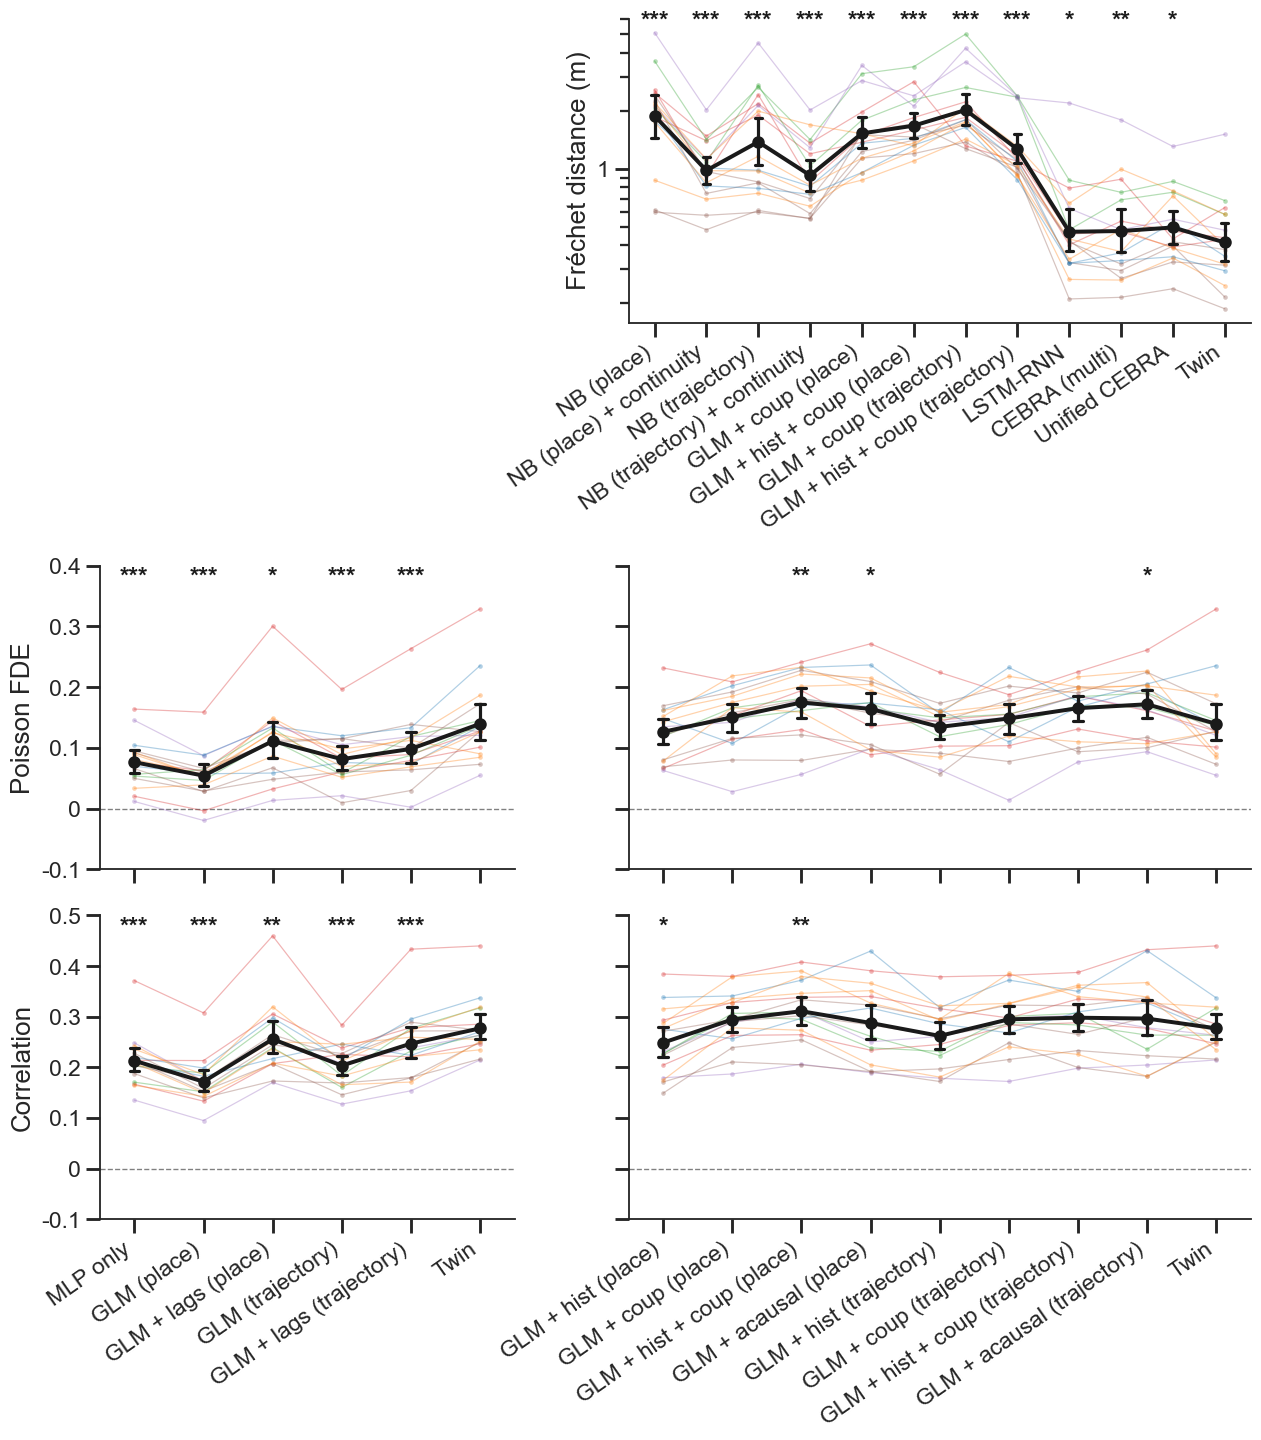


ED Fig 1d Fréchet — session-level Wilcoxon vs Twin (session medians):
                model    vs  n  median_diff         p stars         P
          naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
        nb_continuity joint 17        0.528 1.526e-05   *** P < 0.001
  naive_bayes_cluster joint 17       0.8419 1.526e-05   *** P < 0.001
nb_continuity_cluster joint 17       0.4571 1.526e-05   *** P < 0.001
         glm_map_coup joint 17        1.007 1.526e-05   *** P < 0.001
              glm_map joint 17        1.089 1.526e-05   *** P < 0.001
   glm_map_joint_coup joint 17         1.45 1.526e-05   *** P < 0.001
     glm_map_joint_hc joint 17       0.7357 1.526e-05   *** P < 0.001
             lstm_rnn joint 17      0.03518   0.01286     * P = 0.013
          cebra_multi joint 17      0.04157  0.006653    ** P = 0.007
                cebra joint 17      0.06751   0.04477     * P = 0.045

ED Fig 1e,g FDE — session-level Wilcoxon vs Twin (session medians):
                    

In [397]:
# === Extended Data Figure 1 (d-h) on a single canvas: 3 x 2 grid ===
# a-b are external schematics; they occupy the empty top-left space.
#   row 0:  [   (a-c space)   ] [ d: decoder session medians ]  (right-aligned)
#   row 1:  [ e behaviour: session ] [ g neural: session ]  (Poisson FDE)
#   row 2:  [ f behaviour: session ] [ h neural: session ]  (Correlation)
# The encoding models split into two groups, each anchored by the Twin on its right:
# LEFT = behaviour-alone models (MLP far-left, then behaviour-only GLMs place/traj
# +/- lags) + Twin; RIGHT = neural-data GLMs (history / coupling / acausal) + Twin. The
# Twin bar is REPEATED in both groups so each is a self-contained comparison vs it.
# Per-neuron / per-flight panels have been removed (session medians only); the pooled
# per-unit Wilcoxon vs the Twin is still reported below the figure.
LEFT_GROUP = ['MLP only'] + BEHAV_ONLY_GLMS          # MLP far-left, then behaviour-only GLMs
LEFT_ORDER = [m for m in LEFT_GROUP if m in ed1_present] + [OUR_MODEL]
RIGHT_ORDER = ([m for m in ed1_present if m not in LEFT_GROUP and m != OUR_MODEL] + [OUR_MODEL])
_nL, _nR = len(LEFT_ORDER), len(RIGHT_ORDER)

fig_ed1 = plt.figure(figsize=(13.5, 16.5))
# 2 columns: behaviour session | neural session; widths ~ #models so every bar keeps
# the same width across panels.
gs_ed1 = fig_ed1.add_gridspec(3, 2, hspace=0.8, wspace=0.22, width_ratios=[_nL, _nR])

# --- pooled unit-level (per-flight / per-neuron) paired Wilcoxon vs the Twin: reported
#     below the figure (the per-unit panels themselves were removed). ---
ptab_ed1d_pooled = ph.pooled_ptable(ed1_frechet, 'frechet_3d', ed1_dec_present, 'joint',
                                  ['session', 'flight_id'], model_col='decoder', higher_is_better=False)
ptab_ed1_fde_pooled = ph.pooled_ptable(ed1_encode_df, 'fde', ed1_present, OUR_MODEL,
                                  ['session', 'unit'], model_col='model', higher_is_better=True)
ptab_ed1_corr_pooled = ph.pooled_ptable(ed1_encode_df, 'corr', ed1_present, OUR_MODEL,
                                  ['session', 'unit'], model_col='model', higher_is_better=True)

# row 0 (d): decoder ladder, right-aligned into the right column (a-c space at left)
ax_d = fig_ed1.add_subplot(gs_ed1[0, 1])
ax_d.set_yscale('log')              # Fréchet distance is strictly positive -> log y
_, ptab_ed1d = ph.compare_models_fig(
    ed1_frechet, 'frechet_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight',
    higher_is_better=False, show_titles=False, axes=(ax_d, None))


def _encode_row(row, value_col, ylabel, clip, sess_ylim, show_xticklabels):
    """Behaviour group (col 0) then neural group (col 1); Twin repeated. The neural group
    drops its y-axis label (same scale as the behaviour group). Returns (combined
    session-level p-table, the two row axes)."""
    bS = fig_ed1.add_subplot(gs_ed1[row, 0])
    nS = fig_ed1.add_subplot(gs_ed1[row, 1])
    common = dict(unit_name='neuron', clip=clip, zero_line=True, sess_ylim=sess_ylim,
                  show_xticklabels=show_xticklabels, show_titles=False)
    _, ptL = ph.compare_models_fig(ed1_encode_df, value_col, LEFT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, axes=(bS, None), **common)
    _, ptR = ph.compare_models_fig(ed1_encode_df, value_col, RIGHT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, show_sess_ylabel=False,
                                   axes=(nS, None), **common)
    nS.tick_params(labelleft=False)   # neural group shares the behaviour group's y-axis
    return pd.concat([ptL, ptR], ignore_index=True), (bS, nS)


ptab_ed1_fde, _ = _encode_row(1, 'fde', 'Poisson FDE', (-1, 1), (-0.1, 0.4),
                           show_xticklabels=False)
ptab_ed1_corr, ax_corr = _encode_row(2, 'corr', 'Correlation', (-0.2, 1), (-0.1, 0.5),
                              show_xticklabels=True)

# row 1 dropped its xticklabels (shared with row 2), so lift row 2 up into the vacated
# space (measured from row 2's own identical xticklabels via the tight bbox).
fig_ed1.canvas.draw()
try:
    _rend = fig_ed1.canvas.get_renderer()
    _lift = min((_ax.get_position().y0
                 - _ax.get_tightbbox(_rend).transformed(fig_ed1.transFigure.inverted()).y0)
                for _ax in ax_corr)
except Exception:
    _lift = 0.06
_lift += 0.015   # shrink the row 1 (FDE) -> row 2 (Corr) gap ever so slightly
for _ax in ax_corr:
    _box = _ax.get_position()
    _ax.set_position([_box.x0, _box.y0 + _lift, _box.width, _box.height])

ph.save_fig(fig_ed1, 'edfig1_full'); plt.show()
for _n, _pt in [('1d Fréchet', ptab_ed1d), ('1e,g FDE', ptab_ed1_fde),
                ('1f,h corr', ptab_ed1_corr)]:
    print(f'\nED Fig {_n} — session-level Wilcoxon vs {OUR_MODEL} (session medians):')
    ph.p_table(_pt.to_dict('records'))
for _n, _pt in [('1d Fréchet (per-flight)', ptab_ed1d_pooled),
                ('1e,g FDE (per-neuron)', ptab_ed1_fde_pooled),
                ('1f,h corr (per-neuron)', ptab_ed1_corr_pooled)]:
    print(f'\nED Fig {_n} — pooled unit-level Wilcoxon vs {OUR_MODEL} (per-unit stats, no panel):')
    ph.p_table(_pt.to_dict('records'))


**Extended Data Figure 1 | Full model ladders.**
(A) Schematic layout of indoor flight room with freely-moving recording. (B) Schematic input data for the Twin model. Single-unit spike counts and 3-D position were chunked into individual flights, binned at 100 ms, padded to the length of the longest flight, and input to the model with shape (B, N, T) and (B, 3, T), where the batch dimension B = number of flights, N = number of neurons, T = number of time bins, and 3 = number of spatial dimensions. (C). Each batch was assigned one of three masking strategies: ``Encoding'' (in which neural data was fully masked and used as the prediction target), ``Decoding'' (in which behavioral data was fully masked and used as the prediction target), and ``Infill'' (in which the same random time steps from both neurons and behavior were masked and used as the prediction target). (D) Per-flight 3-D Fréchet distance (lower is better) for the decoder ladder. GLMs were inverted by gradient descent over position to maximize Poisson likelihood + a smoothness prior, producing correlation-aware decoders (see \ref{sec:methods}). Left to right, each versus the Twin (paired two-sided Wilcoxon signed-rank on session medians, n = 17 sessions): `NB (place)' ($P = 1.53 \times 10^{-5}$), `NB (place) + continuity' ($P = 1.53 \times 10^{-5}$), `NB (trajectory)' ($P = 1.53 \times 10^{-5}$), `NB (trajectory) + continuity' ($P = 1.53 \times 10^{-5}$), `GLM + coup (place)' ($P = 1.53 \times 10^{-5}$), `GLM + hist + coup (place)' ($P = 1.53 \times 10^{-5}$), `GLM + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + hist + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `LSTM-RNN' ($P = 0.0129$), `multi-session CEBRA' ($P = 0.00168$), `Unified CEBRA' ($P = 0.0448$), and our Twin. (E) Poisson FDE for models that use only behavior data for neural prediction. Each model versus the Twin (paired two-sided Wilcoxon signed-rank on session medians, n = 17 sessions): `MLP only' ($P = 7.63 \times 10^{-5}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.0110$), `GLM (trajectory)' ($P = 3.05 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 5.04 \times 10^{-4}$). (F) Same as (E), but for Pearson correlation: `MLP only' ($P = 1.53 \times 10^{-5}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.00168$), `GLM (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 3.81 \times 10^{-4}$). (G-H), same as (E-F), but for GLMs which additionally condition on spike history, cross-neuron coupling, and/or future spiking. (G) Poisson FDE: `GLM + hist (place)' ($P = 0.207$), `GLM + coup (place)' ($P = 0.263$), `GLM + hist + coup (place)' ($P = 0.00557$), `GLM + acausal (place)' ($P = 0.0395$), `GLM + hist (trajectory)' ($P = 1.00$), `GLM + coup (trajectory)' ($P = 0.159$), `GLM + hist + coup (trajectory)' ($P = 0.0714$), `GLM + acausal (trajectory)' ($P = 0.0202$). (H) Pearson correlation: `GLM + hist (place)' ($P = 0.0305$), `GLM + coup (place)' ($P = 0.0984$), `GLM + hist + coup (place)' ($P = 0.00557$), `GLM + acausal (place)' ($P = 0.712$), `GLM + hist (trajectory)' ($P = 0.159$), `GLM + coup (trajectory)' ($P = 0.120$), `GLM + hist + coup (trajectory)' ($P = 0.132$), `GLM + acausal (trajectory)' ($P = 0.174$). See also Figure \ref{fig:fig1} and Figures \ref{fig:S2}-\ref{fig:S3}.

## ED Fig 2

In [21]:
# === ED Fig 2a-c data: decoding cost (mode - real) from decode-position-comparison ===
# Per-flight surrogate-mode decode tables exported by decode-position-comparison.ipynb
# (§5 export cell) -> paired per-flight costs metric(mode) - metric(real). The decoder
# subset shown in ED Fig 2 matches the ED Fig 1d nomenclature (GLM-inversion place
# variants) and is anchored on the Twin joint decoder (NOT Bat_Transformer_Decoder).
ED2_COST_PATH = f'./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl'

# Surrogate modes shown as cost panels (one row each).
ED2_COST_MODES = [('trial_shuffled', 'Trial-shuffle'),
                  ('synthetic', 'Synthetic (place)'),
                  ('synthetic_traj', 'Synthetic (trajectory)')]
# Decoders compared in each cost panel, in ED Fig 1c order; last = Twin (the
# joint masked encoder/decoder used as a decoder), the anchor for the Wilcoxon test.
# Three decoders at matched complexity: GLM + hist + coup for place vs trajectory
# (place x traj-cluster) conditioning, plus Twin (the joint masked encoder/decoder
# used as a decoder) — the last is the Wilcoxon anchor. All three appear in every mode,
# so the cost panels share one x-axis. Note the temporal filters HURT a GLM-inversion
# decoder (they explain firing that would otherwise pin down position), so glm_map_joint_hc
# has a poorer real baseline and small, sometimes negative synthetic costs; its trial-shuffle
# cost stays strongly positive (it relies on the coupling that trial-shuffle destroys).
ED2_COST_MODELS = ['glm_map', 'glm_map_joint_hc', 'joint']
ED2_COST_REF = 'joint'
ED2_COST_LABELS = {'glm_map': 'GLM + hist + coup (place)',
                   'glm_map_joint_hc': 'GLM + hist + coup (trajectory)', 'joint': OUR_MODEL}


def _mode_cost(flightdf, value_col, mode):
    """Per-flight paired cost = value(mode) - value(real), matched on flight+model.
    Test flights are the real held-out flights (by reference) in every asymmetric
    mode, so the join is 1:1."""
    keys = ['bat', 'session', 'flight_id', 'model']
    real = flightdf[flightdf['data'] == 'real'][keys + [value_col]]
    surr = flightdf[flightdf['data'] == mode][keys + [value_col]]
    m = surr.merge(real, on=keys, suffixes=('_surr', '_real'))
    m['value'] = m[f'{value_col}_surr'] - m[f'{value_col}_real']
    m = m[m['model'].isin(ED2_COST_MODELS)].copy()
    present = [c for c in ED2_COST_MODELS if c in set(m['model'])]
    m['model'] = pd.Categorical(m['model'], present, ordered=True)
    return m


def _pkl_has_joint(path):
    """True iff the cached export carries the models ED Fig 2 needs (Twin +
    the GLM + hist + coup trajectory inversion)."""
    try:
        have = set(pd.read_pickle(path)['frechet_by_mode']['model'])
        return {'joint', 'glm_map_joint_hc'} <= have
    except Exception:
        return False


# Regenerate the per-flight surrogate-mode decode tables in-place if missing OR if the
# cached pkl predates the Twin column (run-once cache; heavy — trains one joint
# decoder per mode plus the GLM-inversion / transformer decoders). The generation logic
# is the single-sourced package pipeline decode-position-comparison.ipynb also uses.
if not os.path.exists(ED2_COST_PATH) or not _pkl_has_joint(ED2_COST_PATH):
    try:
        from digitalbat.decoding.cost_pipeline import generate_ed2_decode_costs
        from digitalbat.datasets.defaults import (
            DEFAULT_SESSION_NAMES as _ED2_DSN, make_data_config as _ed2_mdc)
        # DEFAULT_SESSION_NAMES already omits Dataset_3_14543_240419 (commented out at
        # source), so this is the full canonical 17-session list -- pass it verbatim.
        _ed2_decode_cfg = _ed2_mdc(session_names=list(_ED2_DSN))
        _why = 'missing' if not os.path.exists(ED2_COST_PATH) else 'lacks Twin'
        print(f'[ED2 c-h] {ED2_COST_PATH} {_why} — regenerating via '
              'cost_pipeline.generate_ed2_decode_costs (cached ckpts under ./out) …')
        generate_ed2_decode_costs(_ed2_decode_cfg, device=device, seed=seed,
                                  out_path=ED2_COST_PATH, joint_params=JOINT_PARAMS,
                                  joint_input_transform=INPUT_TRANSFORM)
    except Exception as _ed2_exc:
        print(f'[ED2 c-h] regeneration failed ({type(_ed2_exc).__name__}: {_ed2_exc}); '
              'cost panels will show placeholders.')


ed2_cost = None
if os.path.exists(ED2_COST_PATH):
    _exp = pd.read_pickle(ED2_COST_PATH)
    _fr = _exp['frechet_by_mode']
    ed2_cost = {}
    for mode, _lab in ED2_COST_MODES:
        ed2_cost[('frechet_3d', mode)] = _mode_cost(_fr, 'frechet_3d', mode)
    print('ED2 cost tables (rows):', {f'{k[0]}|{k[1]}': len(v) for k, v in ed2_cost.items()})
    if not _pkl_has_joint(ED2_COST_PATH):
        print('[ED2 a-c] WARNING: cached pkl still lacks Twin — last column will be empty.')
else:
    print(f'[ED2 a-c] could not produce {ED2_COST_PATH}; cost panels show placeholders.')


ED2 cost tables (rows): {'frechet_3d|trial_shuffled': 834, 'frechet_3d|synthetic': 834, 'frechet_3d|synthetic_traj': 834}


In [22]:
# === ED Fig 2d/e: encode ladder RETRAINED on synthetic place-cell spikes, eval on real ===
# Replace each session's TRAIN spikes with samples from its smoothed 3-D rate map
# (valid/test stay real by reference), retrain the full ED Fig 1 encode ladder with the
# SAME architecture/hyperparameters (train-if-missing, `_synth` checkpoints), then
# score per-neuron FDE/corr on the REAL held-out test set. Mirrors internals.ipynb /
# preprocess-data-v0j-share.ipynb, extended from the transformer to the whole ladder.
from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
from digitalbat.training.joint_trainer import train_joint, scheme_weights
import re as _re

SYNTH_MODE = 'empirical'   # matches decode-position-comparison SYNTH_SAMPLING ('empirical' resample)
SYNTH_TAG = f'_synth_{SYNTH_MODE}'

# The joint universe's meta stats are 13-D (kinematic); the position-only view is
# 3-D. Slice behaviour mean/std to xyz for the synthetic rate-map fit (matches how
# gather_session_arrays / joint_decode un-z-score position elsewhere).
_meta_pos3 = dict(meta_info_dict)
_meta_pos3['behavior_mean'] = {s: np.asarray(v).reshape(-1)[:3]
                               for s, v in meta_info_dict['behavior_mean'].items()}
_meta_pos3['behavior_std'] = {s: np.asarray(v).reshape(-1)[:3]
                              for s, v in meta_info_dict['behavior_std'].items()}
syn_loaders, syn_simulators = make_synthetic_train_dataloaders(
    dataloaders, _meta_pos3, dt=bin_width, mode=SYNTH_MODE, seed=seed)
assert syn_loaders['valid'] is dataloaders['valid'] and syn_loaders['test'] is dataloaders['test']


def _synth_ckpt(path):
    root, ext = os.path.splitext(path)
    return f'{root}{SYNTH_TAG}{ext}'


def _joint_synth_params():
    """Consensus joint hyperparameters (parsed from JOINT_CKPT + cached study)."""
    p = dict(num_layers=JOINT_PARAMS['num_layers'], latent_dim=JOINT_PARAMS['latent_dim'],
             ff_dim=JOINT_PARAMS['ff_dim'], dropout=JOINT_PARAMS['dropout'],
             lr=3e-3, weight_decay=1e-2, w_encode=1.0, w_decode=1.0, w_aux=1.0,
             lam=1.0, pos_weight=1.0)
    base = os.path.basename(JOINT_CKPT)
    for k, rgx in dict(lam=r'_lam([0-9.]+)', pos_weight=r'_pw([0-9.]+)', w_encode=r'_we([0-9.]+)',
                       w_decode=r'_wd([0-9.]+)', w_aux=r'_wa([0-9.]+)').items():
        mm = _re.search(rgx, base)
        if mm:
            p[k] = float(mm.group(1))
    study_path = './out/joint/joint_optuna_v2_kin0.pkl'
    if os.path.exists(study_path):
        try:
            p.update(pickle.load(open(study_path, 'rb')).best_params)
        except Exception as _e:
            print(f'  [joint-synth] could not read study ({_e}); using parsed/default params')
    return p


def _ensure_joint_synth(loaders):
    """Retrain the joint transformer on synthetic train spikes (same params)."""
    p = _joint_synth_params()
    ckpt = _synth_ckpt(JOINT_CKPT.replace('_infillft', ''))
    set_random_state(seed)
    jm = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, latent_dim=p['latent_dim'], num_heads=4,
        ff_dim=p['ff_dim'], num_layers=p['num_layers'], dropout=p['dropout'],
        input_transform=INPUT_TRANSFORM, session_to_room=session_to_room).to(device)
    if os.path.exists(ckpt):
        jm.load_state_dict(torch.load(ckpt, map_location=device))
    else:
        print(f'  [train joint-synth] {os.path.basename(ckpt)}')
        jm, _b, _ = train_joint(jm, loaders, device, meta_info_dict, seed=seed, n_epochs=1000,
                                lr=p['lr'], weight_decay=p['weight_decay'], lam=p['lam'],
                                pos_weight=p['pos_weight'], scheme_p=scheme_weights(p),
                                select='joint', fde_weight=0.5, err_ref=0.3, fde_ref=0.1)
        torch.save(jm.state_dict(), ckpt)
    return jm.eval()


# Retrain the ladder on synthetic train (rebind the notebook's global `dataloaders`
# so the ED Fig 1 ensure_*/train_glm helpers train on synthetic + validate on real),
# then evaluate on the REAL test set. syn_loaders['test'] is the real test by reference.
# ED Fig 2 mirrors the ED Fig 1 encode ladder (same models incl. GLM + lags
# (trajectory), same order); the delta(synthetic - real) is computed per model below.
_real_loaders = dataloaders
_syn_pieces = []
try:
    dataloaders = syn_loaders
    for label, kind, spec in ED1_MODELS:
        try:
            if kind == 'glm':
                name, cond = spec
                gm = ensure_glm(_synth_ckpt(glm_ckpt(name, cond)),
                                lambda: build_glm(name, cond), cond=cond,
                                search_alpha=('coup' in name))
                df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
            elif kind == 'former':
                ck = _synth_ckpt(make_model_name(
                    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                    out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                             'small': './out/bat_former_small'}[spec], suffix=DATA_TAG))
                fm = ensure_former(ck, lambda: build_former(spec), loaders=syn_loaders)
                df = eval_former_metrics(fm)
            else:  # joint / Twin
                jm = _ensure_joint_synth(syn_loaders)
                df = encode_eval_records(JointEncoderAdapter(jm, unit_num_dict).to(device).eval(),
                                         _real_loaders, device)
            _syn_pieces.append(df.assign(model=label))
            print(f'  ok (synthetic): {label}')
        except Exception as exc:
            print(f'  [skip synthetic {label}] {type(exc).__name__}: {exc}')
finally:
    dataloaders = _real_loaders

ed2_encode_df = pd.concat(_syn_pieces, ignore_index=True)
ed2_enc_present = [m for m in ED1_ORDER if m in set(ed2_encode_df['model'])]
ed2_encode_df['model'] = pd.Categorical(ed2_encode_df['model'], ed2_enc_present, ordered=True)
print('ED2 synthetic-encode models:', ed2_enc_present)

  ok (synthetic): GLM (place)
GLM: 11 lags x 108 spatial = 1188 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok (synthetic): GLM + lags (place)
  ok (synthetic): GLM (trajectory)
  ok (synthetic): GLM + lags (trajectory)
  ok (synthetic): GLM + hist (place)
  ok (synthetic): GLM + coup (place)
  ok (synthetic): GLM + hist + coup (place)
  ok (synthetic): GLM + acausal (place)
  ok (synthetic): GLM + hist (trajectory)
  ok (synthetic): GLM + coup (trajectory)
  ok (synthetic): GLM + hist + coup (trajectory)
  ok (synthetic): GLM + acausal (trajectory)
  ok (synthetic): MLP only
  ok (synthetic): Twin
ED2 synthetic-encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM (trajectory)', 'GLM + lags (trajectory)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


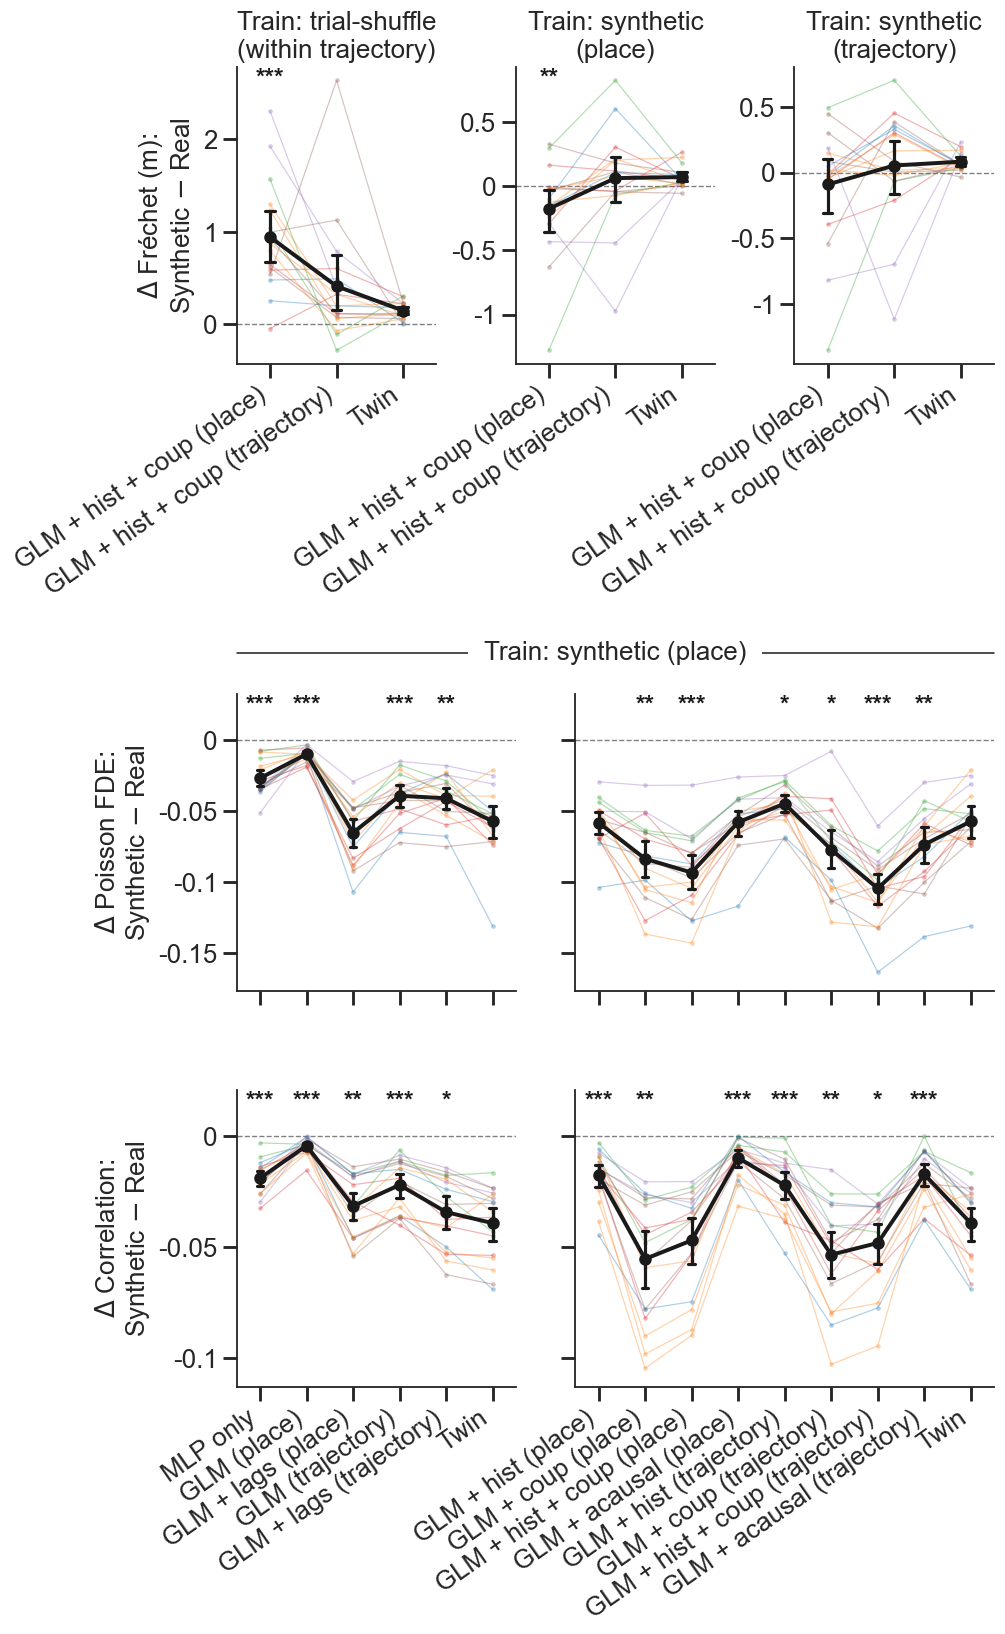


ED Fig 2a Trial-shuffle frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff         p stars         P
         glm_map joint 17       0.7377 4.578e-05   *** P < 0.001
glm_map_joint_hc joint 17      0.02225    0.1454       P = 0.145

ED Fig 2b Synthetic (place) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff        p stars         P
         glm_map joint 17      -0.1911 0.006653    ** P = 0.007
glm_map_joint_hc joint 17      0.01679   0.7119       P = 0.712

ED Fig 2c Synthetic (trajectory) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff      p stars         P
         glm_map joint 17     -0.06701 0.2247       P = 0.225
glm_map_joint_hc joint 17    -0.004435 0.6777       P = 0.678

ED Fig 2d ΔFDE — session-level Wilcoxon:
                         model   vs  n  median_diff         p stars         P
                      MLP only Twin 17     -0.03137 0.0003815   *** P < 0.001
               

In [23]:
# === Extended Data Figure 2 on a single canvas — decode-cost (top row) + encode-cost ===
# Everything is a "surrogate minus real-trained" delta, matched per unit/flight.
#   Rows A–C (top) DECODE cost: Δ Fréchet = metric(decoder trained on surrogate) −
#             metric(trained on real). Three panels side by side, one per surrogate train
#             mode (trial-shuffle | synthetic place | synthetic trajectory), each titled by
#             its train condition; session-median panel only (per-flight removed). Wilcoxon
#             anchored on Twin.
#   Rows D,E  ENCODE cost: Δ Poisson FDE / Δ Pearson r =
#             metric(ladder retrained on synthetic place spikes) − metric(real-trained
#             ladder), both scored on the real test set. Session-median panels only
#             (per-neuron removed), behaviour group | neural group, below the decode row.

# ---- Encode delta: synthetic-trained − real-trained, matched per (session, unit, model) ----
_e2 = ed2_encode_df.assign(model=ed2_encode_df['model'].astype(str))
_e1 = ed1_encode_df.assign(model=ed1_encode_df['model'].astype(str))
_enc_delta = _e2.merge(_e1[['session', 'unit', 'model', 'fde', 'corr']],
                       on=['session', 'unit', 'model'], suffixes=('_syn', '_real'))
_enc_delta['fde'] = _enc_delta['fde_syn'] - _enc_delta['fde_real']
_enc_delta['corr'] = _enc_delta['corr_syn'] - _enc_delta['corr_real']
_enc_present = [m for m in ed2_enc_present if m in set(_enc_delta['model'])]
_enc_delta['model'] = pd.Categorical(_enc_delta['model'], _enc_present, ordered=True)

# ---- Manual axis geometry (figure fraction). Panels short, gaps generous (esp. central). ----
fig_ed2 = plt.figure(figsize=(18, 15))
_L, _R, _TOP, _BOT = 0.16, 0.985, 0.88, 0.05
_UW = _R - _L
_g_enc = 0.100                                   # full-width rows: 2 axes, wide central gutter
_w_full = (_UW - _g_enc) / 2
_x_enc = [_L, _L + _w_full + _g_enc]

# Encode rows D/E: behaviour group | neural group (per-neuron removed); bars keep the
# ED Fig 1 encode-row width. Computed first so the decode row can match this block's total width.
_G_IN, _G_GRP = 0.045, 0.03          # within-group (kept for bar-width) and between-group gaps
_u_enc = (_UW - 2 * _G_IN - _G_GRP) / (2 * _nL + 2 * _nR)   # keep the per-bar width as before
_xw_enc, _xx = [], _L                 # session-only: behaviour group then neural group
for _wu, _gap in [(_nL, _G_GRP), (_nR, 0.0)]:
    _xw_enc.append((_xx, _wu * _u_enc)); _xx += _wu * _u_enc + _gap
_enc_block_w = _xx - _L               # _L to the right edge of the neural group

# Top decode row: three session-median panels spanning the SAME total width as the encode
# block (left-aligned), one per surrogate train mode.
_g_dec = 0.04
_w_dec = (_enc_block_w - 2 * _g_dec) / 3
_x_dec = [_L + i * (_w_dec + _g_dec) for i in range(3)]

_h = 0.18                                         # panel height (3 rows, extra row-1->2 gap)
_ROW_GAPS = [0.20, 0.06]                          # decode->encode section break, then encode pair
_NR = 3
_rowy, _y = [], _TOP
for r in range(_NR):
    _y -= _h
    _rowy.append(_y)
    if r < _NR - 1:
        _y -= _ROW_GAPS[r]

# Decode row (row 0): three single session-median panels across the full width.
_axA = [fig_ed2.add_axes([_x_dec[0], _rowy[0], _w_dec, _h])]   # trial-shuffle (decode)
_axB = [fig_ed2.add_axes([_x_dec[1], _rowy[0], _w_dec, _h])]   # synthetic (place) (decode)
_axC = [fig_ed2.add_axes([_x_dec[2], _rowy[0], _w_dec, _h])]   # synthetic (trajectory) (decode)
# Encode rows D/E use the same 2-group split as ED Fig 1 encode rows (behaviour models incl.
# MLP + Twin | neural GLMs + Twin; Twin repeated), reusing LEFT_ORDER / RIGHT_ORDER /
# _nL / _nR from the ED Fig 1 cell. Two subplots per row: behaviour session | neural
# session, widths ~ #models.
# (encode-row geometry _xw_enc / _enc_block_w computed above, before the decode row)


def _grid2(r):
    """2 axes for encode row r: behaviour session | neural session (per-neuron removed)."""
    return [fig_ed2.add_axes([x, _rowy[r], w, _h]) for x, w in _xw_enc]


_axD = _grid2(1)   # Δ FDE (encode)
_axE = _grid2(2)   # Δ r (encode)

ptabs_ed2 = {}

# ---- Rows A–C (top): decode cost, one session-median Fréchet panel per surrogate mode ----
# (row axes, mode label, mode key, panel title = the former left-gutter "Train:" label)
_dec_rows = [(_axA, 'Trial-shuffle', 'trial_shuffled', 'Train: trial-shuffle\n(within trajectory)'),
             (_axB, 'Synthetic (place)', 'synthetic', 'Train: synthetic\n(place)'),
             (_axC, 'Synthetic (trajectory)', 'synthetic_traj', 'Train: synthetic\n(trajectory)')]
_cost_specs = [('frechet_3d', 'flight', '$\\Delta$ Fréchet (m):\nSynthetic $-$ Real')]
_letters = 'abc'
for ri, (axrow, mlabel, mode, title) in enumerate(_dec_rows):
    for mi, (metric, unit, stem) in enumerate(_cost_specs):
        ax_single = axrow[0]
        tab = ed2_cost.get((metric, mode)) if ed2_cost else None
        if tab is not None and len(tab):
            _, pt = ph.compare_models_fig(
                tab, 'value', ED2_COST_MODELS, ref=ED2_COST_REF, labels=ED2_COST_LABELS,
                model_col='model', ylabel=stem, unit_name=unit,
                higher_is_better=False, zero_line=True, axes=(ax_single, None),
                show_titles=False, show_xticklabels=True, show_sess_ylabel=(ri == 0))
            ax_single.set_title(title, fontsize=plt.rcParams['axes.labelsize'])
            ptabs_ed2[f'2{_letters[ri]} {mlabel} {metric} cost'] = pt
        else:
            ax_single.set_axis_off()
            ax_single.set_title(title, fontsize=plt.rcParams['axes.labelsize'])
            ax_single.text(0.5, 0.5, f'{mlabel}\n{metric} cost:\nrun decode export cell',
                           ha='center', va='center', transform=ax_single.transAxes)

# ---- Rows D/E: encode delta (2-group split, same as ED Fig 1 encode rows; Twin repeated) ----
def _row_sess_ylim(value_col, pad_lo=0.08, pad_hi=0.20):
    """Shared session-median ylim across the behaviour + neural groups of one encode row
    (so its two panels share y-limits), with head-room for the significance stars."""
    _models = set(LEFT_ORDER) | set(RIGHT_ORDER)
    _s = (_enc_delta[_enc_delta['model'].isin(_models)]
          .groupby(['session', 'bat', 'model'], observed=True)[value_col].median())
    _lo, _hi = min(float(_s.min()), 0.0), max(float(_s.max()), 0.0)   # keep the zero line in view
    _r = (_hi - _lo) or 1.0
    return (_lo - pad_lo * _r, _hi + pad_hi * _r)


def _enc_delta_row(axq, value_col, ylabel, show_xticklabels):
    bS, nS = axq
    common = dict(unit_name='neuron', zero_line=True, higher_is_better=True,
                  sess_ylim=_row_sess_ylim(value_col), show_titles=False,
                  show_xticklabels=show_xticklabels)
    _, ptL = ph.compare_models_fig(_enc_delta, value_col, LEFT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, axes=(bS, None), **common)
    _, ptR = ph.compare_models_fig(_enc_delta, value_col, RIGHT_ORDER, ref=OUR_MODEL,
                                   ylabel=ylabel, show_sess_ylabel=False, axes=(nS, None), **common)
    nS.tick_params(labelleft=False)   # neural group shares the behaviour group's y-axis
    return pd.concat([ptL, ptR], ignore_index=True)


ptabs_ed2['2d ΔFDE'] = _enc_delta_row(
    _axD, 'fde', '$\\Delta$ Poisson FDE:\nSynthetic $-$ Real',
    show_xticklabels=False)
ptabs_ed2['2e Δr'] = _enc_delta_row(
    _axE, 'corr', '$\\Delta$ Correlation:\nSynthetic $-$ Real',
    show_xticklabels=True)

# ---- "Train: synthetic (place)" header over the encode block (row 2): a title inset
#      into a horizontal rule spanning the block width ----
_hy = _rowy[1] + _h + 0.025                        # just above the encode (ΔFDE) row
_hx0, _hx1 = _L, _L + _enc_block_w
fig_ed2.add_artist(plt.Line2D([_hx0, _hx1], [_hy, _hy], color='k', lw=1.0,
                                    transform=fig_ed2.transFigure, zorder=1))
fig_ed2.text((_hx0 + _hx1) / 2, _hy, '  Train: synthetic (place)  ', ha='center', va='center',
             fontsize=plt.rcParams['axes.labelsize'], zorder=2,
             bbox=dict(facecolor='white', edgecolor='none', pad=1))

_base_fs = plt.rcParams['axes.labelsize']   # match tick labels to the axis-label / title size
for _ax in fig_ed2.axes:
    _ax.tick_params(labelsize=_base_fs)
ph.save_fig(fig_ed2, 'edfig2_full')
plt.show()
for _n, _pt in ptabs_ed2.items():
    if _pt is None or not len(_pt):
        continue
    print(f'\nED Fig {_n} — session-level Wilcoxon:')
    ph.p_table(_pt.to_dict('records'))

# pooled per-unit (per-flight decode / per-neuron encode) Wilcoxon (per-unit stats, no panel)
for _mode, _mlab in [('trial_shuffled', 'Trial-shuffle'), ('synthetic', 'Synthetic (place)'),
                     ('synthetic_traj', 'Synthetic (trajectory)')]:
    _t = ed2_cost.get(('frechet_3d', _mode)) if ed2_cost else None
    if _t is not None and len(_t):
        print(f'\nED Fig 2 decode {_mlab} (per-flight) — pooled Wilcoxon vs {ED2_COST_REF}:')
        ph.p_table(ph.pooled_ptable(_t, 'value', ED2_COST_MODELS, ED2_COST_REF,
                   ['session', 'flight_id'], model_col='model', higher_is_better=False).to_dict('records'))
for _met, _lab in [('fde', '2d ΔFDE (per-neuron)'), ('corr', '2e Δr (per-neuron)')]:
    print(f'\nED Fig {_lab} — pooled Wilcoxon vs {OUR_MODEL}:')
    ph.p_table(ph.pooled_ptable(_enc_delta, _met, _enc_present, OUR_MODEL,
               ['session', 'unit'], model_col='model', higher_is_better=True).to_dict('records'))


---
**Extended Data Figure 2 | Surrogate-trained controls isolate the structure exploited by the Twin.** All panels were trained on surrogate data as indicated and then evaluated on real, held-out test data. (A–C) Per-flight difference in 3-D Fréchet distance (m) on surrogate versus real data. Three correlation-aware decoders of similar complexity and encoding performance (see Figure~\ref{fig:S1}) are compared: `GLM + hist + coup (place)', `GLM + hist + coup (trajectory)', and Twin, with the Wilcoxon test anchored on Twin. (A)  Flights of the same trajectory cluster were randomly shuffled, breaking the ``noise correlations'' on which the `GLM + hist + coup (place)' ($P = 4.58 \times 10^{-5}$) but not `(trajectory)' ($P = 0.145$) model depend relative to the Twin. (B) Synthetic spikes were generated based on each recorded neuron's binned and smoothed empirical rate map on training data, thereby eliminating not only noise correlations but also trajectory specificity. Now the `place GLM', which matches the generative structure of the synthetic data and performs comparatively better than the Twin ($P = 0.00665$), while the `trajectory GLM' does not ($P = 0.712$). (C) Same as (B), but synthetic spikes were generated in a trajectory-specific manner: `place GLM' ($P = 0.225$) and `trajectory GLM' ($P = 0.678$) vs the Twin. (D) Per-neuron difference in Poisson fraction deviance explained between synthetic place-cell spikes, generated as in (B), and real data.  The Twin is compared to the full model ladders from Figure \ref{fig:S1}E,G: `MLP only' ($P = 3.81 \times 10^{-4}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.0569$), `GLM (trajectory)' ($P = 8.39 \times 10^{-4}$), `GLM + lags (trajectory)' ($P = 0.00464$), `GLM + hist (place)' ($P = 0.890$), `GLM + coup (place)' ($P = 0.00316$), `GLM + hist + coup (place)' ($P = 3.05 \times 10^{-5}$), `GLM + acausal (place)' ($P = 1.00$), `GLM + hist (trajectory)' ($P = 0.0232$), `GLM + coup (trajectory)' ($P = 0.0202$), `GLM + hist + coup (trajectory)' ($P = 1.53 \times 10^{-5}$), `GLM + acausal (trajectory)' ($P = 0.00934$). The synthetic place cell spikes are least detrimental for models like `GLM (place)' which are best matched to the data generation mechanism, and most detrimental for those that explicitly rely on cross-neuron coupling. (E) Same as (D) but for the difference in Pearson correlation: `MLP only' ($P = 1.07 \times 10^{-4}$), `GLM (place)' ($P = 1.53 \times 10^{-5}$), `GLM + lags (place)' ($P = 0.00790$), `GLM (trajectory)' ($P = 7.63 \times 10^{-5}$), `GLM + lags (trajectory)' ($P = 0.0110$), `GLM + hist (place)' ($P = 1.07 \times 10^{-4}$), `GLM + coup (place)' ($P = 0.00557$), `GLM + hist + coup (place)' ($P = 0.120$), `GLM + acausal (place)' ($P = 3.05 \times 10^{-5}$), `GLM + hist (trajectory)' ($P = 1.07 \times 10^{-4}$), `GLM + coup (trajectory)' ($P = 0.00316$), `GLM + hist + coup (trajectory)' ($P = 0.0232$), `GLM + acausal (trajectory)' ($P = 4.58 \times 10^{-5}$). See also Figure \ref{fig:S1}.

## ED Fig 3

In [863]:
# === ED Fig 3: generate results if missing (train-if-missing, heavy) ===
# Each column's per-neuron / per-flight tables come from a standalone driver .py
# (train-if-missing: reruns skip existing checkpoints). We invoke a driver only when its
# target pkl is absent, mirroring the run-once caches in ED Figs 1-2. ED Figs 1-2 already
# self-generate (ED1 via `_cache_records`; ED2 via `cost_pipeline.generate_ed2_decode_costs`
# and the `_synth` retrain checkpoints), so no extra wiring is needed there.
import sys as _sys, subprocess as _subp
_REPO = os.path.abspath('..')                      # notebooks/ -> repo root

def _ensure_results(paths, argv, tag):
    """Run `argv` (from the repo root) iff any of `paths` is missing."""
    if all(os.path.exists(p) for p in paths):
        return
    print(f'[ED3:{tag}] results missing — generating via `{" ".join(argv)}` (heavy) …', flush=True)
    _subp.run(argv, cwd=_REPO, check=True)

_PY = _sys.executable
_ensure_results(['./out/transfer_joint/context/ctx_encode_cross1000_pinlam.pkl',
                 './out/transfer_joint/context/ctx_decode_fr_cross1000_pinlam.pkl'],
                [_PY, 'training/train_joint_context_cross1000.py'], 'context')
_ensure_results(['./out/transfer/scaling_joint_session/results_scaling_joint_session.pkl'],
                [_PY, 'training/train_joint_scaling.py'], 'scaling')
_ensure_results(['./out/transfer/scaling_joint_session/results_scaling_joint_session_decode_fr.pkl'],
                [_PY, 'training/scaling_decode_fr.py'], 'scaling-frechet')
_ensure_results(['./out/transfer_joint/env/results_env_encode.pkl',
                 './out/transfer_joint/env/results_env_decode.pkl'],
                [_PY, 'training/train_joint_transfer.py', '--mode', 'env'], 'env')

In [864]:
# === ED Fig 3a/b: encoding fit vs context window — JOINT model ===
# One JOINT model per window size (window_size=W tiling), trained by
# `training/train_joint_context_cross1000.py` under the production `cross_1000` recipe:
# encode/decode/cross schemes, L4/d64/ff64, a 50-trial Optuna search per window (300-epoch
# trials, `lam`/`pos_weight` pinned at the production values) and a 1000-epoch refit.
# The 'full' context point (x = 13) is a model trained the SAME way on untiled flights —
# NOT the production checkpoint, which was tuned under a different search budget and so
# mixed context length with hyperparameter tuning (it is also a decode-favorable draw:
# 0.395 m vs 0.461 m median Fréchet, p = 0.057 session-paired). Column (b) below keeps the
# production checkpoint as its 17-session reference.
CTX_WINDOWS = [1, 3, 5, 7, 9, 11]
_ctx_enc_p = './out/transfer_joint/context/ctx_encode_cross1000_pinlam.pkl'
if not os.path.exists(_ctx_enc_p):
    ctx_df = None
    print('ED Fig 3: no joint context-encode results — run '
          '`python training/train_joint_context_cross1000.py` first.')
else:
    ctx_df = pd.read_pickle(_ctx_enc_p)          # windowed models + matched full at context_x = 13
    print(f'ED Fig 3a/b: joint context-encode loaded ({ctx_df["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-d assembled on one canvas below)

ED Fig 3a/b: joint context-encode loaded (7 context sizes)


In [865]:
# === ED Fig 3c/d: decoding vs context window — JOINT model ===
# Same joint windowed models as ED Fig 3a/b, scored on the decode task (behavior masked,
# spikes seen): per-flight 3-D Fréchet distance, from
# `training/train_joint_context_cross1000.py`. A window's tiles are stitched back into whole
# flights before the distance is computed, so all seven context sizes score the SAME 278 test
# flights. (The previous driver ordered a flight's tiles by their within-window index, which
# interleaved them, and scored W-length fragments against whole flights at 'full' — a path
# length gradient across the x-axis on top of the interleaving.)
_ctx_fr_p = './out/transfer_joint/context/ctx_decode_fr_cross1000_pinlam.pkl'
if not os.path.exists(_ctx_fr_p):
    fr_all = None
    print('ED Fig 3: no joint context-decode results — run '
          '`python training/train_joint_context_cross1000.py` first.')
else:
    fr_all = pd.read_pickle(_ctx_fr_p)           # windowed models + matched full at context_x = 13
    print(f'ED Fig 3c: joint context-decode loaded ({fr_all["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-c assembled on one canvas below)

ED Fig 3c: joint context-decode loaded (7 context sizes)


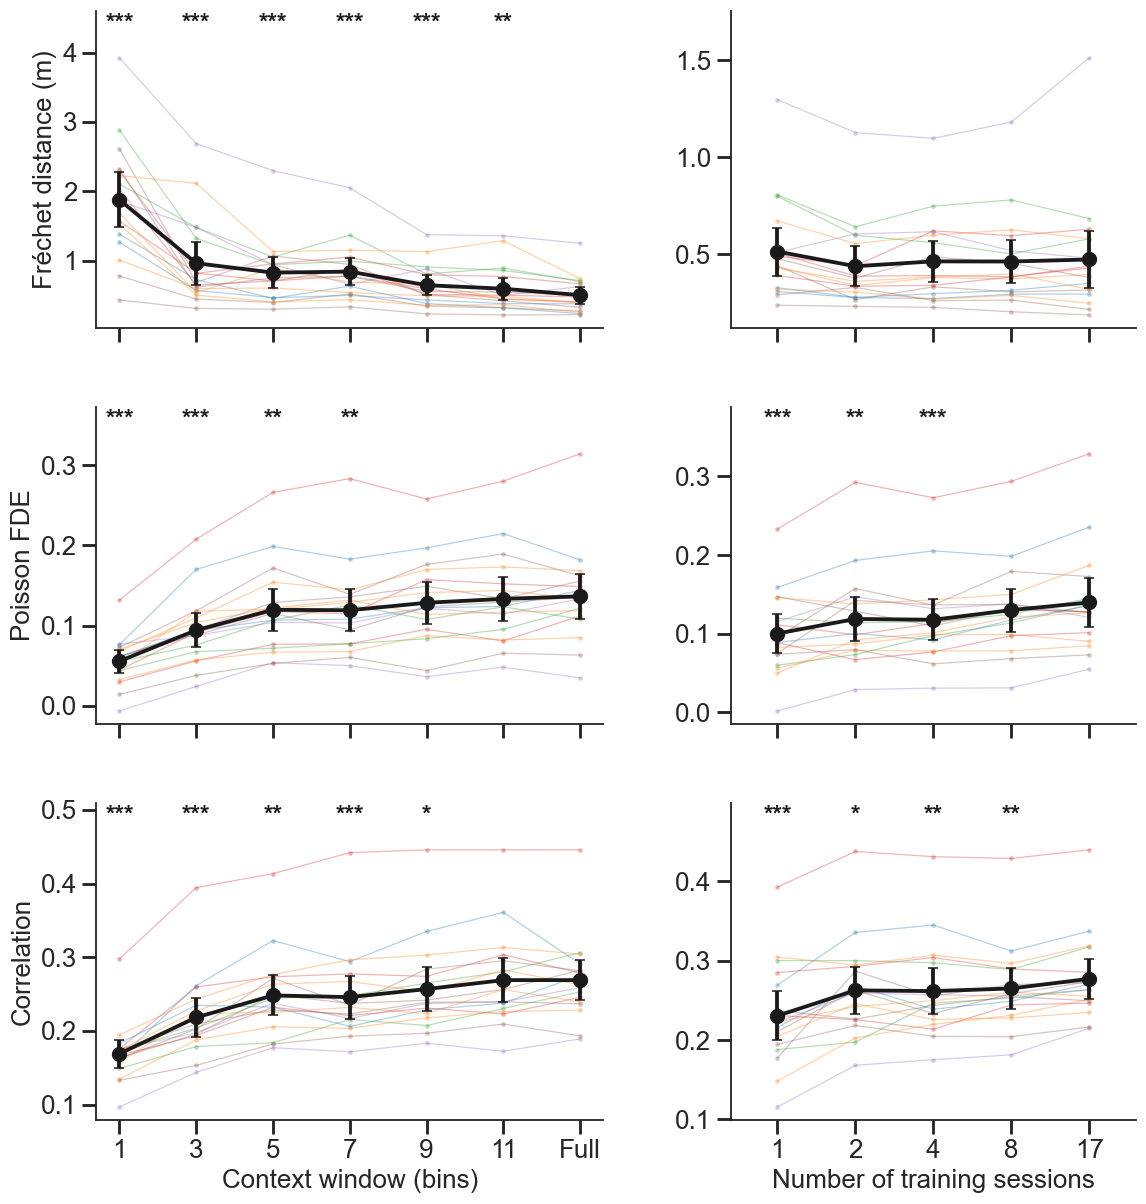

ED Fig 3 — foundation benefit vs (a) context window, (b) # training sessions, across 3-D Fréchet / Poisson FDE / correlation. Cols a-b stars: session-level Wilcoxon vs full.
 sweep  n         p               metric                              column stars         P
     1 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     3 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     5 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     7 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
     9 17 1.526e-05 Fréchet distance (m)              context window vs full   *** P < 0.001
    11 17  0.002579 Fréchet distance (m)              context window vs full    ** P = 0.003
     1 17   0.07141 Fréchet distance (m) Number of training sessions vs full       P = 0.071
     2 17    0.3289 Fréchet distance (m) Number of training sessions vs full      

In [866]:
# === Extended Data Figure 3 — foundation benefit along two axes x three metrics ===
# Rows: 3-D Fréchet (decode), Poisson FDE (encode), Pearson r (encode).
# Cols: (a) accuracy vs training *context window* [joint context sweep];
#       (b) accuracy vs # *training sessions* [session-universe scaling Twins].
#       Faint per-session lines (bat-coloured) + black mean±95% CI; stars =
#       session-level Wilcoxon vs the full model.
_scal_enc_p = './out/transfer/scaling_joint_session/results_scaling_joint_session.pkl'
_scal_fr_p  = './out/transfer/scaling_joint_session/results_scaling_joint_session_decode_fr.pkl'
_have_new = all(os.path.exists(p) for p in (_scal_enc_p, _scal_fr_p))

if ctx_df is None or fr_all is None:
    print('ED Fig 3: context results missing — run `python training/train_joint_context.py` first.')
elif not _have_new:
    print('ED Fig 3: session-scaling results missing — run `training/train_joint_scaling.py` + '
          '`training/scaling_decode_fr.py` first.')
else:
    # -- (b) session-universe scaling: encode fde/corr + decode Fréchet --
    _scal_enc = pd.read_pickle(_scal_enc_p).rename(columns={'target_session': 'session',
                                                            'neuron_idx': 'unit'})
    _scal_enc['bat'] = _scal_enc['session'].map(parse_bat)
    _scal_fr = pd.read_pickle(_scal_fr_p)
    _scal_fr['bat'] = _scal_fr['session'].map(parse_bat)

    # sweep-column tick geometry (context uses its real x; scaling uses even categorical slots)
    _CTX_XMAP = {v: v for v in (CTX_WINDOWS + [13])}
    _CTX_LAB = [str(w) for w in CTX_WINDOWS] + ['full']
    _SCAL_N = [1, 2, 4, 8, 17]
    _SCAL_XMAP = {n: i for i, n in enumerate(_SCAL_N)}
    _SCAL_LAB = ['1', '2', '4', '8', '17']

    def _sweep_pvals(df, xcol, col, sweep_vals, full_val):
        """Session-level Wilcoxon signed-rank of each sweep value vs the full model."""
        pvals, recs = {}, []
        for v in sweep_vals:
            res = ph.paired_session_test(df, col, xcol, v, full_val)
            if np.isfinite(res['p']):
                pvals[v] = res['p']
            recs.append(dict(sweep=v, n=res['n'], p=res['p']))
        return pvals, recs

    def _sweep_panel(ax, df, xcol, col, xmap, ticklabels, ylab, pvals, xlabel,
                     ylim=None, show_xticklabels=True, show_ylabel=True):
        """Session medians vs a sweep var: faint per-session lines (bat-coloured) +
        black mean±95% CI; 3-tier stars vs full near the top. Matches the context style."""
        per = df.groupby([xcol, 'session'])[col].median().reset_index()
        per['xpos'] = per[xcol].map(xmap)
        for sn, g in per.groupby('session'):
            g = g.sort_values('xpos')
            ax.plot(g['xpos'], g[col], '-o', color=BAT_PALETTE.get(parse_bat(sn), '0.6'),
                    lw=0.8, alpha=0.35, ms=3, mew=0, zorder=2)   # small points, match Fig 1/ED 1/2
        agg = per.groupby('xpos')[col].agg(['mean', 'std', 'count'])
        ci = 1.96 * agg['std'] / np.sqrt(agg['count'])
        ax.errorbar(agg.index, agg['mean'], yerr=ci, fmt='o-', color='k', lw=2.5,
                    capsize=3, zorder=5)
        xs = list(xmap.values())
        ax.set(xticks=xs, xlim=(min(xs) - 0.6, max(xs) + 0.6))
        ax.set_xticklabels(ticklabels if show_xticklabels else [])
        ax.set_xlabel(xlabel if show_xticklabels else '')
        if ylim:
            ax.set_ylim(*ylim)
        else:
            lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.12 * (hi - lo))   # headroom for stars
        ax.set_ylabel(ylab if show_ylabel else '')
        lo, hi = ax.get_ylim(); y = lo + 0.96 * (hi - lo)
        for v, p in pvals.items():
            s = ph.stars_for_p(p)
            if s:
                ax.text(xmap[v], y, s, ha='center', va='center', fontsize=16,
                        fontweight='bold', color='k')
        sns.despine(ax=ax)

    # (value, ylabel, ylim, ctx_df, scaling_df)
    _ED3_ROWS = [
        ('frechet_3d', 'Fréchet distance (m)', None, fr_all, _scal_fr),
        ('fde', 'Poisson FDE', None, ctx_df, _scal_enc),
        ('corr', 'Correlation', None, ctx_df, _scal_enc),
    ]

    fig_ed5 = plt.figure(figsize=(10.5, 12))
    gs = fig_ed5.add_gridspec(3, 2, top=0.93, bottom=0.09, left=0.09, right=0.99,
                              hspace=0.25, wspace=0.28, width_ratios=[2.5, 2])
    _AX = [[fig_ed5.add_subplot(gs[r, c]) for c in range(2)] for r in range(3)]

    ed3_p = []
    for ri, (col, ylab, ylim, cdf, sdf) in enumerate(_ED3_ROWS):
        _bottom = (ri == len(_ED3_ROWS) - 1)
        # (a) context window
        cpv, crecs = _sweep_pvals(cdf, 'context_x', col, CTX_WINDOWS, 13)
        _sweep_panel(_AX[ri][0], cdf, 'context_x', col, _CTX_XMAP, _CTX_LAB, ylab, cpv,
                     'context window (bins)', ylim=ylim, show_xticklabels=_bottom, show_ylabel=True)
        # (b) session scaling
        spv, srecs = _sweep_pvals(sdf, 'n_sessions', col, [1, 2, 4, 8], 17)
        _sweep_panel(_AX[ri][1], sdf, 'n_sessions', col, _SCAL_XMAP, _SCAL_LAB, ylab, spv,
                     'Number of training sessions', ylim=ylim, show_xticklabels=_bottom, show_ylabel=False)
        for r in crecs:
            r.update(metric=ylab, column='context window vs full'); ed3_p.append(r)
        for r in srecs:
            r.update(metric=ylab, column='Number of training sessions vs full'); ed3_p.append(r)

    _base_fs = plt.rcParams['axes.labelsize']
    for _ax in fig_ed5.axes:
        _ax.tick_params(labelsize=_base_fs)
    ph.save_fig(fig_ed5, 'edfig3_full'); plt.show()
    print('ED Fig 3 — foundation benefit vs (a) context window, (b) # training sessions, '
          'across 3-D Fréchet / Poisson FDE / correlation. '
          'Cols a-b stars: session-level Wilcoxon vs full.')
    ph.p_table(ed3_p)

---
## Extended Data Figure 3 — Scaling context window and training data improves digital twin performance

**Extended Data Figure 3 | Scaling context window and training data improves digital twin performance.** (A) The Twin was retrained once per window size, holding the overall amount of data equivalent, and evaluated on 3-D Fréchet distance between decoded and true flight paths (\textit{top}), Poisson fraction deviance explained (\textit{middle}), and Pearson correlation between predicted and observed spike counts (\textit{bottom}). Every window size, `Full' included, was hyperparameter-tuned and trained under one identical protocol, and decoded windows were re-assembled into whole flights so that all window sizes were scored on the same 278 test flights. Two-sided Wilcoxon signed-rank of each window vs the full-context model gives $P = 1.53 \times 10^{-5}$ except at the longer windows: Fréchet distance $P = 2.58 \times 10^{-3}$ (11 bins); Poisson FDE $P = 6.65 \times 10^{-3}$ (5 bins), $P = 3.16 \times 10^{-3}$ (7 bins), $P = 0.174$ (9 bins), $P = 0.611$ (11 bins); correlation $P = 1.34 \times 10^{-3}$ (5 bins), $P = 3.82 \times 10^{-4}$ (7 bins), $P = 0.017$ (9 bins), $P = 0.611$ (11 bins). Encoding is indistinguishable from full context by 9--11 bins, whereas the decoded path stays significantly worse at every window. (B) Same as (A), but as a function of the number of training sessions, where the 17-session model is the twin used throughout. Encoding improves with more sessions: Poisson FDE $P = 2.90 \times 10^{-4}$ (1), $P = 4.64 \times 10^{-3}$ (2), $P = 5.04 \times 10^{-4}$ (4), $P = 0.064$ (8); correlation $P = 1.53 \times 10^{-5}$ (1), $P = 0.015$ (2), $P = 2.09 \times 10^{-3}$ (4), $P = 1.07 \times 10^{-3}$ (8) — whereas decoding Fréchet distance shows only a trend at the smallest set ($P = 0.071$ at 1; $P = 0.329$, $0.678$, $0.782$ at 2, 4, 8; n.s.). All models are evaluated on the same per-session test split as the Full model. See also Figure \ref{fig:fig1}.

In [736]:
# --- Shared latent extraction: per-timepoint encode-space latents (neural tokens
# x[:, :T]) from BOTH the encode and decode passes, position, route/cluster/spikes.
from notebook_helpers import DIST_THRESH, get_target_locs


@torch.no_grad()
def extract_latents(split='test'):
    """Concatenate encode-pass latents + metadata across all sessions.

    Returns a dict with arrays aligned per valid timepoint: `latent` (N, d),
    `pred` (N, K_session — ragged, so returned per-session too), `xyz` (N, 3),
    `session`, `bat`, `flight_id`, `rel_t`, `cluster`, per-point `route`/`origin`/`dest`,
    and `spike_by_flight` (ragged {(session, flight_id): spikes}).
    """
    lat, lat_dec, xyz, sess, batv, fid, relt, clu = [], [], [], [], [], [], [], []
    spike_by_flight = {}
    per_session_latent = {}
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        sl = []
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_n = xf[:, :T].cpu().numpy()  # encode space: neural tokens x[:, :T]
            # decode pass: real spikes visible, behaviour masked -> decode latent
            _, _, xf_d = joint_model(sn, batch.spike.to(device), X, m, torch.zeros_like(m), m)
            h_d = xf_d[:, :T].cpu().numpy()  # encode space too: neural tokens x[:, :T] (decode pass)
            Xn = batch.behavior.numpy()
            mn = batch.mask.numpy() == 1.0
            fpi = batch.flight_path_index.numpy(); fti = batch.flight_type_index.numpy()
            spn = batch.spike.numpy()
            for b in range(B):
                v = mn[b]
                nv = int(v.sum())
                if nv == 0:
                    continue
                lat.append(h_n[b, v]); sl.append(h_n[b, v])
                lat_dec.append(h_d[b, v])
                pos = Xn[b, :, :3] * bs + bm
                xyz.append(pos[v])
                sess.append(np.full(nv, sn)); batv.append(np.full(nv, parse_bat(sn)))
                fid.append(np.full(nv, int(fpi[b]))); clu.append(np.full(nv, int(fti[b])))
                spike_by_flight[(sn, int(fpi[b]))] = spn[b, v]
                relt.append(np.arange(nv) / max(nv - 1, 1))
        per_session_latent[sn] = np.concatenate(sl) if sl else np.empty((0, joint_model.latent_dim))
    out = dict(latent=np.concatenate(lat), latent_decode=np.concatenate(lat_dec), xyz=np.vstack(xyz),
               session=np.concatenate(sess), bat=np.concatenate(batv),
               flight_id=np.concatenate(fid), rel_t=np.concatenate(relt),
               cluster=np.concatenate(clu), spike_by_flight=spike_by_flight,
               per_session_latent=per_session_latent)

    # Per-(session, flight) origin/destination endpoint classes -> route id.
    origin = np.zeros(len(out['session']), int)
    dest = np.zeros_like(origin)
    key = np.char.add(np.char.add(out['session'], '|'), out['flight_id'].astype(str))
    for k in np.unique(key):
        m = key == k
        sn = out['session'][m][0]
        rew, perch = get_target_locs(sn)
        order = np.argsort(out['rel_t'][m])
        pos = out['xyz'][m][order]
        o = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
        origin[m] = o; dest[m] = d
    out['origin'] = origin
    out['dest'] = dest
    out['route'] = np.array([ph.route_id(o, d) for o, d in zip(origin, dest)])
    return out


emb = extract_latents('test')
print('latent points:', len(emb['session']), '| latent dim:', emb['latent'].shape[1])

latent points: 8072 | latent dim: 64


In [ ]:
# === Figure 2 RSA data (2c): representational (dis)similarity across the four spaces (indoor only) ===
# Built straight from `emb`, so the Twin encode/decode latents here are the SAME
# per-flight embeddings visualised in Fig 2b (identical data). For every TEST flight we
# form four per-flight reps mirroring the four columns: (1) physical XYZ, (2) unified
# CEBRA (Optuna-best HP), (3) Twin decode latent, (4) Twin encode latent -- both raw
# joint-model embeddings. Every space enters the RSA at its FULL native dimensionality:
# physical XYZ raw 3-D, unified CEBRA and both Twin latents raw 64-D, with NO PCA
# reduction (the PCA-3 of Fig 2a/b is for display only). Physical XYZ is additionally
# per-session z-scored so room offset/scale don't dominate its distances. Each flight is
# kept as its FULL variable-length trajectory (no time-averaging); flights are compared by
# the symmetric Hausdorff distance between their point clouds, z-scored within each space
# so the four spaces share one scale. The matrices hold DISTANCES (not negated): small =
# nearby trajectories, and the zero-distance diagonal is the minimum. One shared ordering.
from scipy.spatial.distance import directed_hausdorff

# Per-(session, flight_id) reps grouped straight from `emb` -> identical to Fig 2b.
rsa_recs = {}
_rkey = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))
for _k in np.unique(_rkey):
    v = np.where(_rkey == _k)[0]
    v = v[np.argsort(emb['rel_t'][v])]
    sn = str(emb['session'][v[0]]); fid = int(emb['flight_id'][v[0]])
    if not ph.is_indoor(sn):        # Fig 2 is indoor-only (Datasets 1 & 3)
        continue
    rsa_recs[(sn, fid)] = dict(
        session=sn, bat=parse_bat(sn), flight_id=fid,
        cluster=int(emb['cluster'][v[0]]), indoor=ph.is_indoor(sn),
        route=int(emb['route'][v[0]]),
        xyz=emb['xyz'][v], h_n=emb['latent'][v], h_d=emb['latent_decode'][v],
        spike=emb['spike_by_flight'][(sn, fid)])

# CEBRA condition: Optuna-best unified per-flight embeddings (guarded on availability).
cebra_by_key = None
if cebra_frechet is not None:
    cebra_by_key = {(s, f['flight_id']): np.asarray(e) for s in session_names for e, f in uni_te[s]}

# Flights present in every available representation.
rsa_keys = [k for k in rsa_recs if cebra_by_key is None or k in cebra_by_key]

# Shared ordering (indoor only): route ('other' last) -> bat -> session -> cluster.
_bat_idx = {b: i for i, b in enumerate(ph.bat_order())}
_sess_idx = {s: i for i, s in enumerate(sorted(session_names))}
rsa_order = sorted(rsa_keys, key=lambda k: (
    rsa_recs[k]['route'] if rsa_recs[k]['route'] != 0 else 99,  # 'other' sorts last
    _bat_idx.get(rsa_recs[k]['bat'], 99), _sess_idx[rsa_recs[k]['session']],
    rsa_recs[k]['cluster']))


def _rsa_matrix(getter, zsession=False):
    """[optional per-session point z-score] -> keep each flight as its full
    variable-length trajectory in its NATIVE space (no PCA: raw 3-D physical, raw 64-D
    latents) -> pairwise symmetric Hausdorff distance -> z-score the off-diagonal
    distances within the space so the spaces are directly comparable. Returned as a
    DISTANCE, NOT negated: smaller = more similar, and the zero self-distance on the
    diagonal is the matrix minimum."""
    arrs = [np.asarray(getter(k), float) for k in rsa_order]
    if zsession:
        # Physical XYZ only: z-score points within each session (pooled over its flights)
        # so room offset/scale don't dominate the distance. CEBRA/Twin latents are model
        # outputs already on a common scale, so are left as-is.
        _spt = np.concatenate([np.full(len(a), rsa_recs[k]['session'])
                               for a, k in zip(arrs, rsa_order)])
        _stk = np.ascontiguousarray(np.vstack(arrs), float)
        for _c in range(_stk.shape[1]):
            _stk[:, _c] = ph.zscore_by_session(_stk[:, _c], _spt)
        arrs = np.split(_stk, np.cumsum([len(a) for a in arrs])[:-1])
    arrs = [np.ascontiguousarray(a, float) for a in arrs]   # directed_hausdorff wants C-order f8
    n = len(arrs)
    D = np.zeros((n, n))
    for _i in range(n):
        _a = arrs[_i]
        for _j in range(_i + 1, n):
            _b = arrs[_j]
            D[_i, _j] = D[_j, _i] = max(directed_hausdorff(_a, _b)[0],
                                        directed_hausdorff(_b, _a)[0])
    _d = D[~np.eye(n, dtype=bool)]                          # off-diagonal distances
    return (D - _d.mean()) / _d.std() if _d.std() > 0 else np.zeros((n, n))  # z-scored distance


# Order MATCHES the Fig 2 columns: Physical XYZ, Unified CEBRA, decode, encode.
rsa_conditions = [('Physical XYZ', lambda k: rsa_recs[k]['xyz'])]
if cebra_by_key is not None:
    rsa_conditions.append(('Unified CEBRA', lambda k: cebra_by_key[k]))
rsa_conditions += [('Twin neural latent: decode', lambda k: rsa_recs[k]['h_d']),
                   ('Twin neural latent: encode', lambda k: rsa_recs[k]['h_n'])]
# Full native dimensionality everywhere (3-D physical, 64-D CEBRA/Twin latents); only
# Physical XYZ is per-session z-scored first.
rsa_mats = {name: _rsa_matrix(fn, zsession=(name == 'Physical XYZ'))
            for name, fn in rsa_conditions}

# Per-flight metadata (row-aligned to rsa_order) for the barber-pole strips.
rsa_meta = dict(
    route=np.array([rsa_recs[k]['route'] for k in rsa_order]),
    bat=np.array([rsa_recs[k]['bat'] for k in rsa_order]),
    session=np.array([_sess_idx[rsa_recs[k]['session']] for k in rsa_order]),
    cluster=np.array([rsa_recs[k]['cluster'] for k in rsa_order]))
_rsa_dims = {name: int(np.asarray(fn(rsa_order[0]), float).shape[1]) for name, fn in rsa_conditions}
print(f'RSA (Hausdorff distance, full native spaces, no PCA): {len(rsa_order)} test flights | '
      + ' | '.join(f'{n}: {d}-D' for n, d in _rsa_dims.items()))
for _nm, _M in rsa_mats.items():
    _off = ~np.eye(len(rsa_order), dtype=bool)
    _same = _off & (rsa_meta['route'][:, None] == rsa_meta['route'][None, :])
    print(f'  {_nm:26s} within-route dist={_M[_same].mean():+.3f}  '
          f'between-route dist={_M[_off & ~_same].mean():+.3f}')

---
## Extended Data Figure 4 — the room-frame flight axis behind the Figure 2 motifs

Is there a single axis of within-flight motion in each room, and does the two-motif
split of a flight follow from it? The per-flight principal axis, the fitted mean axis
of each room, and the motif segmentation that Figure 2 (and Figure 3) is built on.

Principal axis of within-flight motion, 1206 train flights (17 sessions), arc-length resampled to 50 pts.
Uniform-azimuth null: median |v.x| = 0.707, P(|v.x| > 0.9) = 0.287

--- indoor  (1013 flights, 13 sessions, 4 bats)
  median  |v.x| = 0.938   |v.y| = 0.335   |v.z| = 0.023   |  axis elevation = 1.3 deg  (-> the horizontal null is the right one)
  dominant axis:  x 90.9%  y 8.9%  z 0.2%
  P(|v.x| > 0.9) = 0.663  (null 0.287)   median |v.x| = 0.938  (null 0.707)
  endpoint chord: median |chord.x| = 0.917  (flight axis 0.938)
  |v.x| > |v.y|, paired Wilcoxon on session medians (n = 13): P = 2.44e-04
  by route:
                   n  med_vx  med_vy  med_aniso  med_chord_x
    route_label                                             
    other         91   0.732   0.638      0.851        0.675
    perch→perch  135   0.792   0.611      0.920        0.705
    perch→rew    320   0.988   0.146      0.968        0.967
    rew→perch    313   0.987   0.157      0.974        0.967
    rew→rew   

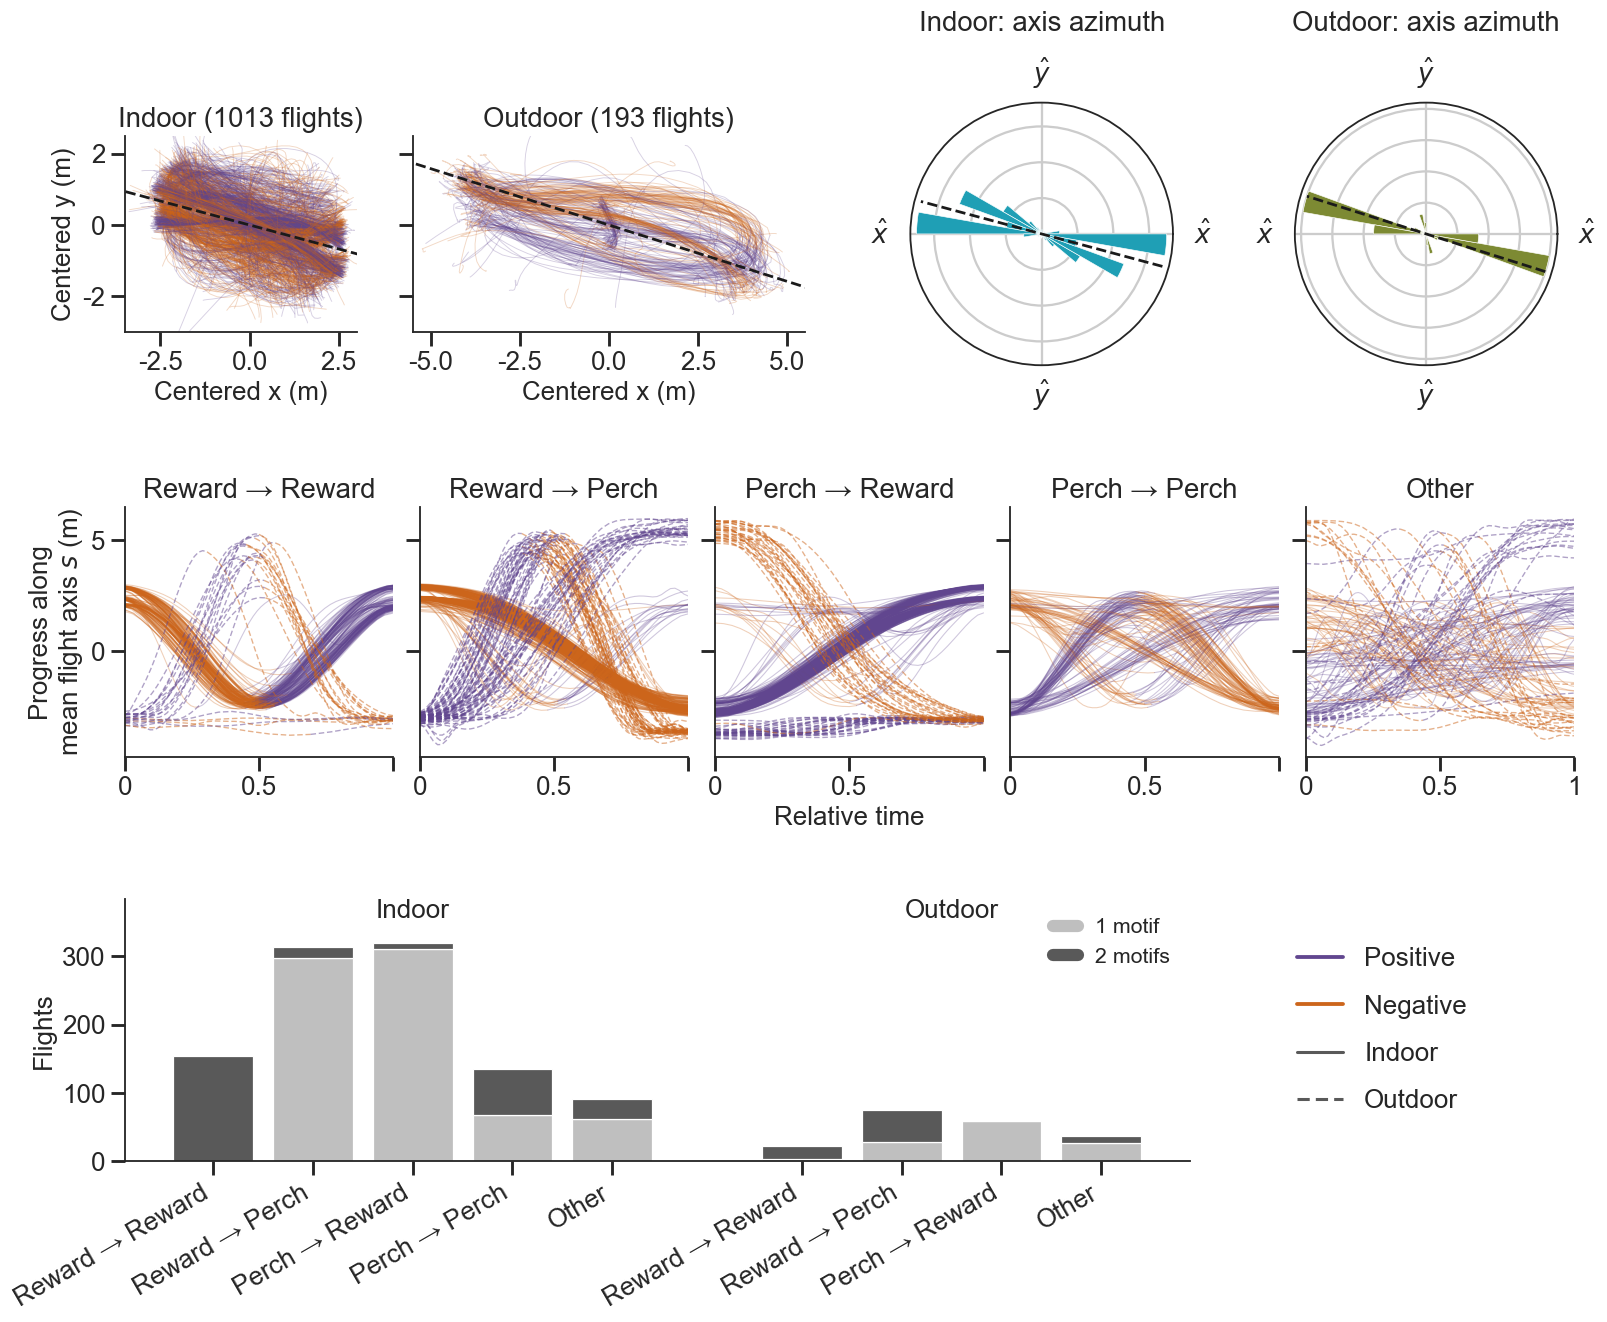

In [876]:
# === Extended Data Figure 4: the flight axis, and the motif segmentation built on it ===
# Justification cell for the Figure 2 motif definition, and the definition itself.
#
# Fig 2's unit of analysis is a flight SEGMENT: a flight is composed of at most two
# behavioral MOTIFS, one traveling along the room's principal axis of motion and one
# traveling back against it. Point-to-point flights (rew->perch, perch->rew) are a single
# motif; loops (rew->rew) are one of each. The earlier definition was reward-anchored --
# d(t) = distance to the nearest feeder -- which makes the away/toward label incomparable
# across rooms whose reward geometry is mirrored (indoor feeders sit at x ~ +2.6, the
# outdoor feeder at x = -3.0). The replacement is room-frame and reward-free: the sign of
# progress along the room's own mean flight axis. That substitution is only legitimate if
# there IS such an axis, which is a claim about the flight data, so it is measured here.
#
# Per TRAIN flight: resample to uniform ARC LENGTH first (raw 100 ms bins over-weight the
# hover near a feeder and drag PC1 toward the endpoint cluster), mean-center, then PCA ->
# unit first eigenvector v and eigenvalues lam. PC1's sign is arbitrary, so every quantity
# below is |.|-folded. Fit in raw meters with NO per-axis z-scoring, which would rescale
# the room and so destroy the very geometry being measured.
#
# What is reported, per environment:
#   |v.x|, |v.y|, |v.z|      mechanically coupled (they sum in square to 1), so x-vs-y is a
#                            WITHIN-flight contrast that needs no external null
#   dominant axis            argmax_e |v.e| -- the headline fraction
#   anisotropy lam1/sum(lam) a near-isotropic flight has no axis at all and its v scatters
#                            uniformly, so those are not counterexamples; alignment rises
#                            monotonically with anisotropy, i.e. the well-defined flights
#                            are the aligned ones
#   |chord.x|                same projection for the straight line between the flight's
#                            endpoints. If the flight axis were no more x-aligned than its
#                            own chord, the honest claim would be "the task geometry defines
#                            an x axis and flights inherit it" rather than anything about
#                            how the bat flies -- so the two are printed side by side
#   axial azimuth mod 180    panel B: one mode at x_hat is the result; a second mode at
#                            y_hat would be the indoor near-perch family (4 of the 6 perches
#                            sit on the feeder wall at x ~ +1.3..2.5, so rew<->near-perch
#                            flights span < 1.4 m of x against up to 3.0 m of y)
#
# Reference null. Flight axes turn out near-horizontal (median elevation ~1-2 deg, printed
# below), so the honest uniform null is uniform AZIMUTH, whose |cos| has density
# (2/pi)(1-u^2)^-1/2: median 0.707 and P(>0.9) = 0.287. The uniform-on-the-sphere null would
# give |v.x| ~ U[0,1] -- median 0.5, P(>0.9) = 0.10 -- which flatters the result by treating
# the unused vertical dimension as if the bat were free to pick an axis in it.
#
# Panels (all TRAIN flights, both rooms; the axis is fitted on train flights only so that
# applying it to held-out flights downstream stays honest):
#   A  every flight top-down, each on its own centroid, colored by motif, with the fitted
#      axis through the origin
#   B  the axial azimuth rose the axis is fitted from; dashed = the fitted axis (panel A)
#   C  progress s(t) along that axis, one column per route, indoor solid / outdoor
#      dashed, colored by motif
#   D  motifs per flight, by route and room
#   E  the payoff, in the Twin ENCODE latent: example flights of three routes in the same
#      PCA space Fig 2a/b uses. NOTE this panel reads `rsa_recs`, so this cell now sits
#      after the shared latent extraction -- it still owns every motif definition, and
#      `fig2m_motifs` (which applies them) still runs after it.
from scipy.stats import wilcoxon
from notebook_helpers import DIST_THRESH, get_target_locs

AXFIT_NPTS = 50        # arc-length resample points per flight
AXFIT_MIN_BINS = 8     # flights shorter than this get no axis
AXFIT_MIN_PATH = 1.0   # ... nor do flights with < 1 m of path
AXFIT_COMPS = ['|v.x|', '|v.y|', '|v.z|']


def axfit_arclen_resample(P, n=AXFIT_NPTS):
    """Resample an (T, 3) polyline to `n` points equally spaced in arc length."""
    s = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(P, axis=0), axis=1))])
    if s[-1] <= 0:
        return None
    u = np.linspace(0.0, s[-1], n)
    return np.column_stack([np.interp(u, s, P[:, d]) for d in range(3)])


def axfit_flight_axis(P):
    """Unit PC1 (sign arbitrary) and descending eigenvalues of an arc-length-uniform path."""
    lam, V = np.linalg.eigh(np.cov(P.T))
    return V[:, -1], np.clip(lam[::-1], 0, None)


_ax_recs, axfit_paths = [], {}
for _sn, _dl in dataloaders['train'].items():
    _ds = _dl.dataset
    # meta is 13-dim (kinematic) under make_joint_dataloaders; position is the first 3.
    _bm = np.asarray(meta_info_dict['behavior_mean'][_sn]).reshape(-1)[:3]
    _bs = np.asarray(meta_info_dict['behavior_std'][_sn]).reshape(-1)[:3]
    _pos = _ds.behavior.numpy()[..., :3] * _bs + _bm
    _msk = _ds.mask.numpy().astype(bool)
    _fpi = _ds.flight_path_index.numpy().astype(int)
    _rew, _perch = get_target_locs(_sn)
    for _i in range(_pos.shape[0]):
        _p = _pos[_i, _msk[_i]]
        if len(_p) < AXFIT_MIN_BINS:
            continue
        _plen = float(np.linalg.norm(np.diff(_p, axis=0), axis=1).sum())
        if _plen < AXFIT_MIN_PATH:
            continue
        _q = axfit_arclen_resample(_p)
        if _q is None:
            continue
        _v, _lam = axfit_flight_axis(_q)
        _ch = _p[-1] - _p[0]
        _chn = np.linalg.norm(_ch)
        axfit_paths[(_sn, int(_fpi[_i]))] = _p
        _ax_recs.append(dict(
            session=_sn, bat=parse_bat(_sn), flight_id=int(_fpi[_i]),
            env='indoor' if ph.is_indoor(_sn) else 'outdoor',
            route=ph.route_id(ph.endpoint_class(_p[0], _rew, _perch, DIST_THRESH),
                              ph.endpoint_class(_p[-1], _rew, _perch, DIST_THRESH)),
            n_bins=len(_p), path_len=_plen,
            **dict(zip(AXFIT_COMPS, np.abs(_v))),
            **dict(zip(('v_x', 'v_y', 'v_z'), _v)),   # signed: needed for the tensor fit
            **dict(zip(('c_x', 'c_y', 'c_z'), _q.mean(0))),
            aniso=float(_lam[0] / _lam.sum()),
            elev_deg=float(np.degrees(np.arcsin(min(abs(_v[2]), 1.0)))),
            chord_x=float(abs(_ch[0]) / _chn) if _chn > 1e-9 else np.nan,
            # axial azimuth folded to [-90, 90): 0 = x_hat-aligned, +/-90 = y_hat-aligned
            azim=float((np.degrees(np.arctan2(_v[1], _v[0])) + 90) % 180 - 90)))

axfit_df = pd.DataFrame(_ax_recs)
axfit_df['dominant'] = ['xyz'[i] for i in np.argmax(axfit_df[AXFIT_COMPS].to_numpy(), axis=1)]
axfit_df['route_label'] = [ph.ROUTE_LABELS[r] for r in axfit_df['route']]
AXFIT_ENVS = [e for e in ('indoor', 'outdoor') if (axfit_df['env'] == e).any()]
_ROUTE_SEQ = [ph.ROUTE_LABELS[r] for r in (1, 2, 3, 4, 0)]   # display order, 'other' last
_AX = AXFIT_COMPS[0]

# --- Fit the per-environment MEAN axis, signed to +x ----------------------------------
# Fit on the routes the motif analysis keeps (`MOTIF_DROP_ROUTES = (0, 4)` -- 'other' and
# perch->perch are the two poorly-axial route classes, see the by-route table below), so
# the axis is estimated from the flights it will actually be applied to.
#
# MEAN, not mode. The orientation tensor T = sum_i w_i v_i v_i^T is the textbook
# sign-invariant aggregator (a vector mean is meaningless -- randomly-signed unit vectors
# average to ~0 -- whereas T's top eigenvector maximizes sum_i w_i (v_i . u)^2 with no
# reference direction and no iterative sign-flipping), and it has NO free parameter.
#
# The alternative, used until 2026-07-30, was the wrapped-KDE mode of the azimuth. It is
# marginally better aligned by the flights' own metric (median |v.u| 0.9879 vs 0.9845
# indoor, 0.9956 vs 0.9939 outdoor) because indoors the azimuth is BIMODAL -- two route
# bundles peaking near -5.5 and -25 deg -- so the mode sits on the larger bundle while the
# tensor mean lands at -15 deg, between them. That gain is not worth a knob: the mode
# itself moves -5.3 -> -12.4 deg as the bandwidth goes 3 -> 12 deg (i.e. at bw 12 it IS the
# mean), whereas the labels barely move. Switching mode -> mean is 9.55 deg indoor / 3.55
# deg outdoor and changes the split count of 0 of the 232 Fig 2 flights (0.93% of bins) and
# 3 of 1206 train flights (0.74% of bins) -- the segmentation reads only the SIGN of ds/dt,
# which tolerates ~10 deg of axis error. The KDE is kept below as a diagnostic (it is what
# shows the bimodality) but nothing is fitted with it.
#
# The axis is forced HORIZONTAL. Median per-flight axis elevation is 1.3 deg (indoor) /
# 2.4 deg (outdoor), so this costs ~2 deg and buys an axis that is a room-frame heading.
AXFIT_KDE_BW = 5.0           # deg; diagnostic only -- the fit does not use the KDE
AXFIT_FIT_DROP_ROUTES = (0, 4)


def axfit_orientation_tensor(sub):
    """(top eigenvector signed to +x, descending eigenvalues) of T = sum_i w_i v_i v_i^T.

    Weight = anisotropy (a near-isotropic flight has no axis, so it must not vote) divided
    by the session's flight count (so one busy session cannot set the room axis)."""
    V = sub[['v_x', 'v_y', 'v_z']].to_numpy()
    w = sub['aniso'].to_numpy() / sub.groupby('session')['session'].transform('size').to_numpy()
    tau, U = np.linalg.eigh((V * w[:, None]).T @ V / w.sum())
    u = U[:, -1]
    return u * (np.sign(u[0]) or 1.0), tau[::-1]


def axfit_azimuth_density(az, bw=AXFIT_KDE_BW, n=1440):
    """Wrapped Gaussian KDE of the folded (period-180 deg) axial azimuth, on a fixed grid."""
    g = np.linspace(-90, 90, n, endpoint=False)
    return g, np.exp(-0.5 * (((az[None, :] - g[:, None] + 90) % 180 - 90) / bw) ** 2).sum(1)


def axfit_angle(a, b):
    """Acute angle (deg) between two axes."""
    return float(np.degrees(np.arccos(min(abs(float(np.dot(a, b))), 1.0))))


_afit = axfit_df[~axfit_df['route'].isin(AXFIT_FIT_DROP_ROUTES)]
AXFIT_AXIS, AXFIT_CENTROID, AXFIT_AZIM = {}, {}, {}
for _e in AXFIT_ENVS:
    _s = _afit[_afit['env'] == _e]
    _u = axfit_orientation_tensor(_s)[0]
    _az = float(np.degrees(np.arctan2(_u[1], _u[0])))     # drop the (tiny) vertical component
    AXFIT_AZIM[_e] = _az
    AXFIT_AXIS[_e] = np.array([np.cos(np.radians(_az)), np.sin(np.radians(_az)), 0.0])
    AXFIT_CENTROID[_e] = _s[['c_x', 'c_y', 'c_z']].to_numpy().mean(0)


def axfit_project(xyz, session):
    """Signed progress (m) along the room's mean flight axis, centered on its centroid."""
    _e = 'indoor' if ph.is_indoor(session) else 'outdoor'
    return (np.asarray(xyz, float) - AXFIT_CENTROID[_e]) @ AXFIT_AXIS[_e]


# --- The motif segmentation itself ----------------------------------------------------
# Labelling. s(t) = signed progress along the mean axis (meters), lightly smoothed. Label
# every step z_t in {positive, negative} subject to AT MOST ONE SWITCH, maximizing progress
# in the labeled direction against a switch penalty:
#       J(z) = sum_t z_t (s_t - s_{t+1}) - lambda * 1[switch]
# With <= 1 switch this is closed form. One motif scores |s_0 - s_{T-1}|; a split after k
# scores |s_0 - s_k| + |s_k - s_{T-1}|, and only counts as a switch when the two legs run
# in OPPOSITE axial directions. The gain over one motif is then exactly 2*e(k), with
#       e(k) = min(|s_0 - s_k|, |s_k - s_{T-1}|)
# the overshoot of the turning point past the nearer endpoint. So the optimum is
# k* = argmax e(k) and the switch is accepted iff e(k*) >= lambda/2 = the threshold below.
# A monotone s(t) admits no valid k at all, so straight flights come out single-motif by
# construction rather than by thresholding.
#
# In practice the axial definition is close to a relabeling of the reward-anchored one: on
# the indoor test flights the two agree on 98.7% of split counts and 98.8% of per-bin
# labels, and substituting raw x_hat for the fitted axis moves <1% of labels. The gain is
# conceptual, not numerical -- do not present it as fixing a measurement.

# 0 = traveling along +u1 (which points along +x by construction), 1 = along -u1. NOTE the
# polarity is NOT the old away/toward: indoor feeders sit at +x, so 'positive' corresponds
# to the old 'toward' and index 0 has changed meaning. MOTIF_COLORS is unchanged, so the
# hue<->direction pairing has inverted relative to earlier versions of this figure.
MOTIF_LABELS = ['positive', 'negative']
# PuOr endpoints (#5e3c99 / #e66101) taken to ~78% saturation -- half way to a fully
# muted pair. Muted enough not to glare under a few hundred overlapping semi-transparent
# lines, while the warm one keeps enough chroma to read orange rather than brown. Still
# clear of every route and bat hue.
MOTIF_COLORS = ['#61468f', '#cc651b']
MOTIF_MIN_EXC_M = 0.50       # turning point must overshoot the nearer endpoint by >= 0.5 m
MOTIF_MIN_EXC_FRAC = 0.25    #   ... and by >= 25% of the flight's axial range
MOTIF_MIN_FRAC = 0.15        # each motif >= 15% of the flight ...
MOTIF_MIN_BINS = 3           #   ... and >= 3 bins (Hausdorff needs a real point cloud)
MOTIF_SMOOTH = 3             # centered moving average on s(t) before locating the turn
# The split count is flat over m >= 0.3-1.0 m / frac 0.15-0.40 (34/34 loops split at every
# setting; total two-motif flights 57 -> 54), so these sit inside a plateau, not on an edge.
# (Re-verified on the axial trace; the reward-distance trace gave 58 -> 55 on the same grid.)


def _motif_smooth(d):
    """Centered moving average, shared by both progress traces."""
    if len(d) >= MOTIF_SMOOTH:
        return pd.Series(d).rolling(MOTIF_SMOOTH, center=True, min_periods=1).mean().to_numpy()
    return d


def motif_reward_distance(xyz, session):
    """d(t) = distance to the nearest reward feeder for one flight, lightly smoothed.

    Superseded by `motif_axis_progress` for this figure, but retained because the Fig 3
    cells (`fig3_ratemap_sim`, `fig3tri_data`) still segment on it."""
    rew, _ = get_target_locs(session)
    return _motif_smooth(
        np.linalg.norm(xyz[:, None, :] - np.asarray(rew)[None, :, :], axis=2).min(1))


def motif_axis_progress(xyz, session):
    """s(t) = signed progress (m) along the room's mean flight axis, lightly smoothed.

    `axfit_project` centres on the environment's flight centroid, which `segment_motifs`
    never sees -- it uses only differences of s -- so the centering is for interpretability
    only and the labels are translation-invariant."""
    return _motif_smooth(axfit_project(xyz, session))


def motif_segment_axis(xyz, session):
    """(acute angle in deg between THIS SEGMENT's own PC1 and its room's mean axis,
    the segment's anisotropy lam1/sum(lam)); (nan, nan) if it is too short to have an axis.

    Same arc-length-resampled PCA recipe as above, applied per segment rather than per
    flight. `fig2m_rsa` gates the quantified set on this angle."""
    p = np.asarray(xyz, float)
    if len(p) < 3:
        return np.nan, np.nan
    q = axfit_arclen_resample(p)
    if q is None:
        return np.nan, np.nan
    v, lam = axfit_flight_axis(q)
    return (axfit_angle(v, AXFIT_AXIS['indoor' if ph.is_indoor(session) else 'outdoor']),
            float(lam[0] / lam.sum()))


def segment_motifs(d):
    """Optimal <=1-switch two-direction labeling of a monotone-progress trace `d`.

    Works on any scalar progress variable: `motif_axis_progress` (signed axial progress,
    used by Fig 2) or `motif_reward_distance` (radial, used by the Fig 3 cells).

    Returns ``(bounds, labels, excursion, threshold)``: `bounds` a list of one or two
    ``(start, stop)`` index slices, `labels` the matching motif ids (0 where the trace
    INCREASES, 1 where it decreases -- i.e. 0 positive / 1 negative for an axial trace),
    `excursion` the best e(k*) in meters (whether or not the switch was accepted) and
    `threshold` the value it had to clear."""
    T = len(d)
    lo = max(MOTIF_MIN_BINS, int(np.ceil(MOTIF_MIN_FRAC * T)))
    single = ([(0, T)], [int(d[-1] < d[0])])
    thresh = max(MOTIF_MIN_EXC_M, MOTIF_MIN_EXC_FRAC * float(d.max() - d.min()))
    if T < 2 * lo:
        return (*single, 0.0, thresh)
    k = np.arange(lo - 1, T - lo)                     # split after k -> legs [0, k], [k+1, T)
    a, b = d[k] - d[0], d[-1] - d[k]                  # signed progress per leg
    e = np.where(a * b < 0, np.minimum(np.abs(a), np.abs(b)), -np.inf)   # opposite legs only
    if not np.isfinite(e).any():                      # monotone d(t): no valid switch
        return (*single, 0.0, thresh)
    i = int(np.argmax(e))
    if e[i] < thresh:
        return (*single, float(e[i]), thresh)
    ks = int(k[i])
    return ([(0, ks + 1), (ks + 1, T)], [int(a[i] < 0), int(b[i] < 0)], float(e[i]), thresh)


# Segment every train flight (Fig 2 re-runs this on its own held-out flight records).
axfit_motif_flights = []
for _r in axfit_df.itertuples():
    _p = axfit_paths[(_r.session, _r.flight_id)]
    _d = motif_axis_progress(_p, _r.session)
    _bounds, _labs, _exc, _th = segment_motifs(_d)
    axfit_motif_flights.append(dict(session=_r.session, flight_id=_r.flight_id, env=_r.env,
                                    route_label=_r.route_label, xyz=_p, d=_d, bounds=_bounds,
                                    labels=_labs, n_motif=len(_bounds), excursion=_exc,
                                    thresh=_th, c_xy=np.array([_r.c_x, _r.c_y])))
axfit_motif_df = pd.DataFrame([{k: v for k, v in f.items()
                                if k not in ('xyz', 'd', 'bounds', 'labels', 'c_xy')}
                               for f in axfit_motif_flights])

# --- Numbers -------------------------------------------------------------------------
_null_med, _null_p90 = np.cos(np.pi / 4), 2 / np.pi * np.arccos(0.9)
print(f'Principal axis of within-flight motion, {len(axfit_df)} train flights '
      f'({axfit_df["session"].nunique()} sessions), arc-length resampled to {AXFIT_NPTS} pts.')
print(f'Uniform-azimuth null: median |v.x| = {_null_med:.3f}, P(|v.x| > 0.9) = {_null_p90:.3f}\n')
for _env in AXFIT_ENVS:
    _s = axfit_df[axfit_df['env'] == _env]
    print(f'--- {_env}  ({len(_s)} flights, {_s["session"].nunique()} sessions, '
          f'{_s["bat"].nunique()} bats)')
    print('  median  ' + '   '.join(f'{c} = {_s[c].median():.3f}' for c in AXFIT_COMPS)
          + f'   |  axis elevation = {_s["elev_deg"].median():.1f} deg'
            '  (-> the horizontal null is the right one)')
    print('  dominant axis:  ' + '  '.join(
        f'{a} {100 * (_s["dominant"] == a).mean():.1f}%' for a in 'xyz'))
    print(f'  P(|v.x| > 0.9) = {(_s[_AX] > 0.9).mean():.3f}  (null {_null_p90:.3f})   '
          f'median |v.x| = {_s[_AX].median():.3f}  (null {_null_med:.3f})')
    print(f'  endpoint chord: median |chord.x| = {_s["chord_x"].median():.3f}  '
          f'(flight axis {_s[_AX].median():.3f})')
    _pv = _s.groupby('session')[AXFIT_COMPS[:2]].median()
    if len(_pv) >= 6:
        print(f'  |v.x| > |v.y|, paired Wilcoxon on session medians (n = {len(_pv)}): '
              f'P = {wilcoxon(_pv[_AX], _pv[AXFIT_COMPS[1]])[1]:.2e}')
    else:                                    # too few sessions to test; show them all
        print(f'  per-session median |v.x| (n = {len(_pv)}, no test): '
              + ', '.join(f'{v:.3f}' for v in _pv[_AX]))
    print('  by route:')
    print('    ' + _s.groupby('route_label')
          .agg(n=('route', 'size'), med_vx=(_AX, 'median'), med_vy=(AXFIT_COMPS[1], 'median'),
               med_aniso=('aniso', 'median'), med_chord_x=('chord_x', 'median'))
          .round(3).to_string().replace('\n', '\n    '))
    _t = pd.qcut(_s['aniso'], 3, labels=['low', 'mid', 'high'])
    print('  by anisotropy tercile:  ' + '  '.join(
        f'{k} (a={g["aniso"].median():.2f}) |v.x|={g[_AX].median():.3f}'
        for k, g in _s.groupby(_t, observed=True)) + '\n')

# --- The fitted axis, and how much the choice matters ---------------------------------
# tau1 (not Woodcock's K) is the cluster-vs-girdle statistic here: K = ln(tau1/tau2) /
# ln(tau2/tau3) is unreliable when tau3 -> 0, which is exactly this near-horizontal case --
# the unused vertical dimension inflates ln(tau2/tau3) and drags K below 1, reading as a
# "girdle" even when tau1 ~ 0.94 makes it emphatically a single axis.
print('Fitted mean axis per environment (train flights, kept routes, signed to +x):')
for _e in AXFIT_ENVS:
    _s = _afit[_afit['env'] == _e]
    _u, _tau = axfit_orientation_tensor(_s)
    _g, _dn = axfit_azimuth_density(_s['azim'].to_numpy())
    _pk = [i for i in range(len(_g))
           if _dn[i] > _dn[i - 1] and _dn[i] >= _dn[(i + 1) % len(_g)] and _dn[i] > 0.25 * _dn.max()]
    _um = AXFIT_AXIS[_e]
    _V = _s[['v_x', 'v_y', 'v_z']].to_numpy()
    _mz = float(_g[_dn.argmax()])
    _umode = np.array([np.cos(np.radians(_mz)), np.sin(np.radians(_mz)), 0.0])
    print(f'--- {_e}  (n = {len(_s)} kept-route flights)')
    print(f'    MEAN axis u1 = [{_um[0]:+.4f} {_um[1]:+.4f} {_um[2]:+.4f}]   '
          f'azimuth {AXFIT_AZIM[_e]:+.2f} deg   angle to +x = '
          f'{axfit_angle(_um, np.array([1.0, 0.0, 0.0])):.2f} deg   '
          f'(raw tensor eigenvector {axfit_angle(_u, _um):.2f} deg off horizontal)')
    print(f'    tau = {np.round(_tau, 4)}   tau1/tau2 = {_tau[0] / _tau[1]:.1f}  '
          f'({"single axis" if _tau[0] / _tau[1] > 3 else "NOT a single axis"})')
    print(f'    KDE mode (diagnostic, bw {AXFIT_KDE_BW:.0f} deg): azimuth {_mz:+.2f} deg, '
          f'{axfit_angle(_umode, _um):.2f} deg from the fitted axis   |   peaks '
          f'{[(round(float(_g[i]), 1), round(float(_dn[i] / _dn.max()), 2)) for i in _pk]}')
    print('    median |v.u|:  mean %.4f   KDE mode %.4f   x_hat %.4f'
          % tuple(np.median(np.abs(_V @ _a)) for _a in
                  (_um, _umode, np.array([1.0, 0.0, 0.0]))))
    _ps = np.array([axfit_angle(axfit_orientation_tensor(_gg)[0], _um)
                    for _, _gg in _s.groupby('session') if len(_gg) >= 10])
    # The segmentation is insensitive to ~10 deg of axis error (the mode-vs-mean swap above,
    # 9.55 deg indoor, moved <1% of labels), so per-session scatter below ~10 deg means one
    # axis per environment is enough; a large max flags sessions worth looking at.
    print(f'    per-session axis vs env axis (n = {len(_ps)}): median {np.median(_ps):.2f} deg, '
          f'max {_ps.max():.2f} deg -> per-environment axis '
          f'{"OK" if np.median(_ps) < 10 else "QUESTIONABLE"}'
          f'{"" if _ps.max() < 20 else f"; {int((_ps >= 20).sum())} session(s) >= 20 deg off"}')
if len(AXFIT_AXIS) == 2:
    print('indoor axis vs outdoor axis: '
          f'{axfit_angle(AXFIT_AXIS["indoor"], AXFIT_AXIS["outdoor"]):.2f} deg')
print('\nMotifs per flight, by room and route:')
print(pd.crosstab([axfit_motif_df['env'],
                   pd.Series(ph.order_categorical(axfit_motif_df['route_label'], _ROUTE_SEQ),
                             name='route')],
                  axfit_motif_df['n_motif']).rename_axis(columns='n motifs').to_string())

# --- Figure ---------------------------------------------------------------------------
_E4_FS = plt.rcParams['axes.labelsize']          # one tick/label size for the whole canvas
_E4_ENV_LS = {'indoor': '-', 'outdoor': (0, (4, 2))}
_E4_NMOTIF_C = {1: '0.75', 2: '0.35'}


def _e4_lim(v, pad=0.25, q=0.2):
    """Symmetric-ish half-meter display limits that drop the 0.2% tails."""
    lo, hi = np.percentile(v, [q, 100 - q])
    return np.floor((lo - pad) * 2) / 2, np.ceil((hi + pad) * 2) / 2


def _e4_route_name(rl):
    """'rew→perch' -> 'Reward → Perch': this figure spells the endpoints out."""
    return ' → '.join('Reward' if p == 'rew' else p.capitalize() for p in rl.split('→'))


# Each flight is drawn on its own arc-length centroid, so panel A is a pure shape display.
_e4_xy = {e: np.concatenate([f['xyz'][:, :2] - f['c_xy'] for f in axfit_motif_flights
                             if f['env'] == e]) for e in AXFIT_ENVS}
_e4_xlim = {e: _e4_lim(_e4_xy[e][:, 0]) for e in AXFIT_ENVS}
_e4_ylim = [_e4_lim(_e4_xy[e][:, 1]) for e in AXFIT_ENVS]
_e4_ylim = (min(y[0] for y in _e4_ylim), max(y[1] for y in _e4_ylim))

fig_ed4 = plt.figure(figsize=(17, 12.5))
_gs4 = fig_ed4.add_gridspec(3, 4, height_ratios=[1.0, 0.95, 1.0], hspace=0.55, wspace=0.30)

# (A) every train flight, centered on itself, colored by motif. Equal aspect + a shared y
# range + column widths in proportion to the x ranges => both rooms are drawn at the SAME
# meters-per-inch while each panel stays full.
_gs4a = _gs4[0, :2].subgridspec(1, 2, wspace=0.18,
                                width_ratios=[np.ptp(_e4_xlim[e]) for e in AXFIT_ENVS])
for _j, _env in enumerate(AXFIT_ENVS):
    _ax = fig_ed4.add_subplot(_gs4a[0, _j])
    for _f in axfit_motif_flights:
        if _f['env'] != _env:
            continue
        _xy = _f['xyz'][:, :2] - _f['c_xy']
        for (_s0, _s1), _lb in zip(_f['bounds'], _f['labels']):
            _sl = slice(_s0, min(_s1 + 1, len(_xy)))     # +1 so the legs join up visually
            _ax.plot(_xy[_sl, 0], _xy[_sl, 1], color=MOTIF_COLORS[_lb], lw=0.6, alpha=0.25)
    _u = AXFIT_AXIS[_env]
    _ax.plot(np.array([-20.0, 20.0]) * _u[0], np.array([-20.0, 20.0]) * _u[1],
             color='k', ls='--', lw=1.8, zorder=5)
    _ax.set(xlim=_e4_xlim[_env], ylim=_e4_ylim, aspect='equal', xlabel='Centered x (m)',
            ylabel='Centered y (m)' if _j == 0 else '')
    _ax.set_title(f'{_env} ({(axfit_motif_df["env"] == _env).sum()} flights)')
    if _j:                                   # motif key lives under (C), which shares it
        _ax.set_yticklabels([])

# (B) the axial azimuth rose the mean axis is fitted from (two opposed petals per flight).
# Colored by environment from the canonical `ph.ENV_PALETTE`, which was re-picked on
# 2026-07-30 precisely so that it clears the motif, bat and route palettes -- its old
# outdoor orange was the negative-motif orange, which read as a motif on this canvas.
for _j, _env in enumerate(AXFIT_ENVS):
    _ax = fig_ed4.add_subplot(_gs4[0, 2 + _j], projection='polar')
    _th = np.radians(axfit_df.loc[axfit_df['env'] == _env, 'azim'].to_numpy())
    _cnt, _ed = np.histogram(np.concatenate([_th, _th + np.pi]) % (2 * np.pi),
                             bins=36, range=(0, 2 * np.pi))
    _ax.bar(_ed[:-1], _cnt, width=np.diff(_ed), align='edge',
            color=ph.ENV_PALETTE[_env], edgecolor='w', lw=0.4)
    _amz = np.radians(AXFIT_AZIM[_env])                  # the fitted axis, both petals
    _ax.plot([_amz, _amz + np.pi], [_cnt.max()] * 2, color='k', ls='--', lw=1.8, zorder=5)
    _ax.set_thetagrids([0, 90, 180, 270], labels=['$\\hat{x}$', '$\\hat{y}$',
                                                  '$\\hat{x}$', '$\\hat{y}$'])
    _ax.set_yticklabels([])
    _ax.set_title(f'{_env}: axis azimuth', pad=16)   # the fitted angle is in the print-out

# (C) the progress trace the segmentation actually reads, one column per route, both rooms
# overlaid. The columns share a y axis, so the routes are directly comparable and the
# outdoor room's much longer flights set the range.
_gs4c = _gs4[1, :].subgridspec(1, len(_ROUTE_SEQ), wspace=0.10)
_ax4c = []
for _ci, _rl in enumerate(_ROUTE_SEQ):
    _ax = fig_ed4.add_subplot(_gs4c[0, _ci], sharey=_ax4c[0] if _ax4c else None)
    _ax4c.append(_ax)
    for _f in sorted(axfit_motif_flights, key=lambda f: f['env'] == 'outdoor'):
        if _f['route_label'] != _rl:
            continue
        _out = _f['env'] == 'outdoor'
        _tt = np.arange(len(_f['d'])) / max(len(_f['d']) - 1, 1)
        for (_s0, _s1), _lb in zip(_f['bounds'], _f['labels']):
            _sl = slice(_s0, min(_s1 + 1, len(_f['d'])))
            _ax.plot(_tt[_sl], _f['d'][_sl], color=MOTIF_COLORS[_lb], ls=_E4_ENV_LS[_f['env']],
                     lw=0.9 if _out else 0.7, alpha=0.5 if _out else 0.3)
    _ax.set(xlim=(0, 1), xticks=[0, 0.5, 1.0],
            xlabel='Relative time' if _ci == len(_ROUTE_SEQ) // 2 else '',
            ylabel='Progress along\nmean flight axis $s$ (m)' if _ci == 0 else '')
    # the shared y axis butts the columns together, so only the rightmost keeps its '1'
    _ax.set_xticklabels(['0', '0.5', '1' if _ci == len(_ROUTE_SEQ) - 1 else ''])
    _ax.set_title(_e4_route_name(_rl))
    if _ci:
        _ax.tick_params(labelleft=False)
_e4_c_handles = ([plt.Line2D([], [], color=MOTIF_COLORS[i], lw=2.5, label=MOTIF_LABELS[i])
                  for i in (0, 1)]
                 + [plt.Line2D([], [], color='0.35', lw=2.0, ls=_E4_ENV_LS[e], label=e)
                    for e in AXFIT_ENVS])

# (D) how many motifs each route decomposes into, per room.
_ax4d = fig_ed4.add_subplot(_gs4[2, :3])          # the encode-latent panel moved to Fig 2b
_e4_cnt = (axfit_motif_df.groupby(['env', 'route_label', 'n_motif']).size()
           .unstack('n_motif', fill_value=0))
_e4_tk, _e4_lb, _e4_grp, _e4_x = [], [], [], 0.0
for _env in AXFIT_ENVS:
    _grp = []
    for _rl in _ROUTE_SEQ:
        if (_env, _rl) not in _e4_cnt.index:
            continue
        _row, _bot = _e4_cnt.loc[(_env, _rl)], 0.0
        for _k, _c in _E4_NMOTIF_C.items():
            _ax4d.bar(_e4_x, _row.get(_k, 0), bottom=_bot, width=0.8, color=_c,
                      edgecolor='w', lw=0.8)
            _bot += _row.get(_k, 0)
        _grp.append(_e4_x); _e4_tk.append(_e4_x); _e4_lb.append(_e4_route_name(_rl))
        _e4_x += 1
    _e4_grp.append((_env, _grp))
    _e4_x += 0.9
_ax4d.set_xticks(_e4_tk)
_ax4d.set_xticklabels(_e4_lb, rotation=30, ha='right')
_ax4d.set(ylabel='Flights', ylim=(0, _e4_cnt.sum(axis=1).max() * 1.2))
for _env, _grp in _e4_grp:
    _ax4d.text(np.mean(_grp), _ax4d.get_ylim()[1], _env.capitalize(), ha='center',
               va='top', fontsize=_E4_FS)
_ax4d.legend(handles=[plt.Line2D([], [], color=_c, lw=8, label=f'{_k} motif' + 's' * (_k > 1))
                      for _k, _c in _E4_NMOTIF_C.items()],
             frameon=False, fontsize=_E4_FS - 3, loc='upper right', handlelength=1.2)

# The (C) legend fills the bottom-right corner freed by the encode-latent panel that moved
# to Fig 2b, stacked one entry per row -- drawn last, so (C)'s and (D)'s final positions are
# known and it can be centred on what is left of the bottom row.
_e4_pd, _e4_right = _ax4d.get_position(), _ax4c[-1].get_position().x1
fig_ed4.legend(handles=_e4_c_handles, frameon=False, fontsize=_E4_FS, ncol=1,
               handlelength=1.8, labelspacing=0.9, loc='center',
               bbox_to_anchor=(0.5 * (_e4_pd.x1 + _e4_right),
                               0.5 * (_e4_pd.y0 + _e4_pd.y1)))

for _ax in fig_ed4.axes:
    _ax.tick_params(labelsize=_E4_FS)
ph.save_fig(fig_ed4, 'edfig4_motif_axis'); plt.show()

**Extended Data Figure 4 | Flight in both rooms is organized along a principal axis, which defines motifs.** (A) Every training flight seen from above, each translated onto its own centroid so that only its shape is shown, for the indoor room (n = 1,013 flights, 13 sessions, 4 bats) and the outdoor enclosure (n = 193 flights, 4 sessions, 2 bats). Each flight is cut into at most two motifs — travel along ($+$) or against ($-$) the room's mean flight axis — and colored accordingly. Dashed line, the fitted axis of (B), drawn through the origin. (B) Circular histograms of orientation of the per-flight principal axis, obtained by PCA. Dashed line, the room's fitted axis. (C) Signed progress $s(t)$ along each room's fitted axis for every flight in (A), one column per route and in normalized time, colored by motif; indoor solid, outdoor dashed, columns sharing one y axis. The motif boundary is the turning point that maximizes the overshoot past the nearer endpoint of $s$, accepted only when that overshoot clears 0.5 m and 25\% of the flight's axial range. (D) Number of motifs per flight, by route and environment. See also Figure \ref{fig:fig2}.

---
## Figure 2 — Transformer latents warp physical space to emphasize route identity and align across animals

Four representations compared column-by-column: true 3-D position (Physical XYZ), the unified-CEBRA latent, and the Twin 64-D neural latent in decode and encode modes. **a–b** Held-out flights as 3-D trajectories (CEBRA/Twin projected to 3-D by a shared PCA), colored by x-coordinate (**a**) and by flight route (**b**); trajectory rows restricted to the indoor lab room (Datasets 1 & 3). **c** Representational similarity analysis (RSA): time-averaged flight-by-flight Pearson correlation matrices, sorted by environment then route, across all 17 sessions and both environments. **d** Within-across-route correlation per representation. **e** One-vs-rest route-decoding balanced accuracy per representation (adds a raw-neural baseline). The latent-extraction cell below is reused by Figure 4.

In [ ]:
# === Fig 2 (motif variant) data: motif segmentation of the held-out flights ===
# EXPLORATORY sibling of Fig 2c. Built on the SAME per-flight records as Fig 2c
# (`rsa_recs` / `rsa_order`: indoor test flights, four spaces), so nothing about the
# underlying data changes -- only the unit of analysis, which becomes a flight SEGMENT.
#
# The segmentation is DEFINED AND JUSTIFIED in the ED Fig 4 cell above: the fitted
# per-room axis `AXFIT_AXIS`, the progress trace `motif_axis_progress`, and the
# at-most-one-switch labelling `segment_motifs`. This cell only applies it, and reports
# the counts on the flights Fig 2 actually uses. Each environment is segmented on its OWN
# fitted axis, so `positive` means the same thing (travelling along +u1) in either room --
# but Fig 2 is indoor-only, so only AXFIT_AXIS['indoor'] is exercised here.
#
# Idea: a flight is composed of at most two behavioural MOTIFS -- one leg travelling along
# the room's principal axis of motion and one travelling back against it. Point-to-point
# flights (rew->perch, perch->rew) are a single motif; loops (rew->rew) are one of each.

# --- Per-segment records: one entry per (session, flight_id, segment) ---------------
# Every space is sliced at the SAME motif boundary. Unified CEBRA is sliced at the
# matching *relative* index (its per-flight embedding is the same length here, but this
# stays correct if that ever changes).
motif_recs, motif_flights = {}, {}
for _mk in rsa_order:
    _r = rsa_recs[_mk]
    _d = motif_axis_progress(_r['xyz'], _r['session'])
    _bounds, _labs, _exc, _th = segment_motifs(_d)
    _ce = None if cebra_by_key is None else np.asarray(cebra_by_key[_mk], float)
    _T = len(_d)
    motif_flights[_mk] = dict(session=_r['session'], bat=_r['bat'], flight_id=_r['flight_id'],
                              route=_r['route'], cluster=_r['cluster'], d=_d,
                              bounds=_bounds, labels=_labs, excursion=_exc, thresh=_th,
                              n_motif=len(_bounds))
    for _si, ((_s0, _s1), _lb) in enumerate(zip(_bounds, _labs)):
        _adeg, _aani = motif_segment_axis(_r['xyz'][_s0:_s1], _r['session'])
        _rec = dict(session=_r['session'], bat=_r['bat'], flight_id=_r['flight_id'],
                    cluster=_r['cluster'], route=_r['route'], motif=_lb, seg=_si,
                    n_motif=len(_bounds), excursion=_exc,
                    axis_deg=_adeg, axis_aniso=_aani,
                    xyz=_r['xyz'][_s0:_s1], h_n=_r['h_n'][_s0:_s1],
                    h_d=_r['h_d'][_s0:_s1], spike=_r['spike'][_s0:_s1], d=_d[_s0:_s1])
        if _ce is not None:
            _c0, _c1 = (int(round(_s * len(_ce) / _T)) for _s in (_s0, _s1))
            _rec['cebra'] = _ce[_c0:max(_c1, _c0 + 1)]
        motif_recs[(_r['session'], _r['flight_id'], _si)] = _rec

motif_df = pd.DataFrame([{k: v for k, v in r.items()
                          if k not in ('xyz', 'h_n', 'h_d', 'spike', 'cebra', 'd')}
                         for r in motif_recs.values()])
motif_df['route_label'] = [ph.ROUTE_LABELS[r] for r in motif_df['route']]
motif_df['motif_label'] = [MOTIF_LABELS[m] for m in motif_df['motif']]
motif_df['n_bins'] = [len(r['xyz']) for r in motif_recs.values()]
_fl_df = pd.DataFrame([{k: v for k, v in f.items() if k not in ('d', 'bounds', 'labels')}
                       for f in motif_flights.values()])
_fl_df['route_label'] = [ph.ROUTE_LABELS[r] for r in _fl_df['route']]

print(f'Motif segmentation: {len(motif_flights)} indoor test flights -> {len(motif_recs)} segments')
print('\nMotifs per flight, by route:')
print(pd.crosstab(pd.Series(ph.order_categorical(_fl_df['route_label'], _ROUTE_SEQ),
                            name='route'), _fl_df['n_motif'])
      .rename_axis(columns='n motifs').to_string())
print('\nSegment motif label, by route:')
print(pd.crosstab(pd.Series(ph.order_categorical(motif_df['route_label'], _ROUTE_SEQ),
                            name='route'), motif_df['motif_label']).to_string())
print('\nTurning-point overshoot e(k*) (m), by route  [threshold ~'
      f'{_fl_df["thresh"].median():.2f} m]:')
print(_fl_df.groupby('route_label')['excursion'].describe()[
    ['count', '25%', '50%', '75%', 'max']].reindex(_ROUTE_SEQ).round(2).to_string())

In [ ]:
# === Fig 2 (motif variant) RSA data: segment-level (dis)similarity in the four spaces ===
# Exactly the Fig 2c recipe -- full native dimensionality (raw 3-D physical, raw 64-D
# CEBRA / Twin latents, no PCA), physical XYZ additionally per-session z-scored, symmetric
# Hausdorff distance between full variable-length point clouds, z-scored within each space
# -- but the unit is now a MOTIF SEGMENT rather than a whole flight, and the shared
# ordering leads with motif:
#            motif  ->  route ('other' last)  ->  bat  ->  session  ->  flight cluster
# Two-motif flights contribute their two legs as separate rows, split at k*.
from scipy.spatial.distance import directed_hausdorff

# The 3-D trajectory rows show EVERY indoor motif segment (`motif_order_all`). From the RSA
# row onward the quantified set (`motif_order`) drops perch->perch and 'other': for those
# neither endpoint pins the progress trace (median turning-point overshoot 0.12 m for the
# single-motif perch->perch flights), so their direction call is incidental rather than
# task-defined. What is left is two routes per motif, with rew->rew contributing one leg to
# each:  positive = {rew->rew leg 1, perch->rew},  negative = {rew->rew leg 2, rew->perch}
# (indoor feeders sit at +x, so travelling +x is the reward-approaching leg).
#
# An alternative geometric rule -- keep a segment iff its own principal axis lies within N deg
# of the room's mean axis -- was tried and reverted: at 30 deg it traded 37 segments in for 32
# out versus this route rule (280 vs 275) without changing any read-out's sign, and it made the
# selection depend on a second axis-tolerance knob. `motif_recs` still carries the per-segment `axis_deg` if it
# is wanted as a diagnostic; nothing selects on it.
MOTIF_DROP_ROUTES = (0, 4)
# ONE canonical segment set for the whole figure -- the RSA, the read-outs and the DMD row
# all iterate `motif_order`, so no row is computed on a different subset of the data.
# The length window is the DMD's requirement (a segment needs enough samples for a
# meaningful spectrum); at 12 bins it is a no-op guard here, since every kept segment is
# >= 13 bins. Note a 20-bin floor -- the whole-FLIGHT window used elsewhere -- would drop
# 41 of the 68 loop legs, which is why the segment figure cannot inherit it.
MOTIF_SEG_LEN = (12, 100)

_mbat_idx = {b: i for i, b in enumerate(ph.bat_order())}
_msess_idx = {s: i for i, s in enumerate(sorted(session_names))}
def _msort(k):
    r = motif_recs[k]
    return (r['motif'],                                        # positive block, then negative
            r['route'] if r['route'] != 0 else 99,             # 'other' sorts last
            _mbat_idx.get(r['bat'], 99), _msess_idx[r['session']], r['cluster'])


motif_order_all = sorted(                                      # 3-D rows: every indoor leg
    [k for k, r in motif_recs.items()
     if MOTIF_SEG_LEN[0] <= len(r['xyz']) <= MOTIF_SEG_LEN[1]], key=_msort)
motif_order = [k for k in motif_order_all                      # RSA row onward
               if motif_recs[k]['route'] not in MOTIF_DROP_ROUTES]
motif_motif_all = np.array([motif_recs[k]['motif'] for k in motif_order_all])


def _motif_arrays(getter, zsession=False):
    """Per-segment arrays in one space, row-aligned to `motif_order`."""
    arrs = [np.asarray(getter(k), float) for k in motif_order]
    if zsession:                       # physical XYZ only: kill room offset/scale
        _spt = np.concatenate([np.full(len(a), motif_recs[k]['session'])
                               for a, k in zip(arrs, motif_order)])
        _stk = np.ascontiguousarray(np.vstack(arrs), float)
        for _c in range(_stk.shape[1]):
            _stk[:, _c] = ph.zscore_by_session(_stk[:, _c], _spt)
        arrs = np.split(_stk, np.cumsum([len(a) for a in arrs])[:-1])
    return [np.ascontiguousarray(a, float) for a in arrs]   # directed_hausdorff wants C-order f8


def _motif_matrix(arrs):
    """Fig 2c's `_rsa_matrix`, over `motif_order` segments instead of whole flights."""
    n = len(arrs)
    D = np.zeros((n, n))
    for _i in range(n):
        _a = arrs[_i]
        for _j in range(_i + 1, n):
            _b = arrs[_j]
            D[_i, _j] = D[_j, _i] = max(directed_hausdorff(_a, _b)[0],
                                        directed_hausdorff(_b, _a)[0])
    _d = D[~np.eye(n, dtype=bool)]
    return (D - _d.mean()) / _d.std() if _d.std() > 0 else np.zeros((n, n))


_HDm, _HEm = f'{OUR_MODEL} neural latent: decode', f'{OUR_MODEL} neural latent: encode'
motif_conditions = [('Physical XYZ', lambda k: motif_recs[k]['xyz'])]
if cebra_by_key is not None:
    motif_conditions.append(('Unified CEBRA', lambda k: motif_recs[k]['cebra']))
motif_conditions += [(_HDm, lambda k: motif_recs[k]['h_d']),
                     (_HEm, lambda k: motif_recs[k]['h_n'])]
motif_space_arrays = {name: _motif_arrays(fn, zsession=(name == 'Physical XYZ'))
                      for name, fn in motif_conditions}
motif_mats = {name: _motif_matrix(a) for name, a in motif_space_arrays.items()}

# Row-aligned metadata for the barber pole + the block dividers.
motif_meta = dict(
    motif=np.array([motif_recs[k]['motif'] for k in motif_order]),
    route=np.array([motif_recs[k]['route'] for k in motif_order]),
    bat=np.array([motif_recs[k]['bat'] for k in motif_order]),
    session=np.array([_msess_idx[motif_recs[k]['session']] for k in motif_order]),
    cluster=np.array([motif_recs[k]['cluster'] for k in motif_order]),
    flight=np.array([f"{motif_recs[k]['session']}|{motif_recs[k]['flight_id']}"
                     for k in motif_order]),
    n_motif=np.array([motif_recs[k]['n_motif'] for k in motif_order]))

_mdims = {n: int(np.asarray(f(motif_order[0]), float).shape[1]) for n, f in motif_conditions}
print('Motif RSA (Hausdorff distance, full native spaces, no PCA): '
      f'{len(motif_order)} segments from {len(set(motif_meta["flight"]))} flights | '
      + ' | '.join(f'{n}: {d}-D' for n, d in _mdims.items()))
print(f'  {len(motif_order_all)} segments drawn in the 3-D rows (every indoor leg >= '
      f'{MOTIF_SEG_LEN[0]} bins); the RSA row onward drops '
      + (', '.join(ph.ROUTE_LABELS[r] for r in MOTIF_DROP_ROUTES) or 'nothing')
      + f' -> {len(motif_order)}')
print('  segment-axis angle to the room mean axis (deg), by route  [diagnostic only, '
      'nothing selects on it]:')
print('    ' + pd.DataFrame(
    [dict(route=ph.ROUTE_LABELS[motif_recs[k]['route']], deg=motif_recs[k]['axis_deg'])
     for k in motif_order_all])
    .groupby('route').agg(n=('deg', 'size'), median=('deg', 'median'))
    .round(2).to_string().replace('\n', '\n    '))
print('  segments per motif x route:')
print(pd.crosstab(pd.Series([MOTIF_LABELS[m] for m in motif_meta['motif']], name='motif'),
                  pd.Series([ph.ROUTE_LABELS[r] for r in motif_meta['route']],
                            name='route')).to_string().replace('\n', '\n    '))

_moff = ~np.eye(len(motif_order), dtype=bool)
_msame_m = _moff & (motif_meta['motif'][:, None] == motif_meta['motif'][None, :])
_msame_r = _moff & (motif_meta['route'][:, None] == motif_meta['route'][None, :])
print('\n  mean Hausdorff distance (z):')
for _nm, _M in motif_mats.items():
    print(f'    {_nm:28s} within-motif={_M[_msame_m].mean():+.3f} '
          f'across-motif={_M[_moff & ~_msame_m].mean():+.3f} | '
          f'within-route={_M[_msame_r].mean():+.3f} '
          f'across-route={_M[_moff & ~_msame_r].mean():+.3f}')
print('  NB motif and route are partly confounded (rew->perch is all-away, perch->rew all-'
      'toward),\n  which is why the figure below reports every read-out twice: over all '
      'partners and over\n  cross-route partners only, where route identity cannot make a '
      'pair same-motif.')

In [740]:
# === Figure 2 bottom row data: per-MOTIF-SEGMENT DMD of the Twin latent ===
# Dynamic Mode Decomposition of the Twin ENCODE latent, run on each MOTIF SEGMENT of
# `motif_order` -- the same canonical segment set as the RSA row, so every row of Fig 2 is
# computed on identical data (the previous route version ran the RSA on all flights but
# the DMD on a 20-100 bin subset, so the two rows did not match).
# Two RSAs feed the row, both converted to cosine DISTANCE (1 - cos) to match Fig 2c:
#   * TEMPORAL : cos between power-weighted eigenvalue distributions binned on the complex
#     plane -- the whole spectrum of the segment, not a single mode.
#   * SPATIAL  : |cos| between segments' 2nd-strongest OSCILLATORY DMD mode (real part).
#     "2nd" is counted after collapsing complex-conjugate pairs and dropping purely real
#     eigenvalues, so the index counts distinct oscillations rather than raw eigen-slots --
#     the same intent as "2nd highest power", just made well defined (a conjugate twin has
#     an identical real part, so it is not a second pattern).
# Shift-stacked DMD at h = 6, matching joint-figures.ipynb. It costs h-1 = 5 snapshots of a
# ~21-bin segment (median distinct oscillations 9 -> 7, minimum 4 -> 3, so index 1 stays
# well defined for every segment) and buys a cleaner mode: it roughly halves the noise floor
# of the across-within-motif contrast (spatial +0.217 -> +0.331, temporal +0.007 -> +0.026)
# and makes the conjugate-collapse step nearly moot (raw power index 1 duplicates index 0
# for 91/227 segments at h = 1 but only 1/227 at h = 6). Not tuned here -- 6 is the value
# already in joint-figures.ipynb.
from digitalbat.utility.utils import (FlightDMD, FlightDMDPostAnalysis,
                                      within_across_route_similarity)

MOTIF_DMD_MODE_INDEX = 1        # 2nd-strongest distinct oscillation
MOTIF_DMD_STACKING = True
MOTIF_DMD_H = 6                 # shift-stacking depth; None lets FlightDMD pick (= 1-2 here)
# Zero the Im(lambda) = 0 row of the eigenvalue histogram, i.e. drop the non-oscillatory
# stationary background from the TEMPORAL feature. This makes the temporal panel consistent
# with the spatial one (which already uses `oscillatory_only=True`), and matches
# joint-figures.ipynb, whose `compute_eigen_feature` defaults to data_type='neuronal'.
# At h = 6 the choice is nearly inert (motif contrast +0.026 zeroed vs +0.030 not); it
# mattered at h = 1, where it was the difference between +0.007 and -0.0005. The un-zeroed
# variant is computed either way and reported in the printout below.
MOTIF_DMD_ZERO_DC = True

_dmd_edges = np.linspace(-1.2, 1.2, 20)


def _motif_eigen_feature(lambdas, power, zero_dc):
    """Power-weighted eigenvalue density on the complex plane, flattened + unit-normed.
    Same grid as ``FlightDMDPostAnalysis.temporal_subspace_matrix``."""
    H, _, _yE = np.histogram2d(np.real(lambdas), np.imag(lambdas),
                               bins=[_dmd_edges, _dmd_edges], weights=power)
    if zero_dc:
        H[:, int(np.argmin(np.abs((_yE[:-1] + _yE[1:]) / 2)))] = 0.0
    f = H.flatten()
    return f / (np.linalg.norm(f) + 1e-12)


# --- one DMD fit per segment, reused by both matrices --------------------------------
_dmd_modes, _dmd_eig, _dmd_eig_dc, _dmd_h = [], [], [], []
for _mk in motif_order:
    _X = np.ascontiguousarray(motif_recs[_mk]['h_n'], float).T      # (n_features, T)
    _fd = FlightDMD(use_stacking=MOTIF_DMD_STACKING, h=MOTIF_DMD_H)
    _fd.fit(_X)
    # Keep only the leading un-stacked state block: the other h-1 blocks are lagged copies,
    # so comparing the full h*n vector would mix mode geometry with lag structure. This is
    # also the block `mode_power` is measured on. (joint-figures compares the full vector.)
    _nf = _X.shape[0]
    _ranked = FlightDMDPostAnalysis._rank_modes(_fd.eigenvalues, _fd.power,
                                               oscillatory_only=True)
    _idx = _ranked[min(MOTIF_DMD_MODE_INDEX, len(_ranked) - 1)]
    _m = np.real(_fd.dmd_modes[:_nf, _idx])
    _dmd_modes.append(_m / (np.linalg.norm(_m) + 1e-12))
    _dmd_eig.append(_motif_eigen_feature(_fd.eigenvalues, _fd.power, True))
    _dmd_eig_dc.append(_motif_eigen_feature(_fd.eigenvalues, _fd.power, False))
    _dmd_h.append(_fd.h)
_dmd_modes = np.array(_dmd_modes)
_dmd_eig, _dmd_eig_dc = np.array(_dmd_eig), np.array(_dmd_eig_dc)

# Cosine DISTANCE matrices, row-aligned to motif_order (|cos| for modes: DMD modes carry an
# arbitrary sign, so the sign of the alignment is not meaningful).
motif_dmd = {
    'D_mode': 1.0 - np.abs(_dmd_modes @ _dmd_modes.T),
    'D_eig': 1.0 - (_dmd_eig if MOTIF_DMD_ZERO_DC else _dmd_eig_dc)
             @ (_dmd_eig if MOTIF_DMD_ZERO_DC else _dmd_eig_dc).T,
}

# --- Across - Within MOTIF distance per segment (positive = motif-specific dynamics) ---
_mot_lab = np.array([MOTIF_LABELS[m] for m in motif_meta['motif']])
for _kind in ('eig', 'mode'):
    _wa = within_across_route_similarity(motif_dmd[f'D_{_kind}'], _mot_lab)
    _wa['aw'] = _wa['across'] - _wa['within']            # on DISTANCES -> > 0 = structure
    motif_dmd[f'wa_{_kind}'] = _wa
# Same contrast for ROUTE, as the reference the route version of this row reported.
_rt_lab = np.array([ph.ROUTE_LABELS[r] for r in motif_meta['route']])
for _kind in ('eig', 'mode'):
    _wa = within_across_route_similarity(motif_dmd[f'D_{_kind}'], _rt_lab)
    _wa['aw'] = _wa['across'] - _wa['within']
    motif_dmd[f'wa_{_kind}_route'] = _wa

print(f'Fig 2 DMD row: {len(motif_order)} motif segments (identical set to the RSA row) | '
      f'stacking={MOTIF_DMD_STACKING} (h={sorted(set(_dmd_h))}) | '
      f'mode index {MOTIF_DMD_MODE_INDEX} of the conjugate-collapsed oscillatory ranking | '
      f'temporal DC row zeroed={MOTIF_DMD_ZERO_DC}')
for _kind, _lab in (('eig', 'temporal'), ('mode', 'spatial')):
    _m = float(np.nanmedian(motif_dmd[f'wa_{_kind}']['aw']))
    _r = float(np.nanmedian(motif_dmd[f'wa_{_kind}_route']['aw']))
    print(f'  {_lab:8s} across-within cosine distance (median over segments): '
          f'motif {_m:+.4f}   route {_r:+.4f}')
# What the un-zeroed temporal feature would have given, for comparison.
_D_alt = 1.0 - _dmd_eig_dc @ _dmd_eig_dc.T if MOTIF_DMD_ZERO_DC else 1.0 - _dmd_eig @ _dmd_eig.T
_wa_alt = within_across_route_similarity(_D_alt, _mot_lab)
print(f'  temporal with MOTIF_DMD_ZERO_DC={not MOTIF_DMD_ZERO_DC}: motif '
      f'{float(np.nanmedian(_wa_alt["across"] - _wa_alt["within"])):+.4f} (not plotted)')

Fig 2 DMD row: 280 motif segments (identical set to the RSA row) | stacking=True (h=[6]) | mode index 1 of the conjugate-collapsed oscillatory ranking | temporal DC row zeroed=True
  temporal across-within cosine distance (median over segments): motif +0.0197   route +0.0709
  spatial  across-within cosine distance (median over segments): motif +0.2166   route +0.0924
  temporal with MOTIF_DMD_ZERO_DC=False: motif +0.0169 (not plotted)


In [ ]:
# === Figure 2: physical / CEBRA / Twin embeddings, organised by MOTIF ===
# The unit of analysis throughout is a MOTIF SEGMENT (`motif_order`) -- an away-from- or
# toward-reward leg of a flight, with loops contributed as their two legs split at the
# turning point. Every row uses that one canonical segment set, so no row is computed on a
# different subset of the data. Columns: Physical XYZ, Unified CEBRA, Twin decode latent,
# Twin encode latent (the same four spaces as before; latents shown as PCA-3 for display
# only, while every quantitative panel uses their full native dimensionality).
#   row 1  every indoor segment (`motif_order_all`) as a 3-D polyline, coloured by the
#          animal's x-coordinate
#   row 2  the same polylines coloured by MOTIF
#   row 3  the segment RSA, ordered motif -> route -> bat -> session -> flight cluster.
#          From here on the quantified set drops perch->perch and 'other' (see fig2m_rsa),
#          leaving two routes per motif with rew->rew contributing one leg to each
#   row 4  two read-outs, both CROSS-ROUTE: partners or train/test folds are forced to span
#          different routes. That restriction is the point -- motif and route are partly
#          collinear in the behaviour (a one-way flight's motif IS its route), so only a
#          cross-route comparison can separate "codes motif" from "codes route". The
#          multi-route counterparts of all three read-outs live in the supplementary figure
#          built by the cell below.
#     (D) cross-route geometry -- across-motif minus within-motif Hausdorff distance (z) per
#         segment, counting only partners of a DIFFERENT route, so route identity can never
#         be what makes a pair same-motif. Positive = a segment is nearer other legs of the
#         same motif than legs of the other motif.
#     (E) cross-route decoding -- motif decoded from the time-averaged segment representation
#         by leave-one-route-out: each route in turn is held out and predicted by a
#         classifier trained only on the OTHER routes, so every leg is held out exactly once
#         and nothing about route identity carries from train to test. Physical XYZ is
#         dropped here (the label is a direction of travel through the room, so a position
#         read-out restates it) in favour of "Raw neural", time-averaged raw spike counts
#         fit per session with its predictions pooled.
#   row 5  deliberate spacer (row 4's brackets need the room)
#   row 6  per-segment DMD of the Twin latent: temporal (eigenvalue-spectrum) and spatial
#          (dominant oscillatory mode) RSAs, then the cross-route across-minus-within-motif
#          cosine distance for both features.
# Physical XYZ is not a trivial floor: these bats fly genuine loops rather than out-and-back
# along one line, so a loop's two legs occupy different halves of the room and even a mean
# position tells them apart (panel B). What position cannot do is GENERALISE -- the away/
# toward split it learns from loops is a room location, not a motif, so it fails to transfer
# to one-way flights (panel G). The Hausdorff distance in D/E is direction-blind by
# construction, so a loop's two legs are near-identical to it in physical space.
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar
from matplotlib.colors import to_rgb
from matplotlib.ticker import MaxNLocator

LBL = 15
_mspaces = [n for n, _ in motif_conditions]
_mncol = len(_mspaces)
_mpos = {n: i for i, n in enumerate(_mspaces)}
_mrefs = [n for n in ('Physical XYZ', 'Unified CEBRA') if n in _mspaces]
# The decoding panels drop Physical XYZ: the label is a direction of travel through the
# room, so a position read-out is a geometric restatement of the label rather than a
# competing representation. Raw neural (time-averaged raw spike counts, fit per session) is
# the baseline that belongs there instead.
_DEC_SPACES = [n for n in _mspaces if n != 'Physical XYZ']
NROW = 6

# --- 3-D display coordinates (PCA-3 for display only) --------------------------------
# Shared PCA-3: ONE basis fit on encode+decode latents together, so the two Twin branches
# live in the exact same PC space and are directly comparable (as in ED Fig 5).
_mpca3 = nh.fit_shared_latent_pca(
    np.vstack([motif_recs[k]['h_n'] for k in motif_order_all]),
    np.vstack([motif_recs[k]['h_d'] for k in motif_order_all]),
    n_components=3, random_state=seed)
_mtraj = {'Physical XYZ': [motif_recs[k]['xyz'] for k in motif_order_all],
          _HDm: [_mpca3.transform(motif_recs[k]['h_d']) for k in motif_order_all],
          _HEm: [_mpca3.transform(motif_recs[k]['h_n']) for k in motif_order_all]}
if 'Unified CEBRA' in _mspaces:
    _mcpca = PCA(n_components=3, random_state=seed).fit(
        np.vstack([motif_recs[k]['cebra'] for k in motif_order_all]))
    _mtraj['Unified CEBRA'] = [_mcpca.transform(motif_recs[k]['cebra'])
                               for k in motif_order_all]
_maxl = {n: (('x (m)', 'y (m)', 'z (m)') if n == 'Physical XYZ' else ('PC1', 'PC2', 'PC3'))
         for n in _mspaces}
_mxcol = [motif_recs[k]['xyz'][:, 0] for k in motif_order_all]    # raw metres
_mycol = [motif_recs[k]['xyz'][:, 1] for k in motif_order_all]
xvlim = tuple(np.nanpercentile(np.concatenate(_mxcol), [2, 98]))
yvlim = tuple(np.nanpercentile(np.concatenate(_mycol), [2, 98]))

fig2 = plt.figure(figsize=(4.8 * _mncol, 27.0))


def _set_view(ax, col):
    """Per-column 3-D orientation, shared by both trajectory rows of a column."""
    if col == 'Physical XYZ':
        ax.view_init(elev=ax.elev + 15, azim=ax.azim + 90)   # y front, x right, top-down
    elif col.startswith(OUR_MODEL):          # CEBRA keeps the default view
        ax.view_init(elev=-10, azim=45)      # picked from a view-angle sweep


def _ref_grid(ax):
    """White reference gridlines on grey panes (applied to every 3-D panel)."""
    ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.zaxis.set_major_locator(MaxNLocator(3))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.grid(True)


# --- Rows 1-2: 3-D segments, coloured by x-coordinate then by motif -------------------
# All 287 segments are drawn, so the lines are semi-transparent: where the tube is dense the
# colour saturates, and single outlying flights stay visible instead of being painted over.
TRAJ_ALPHA = 0.45
EX_BG_ALPHA = 0.20                 # the encode column's backdrop, under the route examples
top_axes, bot_axes, sm = [], [], None
for _j, _name in enumerate(_mspaces):
    _ax0 = fig2.add_subplot(NROW, _mncol, _j + 1, projection='3d'); top_axes.append(_ax0)
    sm = ph.plot_trajectories_3d(_ax0, _mtraj[_name], _mxcol, cmap='viridis_r', vlim=xvlim,
                                 lw=0.9, alpha=TRAJ_ALPHA, show_endpoints=False)
    _ax1 = fig2.add_subplot(NROW, _mncol, _mncol + _j + 1, projection='3d'); bot_axes.append(_ax1)
    # The Twin-encode column carries the route examples added below, so its motif colouring
    # drops to a faint backdrop -- at row alpha the overlaid flights are lost in the tube.
    _bg = _name == _HEm
    ph.plot_trajectories_3d(_ax1, _mtraj[_name], motif_motif_all, categorical=True,
                            cat_colors=MOTIF_COLORS, lw=0.5 if _bg else 0.9,
                            alpha=EX_BG_ALPHA if _bg else TRAJ_ALPHA,
                            show_endpoints=False)
    _ax0.set_title(_name, fontsize=LBL)
    for _ax in (_ax0, _ax1):
        _set_view(_ax, _name); _ref_grid(_ax)
        _ax.set_xlabel(_maxl[_name][0], fontsize=LBL)
        _ax.set_ylabel(_maxl[_name][1], fontsize=LBL)
        _ax.set_zlabel(_maxl[_name][2], fontsize=LBL, labelpad=-4)   # tuck the z-label in
    if _name == 'Physical XYZ':
        _st = np.vstack(_mtraj[_name])
        _ax0.set_box_aspect(tuple(_st.max(0) - _st.min(0)))
        _ax1.set_box_aspect(tuple(_st.max(0) - _st.min(0)))
fig2.canvas.draw()

# --- Row 2, Twin encode: two example flights per route over the faint motif lobes -------
# Formerly ED Fig 4e, moved here so the example flights sit beside the three representations
# they are meant to be read against. The motif colouring splits this latent into two lobes;
# overlaid are the two flights per route whose motifs sit deepest along the axis joining the
# lobe centroids, one flight per session. The examples are PICKED, not curated: reward->perch
# and perch->reward are single-motif by construction and stay inside one lobe, on opposite
# sides, whereas a reward->reward loop is one motif of each and has to cross between them.
_F2_N_EX = 2                       # example flights per route
_F2_EX_ROUTES = (1, 2, 3)          # rew->rew, rew->perch, perch->rew
_axE = bot_axes[_mpos[_HEm]]
_f2_enc = {_k: _mpca3.transform(rsa_recs[_k]['h_n']) for _k in motif_flights}
_f2_cen = {_m: np.vstack([_P for _P, _lb in zip(_mtraj[_HEm], motif_motif_all)
                          if _lb == _m]).mean(0) for _m in (0, 1)}
_f2_lobe = (_f2_cen[0] - _f2_cen[1]) / np.linalg.norm(_f2_cen[0] - _f2_cen[1])
_f2_mid = float((np.vstack([_f2_enc[_k] for _k in motif_flights]) @ _f2_lobe).mean())
_f2_rpal = ph.route_palette()
for _rt in _F2_EX_ROUTES:
    _want = 2 if _rt == 1 else 1   # a loop must switch lobes, a one-way must not
    _cand = []
    for _k, _fl in motif_flights.items():
        if _fl['route'] != _rt or _fl['n_motif'] != _want:
            continue
        _pr = [(_f2_enc[_k][_s0:_s1] @ _f2_lobe).mean() for _s0, _s1 in _fl['bounds']]
        _cand.append((abs(_pr[0] - _pr[1]) if len(_pr) == 2 else abs(_pr[0] - _f2_mid), _k))
    _seen = set()
    for _n, _k in enumerate([_k for _, _k in sorted(_cand, key=lambda t: -t[0])
                             if not (_k[0] in _seen or _seen.add(_k[0]))][:_F2_N_EX]):
        _P = _f2_enc[_k]
        _axE.plot(_P[:, 0], _P[:, 1], _P[:, 2], color=_f2_rpal[_rt], lw=2.2, zorder=5,
                  solid_capstyle='round',
                  label=(_e4_route_name(ph.ROUTE_LABELS[_rt]).replace('→ ', '→\n')
                         if _n == 0 else None))
        _axE.plot([_P[0, 0]], [_P[0, 1]], [_P[0, 2]], 'o', color=_f2_rpal[_rt], ms=6,
                  mfc='w', mew=1.4, zorder=6)        # start
        _axE.plot([_P[-1, 0]], [_P[-1, 1]], [_P[-1, 2]], '^', color=_f2_rpal[_rt], ms=7,
                  zorder=6)                          # end
# Stacked under the motif legend in the margin right of the column, at the same font size:
# every in-axes corner is spoken for (PC1/PC2 sit above the box, PC3 down its left edge) and
# anything below the axes runs into row 3.
# Title capitalised by hand: save_fig's capitalise pass only reaches the axes' current
# legend, which is the motif one attached below.
_f2_rleg = _axE.legend(title='Route', loc='center left', bbox_to_anchor=(1.06, 0.30),
                       frameon=False, fontsize=LBL)
_f2_rleg.get_title().set_fontsize(LBL)
_axE.add_artist(_f2_rleg)          # survive the motif legend attached to the same axes below

# Dedicated colourbar axes right of row 1: unlike colorbar(ax=top_axes) this steals no
# width from the panels, so the columns stay aligned across every row.
_ptr = top_axes[-1].get_position()
_cax = fig2.add_axes([_ptr.x1 + 0.032, _ptr.y0, 0.012, _ptr.height])
_cb = fig2.colorbar(sm, cax=_cax)
_cb.set_label('x (m)', fontsize=LBL, rotation=270, labelpad=22)
_mleg = bot_axes[-1].legend(
    handles=[plt.Line2D([], [], color=MOTIF_COLORS[i], lw=2.5, label=MOTIF_LABELS[i])
             for i in (0, 1)],
    title='motif', loc='center left', bbox_to_anchor=(1.06, 0.90), frameon=False, fontsize=LBL)
_mleg.get_title().set_fontsize(LBL)

# --- Row 3: segment RSA matrices ------------------------------------------------------
_mclu_pal = list(ph.flight_cluster_palette(
    range(max(int(motif_meta['cluster'].max()) + 1, 3))).values())
_msess_pal = list(ph.session_palette(sorted(session_names)).values())
_STRIPS = ['Motif', 'Route', 'Bat', 'Session', 'Cluster']
_mbars = np.zeros((len(motif_order), len(_STRIPS), 3))
for _i in range(len(motif_order)):
    _mbars[_i, 0] = to_rgb(MOTIF_COLORS[int(motif_meta['motif'][_i])])
    _mbars[_i, 1] = to_rgb(ph.route_palette()[int(motif_meta['route'][_i])])
    _mbars[_i, 2] = to_rgb(BAT_PALETTE.get(motif_meta['bat'][_i], '0.5'))
    _mbars[_i, 3] = to_rgb(_msess_pal[int(motif_meta['session'][_i])])
    _mbars[_i, 4] = to_rgb(_mclu_pal[int(motif_meta['cluster'][_i]) % len(_mclu_pal)])

_moffm = ~np.eye(len(motif_order), dtype=bool)
_mall_off = np.concatenate([M[_moffm] for M in motif_mats.values()])
_mvmin, _mvmax = np.percentile(_mall_off, [1, 99])   # one scale for all four spaces
_mmot_bnd = 1 + np.where(np.diff(motif_meta['motif']) != 0)[0]        # motif blocks (thick)
_mrt_bnd = np.setdiff1d(1 + np.where(np.diff(motif_meta['route']) != 0)[0], _mmot_bnd)


def _barber(ax):
    """Barber-pole strips (motif / route / bat / session / cluster) left of a matrix."""
    _bx = ax.inset_axes([-0.49, 0.0, 0.37, 1.0])
    _bx.imshow(_mbars, aspect='auto', interpolation='nearest')
    _bx.set_xticks(range(len(_STRIPS)))
    _bx.set_xticklabels(_STRIPS, rotation=90, fontsize=LBL)
    # Only the extremes are labelled: the rows are segments, and 1 / n is all the
    # reader needs to size the matrix.
    _bx.set_yticks([0, len(motif_order) - 1])
    _bx.set_yticklabels(['1', str(len(motif_order))], fontsize=LBL)
    _bx.set_ylabel('Flight segments (sorted)', fontsize=LBL)
    # Tuck the rotated label in toward the strips and lift it off centre: the pole is narrow,
    # so the default placement leaves it stranded out in the left margin.
    _bx.yaxis.set_label_coords(-0.45, 0.56)
    for _sp in _bx.spines.values():
        _sp.set_visible(False)


def _seg_matrix(ax, D, *, vmin, vmax, barber=False):
    """One segment-by-segment matrix: viridis_r, no ticks, thick white dashed dividers at
    the motif boundary and thin dotted ones between routes within a motif."""
    _im = ax.imshow(D, vmin=vmin, vmax=vmax, cmap='viridis_r', interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel('Flight segments (sorted)', fontsize=LBL)
    for _b in _mrt_bnd:
        ax.axhline(_b - 0.5, color='w', ls=':', lw=1.4)
        ax.axvline(_b - 0.5, color='w', ls=':', lw=1.4)
    for _b in _mmot_bnd:
        ax.axhline(_b - 0.5, color='w', ls='--', lw=2.8)
        ax.axvline(_b - 0.5, color='w', ls='--', lw=2.8)
    if barber:
        _barber(ax)
    return _im


rsa_axes, _mim = [], None
for _j, _name in enumerate(_mspaces):
    _axr = fig2.add_subplot(NROW, _mncol, 2 * _mncol + _j + 1); rsa_axes.append(_axr)
    _mim = _seg_matrix(_axr, motif_mats[_name], vmin=_mvmin, vmax=_mvmax, barber=(_j == 0))
fig2.canvas.draw()
_rp = rsa_axes[-1].get_position()
_rcax = fig2.add_axes([_rp.x1 + 0.032, _rp.y0, 0.012, _rp.height])
_rcb = fig2.colorbar(_mim, cax=_rcax)
_rcb.set_label('Hausdorff distance (z)', fontsize=LBL, rotation=270, labelpad=24)

# --- Row 4 data (D): across - within-motif Hausdorff distance -------------------------
# One contrast, two partner rules, reused by the Hausdorff read-outs (row 4) and the DMD
# read-outs (row 6):
#   'Multi-route'  -- every other segment counts as a partner. Motif and route stay
#                    collinear, so a positive value says the space separates away from
#                    toward, without saying whether it does so via motif or via route.
#   'Cross-route' -- only partners of a DIFFERENT route, so route identity can never be
#                    what makes a pair same-motif. (It does not remove the endpoint
#                    confound: for a one-way leg, "away" still means "started at the
#                    feeder".)
_MLOOP = 1                                              # rew->rew: the only two-motif route
_mrt, _mmo = motif_meta['route'], motif_meta['motif']
_Lidx = np.where(_mrt == _MLOOP)[0]
_Lmot, _Lfl = _mmo[_Lidx], motif_meta['flight'][_Lidx]
_CONTRASTS = ['Multi-route', 'Cross-route']


def _seg_contrast(D, subset):
    """Per-segment across-motif minus within-motif mean distance from a segment-by-segment
    distance matrix. NaN where a segment has no partner of one motif under `subset`.
    'Loops only' (not plotted) keeps route, room and physical path fixed -- the strictest
    pairing, reported in the printout as a reference."""
    _n = len(motif_order)
    out = np.full(_n, np.nan)
    for _p in range(_n):
        if subset == 'Multi-route':
            _q = np.ones(_n, bool)
        elif subset == 'Cross-route':
            _q = _mrt != _mrt[_p]
        else:                                            # 'Loops only'
            if _mrt[_p] != _MLOOP:
                continue
            _q = _mrt == _MLOOP
        _q = _q.copy(); _q[_p] = False
        _sm, _dm = _q & (_mmo == _mmo[_p]), _q & (_mmo != _mmo[_p])
        if _sm.any() and _dm.any():
            out[_p] = D[_p, _dm].mean() - D[_p, _sm].mean()
    return out


_marows = []
for _name in _mspaces:
    for _sub in _CONTRASTS + ['Loops only']:
        _v = _seg_contrast(motif_mats[_name], _sub)
        for _p in np.where(np.isfinite(_v))[0]:
            _marows.append(dict(space=_name, pos=_mpos[_name], subset=_sub,
                                motif=int(_mmo[_p]), seg=int(_p), metric=float(_v[_p])))
motif_align_df = pd.DataFrame(_marows)

# --- Row 4 data (B/C): motif decoding -------------------------------------------------
# Time-averaged segment reps from the SAME arrays the RSA used (so physical XYZ is the
# per-session z-scored one), row-aligned to motif_order.
_mfeat = {n: np.vstack([a.mean(0) for a in arrs]) for n, arrs in motif_space_arrays.items()}
_mspike = [np.asarray(motif_recs[k]['spike'], float).mean(0) for k in motif_order]
_mclf = lambda: Pipeline([('scaler', StandardScaler()),
                          ('svc', SVC(kernel='rbf', class_weight='balanced', C=1.0))])


def _mgrouped_oof(X, y, groups):
    """Out-of-fold motif predictions, folds split on `groups` (= flight id)."""
    ng, cnt = len(np.unique(groups)), np.bincount(y, minlength=2)
    ns = int(min(5, ng, cnt.min()))
    if ns < 2:
        return None
    cv = StratifiedGroupKFold(n_splits=ns, shuffle=True, random_state=seed)
    return cross_val_predict(_mclf(), X, y, cv=cv, groups=groups)


# (F) all-routes decoding over every leg, plus the loops-only subset for the printout.
_mdrows = []
for _sub, _idx in (('Multi-route', np.arange(len(motif_order))), ('Loops only', _Lidx)):
    _y, _grp, _sess = _mmo[_idx], motif_meta['flight'][_idx], motif_meta['session'][_idx]
    for _name in _DEC_SPACES:                            # shared spaces, pooled
        _pred = _mgrouped_oof(_mfeat[_name][_idx], _y, _grp)
        if _pred is None:
            continue
        for _j in range(len(_idx)):
            _mdrows.append(dict(subset=_sub, space=_name, seg=int(_idx[_j]),
                                y_true=int(_y[_j]), y_pred=int(_pred[_j])))
    for _s in np.unique(_sess):                          # raw neural, per session
        _sel = np.where(_sess == _s)[0]
        _pred = _mgrouped_oof(np.vstack([_mspike[i] for i in _idx[_sel]]),
                              _y[_sel], _grp[_sel])
        if _pred is None:
            continue
        for _j in range(len(_sel)):
            _mdrows.append(dict(subset=_sub, space='Raw neural', seg=int(_idx[_sel[_j]]),
                                y_true=int(_y[_sel[_j]]), y_pred=int(_pred[_j])))
motif_decode_df = pd.DataFrame(_mdrows)
motif_decode_df['correct'] = (motif_decode_df['y_true'] == motif_decode_df['y_pred']).astype(float)
_mdec_spaces = ((['Raw neural'] if 'Raw neural' in set(motif_decode_df['space']) else [])
                + _DEC_SPACES)
_mdec_pos = {n: i for i, n in enumerate(_mdec_spaces)}

# (G) cross-route decoding by leave-one-route-out: each route is held out in turn and
# predicted by a classifier trained only on the OTHER routes, so train and test never share
# a route and every leg is held out exactly once. Pooling the folds therefore gives one
# honest prediction per leg, covering the whole segment set.
_mgrows = []
for _r in sorted(set(_mrt.tolist())):
    _te, _tr = np.where(_mrt == _r)[0], np.where(_mrt != _r)[0]
    if len(np.unique(_mmo[_tr])) < 2 or not len(_te):
        continue                                   # training fold must carry both motifs
    for _name in _DEC_SPACES:
        _pred = _mclf().fit(_mfeat[_name][_tr], _mmo[_tr]).predict(_mfeat[_name][_te])
        for _j in range(len(_te)):
            _mgrows.append(dict(held_out=int(_r), space=_name, seg=int(_te[_j]),
                                route=int(_r), y_true=int(_mmo[_te[_j]]),
                                y_pred=int(_pred[_j])))
    # Raw neural does the same leave-one-route-out WITHIN each session, since its neuron
    # space is session-specific; predictions are then pooled exactly as in panel F. A
    # session only contributes a fold when its remaining routes still carry both motifs, so
    # its coverage is a subset of the other spaces' (n reported in the printout).
    for _sn in np.unique(motif_meta['session']):
        _in = motif_meta['session'] == _sn
        _tes, _trs = _te[_in[_te]], _tr[_in[_tr]]
        if not len(_tes) or len(np.unique(_mmo[_trs])) < 2:
            continue
        _pred = (_mclf().fit(np.vstack([_mspike[i] for i in _trs]), _mmo[_trs])
                 .predict(np.vstack([_mspike[i] for i in _tes])))
        for _j in range(len(_tes)):
            _mgrows.append(dict(held_out=int(_r), space='Raw neural', seg=int(_tes[_j]),
                                route=int(_r), y_true=int(_mmo[_tes[_j]]),
                                y_pred=int(_pred[_j])))
motif_gen_df = pd.DataFrame(_mgrows)
motif_gen_df['correct'] = (motif_gen_df['y_true'] == motif_gen_df['y_pred']).astype(float)


def _mbacc_ci(yt, yp, n_boot=1000):
    """Balanced accuracy + class-stratified bootstrap 95% CI (chance = 0.5)."""
    yt, yp = np.asarray(yt), np.asarray(yp)
    _i0, _i1 = np.where(yt == 0)[0], np.where(yt == 1)[0]
    _r = np.random.default_rng(seed)
    _bs = [balanced_accuracy_score(yt[_s], yp[_s]) for _s in
           (np.concatenate([_r.choice(_i0, len(_i0)), _r.choice(_i1, len(_i1))])
            for _ in range(n_boot))]
    return (balanced_accuracy_score(yt, yp),
            float(np.percentile(_bs, 2.5)), float(np.percentile(_bs, 97.5)))


def _mprop_ci(correct, n_boot=1000):
    """Fraction correct + bootstrap 95% CI (the per-route recalls in C)."""
    c = np.asarray(correct, float)
    _r = np.random.default_rng(seed)
    _bs = _r.choice(c, (n_boot, len(c))).mean(1)
    return float(c.mean()), float(np.percentile(_bs, 2.5)), float(np.percentile(_bs, 97.5))


motif_bacc_df = pd.DataFrame(
    [dict(panel='F', subset=_k[0], space=_k[1], pos=_mdec_pos[_k[1]],
          **dict(zip(('bal', 'lo', 'hi'), _mbacc_ci(_g['y_true'], _g['y_pred']))))
     for _k, _g in motif_decode_df.groupby(['subset', 'space'])]
    + [dict(panel='G', subset='Cross-route', space=_s, pos=_mdec_pos[_s],
            **dict(zip(('bal', 'lo', 'hi'), _mbacc_ci(_g['y_true'], _g['y_pred']))))
       for _s, _g in motif_gen_df.groupby('space')])


def _mpaired_wilcoxon(sub):        # paired over segments within one subset (alignment)
    def _f(a, b):
        w = (motif_align_df[motif_align_df['subset'] == sub]
             .pivot_table(index='seg', columns='space', values='metric'))
        if a not in w or b not in w:
            return np.nan
        d = w[[a, b]].dropna()
        if len(d) < 2 or np.all(d[a].values == d[b].values):
            return np.nan
        return float(wilcoxon(d[a].values, d[b].values).pvalue)
    return _f


def _mmcnemar(df, index='seg'):                    # paired binary over the same segments
    def _f(a, b):
        w = df.pivot_table(index=index, columns='space', values='correct')
        if a not in w or b not in w:
            return np.nan
        d = w[[a, b]].dropna()
        n01 = int(((d[a] == 0) & (d[b] == 1)).sum()); n10 = int(((d[a] == 1) & (d[b] == 0)).sum())
        if n01 + n10 == 0:
            return np.nan
        return float(mcnemar([[0, n01], [n10, 0]], exact=(n01 + n10) < 25).pvalue)
    return _f


def _mstyle(ax, spaces, posmap, pfun, *, chance=None, zeroline=False, fix_ylim=None):
    """Shared styling + Twin decode/encode-vs-reference brackets. Brackets float in the
    margin ABOVE the axes (the panels are shortened to leave room); returns the
    axes-fraction y at which the title should sit, clear of the bracket stack."""
    if zeroline:
        ax.axhline(0, color='0.4', lw=1, ls='--', zorder=0)
    if chance is not None:
        ax.axhline(chance, color='0.4', lw=1, ls=':', zorder=0)
    ax.set_xticks(range(len(spaces)))
    ax.set_xticklabels([_SHORT.get(_s, _s) for _s in spaces], rotation=30, ha='right',
                       fontsize=LBL)
    ax.set_xlim(-0.4, len(spaces) - 0.6)
    if fix_ylim is not None:
        ax.set_ylim(*fix_ylim)
    _br = [n for n in ('Physical XYZ', 'Unified CEBRA', 'Raw neural') if n in posmap]
    _cm = sorted([(r, t) for t in (_HDm, _HEm) if t in posmap for r in _br],
                 key=lambda c: -abs(posmap[c[1]] - posmap[c[0]]))   # longest span on top
    _step, _base = 0.155, 1.03 + (len(_cm) - 1) * 0.155
    for _lvl, (_r, _t) in enumerate(_cm):
        ph.sig_bracket(ax, posmap[_r], posmap[_t], pfun(_r, _t), level=_lvl,
                       base=_base, step=_step, star_gap=-0.05)
    return _base + 0.18                    # level 0 sits at `_base`; brackets stack down


# Row 4 is four narrow panels, so the space names are abbreviated on their x axes (the
# column titles in rows 1-3 carry the full names).
_SHORT = {'Physical XYZ': 'Physical', 'Unified CEBRA': 'CEBRA', 'Raw neural': 'Raw neural',
          _HDm: f'{OUR_MODEL} decode', _HEm: f'{OUR_MODEL} encode'}

_PANEL_TOP = 0.38         # where the row-4 panels END, as a fraction of the row slot: the
                          # bracket stack and title sit above this, and 0.38 with step 0.155
                          # keeps the tallest stack clear of row 3.
_PANEL_TALL = 0.56        # how tall they actually are -- the extra height is taken DOWNWARD,
                          # into the empty row-5 slot, so raising it never disturbs the
                          # brackets.


def _shrink(ax, dx=0.0):
    _p = ax.get_position()
    _top = _p.y0 + _p.height * _PANEL_TOP
    _h = _p.height * _PANEL_TALL
    ax.set_position([_p.x0 + dx, _top - _h, _p.width, _h])


_ALIGN_YL = 'Across $-$ Within-motif\nHausdorff distance (z)'
_DEC_YL = 'Motif decoding recall'    # each line is one motif's recall; their mean is
                                    # the balanced accuracy quoted in the caption

# Row 4: the two cross-route read-outs, in the first two columns.
_axA = fig2.add_subplot(NROW, _mncol, 3 * _mncol + 1); _shrink(_axA)
_axB = fig2.add_subplot(NROW, _mncol, 3 * _mncol + 2); _shrink(_axB, dx=0.065)
                                        # nudged right: columns 3-4 of this row are
                                        # empty, so D and E get room to breathe

# Every read-out is drawn the same way: x = embedding space, hue = MOTIF, mean +/- 95% CI
# (seaborn's bootstrap) over the plotted units, which are flight segments throughout.
_MOT_PAL = {0: MOTIF_COLORS[0], 1: MOTIF_COLORS[1]}


def _motif_line(ax, data, y, hue):
    sns.lineplot(data=data, x='pos', y=y, hue=hue, hue_order=[0, 1], palette=_MOT_PAL,
                 marker='o', err_style='band', errorbar=('ci', 95), legend=False, ax=ax)


_motif_line(_axA, motif_align_df[motif_align_df['subset'] == 'Cross-route'], 'metric', 'motif')
_axA.set_xlabel('')
_mstyle(_axA, _mspaces, _mpos, _mpaired_wilcoxon('Cross-route'), zeroline=True)
_axA.set_ylabel(_ALIGN_YL, fontsize=LBL, labelpad=14)   # no panel title: the caption
                                                        # carries the cross-route framing

# In the decoding panel the per-unit quantity is whether that segment was classified
# correctly, so the two motif lines are the per-motif RECALLS -- their mean is the balanced
# accuracy printed below, and 0.5 is chance for that mean.
_dfB = motif_gen_df.copy()
_dfB['pos'] = _dfB['space'].map(_mdec_pos)
_motif_line(_axB, _dfB, 'correct', 'y_true')
_mstyle(_axB, _mdec_spaces, _mdec_pos, _mmcnemar(motif_gen_df), chance=0.5,
        fix_ylim=(0.0, 1.05))
_axB.set_ylabel(_DEC_YL, fontsize=LBL, labelpad=14)
_axB.set_xlabel('')

# --- Row 6: per-segment DMD (row 5 is a deliberate spacer) ----------------------------
_d_off = ~np.eye(len(motif_order), dtype=bool)
_d_all = np.concatenate([motif_dmd[_k][_d_off] for _k in ('D_mode', 'D_eig')])
_dvmin, _dvmax = np.percentile(_d_all, [1, 99])         # one scale for both DMD matrices
_axD1 = fig2.add_subplot(NROW, _mncol, 5 * _mncol + 1)   # temporal RSA (+ barber pole)
_axD2 = fig2.add_subplot(NROW, _mncol, 5 * _mncol + 2)   # spatial RSA
_axD3 = fig2.add_subplot(NROW, _mncol, 5 * _mncol + 3)   # across - within, cross-route
_imD = _seg_matrix(_axD1, motif_dmd['D_eig'], vmin=_dvmin, vmax=_dvmax, barber=True)
_seg_matrix(_axD2, motif_dmd['D_mode'], vmin=_dvmin, vmax=_dvmax)
_axD1.set_title(f'{OUR_MODEL} temporal components', fontsize=LBL)
_axD2.set_title(f'{OUR_MODEL} spatial components', fontsize=LBL)
fig2.canvas.draw()
# Half-row spacer rather than a whole one: lift row 6 and let save_fig's tight bbox crop
# the whitespace this frees at the bottom.
for _a in (_axD1, _axD2, _axD3):
    _p = _a.get_position()
    _a.set_position([_p.x0, _p.y0 + 0.055, _p.width, _p.height])
# Align the two DMD matrices (and hence the barber pole, an inset of the first) exactly
# with row 3's matrices: same x0/width/height, own y.
for _ax, _ref in ((_axD1, rsa_axes[0]), (_axD2, rsa_axes[1])):
    _pr, _pa = _ref.get_position(), _ax.get_position()
    _ax.set_position([_pr.x0, _pa.y0, _pr.width, _pr.height])
_pD2 = _axD2.get_position()
_dcax = fig2.add_axes([_pD2.x1 + 0.032, _pD2.y0, 0.012, _pD2.height])   # tucked in close
_dcb = fig2.colorbar(_imD, cax=_dcax)
_dcb.set_label('Cosine distance', fontsize=LBL, rotation=270, labelpad=24)

# Two line read-outs, built exactly like row 4: x = DMD feature, hue = motif, mean +/- 95%
# CI over segments, all routes on the left and cross-route partners on the right.
_DFEATS = [('Temporal', 'D_eig'), ('Spatial', 'D_mode')]
_ddrows = []
for _fi, (_feat, _key) in enumerate(_DFEATS):
    for _sub in _CONTRASTS:
        _v = _seg_contrast(motif_dmd[_key], _sub)
        for _p in np.where(np.isfinite(_v))[0]:
            _ddrows.append(dict(feature=_feat, pos=_fi, subset=_sub, motif=int(_mmo[_p]),
                                seg=int(_p), metric=float(_v[_p])))
motif_dmd_df = pd.DataFrame(_ddrows)

_pp = _axD3.get_position()           # same height as the matrices beside it, pushed
_axD3.set_position([_pp.x0 + 0.165, _pD2.y0,          # clear of the colourbar
                    _pp.width * 0.60, _pD2.height])
_dsub = motif_dmd_df[motif_dmd_df['subset'] == 'Cross-route']
# Split violins behind the lines: the mean +/- CI says where the effect is, the violin says
# what the per-segment distribution behind it looks like.
sns.violinplot(data=_dsub, x='feature', y='metric', hue='motif', hue_order=[0, 1],
               order=[_f for _f, _ in _DFEATS], palette=_MOT_PAL, split=True, inner=None,
               cut=0, density_norm='width', linewidth=0, legend=False, ax=_axD3)
for _coll in _axD3.collections:
    _coll.set_alpha(0.30); _coll.set_zorder(0)
_motif_line(_axD3, _dsub, 'metric', 'motif')
_axD3.axhline(0, color='0.4', lw=1, ls='--', zorder=0)
_axD3.set_xlabel(''); _axD3.set_xticks(range(len(_DFEATS)))
_axD3.set_xticklabels([_f for _f, _ in _DFEATS], rotation=45, ha='right', fontsize=LBL)
_axD3.set_xlim(-0.4, len(_DFEATS) - 0.6)
_axD3.set_ylabel('Across $-$ Within-motif\ncosine distance', fontsize=LBL, labelpad=14)

# Temporal vs spatial, paired over segments. Both partner rules are computed -- the
# multi-route one is drawn in the supplementary figure below -- but only cross-route is
# annotated here.
_dmd_p = {}
for _sub in _CONTRASTS:
    _w = (motif_dmd_df[motif_dmd_df['subset'] == _sub]
          .pivot_table(index='seg', columns='feature', values='metric').dropna())
    _dmd_p[_sub] = ((float(wilcoxon(_w['Temporal'].values, _w['Spatial'].values).pvalue)
                     if len(_w) > 1 else np.nan), len(_w))
ph.sig_bracket(_axD3, 0, 1, _dmd_p['Cross-route'][0], level=0, base=1.01, step=0.14,
               star_gap=-0.02)

# Enlarge every text element by 4 pt. Run capitalize_labels first (it re-issues some
# categorical tick labels) so the bump is the last word, then save uncapitalized.
from matplotlib.text import Text as _Text
ph.capitalize_labels(fig2)
fig2.canvas.draw()
_bumped = set()
for _t in fig2.findobj(_Text):
    if id(_t) in _bumped:
        continue
    _bumped.add(id(_t))
    if _t.get_fontsize():
        _t.set_fontsize(_t.get_fontsize() + 4)
# SVG as well as PDF: the semi-transparent rasterised trajectories become soft-masked
# images in the PDF, which Inkscape misrenders (it is the alpha, not the geometry --
# the artefact disappears at alpha = 1). SVG carries the same raster with a plain
# opacity attribute and imports cleanly.
ph.save_fig(fig2, 'fig2_embeddings', capitalize=False, exts=('pdf', 'png', 'svg'))
plt.show()

# --- printed summary ------------------------------------------------------------------
print(f'Fig 2 — {len(motif_order)} motif segments from {len(set(motif_meta["flight"]))} '
      f'indoor test flights; every row-4 panel uses all of them.')
print(pd.concat(
    [motif_align_df.query("subset == @_s").groupby('space')['metric'].mean()
     .rename(f'align: {_s}') for _s in _CONTRASTS + ['Loops only']]
    + [motif_bacc_df.query("panel == 'F' and subset == @_s").set_index('space')['bal']
       .rename(f'decode: {_s}') for _s in ('Multi-route', 'Loops only')]
    + [motif_bacc_df.query("panel == 'G'").set_index('space')['bal']
       .rename('decode: Cross-route')],
    axis=1).round(3).to_string())
print('  ("Loops only" is computed but NOT plotted -- it is the strictest pairing (route, '
      'room and\n   physical path all fixed) but covers only the loop legs. Raw neural has '
      'no ALIGNMENT entry:\n   a pooled Hausdorff matrix is undefined when the neuron space '
      'differs between sessions.\n   Physical XYZ has no DECODING entry: the label is a '
      'direction of travel through the room,\n   so a position read-out restates it rather '
      'than competing with it.)')
print(f'\nPooled paired comparisons ({OUR_MODEL} decode/encode vs each reference; paired '
      'Wilcoxon over\nsegments for the alignment panels, McNemar over segments for the '
      'decoding panels):')
_pfun = {'D align (x-route)': _mpaired_wilcoxon('Cross-route'),
         'E decode (x-route)': _mmcnemar(motif_gen_df),
         '[supp] align (multi)': _mpaired_wilcoxon('Multi-route'),
         '[supp] decode (multi)': _mmcnemar(motif_decode_df[motif_decode_df['subset'] == 'Multi-route'])}
_fmt = lambda p: 'n/a    ' if not np.isfinite(p) else f'{p:<7.3g}'
for _t in (_HDm, _HEm):
    for _r in _mrefs + (['Raw neural'] if 'Raw neural' in _mdec_pos else []):
        print(f'  {_t:26s} vs {_r:14s}  '
              + '  '.join(f'{_k} p={_fmt(_f(_r, _t))}' for _k, _f in _pfun.items()))
print('\nPanel E recall per held-out route (leave-one-route-out):')
print(motif_gen_df.assign(route_label=lambda x: [ph.ROUTE_LABELS[r] for r in x['route']])
      .pivot_table(index='space', columns='route_label', values='correct')
      .round(3).to_string())
print('\nRow 6 (DMD) — across minus within-motif cosine distance, per segment:')
print(motif_dmd_df.pivot_table(index='feature', columns='subset', values='metric',
                               aggfunc='median').round(4).to_string())
for _sub, (_pv, _n) in _dmd_p.items():
    print(f'  temporal vs spatial, {_sub}: paired Wilcoxon over segments P={_pv:.3g} (n={_n})')
for _sub in _CONTRASTS:
    for _feat, _ in _DFEATS:
        _v = motif_dmd_df.query("subset == @_sub and feature == @_feat")['metric'].values
        _p0 = float(wilcoxon(_v).pvalue) if len(_v) > 1 and np.any(_v != 0) else np.nan
        print(f'  {_feat:8s} {_sub:12s} vs 0: P={_p0:.3g} (n={len(_v)})')

**Figure 2 | The twin latent representation warps physical space to align geometry and dynamics across animals.** (A-C) Four representations are compared column-by-column throughout: true 3-D position (Physical XYZ), the `Unified CEBRA' latent, and the digital Twin 64-D neural latent generated in decode mode and encode mode. (A) Held-out flights, colored by the bat's instantaneous x-coordinate (n = 287 segments from all 232 test flights). To obtain the three-dimensional representations, raw 64-dimensional CEBRA and Twin embeddings were projected using PCA. For Twin, a single shared PCA basis was fit jointly across the encode and decode latents, whereas a distinct PCA basis was fit independently for CEBRA. (B) Same as (A), but colored by motif (flying in the positive or negative principal direction). Unlike physical space and the CEBRA embedding, the Twin latent segregates segments by motif and not simply by position. In the encode column the motif coloring is faint and two example flights per route (from different sessions) are overlaid in the route palette. Note that the reward$\to$reward loop crosses between the two motif lobes. Open circle, flight start; triangle, flight end. (C) Representational similarity analysis (RSA): every pair of n = 227 segments (190 test flights) that included reward as start or end is compared by the symmetric Hausdorff distance between their point clouds in physical or raw latent space and converted to a per-space z-score, then sorted by motif, route, bat, session and cluster (barber pole plot, \textit{left}; motif and route colored as in (B). Thick white dashed lines mark the motif boundary, thin dotted lines the route boundaries within each motif. (D) Across $-$ Within-motif Hausdorff distance per segment (mean $\pm$ 95\% CI band, colored by motif as in B; dashed line at zero), counting only partners of a \textit{different} route. Two-sided Wilcoxon signed-rank tests compare the Twin decode and encode latents against Physical XYZ ($P = 8.24 \times 10^{-38}$ decode, $P = 7.32 \times 10^{-38}$ encode) and `Unified CEBRA' ($P = 3.43 \times 10^{-36}$ decode, $P = 5.71 \times 10^{-38}$ encode). (E) Motif decoded from the time-averaged segment representation using a support vector classifier with radial basis function kernel, by leave-one-route-out: each route in turn is held out and predicted by a classifier trained only on the other routes, so every segment is held out exactly once and nothing about route identity carries from training to test. The two lines are the per-motif recalls, whose mean is the balanced accuracy (chance = 0.5, dotted line). ``Raw neural'' fits a new segment-wise decoder for each session, based on time-averaged spike counts. McNemar tests compare the Twin decode and encode latents against `Raw neural' ($P = 1.93 \times 10^{-15}$ decode, $P = 6.53 \times 10^{-13}$ encode) and `Unified CEBRA' ($P = 2.71 \times 10^{-24}$ decode, $P = 4.15 \times 10^{-22}$ encode). (F) \hl{Cartoon for DMD}. (G) RSA on the eigenvalue (temporal) profile of each motif segment in the Twin encode latent space, sorted and arranged as in (C). (H) Same as (G), but RSA on the real part of the (spatial) DMD mode with the second largest power. (I) Across $-$ Within-motif cosine distance from (G) and (H), again over cross-route partners only; split violins show the per-segment distribution behind each mean $\pm$ 95\% CI. Motif is carried far more strongly by the spatial modes than by the eigenvalue spectra ($P = 4.94 \times 10^{-37}$, n = 227 segments). See also Figures \ref{fig:S4}-\ref{fig:S5}.

---
## Extended Data Figure 5 — encode/decode latent and readout subspace geometry


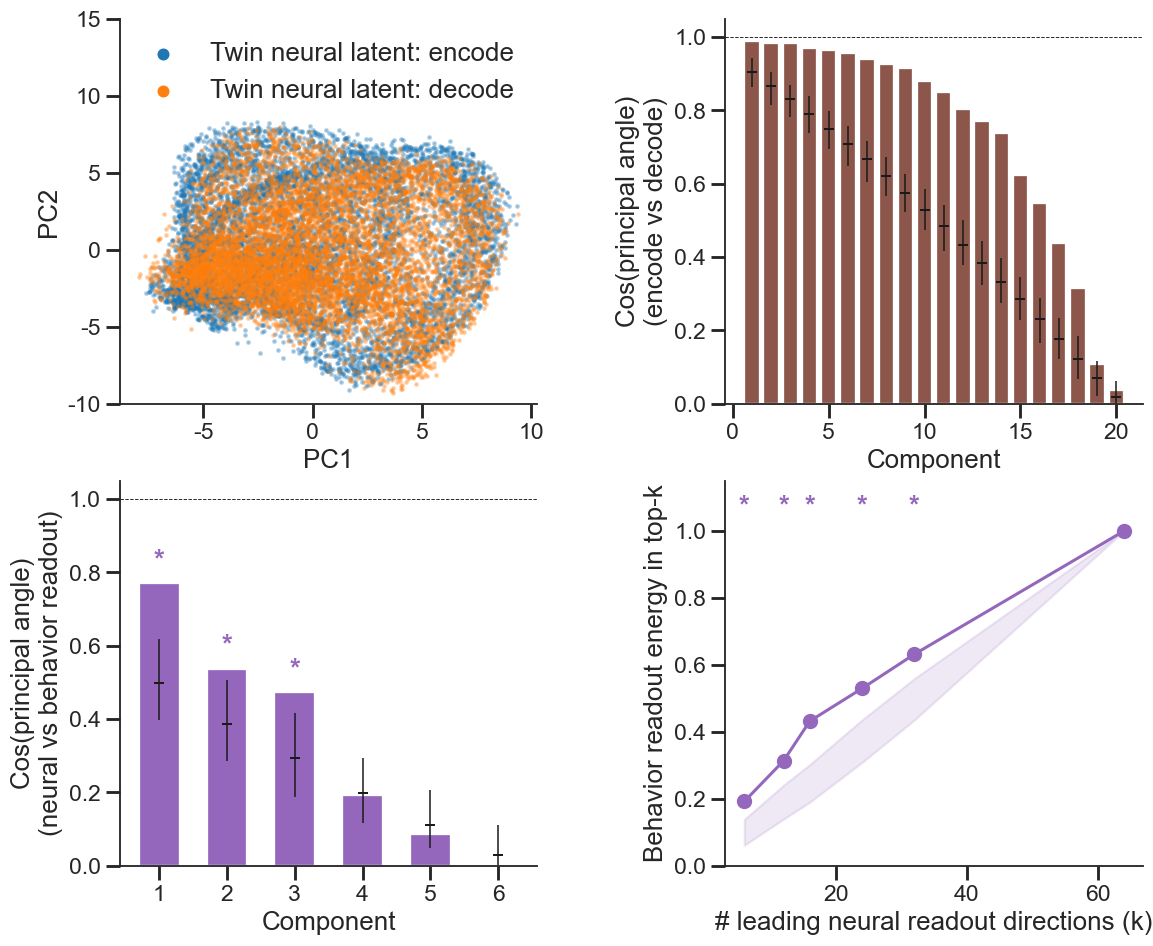

participation ratio: encode=20.4 decode=21.1 (d_sub=20); behavior readout rank d_ro=6
encode/decode mean cos²=0.628 (chance 0.312)
neural vs behavior readout mean cos²=0.192
components outside null (c): [1, 2, 3]; k outside null (d): [6, 12, 16, 24, 32]


In [295]:
# === ED Fig 5: Twin neural latent (encode vs decode) + readout subspace geometry ===
# Both latents are the neural-token half x[:, :T] (Fig 2 convention): encode = neural
# predicted from behavior, decode = neural extracted from observed spikes.
# a) PC1 vs PC2 of the pre-readout latent (encode vs decode, both x[:, :T]);
# b) cos(principal angle) between encode/decode activation subspaces vs component;
# c) cos(principal angle) between the dominant neural vs behavior readout
#    directions, with dimension-permutation null CIs;
# d) behavior readout energy captured by the top-k neural readout directions,
#    with null CIs. (Ports joint-encode-decode.ipynb §9.)
# (c) and (d) work on the readout weights as they are. An earlier version also showed
# covariance-whitened ("functional") variants; those were dropped -- the two readouts
# consume disjoint halves of x (joint.py forward: rate <- spike_readout(x[:, :T]),
# beh <- beh_readout(x[:, T:])), so there is no single activation covariance that is the
# right metric for both, and whitening each by its own made the bases incomparable.
from sklearn.decomposition import PCA


@torch.no_grad()
def _collect_enc_dec_latents(model, loaders, device):
    """Row-aligned pre-readout encode and decode neural latents over a split.
    encode: spikes masked, behavior seen -> xfull[:, :T]; decode: behavior masked,
    spikes seen -> ALSO xfull[:, :T] here (Fig-2 convention), not xfull[:, T:].
    Both are therefore the neural half h_n, the input the neural readout acts on."""
    model.eval(); Le, Ld = [], []
    for s, sd in loaders.items():
        for b in sd:
            m = b.mask.to(device); T = b.spike.shape[1]
            sp, bh = b.spike.to(device), b.behavior.to(device)
            nt = b.mask.clone().to(device)
            _, _, xe = model(s, sp, bh, m, nt, torch.zeros_like(nt))
            bt = b.mask.clone().to(device)
            _, _, xd = model(s, sp, bh, m, torch.zeros_like(bt), bt)
            mk = b.mask.numpy().astype(bool)
            Le.append(nh.masked_latent(xe, T, 'encode').cpu().numpy()[mk])  # neural tokens x[:, :T]
            Ld.append(xd[:, :T].cpu().numpy()[mk])  # decode in the SAME encode space x[:, :T] (Fig 2)
    return np.vstack(Le), np.vstack(Ld)


L_enc, L_dec = _collect_enc_dec_latents(joint_model, joint_loaders['test'], device)
_D = L_enc.shape[1]


def _pca_basis(L, d):
    _, _, Vt = np.linalg.svd(L - L.mean(0), full_matrices=False); return Vt[:d].T


def participation_ratio(L):
    s = np.linalg.svd(L - L.mean(0), compute_uv=False) ** 2
    return float(s.sum() ** 2 / (s ** 2).sum())


def principal_angles_cos(A, B):
    return np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0)


def _svd_basis(W, d):
    _, _, Vt = np.linalg.svd(W, full_matrices=False); return Vt[:d].T


def _energy_in(Q, V):
    return float(np.trace(Q.T @ V @ V.T @ Q) / Q.shape[1])


def _null_pa_cos(d1, d2, D, n=300, seed_=1):
    rng = np.random.default_rng(seed_); out = []
    for _ in range(n):
        A = np.linalg.qr(rng.standard_normal((D, d1)))[0]
        B = np.linalg.qr(rng.standard_normal((D, d2)))[0]
        out.append(np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0))
    return np.array(out)


# encode/decode activation subspaces, matched to the participation ratio
pr_enc, pr_dec = participation_ratio(L_enc), participation_ratio(L_dec)
d_sub = max(2, int(round(min(pr_enc, pr_dec))))
Venc, Vdec = _pca_basis(L_enc, d_sub), _pca_basis(L_dec, d_sub)
ang_ed = principal_angles_cos(Venc, Vdec)


def _readout_rows(mod):
    mods = mod.values() if isinstance(mod, nn.ModuleDict) else [mod]
    return np.vstack([m.weight.detach().cpu().numpy() for m in mods])


W_neu = _readout_rows(joint_model.spike_readout)     # (sum_K, D); package attr keeps its name
W_beh = _readout_rows(joint_model.beh_readout)       # (3*n_rooms, D)
d_ro = int(np.linalg.matrix_rank(W_beh))             # behavior readout rank (<= 3*n_rooms)
Q_beh, Q_neu = _svd_basis(W_beh, d_ro), _svd_basis(W_neu, d_ro)
ang_ro = principal_angles_cos(Q_neu, Q_beh)

ks = sorted({min(k, _D) for k in [d_ro, 2 * d_ro, 4 * d_ro, 16, 32, 64, _D]})
neu_top = {k: _svd_basis(W_neu, k) for k in ks}
curve = [_energy_in(Q_beh, neu_top[k]) for k in ks]

# empirical null: relabel the latent dimensions, i.e. permute the COLUMNS of W_beh with
# one permutation shared by every row. Because a column permutation is orthogonal, this
# leaves W_beh @ W_beh.T -- and hence every row norm, the cross-row structure and the whole
# singular-value spectrum -- exactly intact, and varies only which latent dimension each
# weight attaches to. The null therefore asks the narrow question the panels are about:
# is the CORRESPONDENCE between behavior- and neural-readout dimensions special, given the
# behavior readout's own geometry? (Much stricter than shuffling entries or drawing
# Gaussians, both of which also randomise that geometry.)
_rng4 = np.random.default_rng(seed); N_NULL = 300
null_pa, null_curve = [], []
for _ in range(N_NULL):
    Wb = W_beh[:, _rng4.permutation(W_beh.shape[1])]
    Q_beh_x = _svd_basis(Wb, d_ro)
    null_pa.append(principal_angles_cos(Q_neu, Q_beh_x))
    null_curve.append([_energy_in(Q_beh_x, neu_top[k]) for k in ks])
null_pa, null_curve = np.array(null_pa), np.array(null_curve)


# --- figure ---
def _sig_stars(ax, xs, obs, lo, hi, y, color):
    """'*' where obs falls outside the null [lo, hi]. `y` is either a scalar row
    height or a per-point sequence of heights (one per x)."""
    ys = np.broadcast_to(np.asarray(y, dtype=float), np.shape(xs))
    for _x, _o, _l, _h, _y in zip(xs, obs, lo, hi, ys):
        if _o > _h or _o < _l:
            ax.text(_x, _y, '*', color=color, ha='center', va='center', fontsize=18, fontweight='bold', clip_on=False)


Z = np.vstack([L_enc, L_dec]); task = np.array([0] * len(L_enc) + [1] * len(L_dec))
_sub = np.sort(_rng4.choice(len(Z), min(len(Z), 40000), replace=False))
Z2 = nh.fit_shared_latent_pca(L_enc, L_dec, n_components=3, random_state=seed).transform(Z)[_sub]
tsub = task[_sub]

fig_ed4, axes = plt.subplots(2, 2, figsize=(12, 10))
_lgnd_fs = axes[0, 0].xaxis.label.get_fontsize()  # match legend text to axis-label size
# a) PC1 vs PC2, encode vs decode
for tk, col, lab in [(0, 'tab:blue', 'Twin neural latent: encode'), (1, 'tab:orange', 'Twin neural latent: decode')]:
    mk = tsub == tk
    axes[0, 0].scatter(Z2[mk, 0], Z2[mk, 1], s=3, alpha=0.3, color=col, label=lab, rasterized=True)
axes[0, 0].set(xlabel='PC1', ylabel='PC2', ylim=(-10, 15))
_leg_a = axes[0, 0].legend(fontsize=_lgnd_fs, loc='upper right')
for _lh in _leg_a.legend_handles:
    _lh.set_alpha(1.0); _lh.set_sizes([40])
# b) encode vs decode subspace principal angles
null_ed = _null_pa_cos(d_sub, d_sub, _D, seed_=seed)
_lo, _med, _hi = np.percentile(null_ed, [2.5, 50, 97.5], axis=0); xr = np.arange(1, d_sub + 1)
axes[0, 1].bar(xr, ang_ed, color='tab:brown')
axes[0, 1].vlines(xr, _lo, _hi, color='k', lw=1)
axes[0, 1].plot(xr, _med, '_', color='k', ms=7, mew=1.3)
axes[0, 1].axhline(1, ls='--', color='k', lw=0.6)
axes[0, 1].set(xlabel='component', ylabel='cos(principal angle)\n(encode vs decode)', ylim=(0, 1.05))
# c) neural vs behavior readout angles, with null CIs; stars where outside the null
xp = np.arange(1, d_ro + 1)
_pa_lo, _pa_med, _pa_hi = np.percentile(null_pa, [2.5, 50, 97.5], axis=0)
axes[1, 0].bar(xp, ang_ro, width=0.6, color='tab:purple')
axes[1, 0].vlines(xp, _pa_lo, _pa_hi, color='k', lw=1)
axes[1, 0].plot(xp, _pa_med, '_', color='k', ms=7, mew=1.3)
axes[1, 0].axhline(1, ls='--', color='k', lw=0.6)
axes[1, 0].set(xlabel='component', ylabel='cos(principal angle)\n(neural vs behavior readout)',
               ylim=(0, 1.05), xticks=xp)  # same cosine scale as (b); tick every component
# star sits just above whichever is taller, the bar or the null whisker
_sig_stars(axes[1, 0], xp, ang_ro, _pa_lo, _pa_hi, np.maximum(ang_ro, _pa_hi) + 0.06, 'tab:purple')
# d) behavior readout energy in top-k neural readout dirs, with null CI
_cv_lo, _cv_hi = np.percentile(null_curve, [2.5, 97.5], axis=0)
axes[1, 1].plot(ks, curve, 'o-', color='tab:purple')
axes[1, 1].fill_between(ks, _cv_lo, _cv_hi, color='tab:purple', alpha=0.15)
axes[1, 1].set(xlabel='# leading neural readout directions (k)',
               ylabel='behavior readout energy in top-k', ylim=(0, 1.15))
_sig_stars(axes[1, 1], ks, curve, _cv_lo, _cv_hi, 1.07, 'tab:purple')
fig_ed4.subplots_adjust(wspace=0.45)  # more horizontal room between columns
ph.save_fig(fig_ed4, 'edfig5_subspaces'); plt.show()
print(f'participation ratio: encode={pr_enc:.1f} decode={pr_dec:.1f} (d_sub={d_sub}); '
      f'behavior readout rank d_ro={d_ro}')
print(f'encode/decode mean cos²={np.mean(ang_ed ** 2):.3f} (chance {d_sub / _D:.3f})')
print(f'neural vs behavior readout mean cos²={np.mean(ang_ro ** 2):.3f}')
print(f'components outside null (c): {[int(i) for i in xp[(ang_ro > _pa_hi) | (ang_ro < _pa_lo)]]}; '
      f'k outside null (d): {[k for k, o, l, h in zip(ks, curve, _cv_lo, _cv_hi) if o > h or o < l]}')

**Extended Data Figure 5 | Digital Twin aligns encode and decode latents and readouts.** (A) First two components of a single PCA fit to the row-concatenation of the encode and decode latents, so both share one basis. Latents are the pre-readout neural tokens on the encode and decode passes (n = 8,072 held-out timepoints per pass, pooled across 17 sessions). (B) Cosine of the top 20 principal angles between the encode and decode activation subspaces, 20 being the participation ratio of the latents (20.4 encode, 21.1 decode); bars = observed cosine, whiskers = 2.5–97.5\% and tick = median of a null of principal angles between two independent random 20-dimensional subspaces of the 64-dimensional latent (n = 300). Dashed line at 1 = perfect alignment. (C) Cosine of the principal angles between the dominant neural and behavior readout directions, taking as many directions as the behavior readout rank (6); bars, whiskers, tick and dashed line as in (B), but against a dimension-permutation null: n = 300 relabelings of the 64 latent dimensions, permuting the columns of the behavior readout weight matrix by one permutation shared across rows while the neural readout is held as observed. Stars mark components falling outside the 2.5–97.5\% interval of that null (two-sided permutation P < 0.05): components 1–3, P = 0.007, 0.033 and 0.007. (D) Fraction of the behavior readout subspace (its 6 leading right-singular directions) captured by the top-k neural readout directions, the latter taken over 3,080 neurons pooled across sessions; shaded band and stars as in (C), at k = 6, 12, 16, 24 and 32 (all P = 0.007). At k = 64 the fraction is 1 by construction. See also Figure \ref{fig:fig2}.

---
## Figure 3 — Same route, different paths: route-progress vs absolute-space sequences

Two flight clusters that share **origin and destination** but take geometrically
different 3-D paths between them (large Fréchet distance, small endpoint gaps).
The common coordinate is each path's own cumulative arc length ("route progress").
If place cells fire at the same *fraction* of the route on both detours, the
population sequence is preserved (schematic/topological coding); if they fire at
absolute 3-D positions, the alternate-path sequence is scrambled. Example index 0.

Data are loaded from raw spike times (native `Fs`) via `Data_Prep_for_Raw`, a
separate pipeline from the binned dataloaders (ported from
`investigate_similar_trajectories.ipynb`).

In [755]:
# === Figure 3 data: raw-spike cache + same-route different-path pairs ===
from scipy.interpolate import interp1d as _interp1d
from scipy.io import loadmat as _loadmat
from itertools import combinations as _combinations
import glob as _glob
from digitalbat.utility.utils import frechet_distance as _frechet_d
from digitalbat.datasets.data import Data_Prep_for_Raw as _DPR
from notebook_helpers import get_target_locs as _get_target_locs

AP_PARENT = data_config['parent_folder']
N_DS_AP, MIN_DUR_AP, MIN_CLU_AP, MAX_ACC_AP = 100, 1.0, 3, 50.0


def _ap_load_session(sn):
    """Raw behaviour + spike times (native Fs) for one session, via Data_Prep_for_Raw."""
    folder = AP_PARENT + sn
    su = AP_PARENT + 'To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    prep = _DPR(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
                use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
                use_ripple_flag=False, only_flight_flag=True, spike_count_flag=True,
                bin_width=0.10, max_acceleration=MAX_ACC_AP)
    prep.get_all_behavior(); prep.get_all_spike(); prep.get_flight_cluster()
    fc = prep.flight_cluster_results
    bhv = _loadmat(_glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    t_bhv = bhv['t'][:, 0] if 'Dataset_2' in sn else bhv['t'][0, :]
    Fs = float(bhv['Fs'][0, 0])
    # raw spike times + merge (mirrors Data_Prep_for_Raw.get_all_spike)
    su_paths = sorted(_glob.glob(su))
    times, cids, ptypes = [], [], []
    for p in su_paths:
        gu = _loadmat(p)['out_Gunits']
        cids.append(np.array([x[0][0, 0] for x in gu['cluster_id']]))
        times.append([x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        ptypes.append(list(np.array([np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
                       else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))
    mg = _loadmat(_glob.glob(folder + '/merges_Dataset_*.mat')[0])['merges']
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(mg[ii][0]):
            to_merge = mg[ii][0][0][0][0]
            cl, tl = cids[ii], times[ii]
            midx = [np.where(cl == cid)[0][0] for cid in to_merge]
            merged = np.sort(np.concatenate([tl[k] for k in midx]))
            clean = [merged[0]]
            for s_ in merged[1:]:
                if s_ - clean[-1] > refractory:
                    clean.append(s_)
            tl[midx[0]] = np.array(clean)
            for k in midx[1:]:
                tl[k] = np.array([])
            valid = [i for i, st in enumerate(tl) if len(st) > 0]
            times[ii] = [tl[i] for i in valid]; cids[ii] = cl[valid]
            ptypes[ii] = [ptypes[ii][i] for i in valid]
    spike_times = [st for probe in times for st in probe]
    pType = np.array([pt for probe in ptypes for pt in probe], dtype=object)
    return dict(r=bhv['r'], t=t_bhv, Fs=Fs, v=bhv['v'], spike_times=spike_times,
                pType=pType, fc_results=fc)


def _ds_traj(r, fs, fe, n=N_DS_AP):
    fs, fe = int(fs), int(fe); traj = r[fs:fe + 1]
    to = np.linspace(0, 1, traj.shape[0]); td = np.linspace(0, 1, n)
    return np.column_stack([_interp1d(to, traj[:, d])(td) for d in range(3)])


session_data_cache = {}
for sn in session_names:
    try:
        d = _ap_load_session(sn)
    except Exception as exc:
        print(f'  [Fig3 skip {sn}] {type(exc).__name__}: {exc}'); continue
    fc, Fs = d['fc_results'], d['Fs']
    recs = []
    for i in range(fc['N']):
        dur = (fc['stop_frame'][i] - fc['start_frame'][i]) / Fs
        if dur < MIN_DUR_AP:
            continue
        pos = d['r'][fc['start_frame'][i]:fc['stop_frame'][i] + 1]
        acc = np.gradient(np.gradient(pos, 1.0 / Fs, axis=0), 1.0 / Fs, axis=0)
        if np.linalg.norm(acc, axis=1).max() > MAX_ACC_AP:
            continue
        recs.append(dict(cluster_id=int(fc['id'][i]), f_start=int(fc['start_frame'][i]),
                         f_stop=int(fc['stop_frame'][i]), duration=dur))
    dff = pd.DataFrame(recs)
    ci = {}
    for cid, grp in dff.groupby('cluster_id'):
        if len(grp) < MIN_CLU_AP:
            continue
        trajs = np.stack([_ds_traj(d['r'], row.f_start, row.f_stop) for _, row in grp.iterrows()])
        ci[int(cid)] = dict(n_flights=len(grp), mean_traj=np.nanmean(trajs, 0))
    session_data_cache[sn] = dict(data=d, df_flights=dff, cluster_info=ci)
    print(f'  {sn}: {len(dff)} flights, {len(ci)} clusters')

# --- same-route, different-path candidate pairs (shared endpoints, high Fréchet) ---
AP_ENDPOINT_THRESH, AP_MIN_FRECHET, AP_MIN_FLIGHTS, AP_LABEL_THRESH = 0.25, 1.0, 5, 1.0  # shared endpoints within 0.25 m (drops the loose reward->perch pair)


def _endpoint_label(sess, xyz):
    rew, perch = _get_target_locs(sess)
    dr = float(np.min(np.linalg.norm(rew - xyz, axis=1)))
    dp = float(np.min(np.linalg.norm(perch - xyz, axis=1)))
    if min(dr, dp) > AP_LABEL_THRESH:
        return 'other'
    return 'reward' if dr <= dp else 'perch'


_apc = []
for sess, cached in session_data_cache.items():
    big = {c: i for c, i in cached['cluster_info'].items() if i['n_flights'] >= AP_MIN_FLIGHTS}
    for a, b in _combinations(big, 2):
        ta, tb = big[a]['mean_traj'], big[b]['mean_traj']
        sg, eg = float(np.linalg.norm(ta[0] - tb[0])), float(np.linalg.norm(ta[-1] - tb[-1]))
        if max(sg, eg) > AP_ENDPOINT_THRESH:
            continue
        fr = float(_frechet_d(ta, tb))
        if fr < AP_MIN_FRECHET:
            continue
        _apc.append(dict(session=sess, bat=parse_bat(sess), cluster_a=a, cluster_b=b,
                         n_flights_a=big[a]['n_flights'], n_flights_b=big[b]['n_flights'],
                         start_gap=sg, end_gap=eg, frechet=fr,
                         score=min(big[a]['n_flights'], big[b]['n_flights']) * fr))
df_altpath = pd.DataFrame(_apc)
if len(df_altpath):
    df_altpath['route_type'] = [
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][0]) + '→' +
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][-1])
        for s, a in zip(df_altpath.session, df_altpath.cluster_a)]
    df_altpath = df_altpath.sort_values('score', ascending=False).reset_index(drop=True)
print(f'\n{len(df_altpath)} same-route different-path pairs')
df_altpath.head(8)


  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_14543_240420: 130 flights, 4 clusters
  Dataset_3_14543_240421: 113 flights, 5 clusters
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240402: 137 flights, 6 clusters
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240403: 124 flights, 5 clusters
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240404: 77 flights, 3 clusters
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231208: 76 flights, 4 clusters
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231209: 75 flights, 4 clusters
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Dataset_1_32622_231009: 78 flights, 7 clusters
  Dataset_1_32622_231010: 94 flights, 5 clusters
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)


,session,bat,cluster_a,cluster_b,n_flights_a,n_flights_b,start_gap,end_gap,frechet,score,route_type
0,Dataset_1_32622_231010,32622,10,11,43,13,0.126042,0.103677,1.974863,25.673225,reward→reward
1,Dataset_1_32622_231009,32622,15,16,10,19,0.025309,0.042311,1.740129,17.401289,reward→reward
2,Dataset_2_14445_231209,14445,2,3,6,28,0.210797,0.056653,2.357523,14.145136,reward→perch
3,Dataset_2_14445_231209,14445,1,3,5,28,0.208222,0.175107,2.334816,11.674081,reward→perch


In [770]:
# === Figure 3 (extra): rate-map stability across paths — physical vs latent space ===
# For every neuron, how similar is its rate map between the different GEOMETRIC PATHS
# (flight clusters) that make up the same route? Fig 3 shows single units that keep their
# latent tuning while their physical tuning moves; this quantifies that over every neuron
# in every environment, using digitalbat.utility.utils.BatRateMapSim:
#   * Wasserstein index, 1 - EMD / EMD_max (ot.emd2 on the 3-D bin grid) -- HIGHER = more stable
#   * Jaccard IoU of place fields thresholded at 20% of peak             -- HIGHER = more stable
# ot.emd2 returns a transport cost in grid-bin units (here 0.19 - 8.97), so it is turned into
# an index by dividing by the largest cost the grid admits -- its diagonal, sqrt(3) * (bins-2)
# = 13.86 -- and subtracting from 1. Both indices then run 0 (no overlap) to 1 (identical) and
# read the same way. The map is monotone and linear, so every rank-based test below is
# identical to the one on the raw distance; only the sign and the scale change.
# Each is computed twice per neuron from the SAME spikes: once with rate maps binned in
# physical XYZ, once binned in the 3-D PCA of the Twin encode latent (the Fig 2b space). The
# PCA is fit per ENVIRONMENT, so the indoor room and the outdoor flight room each get a basis
# spanned by their own points instead of one room's basis imposed on the other. Routes are
# the origin->destination classes of Fig 2b, and only paths within one route are compared --
# but a route is an endpoint CLASS, not a feeder pair, so two paths of one route need not
# share their exact endpoints (see the caveat printed by the example cell below).
#
# Both indices also get a per-neuron NULL: spikes are circularly shifted WITHIN EACH FLIGHT
# (RM_N_SHUFFLES draws, offset drawn independently per flight and neuron) and the whole index
# is recomputed. Occupancy -- and with it the rate-map denominator, the path geometry and each
# flight's spike count -- is left exactly intact; only the alignment between spikes and where
# the bat actually was is destroyed. A neuron's null is the mean index over draws.
# BatRateMapSim.get_shuffled_{jaccard,wass}_baseline implement the same idea, but shift the
# whole concatenated flight-cluster segment rather than each flight, and rebuild one rate map
# per neuron per draw; at 100 draws that runs for days.
#
# BatRateMapSim still DEFINES the analysis -- it labels the routes, picks the geometric paths
# and sets the per-session bounds -- but both the observed indices and the null are computed
# by the vectorised path below (`_rm_maps_all`, all neurons in one Gaussian-filter pass) and
# spread over RM_N_JOBS processes: the null parallelises over draws, the observed pass over
# path pairs. `_rm_assert_matches_package` runs the package on the cheapest session and
# requires every index to agree exactly, so the speed-up is checked, not assumed. Doing the
# observed pass through the package instead would leave it single-threaded: 8 min at 10 bins
# but ~7 h at 20, which would dominate the whole cell.
#
# The two metrics use DIFFERENT bin counts, because only one of them is expensive. Building
# the rate maps costs ~0.1 s per route/space either way (and barely moves with bin count), and
# the Jaccard set operations are ~9 us per neuron pair, so Jaccard runs at the function default
# of 20 bins for free. EMD is a network-simplex solve over (bins-1)^3 cells and MEASURED here
# at 15 ms/pair over 729 cells vs 770 ms over 6859 (~n^1.7), so 10 bins costs ~0.9 h and 20
# bins ~30 h; restricting the transport to the nonzero support does not help, since smoothing
# leaves 41% of the 19^3 grid occupied. Wasserstein therefore stays at 10 bins. Each metric
# only ever compares physical against latent (or against its own shuffle) within itself, so
# the two need not share a binning; only their absolute values stop being comparable to each
# other. Cached under ./out/fig3_ratemap_sim.pkl.
#
# The Gaussian smoothing is generate_rate_map's `smooth_sigma=1.0` -- in BINS, not metres, and
# BatRateMapSim never overrides it. So the physical width of the kernel is set by the binning:
# at 10 bins a session spanning ~5.3 x 4.0 x 1.5 m gives ~0.59 x 0.44 x 0.17 m per bin (and
# scipy truncates at 4 sigma, i.e. 4 bins), at 20 bins roughly half that. Raising the bin
# count therefore also SHARPENS the maps rather than just refining them.
import pickle
import time
import warnings
from matplotlib.patches import Patch as _Patch
from scipy import stats
from joblib import Parallel, delayed
from scipy.ndimage import gaussian_filter
from digitalbat.utility.utils import BatRateMapSim
from sklearn.decomposition import PCA as _PCA3

# --- WHERE THE PLOTTED INDICES COME FROM ----------------------------------------------
# 'physical_vs_latent': the cached run from joint-figures-single-unit.ipynb, read-only. That
#     run uses 20 bin edges (19^3) for BOTH metrics, NO occupancy mask, a PCA-3 fit on all
#     sessions pooled, its own landmark table, and the package's per-flight-CLUSTER shuffle
#     with 20 draws. This is what the figures below plot.
# 'compute': recompute here with the constants in this cell (9^3 EMD, occupancy mask,
#     per-FLIGHT shuffle x 100, per-environment PCA). Kept so the two can be compared.
# The two agree on Wasserstein once the bin count is matched (66.8% vs 70.1% of neurons
# favouring latent at 19^3) and disagree on Jaccard, where the occupancy mask reverses the
# sign. tmp/cmp_isolate.py prints the side-by-side; tmp/cmp_jaccard_why.py decomposes it.
RM_SOURCE = 'compute'
RM_PVL_DIR = './out/physical_vs_latent'
RM_PVL_BINS = 20        # their bin edges, needed for the Wasserstein index normalisation

# --- the bin grid: ANISOTROPIC and per ENVIRONMENT, shared by both metrics -------------
# CELLS per axis (not bin edges). The old grid was `bins` per axis regardless of extent, so
# an indoor voxel was 0.60 x 0.48 x 0.15 m -- 3.9x squatter in z than wide. That matters
# because ot.dist builds its cost matrix from bin INDICES: a vertical displacement of the
# same physical length as a horizontal one was charged 3.9x more, inflating the PHYSICAL EMD
# in a room far wider than it is tall and so biasing the comparison toward the latent, which
# is the direction of the result. Cubic voxels make the bin count proportional to the extent:
# indoor 5.41 x 4.33 x 1.37 m -> 3.87 : 3.05 : 1.00, outdoor 9.02 x 3.69 x 2.24 -> 4.03 :
# 1.65 : 1.00 (per session sqrt(x*y)/z runs 2.2-4.2; the latent is already 1.06).
#   indoor  (15, 12, 4) = 720 cells at a 0.360 m voxel
#   outdoor (19,  8, 5) = 760 cells at a 0.470 m voxel
# The two environments are matched on CELL COUNT rather than voxel size, so their grid
# diagonals (18.06 vs 19.72) -- the Wasserstein normaliser -- stay within 9% and the indices
# remain poolable. Matching voxel size instead would give outdoor 25 x 10 x 6 = 1500 cells at
# ~2.8x the EMD cost.
#
# THE SAME GRID IS USED FOR THE LATENT (PC1-3). That is a deliberate choice: physical and
# latent then share a cost matrix and a normaliser, so grid shape cannot differ between the
# two spaces being compared. It is not free, though -- the latent's own extent is nearly
# isotropic (1.02 : 1.00 : 1.01 indoor), so 15,12,4 makes PC1 the finest axis and PC3 the
# coarsest, and since PC1 carries the most spread the differences that matter most are the
# ones charged most. That handicaps the LATENT, i.e. it is conservative with respect to the
# result. Per-space cubic voxels (latent ~9,9,9) would be the neutral alternative.
RM_GRID = {'indoor': (15, 12, 4), 'outdoor': (19, 8, 5)}
# SEPARATE grid for the latent, in the latent's OWN units, matched to the same cell counts.
# This is the configuration the figures run ("config C"). Set to None to share RM_GRID between
# the two spaces instead ("config B") -- see the measurements below for why that is wrong.
#
# WHY THIS SWITCH EXISTS. Imposing RM_GRID on the latent does NOT just re-weight the EMD
# cost, it changes the latent's RESOLUTION: PC3 drops from 9 cells to 4, and coarser bins
# make any two rate maps look more alike. Measured per segment on the same 5788 rows, moving
# from the old isotropic 9^3 to RM_GRID left the PHYSICAL index almost untouched
# (0.7170 -> 0.7187) and lifted the LATENT one sharply (0.7540 -> 0.7976), so the Wasserstein
# effect doubled (+0.0356 -> +0.0727) entirely from the latent side. That is a binning
# artifact in favour of the result, not evidence for it. Jaccard is unaffected either way
# (+0.0114 -> +0.0105), because an IoU of thresholded sets does not care about cost geometry.
# Set RM_GRID_LATENT to the cubic-voxel grids above to fix the physical anisotropy -- the
# thing this change set out to fix -- without touching the latent's resolution.
RM_GRID_LATENT = {'indoor': (9, 9, 9), 'outdoor': (10, 9, 8)}
WASS_BINS = 10          # legacy isotropic edge counts, used only by the package cross-check
JACCARD_BINS = 20
RM_N_SHUFFLES = 100     # per-flight circular-shift draws behind every neuron's null
RM_N_JOBS = 20          # processes for the shuffle (leaves a few cores free)
RM_VERBOSE = 5          # joblib chatter WITHIN a session (0 = silent); ~every 10% of draws
# Milliseconds per neuron-pair ot.emd2 call, MEASURED on this machine on real rate maps
# (tmp/bench_wass20.py). The cost is super-linear in the cell count (bins-1)^3: 729 cells
# -> 15 ms, 6859 -> 770 ms, i.e. ~n^1.7, which is why WASS_BINS is 10 and not 20. Used only
# to print an up-front runtime estimate; unmeasured bin counts fall back to that exponent.
RM_EMD_MS = {10: 15.0, 20: 770.0}
# MEASURED per neuron on real maps (tmp/bench_aniso.py), route-level (denser) / segment-level:
# (9,9,9) 1.7 / 0.7 ms, (15,12,4) 1.7 / 0.7, (19,8,5) 1.8 / 0.7, (19,19,19) 276 / 185. The
# anisotropic grids cost the same as the 729-cell isotropic one, so this change is free.
RM_EMD_MS_CELLS = {400: 0.9, 720: 1.7, 760: 1.8, 729: 1.7}
# Occupancy mask. generate_rate_map smooths the spike map and the occupancy map separately
# and divides, so the ratio does NOT decay away from the trajectory: without a mask ~98% of a
# 20%-of-peak field sits on voxels the bat never entered, and the peak voxel itself usually
# does. The map stays smooth-then-divide; afterwards a voxel is KEPT only where its smoothed
# occupancy is at least RM_OCC_FRAC of the mass one sample deposits (a sample contributes dt in
# total, spread over the kernel). The mask is read off the OCCUPANCY map alone -- no threshold
# on the rate map, and the neuron never enters it, so the same mask applies to every unit and
# to the shuffles. Upper bound: the 3-D kernel's central weight is 0.0635 (sigma = 1 bin,
# truncate = 4), so a frac above that would discard even a voxel the bat sat in; 0.05 keeps
# 100% of visited voxels while cutting the field's reach from >6 bins to ~1.9.
RM_OCC_FRAC = 0.05
RM_ROUTES = [('Reward', 'Reward'), ('Reward', 'Perch'), ('Perch', 'Reward')]
RM_ROUTE_ID = {('Reward', 'Reward'): 1, ('Reward', 'Perch'): 2, ('Perch', 'Reward'): 3}
# Routes an environment is allowed to contribute (absent -> all of RM_ROUTES). Dataset 2
# (outdoor) has a SINGLE reward feeder with a perch 1.16 m away, so the bat hopping between
# the two is endpoint-labelled perch->reward: in Dataset_2_14445_231208 that class pairs one
# genuine 8 m cross-arena flight against four 1.1-1.3 m hops. Only reward->reward and
# reward->perch are real route classes outdoors, and both are long loops (17-21 m of path).
# Minimum flight PATH LENGTH, as a fraction of the session's own bounding-box diagonal.
# This replaces the old route-based workaround (RM_ROUTES_BY_ENV, which dropped outdoor
# perch->rew wholesale) with a per-flight criterion aimed at the actual defect: Dataset_2's
# perch sits 1.16 m from its only feeder, so a handful of outdoor "flights" are hops between
# the two rather than traversals of the arena.
#
# WHY THIS MEASURE AND NOT THE OBVIOUS ONES (tmp/probe_flight_length.py):
#   * an absolute 1.5 m cut drops NOTHING -- the shortest path in the dataset is 2.16 m. The
#     1.1-1.3 m figure that motivated the route filter is endpoint DISPLACEMENT, not path.
#   * endpoint displacement cannot be used: a rew->rew loop starts and ends in the same place
#     (median 0.11 m indoor), so it would discard exactly the flights the analysis wants, and
#     outdoor rew->perch has a median displacement of 1.61 m over an 18.8 m path.
#   * absolute path length cannot be used either: the outdoor hops (2.16-3.45 m) sit below a
#     clean gap to 9.12 m, but indoor flights START at 2.96 m and run a 5.8 m median, so any
#     cut that clears the hops removes half the indoor data.
#   * duration collides the same way -- the hops are 1.8-2.8 s, indoor medians are 2.1-2.2 s.
# Normalising by the box diagonal (7.09 m indoor, 9.91 m outdoor) separates them exactly: the
# 8 hops span 0.212-0.348 and EVERY other flight spans 0.415-2.162, so any cut in
# (0.348, 0.415) drops precisely those 8 and nothing else. 0.38 is the midpoint; 0.35 and 0.40
# give the identical flight set.
RM_MIN_PATH_FRAC = 0.38
RM_ROUTES_BY_ENV = {}      # superseded by RM_MIN_PATH_FRAC; {} keeps all routes in both envs
RM_LABELS = [ph.ROUTE_LABELS[RM_ROUTE_ID[r]] for r in RM_ROUTES]
RM_SPACES = ['physical', 'latent']
FS_R = dict(title=15, label=14, tick=12, star=15)
_RM_TAG = ('anisoP' if RM_GRID_LATENT is not None else 'aniso') + '_len'  # C vs B, + length cut
RM_CACHE = f'./out/fig3_ratemap_sim_{_RM_TAG}.pkl'

# `emb` is the shared-latent dict built by the extract_latents cell. Fail with a readable
# message rather than an IndexError deep in a comprehension if something has rebound it.
assert isinstance(emb, dict) and 'session' in emb, (
    "`emb` is not the shared-latent dict any more (a later cell rebound it) — "
    "re-run the extract_latents cell:  emb = extract_latents('test')")

# --- shared inputs: a PCA-3 of the encode latent per environment (the Fig 2b space) ---
_rm_env_pt = np.array(['indoor' if ph.is_indoor(s) else 'outdoor' for s in emb['session']])
_rm_lat3 = np.zeros((len(emb['session']), 3))
for _e in np.unique(_rm_env_pt):
    _m = _rm_env_pt == _e
    _rm_lat3[_m] = _PCA3(n_components=3, random_state=seed).fit_transform(emb['latent'][_m])
# BatRateMapSim reads the reward/perch flags at each flight's first and last sample to label
# routes, which is exactly emb's per-flight origin/dest endpoint class (as in the Fig 2 DMD cell).
_rm_bd = np.append(np.where(emb['rel_t'] == 0.0)[0], len(emb['rel_t']))
_rm_rew = np.zeros(len(emb['rel_t']), bool)
_rm_prc = np.zeros(len(emb['rel_t']), bool)
for _s, _e in zip(_rm_bd[:-1], _rm_bd[1:]):
    _rm_rew[_s], _rm_prc[_s] = emb['origin'][_s] == 1, emb['origin'][_s] == 2
    _rm_rew[_e - 1], _rm_prc[_e - 1] = emb['dest'][_s] == 1, emb['dest'][_s] == 2
_rm_key = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))


def _rm_session_spikes(sn, mask):
    """Per-session spike matrix in emb row order (emb keeps only the ragged per-flight dict)."""
    out, seen = [], None
    for k in _rm_key[mask]:
        if k != seen:
            seen = k
            out.append(emb['spike_by_flight'][(sn, int(k.split('|')[1]))])
    return np.vstack(out)


def _rm_build_sim(sn):
    """BatRateMapSim for one session, plus the per-flight ids aligned to its rows."""
    m = emb['session'] == sn
    sim = BatRateMapSim(sn, emb['session'][m], emb['xyz'][m], _rm_lat3[m], emb['latent'][m],
                        _rm_session_spikes(sn, m), emb['cluster'][m], emb['rel_t'][m],
                        _rm_rew[m], _rm_prc[m], dt=bin_width)
    # per-SAMPLE flag: is this sample part of a long-enough flight (see RM_MIN_PATH_FRAC)?
    _fid = emb['flight_id'][m]
    _lim = np.asarray(sim.loc_xyz_lim)
    _diag = float(np.linalg.norm(_lim[1] - _lim[0]))
    sim.long_flight = np.ones(sim.n_time, bool)
    for _f in np.unique(_fid):
        _w = np.flatnonzero(_fid == _f)
        _len = float(np.sum(np.linalg.norm(np.diff(sim.xyz[_w], axis=0), axis=1)))
        if _diag > 0 and _len / _diag < RM_MIN_PATH_FRAC:
            sim.long_flight[_w] = False
    return sim, _fid


# ---------------------------------------------------------------- shuffle machinery ----
def _rm_as_shape(nb):
    """Accept either an isotropic bin-EDGE count (legacy: nb-1 cells per axis) or an
    explicit tuple of CELL counts, and return the cell counts.

    A 2-tuple is a 2-D grid: only the first two coordinate columns are binned, so every
    sample at a given (x, y) lands in one cell whatever its height. Occupancy and spikes are
    therefore MARGINALISED over z (or PC3), which is exactly what collapsing the vertical
    axis means -- there is no separate projection step."""
    return tuple(int(v) for v in nb) if np.ndim(nb) else ((int(nb) - 1,) * 3)


def _rm_grid_for(env, space):
    """The grid used for one (environment, space) pair."""
    if space == 'latent' and RM_GRID_LATENT is not None:
        return RM_GRID_LATENT[env]
    return RM_GRID[env]


def _rm_shape_of(session, space='physical'):
    """The bin grid this (session, space) uses -- the same for both metrics."""
    return _rm_grid_for('indoor' if ph.is_indoor(session) else 'outdoor', space)


def _rm_shapes_of(session):
    """{space: grid} for one session."""
    return {_sp: _rm_shape_of(session, _sp) for _sp in RM_SPACES}


def _rm_wass_norm(df):
    """Raw ot.emd2 cost -> index, dividing each wass_* column by ITS OWN grid diagonal.

    The diagonal is the longest transport the grid admits, so 1 - EMD/diag runs 0-1 with
    HIGHER = more stable. It differs by environment (18.06 indoor vs 19.72 outdoor) and, when
    RM_GRID_LATENT is set, by space as well -- hence a per-column, per-row normaliser rather
    than the single RM_WASS_MAX constant this used to be.
    """
    for _c in [_c for _c in df.columns if _c.startswith('wass')]:
        _sp = 'latent' if 'latent' in _c else 'physical'
        df[_c] = 1.0 - df[_c] / df['env'].map(
            {_e: _rm_diag(_rm_grid_for(_e, _sp)) for _e in RM_GRID})
    return df


def _rm_diag(nb):
    """Longest transport the grid admits, in bin-index units = the Wasserstein normaliser.
    Reduces to sqrt(3)*(bins-2) on an isotropic grid."""
    return float(np.sqrt(sum((_s - 1) ** 2 for _s in _rm_as_shape(nb))))


def _rm_bin_index(coords, lims, nb):
    """Flat index of each sample in the grid spanned by `lims`, matching np.histogramdd's
    binning (last bin closed on the right)."""
    sh = _rm_as_shape(nb)
    ii = [np.clip(np.searchsorted(np.linspace(lims[0, d], lims[1, d], sh[d] + 1),
                                  coords[:, d], side='right') - 1, 0, sh[d] - 1)
          for d in range(len(sh))]
    return np.ravel_multi_index(ii, sh)   # == (i0*sh1 + i1)*sh2 + i2 in 3-D


def _rm_maps_all(flat, spikes, nb, dt, sigma=1.0, occ_frac=None):
    """(nb-1, nb-1, nb-1, K) smoothed rate maps for all K neurons in one pass.

    The map itself is generate_rate_map(...)[2] looped over neurons (asserted below), just
    ~10x faster and with O(1) rather than O(K) Gaussian filters. It is then zeroed outside
    the occupancy mask (see RM_OCC_FRAC); pass occ_frac=0.0 for the bare package map.
    Neurons silent in this segment get an all-NaN map, as in
    BatRateMapSim._get_valid_cluster_maps.
    """
    sh = _rm_as_shape(nb)
    ncell = int(np.prod(sh))
    occ = np.bincount(flat, minlength=ncell).astype(float) * dt
    sp = np.zeros((ncell, spikes.shape[1]))
    np.add.at(sp, flat, spikes)
    occ_s = gaussian_filter(occ.reshape(sh), sigma=sigma)
    sp_s = gaussian_filter(sp.reshape(*sh, -1), sigma=(sigma,) * len(sh) + (0,))
    with np.errstate(divide='ignore', invalid='ignore'):
        rm = np.divide(sp_s, occ_s[..., None])
    rm[~np.isfinite(rm)] = 0.0
    _f = RM_OCC_FRAC if occ_frac is None else occ_frac
    if _f > 0:
        rm[occ_s < _f * dt] = 0.0        # mask from the occupancy map, not from the rate map
    rm[..., spikes.sum(0) == 0] = np.nan
    return rm


def _rm_jaccard_pair(m1, m2):
    """Per-neuron IoU of the two place fields thresholded at 20% of peak."""
    out = np.full(m1.shape[-1], np.nan)
    for n in range(m1.shape[-1]):
        a, b = m1[..., n], m2[..., n]
        if np.isnan(a).any() or np.isnan(b).any():
            continue
        f1 = a > 0.2 * a.max() if a.max() > 0 else np.zeros(a.shape, bool)
        f2 = b > 0.2 * b.max() if b.max() > 0 else np.zeros(b.shape, bool)
        u = np.count_nonzero(f1 | f2)
        if u:
            out[n] = np.count_nonzero(f1 & f2) / u
    return out


def _rm_wass_pair(m1, m2, M_cost):
    """Per-neuron exact EMD between two 3-D rate maps on the bin grid."""
    import ot  # optional dep (POT), as in BatRateMapSim
    K = m1.shape[-1]
    v1, v2, out = m1.reshape(-1, K), m2.reshape(-1, K), np.full(K, np.nan)
    for n in range(K):
        a, b = v1[:, n], v2[:, n]
        if np.isnan(a).any() or np.isnan(b).any() or a.sum() == 0 or b.sum() == 0:
            continue
        out[n] = ot.emd2(a / a.sum(), b / b.sum(), M_cost)
    return out


def _rm_cost_matrix(nb):
    import ot
    sh = _rm_as_shape(nb)
    g = np.array(np.meshgrid(*[np.arange(_s) for _s in sh],
                             indexing='ij')).reshape(len(sh), -1).T
    return ot.dist(g, g, metric='euclidean')


def _rm_shift_spikes(spikes, flight_id, rng):
    """Circularly shift every neuron's spike train WITHIN EACH FLIGHT.

    Behaviour is untouched, so occupancy (the rate-map denominator) and each flight's
    spike count survive exactly; only the spike-to-place alignment is destroyed.
    Offsets are drawn per (flight, neuron) in [0.2 L, 0.8 L) so no flight stays
    near-unshifted.
    """
    out, K = np.empty_like(spikes), spikes.shape[1]
    for f in np.unique(flight_id):
        m = flight_id == f
        seg = spikes[m]
        L = seg.shape[0]
        offs = rng.integers(max(int(L * 0.2), 1), max(int(L * 0.8), 2), size=K)
        out[m] = seg[(np.arange(L)[:, None] - offs[None, :]) % L, np.arange(K)[None, :]]
    return out


def _rm_segments(sim, shapes, shapes_j=None):
    """Per (route, space), the sample masks + flat bin indices of every geometric path
    with enough samples -- exactly the segments the observed indices are built from.

    Both metrics now share one grid, so `flat_w` and `flat_j` are the same array and
    _rm_pair_indices builds each rate map once instead of twice. `shape_j` overrides the
    Jaccard grid, which only the BatRateMapSim cross-check needs (the package bins the two
    metrics at different resolutions). Both are {space: grid} dicts."""
    shapes_j = shapes if shapes_j is None else shapes_j
    segs = {}
    for ft in RM_ROUTES:
        ft_mask = (sim.flight_types == str(ft)) & sim.long_flight    # RM_MIN_PATH_FRAC
        if not ft_mask.any():
            continue
        masks = [m for m in (ft_mask & (sim.clusters == c) for c in np.unique(sim.clusters[ft_mask]))
                 if m.sum() >= 10]
        per_space = {}
        for space, coords, lims in (('physical', sim.xyz, sim.loc_xyz_lim),
                                    ('latent', sim.pca_3d, sim.loc_pca_lim)):
            if len(masks) > 1:
                per_space[space] = [dict(mask=m,
                                         flat_w=_rm_bin_index(coords[m], lims, shapes[space]),
                                         flat_j=_rm_bin_index(coords[m], lims, shapes_j[space]))
                                    for m in masks]
        if per_space:
            segs[ft] = per_space
    return segs


def _rm_pair_indices(sa, sb, nb_w, nb_j, dt, M_cost, occ_frac=None):
    """Both indices for ONE pair of geometric paths, over all neurons.

    `sa`/`sb` are pre-sliced {flat_w, flat_j, spikes} for the two paths. This is the unit
    of parallelism for the observed pass (the null parallelises over draws instead), so it
    takes only small arrays -- `M_cost` is the one big argument and joblib memmaps it, so
    every worker shares a single copy.
    """
    aw = _rm_maps_all(sa['flat_w'], sa['spikes'], nb_w, dt, occ_frac=occ_frac)
    bw = _rm_maps_all(sb['flat_w'], sb['spikes'], nb_w, dt, occ_frac=occ_frac)
    if nb_j == nb_w:                    # same grid -> same array, don't build it twice
        aj, bj = aw, bw
    else:
        aj = _rm_maps_all(sa['flat_j'], sa['spikes'], nb_j, dt, occ_frac=occ_frac)
        bj = _rm_maps_all(sb['flat_j'], sb['spikes'], nb_j, dt, occ_frac=occ_frac)
    return _rm_wass_pair(aw, bw, M_cost), _rm_jaccard_pair(aj, bj)


def _rm_slice(c, spikes):
    """A path's bin indices plus its slice of the spike matrix (picklable, small)."""
    return dict(flat_w=c['flat_w'], flat_j=c['flat_j'], spikes=spikes[c['mask']])


def _rm_mean_pairs(pairs, nanmean=True):
    """Mean over path pairs.

    With `nanmean` (the analysis default) a neuron that is silent on SOME paths still gets a
    value, averaged over the pairs where it is active on both; only a neuron active on fewer
    than two paths has no pair at all and stays NaN. BatRateMapSim._compute_pairwise_similarity
    uses a plain mean, which propagates the NaN and drops such a neuron from the route
    entirely -- pass nanmean=False to reproduce it exactly.

    The trade-off is that neurons then rest on different numbers of pairs (15 for a unit
    active on all six paths of a route, 1 for a unit active on two), so the sparser units
    carry more noise. They are still one row each in the per-neuron and per-session medians.
    """
    _agg = np.nanmean if nanmean else np.mean
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # all-NaN = active on < 2 paths
        return (_agg([w for w, _ in pairs], axis=0), _agg([j for _, j in pairs], axis=0))


def _rm_one_draw(spikes, fids, segs, dt, M_costs, draw_seed, shapes):
    """One null draw: shift the spikes per flight, then recompute both indices."""
    sh = _rm_shift_spikes(spikes, fids, np.random.default_rng(draw_seed))
    out = {}
    for ft, per_space in segs.items():
        out[ft] = {}
        for space, cl in per_space.items():
            sl = [_rm_slice(c, sh) for c in cl]
            _g = shapes[space]
            out[ft][space] = _rm_mean_pairs(
                [_rm_pair_indices(sl[i], sl[j], _g, _g, dt, M_costs[_g])
                 for i in range(len(cl)) for j in range(i + 1, len(cl))])
    return out


def _rm_observed(sims, M_costs):
    """Observed indices for every session, parallel over (session, route, space, path pair).

    The package's get_all_Wasserstein / get_all_Jaccard are single-threaded and loop one
    neuron at a time; at WASS_BINS=20 that is ~7 h of wall clock on its own. This runs the
    identical computation (asserted below against the package) over RM_N_JOBS processes,
    with one task per path pair so a big session does not become the critical path.
    """
    tasks, keys = [], []
    for sn, (sim, _) in sims.items():
        _shs = _rm_shapes_of(sn)
        for ft, per_space in _rm_segments(sim, _shs).items():
            for space, cl in per_space.items():
                sl = [_rm_slice(c, sim.spikes) for c in cl]
                _g = _shs[space]
                for i in range(len(cl)):
                    for j in range(i + 1, len(cl)):
                        tasks.append(delayed(_rm_pair_indices)(
                            sl[i], sl[j], _g, _g, sim.dt, M_costs[_g]))
                        keys.append((sn, ft, space))
    print(f'  observed pass: {len(tasks)} path pairs over {RM_N_JOBS} jobs', flush=True)
    per_pair = {}
    for k, r in zip(keys, Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(tasks)):
        per_pair.setdefault(k, []).append(r)
    out = {}
    for (sn, ft, space), pairs in per_pair.items():
        out.setdefault(sn, {}).setdefault(ft, {})[space] = _rm_mean_pairs(pairs)
    return out


def _rm_null(sim, fids, M_costs, shapes):
    """Mean per-neuron null index over RM_N_SHUFFLES per-flight circular shifts:
    {route: {space: (wass_null, jaccard_null)}}."""
    segs = _rm_segments(sim, shapes)
    if not segs:
        return {}
    draws = Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(
        delayed(_rm_one_draw)(sim.spikes, fids, segs, sim.dt, M_costs, seed * 100003 + k,
                              shapes)
        for k in range(RM_N_SHUFFLES))
    with warnings.catch_warnings():  # an all-NaN column = a neuron silent in a path
        warnings.simplefilter('ignore', RuntimeWarning)
        return {ft: {sp: (np.nanmean([d[ft][sp][0] for d in draws], axis=0),
                          np.nanmean([d[ft][sp][1] for d in draws], axis=0))
                     for sp in per_space}
                for ft, per_space in segs.items()}


def _rm_assert_matches_package(sim):
    """Verify the vectorised path against BatRateMapSim on ONE (deliberately cheap) session.

    The comparison runs with the occupancy mask OFF and the plain (NaN-propagating) mean
    over pairs, since the package has neither: this checks the machinery -- binning,
    smoothing, pairing, both metrics -- and leaves RM_OCC_FRAC and the nanmean over pairs as
    the two deliberate deviations.
    """
    wass = sim.get_all_Wasserstein(num_of_bins=WASS_BINS)
    jac = sim.get_all_Jaccard(num_of_bins=JACCARD_BINS)
    M_iso = _rm_cost_matrix(WASS_BINS)      # the package only knows isotropic grids
    n_ok = 0
    _iso = {_sp: _rm_as_shape(WASS_BINS) for _sp in RM_SPACES}
    _iso_j = {_sp: _rm_as_shape(JACCARD_BINS) for _sp in RM_SPACES}
    for ft, per_space in _rm_segments(sim, _iso, _iso_j).items():
        w, j = wass['flight_function_types'][ft], jac['flight_function_types'][ft]
        for space, cl in per_space.items():
            sl = [_rm_slice(c, sim.spikes) for c in cl]
            fw, fj = _rm_mean_pairs(
                [_rm_pair_indices(sl[i], sl[k], WASS_BINS, JACCARD_BINS, sim.dt, M_iso, 0.0)
                 for i in range(len(cl)) for k in range(i + 1, len(cl))], nanmean=False)
            assert np.array_equal(fw, w[f'wass_{space}'], equal_nan=True), \
                f'Wasserstein diverges from BatRateMapSim ({ft}, {space})'
            assert np.array_equal(fj, j[f'jaccard_{space}'], equal_nan=True), \
                f'Jaccard diverges from BatRateMapSim ({ft}, {space})'
            n_ok += 1
    print(f'  verified against BatRateMapSim (mask off, isotropic {WASS_BINS}/'
          f'{JACCARD_BINS} bins) on {n_ok} (route, space) blocks', flush=True)


# ---------------------------------------------------------------- compute (cached) ----
def _rm_work_units(sim, shapes):
    """Neuron-pair EMD calls this session costs per space per draw -- the unit of cost."""
    return sum(len(cl) * (len(cl) - 1) // 2 * sim.n_neurons
               for per in _rm_segments(sim, shapes).values() for cl in [per['physical']])


def _compute_ratemap_sim():
    # Cost is super-linear in the bin count and this cell can run for a day at WASS_BINS=20,
    # so weight the progress bar by each session's actual neuron-pair count rather than just
    # counting sessions -- the largest session is ~20x the smallest.
    sims = {sn: _rm_build_sim(sn) for sn in sorted(set(emb['session']))}
    shapes = {sn: _rm_shapes_of(sn) for sn in sims}
    work = {sn: _rm_work_units(s, shapes[sn]) for sn, (s, _) in sims.items()}
    total = sum(work.values())
    # one cost matrix per DISTINCT grid; joblib memmaps them to the workers
    _all_g = {_g for _d in shapes.values() for _g in _d.values()}
    M_costs = {_sh: _rm_cost_matrix(_sh) for _sh in _all_g}
    ms = float(np.mean([RM_EMD_MS_CELLS.get(int(np.prod(_sh)), 1.7) for _sh in _all_g]))
    # Observed and null now both run over RM_N_JOBS processes, so the whole cell scales:
    # the observed pass is one extra "draw" spread over path pairs rather than a serial loop.
    _h = total * 2 * (RM_N_SHUFFLES + 1) * ms / 3.6e6
    print(f'  {total:,} neuron-pair EMDs per space per draw x 2 spaces x '
          f'{RM_N_SHUFFLES} draws + observed = {total * 2 * (RM_N_SHUFFLES + 1):,} calls')
    print('  at ~%.1f ms/call on grids %s: ~%.1f core-hours = ~%.1f h on %d jobs'
          % (ms, sorted(_all_g), _h, _h / RM_N_JOBS, RM_N_JOBS), flush=True)

    t0 = time.time()
    observed = _rm_observed(sims, M_costs)
    print('  observed pass done in %.1f min' % ((time.time() - t0) / 60), flush=True)
    # verify the vectorised path on the cheapest session, then trust it for the rest
    _chk = min(work, key=lambda s: work[s] or np.inf)
    _rm_assert_matches_package(sims[_chk][0])

    rows, done = [], 0
    for sn, (sim, fids) in sims.items():
        t_sess = time.time()
        null = _rm_null(sim, fids, M_costs, shapes[sn])
        for ft in RM_ROUTES:
            # emit a row block for every route the session contains at all, exactly as
            # BatRateMapSim.get_all_* does; routes with <2 geometric paths stay all-NaN
            if not (sim.flight_types == str(ft)).any():
                continue
            obs = observed.get(sn, {}).get(ft, {})
            nan = np.full(sim.n_neurons, np.nan)
            nl = null.get(ft, {})
            ow = {sp: obs.get(sp, (nan, nan))[0] for sp in RM_SPACES}
            oj = {sp: obs.get(sp, (nan, nan))[1] for sp in RM_SPACES}
            nw = {sp: nl.get(sp, (nan, nan))[0] for sp in RM_SPACES}
            nj = {sp: nl.get(sp, (nan, nan))[1] for sp in RM_SPACES}
            for _n in range(sim.n_neurons):
                rows.append(dict(
                    session=sn, bat=parse_bat(sn),
                    env='indoor' if ph.is_indoor(sn) else 'outdoor',
                    route=ph.ROUTE_LABELS[RM_ROUTE_ID[ft]], neuron=_n,
                    wass_physical=ow['physical'][_n], wass_latent=ow['latent'][_n],
                    jaccard_physical=oj['physical'][_n], jaccard_latent=oj['latent'][_n],
                    wass_physical_null=nw['physical'][_n], wass_latent_null=nw['latent'][_n],
                    jaccard_physical_null=nj['physical'][_n],
                    jaccard_latent_null=nj['latent'][_n]))
        done += work[sn]
        _el = time.time() - t0
        print('  [%5.1f%%] %-24s %4d neurons, %6.0f s | elapsed %5.1f min | ETA %5.1f min'
              % (100 * done / max(total, 1), sn, sim.n_neurons, time.time() - t_sess,
                 _el / 60, (_el / max(done, 1) * (total - done)) / 60), flush=True)
    return pd.DataFrame(rows)


def _rm_load_pvl():
    """Read the joint-figures-single-unit caches into this cell's schema (READ-ONLY).

    Their pickles are {session: {'flight_function_types': {route: {..._physical, ..._latent}}}}
    with a matching *_shuffle.pkl holding {'physical', 'latent'} baselines. Routes with fewer
    than two geometric paths carry an empty shuffle entry, which becomes NaN here.
    """
    acc = {}
    for _metric, _key in (('jaccard', 'jaccard'), ('wasserstein', 'wass')):
        _obs = pickle.load(open(f'{RM_PVL_DIR}/spatial_{_metric}.pkl', 'rb'))
        _shf = pickle.load(open(f'{RM_PVL_DIR}/spatial_{_metric}_shuffle.pkl', 'rb'))
        for _sn, _d in _obs.items():
            for _ft, _v in _d['flight_function_types'].items():
                if _ft not in RM_ROUTE_ID:       # ('Other',) is stored but never analysed
                    continue
                _s = _shf.get(_sn, {}).get('flight_function_types', {}).get(_ft, {})
                for _i in range(len(_v[f'{_key}_physical'])):
                    _r = acc.setdefault((_sn, _ft, _i), {})
                    for _sp in RM_SPACES:
                        _r[f'{_key}_{_sp}'] = _v[f'{_key}_{_sp}'][_i]
                        _nul = np.atleast_1d(_s.get(_sp, []))
                        _r[f'{_key}_{_sp}_null'] = _nul[_i] if len(_nul) > _i else np.nan
    return pd.DataFrame([dict(session=_sn, bat=parse_bat(_sn),
                              env='indoor' if ph.is_indoor(_sn) else 'outdoor',
                              route=ph.ROUTE_LABELS[RM_ROUTE_ID[_ft]], neuron=_i, **_vals)
                         for (_sn, _ft, _i), _vals in acc.items()])


_rm_lat_sig = ({} if RM_GRID_LATENT is None else
               dict(grid_latent={_k: list(_v) for _k, _v in sorted(RM_GRID_LATENT.items())}))
_rm_key_sig = dict(kind='fig3_ratemap_sim_v7', min_path_frac=float(RM_MIN_PATH_FRAC), pair_agg='nanmean', **_rm_lat_sig,
                   grid={_k: list(_v) for _k, _v in sorted(RM_GRID.items())},
                   n_shuffles=int(RM_N_SHUFFLES),
                   occ_frac=float(RM_OCC_FRAC),
                   seed=int(seed), sessions=sorted(set(map(str, emb['session']))),
                   n_points=int(len(emb['session'])), joint=_ckpt_sig(JOINT_CKPT))
if RM_SOURCE == 'physical_vs_latent':
    ratemap_sim = _rm_load_pvl()
    print(f'  [{RM_SOURCE}] loaded {RM_PVL_DIR} — {RM_PVL_BINS} bin edges for both metrics, '
          'no occupancy mask, pooled PCA, 20 shuffle draws')
elif os.path.exists(RM_CACHE) and pickle.load(open(RM_CACHE, 'rb')).get('key') == _rm_key_sig:
    ratemap_sim = pickle.load(open(RM_CACHE, 'rb'))['value']
    print('  [cache hit] fig3_ratemap_sim')
else:
    ratemap_sim = _compute_ratemap_sim()
    os.makedirs('./out', exist_ok=True)
    pickle.dump(dict(key=_rm_key_sig, value=ratemap_sim), open(RM_CACHE, 'wb'))
    print('  [cache saved] fig3_ratemap_sim')
# The cache stores the raw ot.emd2 transport cost; turn it into the index here so an existing
# cache stays valid (and so the normalisation is visible rather than baked into the pickle).
ratemap_sim = _rm_wass_norm(ratemap_sim)
assert ratemap_sim.filter(like='wass').stack().between(0, 1).all(), 'Wasserstein index off [0, 1]'
# legacy hook: RM_ROUTES_BY_ENV is now {} (superseded by RM_MIN_PATH_FRAC), so this is a no-op
# unless a route class is deliberately excluded again
for _env, _ok in RM_ROUTES_BY_ENV.items():
    _lab = [ph.ROUTE_LABELS[RM_ROUTE_ID[_r]] for _r in _ok]
    _drop = (ratemap_sim['env'] == _env) & ~ratemap_sim['route'].isin(_lab)
    print('  %s: dropped %d rows outside %s' % (_env, int(_drop.sum()), _lab))
    ratemap_sim = ratemap_sim[~_drop].reset_index(drop=True)
print('rate-map similarity: %d (neuron, route) rows over %d sessions (%s)'
      % (len(ratemap_sim), ratemap_sim['session'].nunique(),
         ', '.join(f'{k}: {v}' for k, v in
                   ratemap_sim.groupby('env')['session'].nunique().items())))

# --- per-neuron index differences: latent vs physical, and each space vs its own shuffle ---
# Both indices now run HIGHER = more stable, so a POSITIVE difference always means the first
# term preserved the place field better. Only the first two contrasts are plotted; the third
# is the shuffle control for the physical map, reported in the statistics tables.
RM_CONTRASTS = ['Latent − Physical', 'Latent − Shuffle']
RM_ALL_CONTRASTS = RM_CONTRASTS + ['Physical − Shuffle']
RM_METRICS = [('Wasserstein', 'wass'), ('Jaccard', 'jaccard')]
rm_diff = pd.concat(
    [ratemap_sim.assign(metric=_m, contrast=_c,
                        value=ratemap_sim[f'{_p}_{_a}'] - ratemap_sim[f'{_p}_{_b}'])
     for _m, _p in RM_METRICS
     for _c, _a, _b in zip(RM_ALL_CONTRASTS, ('latent', 'latent', 'physical'),
                           ('physical', 'latent_null', 'physical_null'))],
    ignore_index=True)[['session', 'bat', 'env', 'route', 'neuron', 'metric',
                        'contrast', 'value']].dropna(subset=['value'])
print('index differences: %d (neuron, route, metric, contrast) rows' % len(rm_diff))


# === per-SEGMENT (motif leg) recomputation ===============================================
# Everything above groups whole FLIGHTS by route. A motif is a flight LEG, so a rew->rew loop
# carries an away leg and a toward leg and is dropped by route-level labelling entirely. This
# repeats the whole analysis with the leg as the unit, using Fig 2's segmentation
# (motif_reward_distance / segment_motifs, from fig2m_motifs upstream): within one motif, the
# geometric paths are the flight clusters that contribute legs to it, each cluster's legs
# pooled into one rate map, and every cluster pair compared exactly as before.
#
# This block is route-AGNOSTIC, and deliberately so. The route-level analysis above drops
# outdoor perch->rew (formerly via RM_ROUTES_BY_ENV) because Dataset_2's perch sits 1.16 m from its only
# feeder, so that endpoint CLASS is a 1 m hop; it also never sees ('Other',) flights, which
# are in no route. Segmenting dissolves both problems rather than inheriting them: a
# perch->rew flight whose endpoints are 1.16 m apart still flies out and back, and the motif
# split cuts it into an away leg and a toward leg spanning a median 8.07 and 8.15 m -- the
# same as the legs of the routes that were kept (8.45 / 8.16 m), against 5.15 m indoor. So
# the excluded routes contribute 29 of the 60 outdoor legs at full geometric weight
# (tmp/seg_outdoor_filter.py). Carrying the route filter down here would throw half the
# outdoor data away to avoid a degeneracy that the segmentation has already removed. The
# consequence to keep in mind is that the segment and route analyses run over DIFFERENT
# flight sets, so their numbers are related but not paired.
#
# Cost: the leg grouping has 80.5k neuron-pairs per space per draw against 13.6k for the
# flight grouping -- 5.9x -- because a motif reaches up to 10 clusters where a route reached
# 2-3. At 100 draws that is ~3.4 h on 20 jobs, so the null here uses 20 draws (the same count
# as the cached joint-figures run) for ~40 min. Raise RM_SEG_N_SHUFFLES to trade time for a
# smoother null. Wasserstein stays at RM_SEG_WASS_BINS = 10.
# The per-segment block uses the SAME per-environment grid as the route block (RM_GRID),
# for both metrics and both spaces. That removes the one setting this block used to need on
# its own: a 20^3 Jaccard field built from a median-6-bin leg was empty (24% of neurons
# scored IoU exactly 0 in BOTH spaces, median IoU 0.017 against 0.12-0.16 at route level), so
# the grid had to be coarsened to 9^3 by hand. RM_GRID's 720/760 cells sit in the same range,
# so the floor problem stays fixed without a second knob. Kept below for the record: the
# coarsening was monotone (bins 20/10/9/8/6/5/4 -> median delta 0.000/0.004/0.011/0.019/
# 0.025/0.029/0.036), which is why 9 was chosen as the FINEST grid matching the route-level
# operating point rather than the one with the largest effect. tmp/seg_jaccard_sweep.py.
RM_SEG_WASS_BINS = 10        # legacy isotropic setting, superseded by RM_GRID
RM_SEG_JACCARD_BINS = 9
RM_SEG_N_SHUFFLES = 20
RM_SEG_MIN_BINS = 10          # a leg, and a cluster's pooled legs, need at least this many bins
# Why the Jaccard grid is coarser here than the route-level JACCARD_BINS = 20: a leg is a
# median of 6 behavior bins against a whole flight's 30-100, so a 20^3 field built from one
# is nearly empty and the IoU sits on its floor -- 24% of neurons score exactly 0 in BOTH
# spaces and the median IoU is 0.017 against 0.12-0.16 at route level, which is why a 20-bin
# per-segment run returns a median difference of exactly 0.0000. The index is degenerate
# there, not null. Coarsening is monotone (bins 20/10/9/8/6/5/4 -> median delta
# 0.000/0.004/0.011/0.019/0.025/0.029/0.036), so there is no optimum to find; 9 bins is the
# FINEST grid whose operating point matches the route-level analysis this figure is
# reconciled against (5.0% both-zero and median IoU 0.13/0.14 here vs 9.3% and 0.12/0.16
# there). At that setting the effect is marginal over sessions (P = 0.056) though very clear
# over neurons; it is solidly significant from 8 bins down, so the Jaccard row is the weaker
# of the two. Wasserstein needs none of this -- it is a distance, not a thresholded set, and
# is unaffected by an empty field.
RM_SEG_CACHE = f'./out/fig3_ratemap_seg_{_RM_TAG}.pkl'


def _rm_seg_groups(sim, fids, session):
    """{motif: {cluster: [leg index arrays]}} for one session."""
    out = {_m: {} for _m in MOTIF_LABELS}
    for _f in np.unique(fids):
        _w = np.flatnonzero(fids == _f)
        if not sim.long_flight[_w].all():          # RM_MIN_PATH_FRAC, as for whole flights
            continue
        _b, _l, _, _ = segment_motifs(motif_reward_distance(sim.xyz[_w], session))
        for (_s0, _s1), _lb in zip(_b, _l):
            if _s1 - _s0 >= RM_SEG_MIN_BINS:
                out[MOTIF_LABELS[_lb]].setdefault(int(sim.clusters[_w][0]), []).append(_w[_s0:_s1])
    return out


def _rm_seg_paths(sim, groups, shapes):
    """Per (motif, space), the pooled-leg slices ready for _rm_pair_indices."""
    segs = {}
    for _mo, _by in groups.items():
        _cl = [np.concatenate(_v) for _c, _v in sorted(_by.items())
               if sum(len(_x) for _x in _v) >= RM_SEG_MIN_BINS]
        if len(_cl) < 2:
            continue
        segs[_mo] = {_sp: [dict(flat_w=_rm_bin_index(_co[_ix], _li, shapes[_sp]),
                                flat_j=_rm_bin_index(_co[_ix], _li, shapes[_sp]),
                                spikes=sim.spikes[_ix], idx=_ix) for _ix in _cl]
                     for _sp, _co, _li in (('physical', sim.xyz, sim.loc_xyz_lim),
                                           ('latent', sim.pca_3d, sim.loc_pca_lim))}
    return segs


def _rm_seg_leg_id(sim, groups):
    """Per-sample leg id, so the null can circularly shift WITHIN each leg (-1 = unused)."""
    out = np.full(sim.n_time, -1)
    _k = 0
    for _by in groups.values():
        for _v in _by.values():
            for _ix in _v:
                out[_ix] = _k
                _k += 1
    return out


def _rm_seg_draw(segs, leg_id, spikes, dt, M_costs, draw_seed, shapes):
    """One null draw for a session: shift within each leg, then recompute both indices."""
    _sh = _rm_shift_spikes(spikes, leg_id, np.random.default_rng(draw_seed))
    out = {}
    for _mo, _per in segs.items():
        out[_mo] = {}
        for _sp, _cl in _per.items():
            _s = [dict(_c, spikes=_sh[_c['idx']]) for _c in _cl]
            _g = shapes[_sp]
            out[_mo][_sp] = _rm_mean_pairs(
                [_rm_pair_indices(_s[_i], _s[_j], _g, _g, dt, M_costs[_g])
                 for _i in range(len(_s)) for _j in range(_i + 1, len(_s))])
    return out


def _rm_seg_compute():
    shapes = {sn: _rm_shapes_of(sn) for sn in sorted(set(emb['session']))}
    M_costs = {_sh: _rm_cost_matrix(_sh)
               for _sh in {_g for _d in shapes.values() for _g in _d.values()}}
    sims = {sn: _rm_build_sim(sn) for sn in sorted(set(emb['session']))}
    grp = {sn: _rm_seg_groups(s, f, sn) for sn, (s, f) in sims.items()}
    seg = {sn: _rm_seg_paths(sims[sn][0], grp[sn], shapes[sn]) for sn in sims}
    work = {sn: sum(len(cl) * (len(cl) - 1) // 2 * sims[sn][0].n_neurons
                    for per in seg[sn].values() for cl in [per['physical']]) for sn in sims}
    total = sum(work.values())
    print(f'  per-segment: {total:,} neuron-pair EMDs per space per draw x 2 x '
          f'({RM_SEG_N_SHUFFLES} + 1) = {total * 2 * (RM_SEG_N_SHUFFLES + 1):,} calls'
          f'  (~{total * 2 * (RM_SEG_N_SHUFFLES + 1) * 0.7 / 3.6e6 / RM_N_JOBS:.2f} h on '
          f'{RM_N_JOBS} jobs, grids '
          f'{sorted({_g for _d in shapes.values() for _g in _d.values()})})', flush=True)

    tasks, keys = [], []                                  # observed: parallel over path pairs
    for sn, per_mo in seg.items():
        for mo, per_sp in per_mo.items():
            for sp, cl in per_sp.items():
                for i in range(len(cl)):
                    for j in range(i + 1, len(cl)):
                        _g = shapes[sn][sp]
                        tasks.append(delayed(_rm_pair_indices)(
                            cl[i], cl[j], _g, _g, sims[sn][0].dt, M_costs[_g]))
                        keys.append((sn, mo, sp))
    acc = {}
    for k, r in zip(keys, Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(tasks)):
        acc.setdefault(k, []).append(r)
    obs = {}
    for (sn, mo, sp), pairs in acc.items():
        obs.setdefault(sn, {}).setdefault(mo, {})[sp] = _rm_mean_pairs(pairs)

    rows, done, t0 = [], 0, time.time()
    for sn, (sim, fids) in sims.items():
        if not seg[sn]:
            done += work[sn]
            continue
        lid = _rm_seg_leg_id(sim, grp[sn])
        draws = Parallel(n_jobs=RM_N_JOBS, verbose=RM_VERBOSE)(
            delayed(_rm_seg_draw)(seg[sn], lid, sim.spikes, sim.dt, M_costs,
                                  seed * 7919 + k, shapes[sn])
            for k in range(RM_SEG_N_SHUFFLES))
        nan = np.full(sim.n_neurons, np.nan)
        for mo, per_sp in seg[sn].items():
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                nul = {sp: (np.nanmean([d[mo][sp][0] for d in draws], axis=0),
                            np.nanmean([d[mo][sp][1] for d in draws], axis=0))
                       for sp in per_sp}
            for n in range(sim.n_neurons):
                rows.append(dict(
                    session=sn, bat=parse_bat(sn),
                    env='indoor' if ph.is_indoor(sn) else 'outdoor', motif=mo, neuron=n,
                    n_paths=len(per_sp['physical']),
                    wass_physical=obs[sn][mo]['physical'][0][n],
                    wass_latent=obs[sn][mo]['latent'][0][n],
                    jaccard_physical=obs[sn][mo]['physical'][1][n],
                    jaccard_latent=obs[sn][mo]['latent'][1][n],
                    wass_physical_null=nul['physical'][0][n],
                    wass_latent_null=nul['latent'][0][n],
                    jaccard_physical_null=nul['physical'][1][n],
                    jaccard_latent_null=nul['latent'][1][n]))
        done += work[sn]
        print('  [%5.1f%%] %-24s %4d units | elapsed %5.1f min | ETA %5.1f min'
              % (100 * done / max(total, 1), sn, sim.n_neurons, (time.time() - t0) / 60,
                 (time.time() - t0) / max(done, 1) * (total - done) / 60), flush=True)
    return pd.DataFrame(rows)


_rm_seg_key = dict(kind='fig3_ratemap_seg_v4', min_path_frac=float(RM_MIN_PATH_FRAC), **_rm_lat_sig,
                   grid={_k: list(_v) for _k, _v in sorted(RM_GRID.items())},
                   n_shuffles=int(RM_SEG_N_SHUFFLES),
                   occ_frac=float(RM_OCC_FRAC), min_bins=int(RM_SEG_MIN_BINS), seed=int(seed),
                   sessions=sorted(set(map(str, emb['session']))),
                   n_points=int(len(emb['session'])), joint=_ckpt_sig(JOINT_CKPT))
if os.path.exists(RM_SEG_CACHE) and pickle.load(open(RM_SEG_CACHE, 'rb')).get('key') == _rm_seg_key:
    ratemap_seg = pickle.load(open(RM_SEG_CACHE, 'rb'))['value']
    print('  [cache hit] fig3_ratemap_seg')
else:
    ratemap_seg = _rm_seg_compute()
    pickle.dump(dict(key=_rm_seg_key, value=ratemap_seg), open(RM_SEG_CACHE, 'wb'))
    print('  [cache saved] fig3_ratemap_seg')
ratemap_seg = _rm_wass_norm(ratemap_seg)
rm_seg_diff = pd.concat(
    [ratemap_seg.assign(metric=_m, contrast=_c,
                        value=ratemap_seg[f'{_p}_{_a}'] - ratemap_seg[f'{_p}_{_b}'])
     for _m, _p in RM_METRICS
     for _c, _a, _b in zip(RM_ALL_CONTRASTS, ('latent', 'latent', 'physical'),
                           ('physical', 'latent_null', 'physical_null'))],
    ignore_index=True)[['session', 'bat', 'env', 'motif', 'neuron', 'metric',
                        'contrast', 'value']].dropna(subset=['value'])
print('per-segment: %d (neuron, motif) rows over %d sessions; %d difference rows'
      % (len(ratemap_seg), ratemap_seg['session'].nunique(), len(rm_seg_diff)))


# --- the two extra Fig 3 rows: one per index, example + aggregate ------------------------
# Drawn into the main Fig 3 canvas by plot_route_example(..., ratemap_rows=True), which is why
# this cell sits ABOVE the Fig 3 composite. Row 4 = Wasserstein, row 5 = Jaccard; within a row,
# left = one example (session, motif) with every neuron's physical index against its latent
# index, right = the aggregate, y = the DIFFERENCE rather than the raw index.
#
# x is MOTIF, matching Fig 2, and it now comes from the per-SEGMENT recomputation below
# (`ratemap_seg` / `rm_seg_diff`): the unit is a flight LEG, so rew->rew loops contribute an
# away leg and a toward leg instead of being dropped. RM_MOTIF_OF_ROUTE is kept only for the
# whole-flight tables, where a route can be read as a motif when the flight is one-way.
RM_MOTIF_OF_ROUTE = {'rew→perch': 'away', 'perch→rew': 'toward'}
# Fig 3 rows 4-5 plot the PER-FLIGHT indices (ratemap_sim / rm_diff), pooled first and then
# broken out by the three included routes. Per-flight is primary because a whole flight is
# 30-100 behaviour bins against a motif leg's median 6, so the indices are far better estimated
# -- that gap is what put the per-segment Jaccard on its floor and forced its own coarser grid.
# Route is a COLUMN of rm_diff, not a partition, so pooling and breaking out are both groupbys.
# The cost is that "motif" cannot be an axis here: a rew->rew loop is an away leg followed by a
# toward leg, so whole-flight labelling cannot assign it one. The per-SEGMENT tables
# (ratemap_seg / rm_seg_diff) are still computed and are the motif-resolved supplement.
RM_ROW_ORDER = ['all'] + RM_LABELS          # 'all' = pooled over the three routes
RM_ROW_COLORS = ['#4c4c4c'] + [ph.route_palette()[RM_ROUTE_ID[_r]] for _r in RM_ROUTES]
RM_MOTIF_ORDER = ['away', 'toward']
# the motif palette is Fig 2's (fig2m_motifs, upstream); fall back if run standalone
RM_MOTIF_COLORS = globals().get('MOTIF_COLORS', ['#61468f', '#cc651b'])
RM_SPACE_SAT = {'Latent − Physical': 1.0, 'Latent − Shuffle': 0.35}   # full vs pale
RM_SPACE_REF = '#5a6b7d'          # desaturating a grey does nothing, so the legend needs hue
RM_FIG3_EX = ('Dataset_3_00000_240403', 'perch→rew')  # example (session, route); see print


def _rm_motif_frame(df):
    """Whole-flight frame read as motifs (one-way routes only). The Fig 3 rows use the
    per-segment tables instead; this remains for the route-level comparisons."""
    out = df[df['route'].isin(RM_MOTIF_OF_ROUTE)].copy()
    out['motif'] = out['route'].map(RM_MOTIF_OF_ROUTE)
    return out


def _rm_swarm_ci(ax, df, pos, color, *, value='value', width=0.30, size=6.0,
                 mean_lw=2.6, ci=95, n_boot=2000, seed=0):
    """Session medians as a bat-coloured swarm at an explicit x, mean +/- 95% CI on top.

    The plotted unit is the SESSION, matching the Wilcoxon that sets the stars
    (`ph.onesample_session_test` takes the per-session median itself), so the points on
    screen are exactly the numbers the test ran on -- a per-neuron violin was showing a
    spread ~n_neurons wide that no test used. `df` is per-neuron and long; it is reduced to
    one median per (session, bat) here. Point colour is the BAT, as everywhere else; the
    mean/CI bar carries `color`, which is the route/motif x contrast coding the box or
    violin used to carry, so the existing legends keep their meaning.
    """
    med = (df.groupby(['session', 'bat'], observed=True)[value].median()
           .reset_index().dropna(subset=[value]))
    if not len(med):
        return med
    med['_x'] = pos
    sns.swarmplot(data=med, x='_x', y=value, hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in ph.bat_order() if b in set(med['bat'])],
                  native_scale=True, warn_thresh=1.0, size=size, edgecolor='k',
                  linewidth=0.4, legend=False, zorder=3, ax=ax)
    _lo, _m, _hi = ph.bootstrap_ci(med[value].to_numpy(), statistic=np.mean,
                                   n_boot=n_boot, ci=ci, seed=seed)
    # a wide DASH, not a dot: the summary must not read as one more session point
    ax.errorbar([pos], [_m], yerr=[[_m - _lo], [_hi - _m]], fmt='none', ecolor=color,
                elinewidth=mean_lw, capsize=5.0, capthick=mean_lw, zorder=10)
    ax.plot([pos], [_m], marker='_', color=color, markersize=size * 2.6,
            markeredgewidth=mean_lw * 1.3, zorder=11)
    return med


def rm_fig3_example_ranking(min_n=50):
    """Print the (session, motif) blocks ranked by how uniformly the latent index wins."""
    _r = []
    for (_sn, _mo), _s in ratemap_sim.groupby(['session', 'route']):
        _s = _s.dropna(subset=[f'{_p}_{_x}' for _, _p in RM_METRICS
                               for _x in ('physical', 'latent')])
        if len(_s) < min_n:      # a PLOTTING floor: the panel is a per-neuron scatter, so a
            continue             # block with 20-40 units reads as noise however good its stats
        _f = {_m: 100 * float((_s[f'{_p}_latent'] > _s[f'{_p}_physical']).mean())
              for _m, _p in RM_METRICS}
        _r.append(dict(session=_sn, route=_mo, n=len(_s),
                       **{f'pct_{_m[:4]}': _v for _m, _v in _f.items()},
                       worst=min(_f.values())))
    _t = pd.DataFrame(_r).sort_values('worst', ascending=False)
    print(f'\n% of neurons whose LATENT index beats physical, per (session, route), '
          f'n >= {min_n}:')
    print(_t.head(8).to_string(index=False, float_format=lambda x: f'{x:.1f}'))
    print(f'  -> RM_FIG3_EX = {RM_FIG3_EX}')
    return _t


def rm_draw_fig3_rows(fig, gs, r0):
    """Draw the 4 rate-map panels: row r0 = Wasserstein, row r0+1 = Jaccard."""
    _ex_sn, _ex_rt = RM_FIG3_EX
    _mf, _dm = ratemap_sim, rm_diff            # per-FLIGHT (see RM_ROW_ORDER above)
    for _mi, (_metric, _p) in enumerate(RM_METRICS):
        _lab = 'Wasserstein index' if _metric == 'Wasserstein' else 'Place-field IoU'
        _sub = gs[r0 + _mi, :].subgridspec(1, 2, wspace=0.34, width_ratios=[1, 1.5])

        # ---- left: one example (session, motif), every neuron ----
        _ax = fig.add_subplot(_sub[0, 0])
        _s = _mf[(_mf['session'] == _ex_sn) & (_mf['route'] == _ex_rt)].dropna(
            subset=[f'{_p}_physical', f'{_p}_latent'])
        _col = RM_ROW_COLORS[RM_ROW_ORDER.index(_ex_rt)]
        _ax.scatter(_s[f'{_p}_physical'], _s[f'{_p}_latent'], s=24, alpha=0.8, linewidths=0,
                    color=_col)
        if len(_s):
            _lo = float(min(_s[f'{_p}_physical'].min(), _s[f'{_p}_latent'].min()))
            _hi = float(max(_s[f'{_p}_physical'].max(), _s[f'{_p}_latent'].max()))
            _pad = 0.05 * (_hi - _lo)
            _ax.plot([_lo - _pad, _hi + _pad], [_lo - _pad, _hi + _pad], '--', color='0.4',
                     lw=1.0, zorder=0)
            _ax.set_xlim(_lo - _pad, _hi + _pad); _ax.set_ylim(_lo - _pad, _hi + _pad)
            _w = stats.wilcoxon(_s[f'{_p}_latent'], _s[f'{_p}_physical'])
            _ax.set_title('%s — %s, %s\n%d neurons, %.0f%% above unity, %s'
                          % (_lab, _ex_sn[8:], _ex_rt, len(_s),
                             100 * (_s[f'{_p}_latent'] > _s[f'{_p}_physical']).mean(),
                             ph.fmt_p(float(_w.pvalue))), fontsize=FS_R['tick'], color=_col)
        _ax.set_aspect('equal')
        _ax.set_xlabel(f'{_lab}, physical', fontsize=FS_R['label'])
        _ax.set_ylabel(f'{_lab}, latent', fontsize=FS_R['label'])
        _ax.tick_params(labelsize=FS_R['tick'])
        sns.despine(ax=_ax)

        # ---- right: aggregate, y = DIFFERENCE, x = pooled then route, hue = difference ----
        _ax = fig.add_subplot(_sub[0, 1])
        for _xi, _rt in enumerate(RM_ROW_ORDER):
            _base = RM_ROW_COLORS[_xi]
            for _ci, _c in enumerate(RM_CONTRASTS):
                _q = _dm[(_dm['metric'] == _metric) & (_dm['contrast'] == _c)]
                if _rt != 'all':                       # 'all' pools over the three routes
                    _q = _q[_q['route'] == _rt]
                _rm_swarm_ci(_ax, _q, _xi + (-0.19 if _ci == 0 else 0.19),
                             sns.desaturate(_base, RM_SPACE_SAT[_c]))
                _pv = ph.onesample_session_test(_q, 'value')['p']
                if ph.stars_for_p(_pv):
                    _ax.text(_xi + (-0.19 if _ci == 0 else 0.19), 0.97, ph.stars_for_p(_pv),
                             transform=_ax.get_xaxis_transform(), ha='center', va='bottom',
                             fontsize=FS_R['star'], fontweight='bold')
        _ax.axhline(0, color='0.35', lw=1.0, ls='--', zorder=0)
        _ax.set_xticks(range(len(RM_ROW_ORDER)))     # native_scale swarm: ticks are ours
        _ax.set_xticklabels(RM_ROW_ORDER, fontsize=FS_R['tick'])
        _ax.set_xlim(-0.55, len(RM_ROW_ORDER) - 0.45)
        for _t, _cl in zip(_ax.get_xticklabels(), RM_ROW_COLORS):
            _t.set_color(_cl)
        _ax.set_xlabel('Route', fontsize=FS_R['label'])
        _ax.set_ylabel(f'Δ {_lab}\n(positive = latent more stable)', fontsize=FS_R['label'])
        _ax.tick_params(labelsize=FS_R['tick'])
        if _mi == 0:
            _ax.legend(handles=[plt.Line2D([], [], marker='_', linestyle='none',
                                           color=sns.desaturate(RM_SPACE_REF,
                                                                RM_SPACE_SAT[_c]),
                                           markeredgewidth=3.4, markersize=13, label=_c)
                                for _c in RM_CONTRASTS],
                       loc='upper right', frameon=False, fontsize=FS_R['tick'] - 2)
        sns.despine(ax=_ax)


rm_fig3_example_ranking()


# --- panel B's twin: the SAME unit, same grammar, in latent PC space ---------------------
# plot_route_example(..., latent_panel=True) puts this beside panel B. Panel B draws the
# resampled MEAN path of each geometric path in 3-D physical space, coloured by that unit's
# normalized-time firing rate, with the individual flights faint underneath and spikes as
# dots. This repeats it verbatim in PC1-3 of the Twin encode latent, reusing the SAME rate
# vector -- rate against normalized time is space-agnostic, so only the trajectory changes
# and the colour scale is shared with panel B.
#
# One asymmetry to keep in mind: panel B is built from the raw-spike cache and so uses EVERY
# flight of each path, while the latent exists only for the flights in `emb` (the test split).
# The count actually drawn is printed when the figure is made.
def _rm_resample(a, n):
    """Resample an (T, 3) trajectory to n points on normalized time."""
    t0 = np.linspace(0, 1, len(a))
    t1 = np.linspace(0, 1, n)
    return np.column_stack([np.interp(t1, t0, a[:, d]) for d in range(3)])


def rm_latent_unit_panel(ax, session, clusters, neuron, rates, cmaps, colors, rnorm):
    """Draw the unit in latent PC space, one entry of `clusters` per geometric path."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    sim, fids = _rm_build_sim(session)
    drawn, pts = [], []
    for _c, _rate, _cm, _col in zip(clusters, rates, cmaps, colors):
        _m = sim.clusters == _c
        _fl = [sim.pca_3d[_m & (fids == _f)] for _f in np.unique(fids[_m])]
        _fl = [f for f in _fl if len(f) >= 2]
        if not _fl:
            drawn.append(0)
            continue
        drawn.append(len(_fl))
        _mean = np.mean([_rm_resample(f, len(_rate)) for f in _fl], axis=0)
        _spk = np.vstack([np.repeat(sim.pca_3d[_m & (fids == _f)],
                                    sim.spikes[_m & (fids == _f), neuron].astype(int), axis=0)
                          for _f in np.unique(fids[_m])])
        pts.append(_mean)
        pts.extend(_fl)
        if len(_spk):
            pts.append(_spk)
        for _f in _fl:                                   # faint individual flights
            ax.plot(_f[:, 0], _f[:, 1], _f[:, 2], color='0.6', lw=0.4, alpha=0.3, zorder=1)
        _p = _mean.reshape(-1, 1, 3)
        _lc = Line3DCollection(np.concatenate([_p[:-1], _p[1:]], axis=1), cmap=_cm, norm=rnorm)
        _lc.set_array(0.5 * (_rate[:-1] + _rate[1:])); _lc.set_linewidth(5.0); _lc.set_zorder(4)
        ax.add_collection(_lc)
        if len(_spk):
            ax.scatter(_spk[:, 0], _spk[:, 1], _spk[:, 2], s=7, color=_col, alpha=0.55,
                       edgecolors='none', depthshade=False, zorder=3)
    if pts:
        _all = np.vstack(pts)
        _lims = [(_all[:, k].min(), _all[:, k].max()) for k in range(3)]
        for _set, _l in ((ax.set_xlim, _lims[0]), (ax.set_ylim, _lims[1]), (ax.set_zlim, _lims[2])):
            _set(_l)
        ax.set_box_aspect([max(_l[1] - _l[0], 1e-3) for _l in _lims])
    ax.view_init(elev=-10, azim=45)                       # the Fig 2 Twin-latent view
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.set_xlabel('PC 1', fontsize=FS_R['label'], labelpad=-4)
    ax.set_ylabel('PC 2', fontsize=FS_R['label'], labelpad=-4)
    ax.set_zlabel('PC 3', fontsize=FS_R['label'], labelpad=-4)   # tight bbox clips a wider pad
    print(f'  latent panel: {session}, unit {neuron}, clusters {list(clusters)} -> '
          f'{drawn} test flight(s) each (panel B uses every flight, not just test)')

  [cache hit] fig3_ratemap_sim
rate-map similarity: 7498 (neuron, route) rows over 17 sessions (indoor: 13, outdoor: 4)
index differences: 13272 (neuron, route, metric, contrast) rows
  [cache hit] fig3_ratemap_seg
per-segment: 5788 (neuron, motif) rows over 16 sessions; 23034 difference rows

% of neurons whose LATENT index beats physical, per (session, route), n >= 50:
               session     route   n  pct_Wass  pct_Jacc  worst
Dataset_3_00000_240403 perch→rew  76      94.7      81.6   81.6
Dataset_3_00000_240404 rew→perch  72      77.8      83.3   77.8
Dataset_3_00000_240402 perch→rew 125      92.0      73.6   73.6
Dataset_3_14543_240420 rew→perch  74      78.4      70.3   70.3
Dataset_2_14445_231209 rew→perch 117      76.1      70.1   70.1
Dataset_3_00000_240405 rew→perch  59      69.5      78.0   69.5
Dataset_3_29959_240402 rew→perch 234      83.8      67.5   67.5
Dataset_3_00000_240403 rew→perch  90      66.7      75.6   66.7
  -> RM_FIG3_EX = ('Dataset_3_00000_240403', 'perc

In [ ]:
# === Figure 3 analysis + composite plot for one route pair (reused by ED Fig 7) ===
from scipy.stats import wilcoxon as _wilcoxon, spearmanr as _spearmanr, rankdata as _rankdata
from scipy.ndimage import gaussian_filter1d as _gaussian1d

AP_N_PROG, AP_N_TIME, AP_ACTIVE_HZ = 40, 40, 1.0
AP_N_TIME_HI = 160  # display-only resolution for the smoothed paired heatmaps
AP_N_SHUF_PC, AP_N_SHUF_SEQ = 100, 2000
AP_SMOOTH_SD, AP_SMOOTH_PAD = 0.10, 4.0  # normalized-time rate = spike train * Gaussian: SD (s) + overflow (in SDs)
# Axis of the whole figure: 'time' (normalized flight time) or 'space' (normalized
# route progress = cumulative path distance / total). Set AP_PHASE='time' to revert.
AP_PHASE = 'time'
AP_SMOOTH_SD_PROG = 0.04  # Gaussian SD for the space (progress) rate, in normalized-progress units
_pe = np.linspace(0, 1, AP_N_PROG + 1); _pc = (_pe[:-1] + _pe[1:]) / 2
_te = np.linspace(0, 1, AP_N_TIME + 1); _tc = (_te[:-1] + _te[1:]) / 2


# --- heading axes (shared with ED Fig 6) --------------------------------------------
# Two behavioural readings of "heading" that also evolve along a flight: the ALLOCENTRIC
# azimuth, and the same heading taken relative to the reward the flight lands on (0 deg =
# flying straight at it). The PV correlation matrix can be re-indexed off normalized time
# onto either of them, and summarised as mean PV corr vs CIRCULAR heading lag -- the
# heading counterpart of the mean-PV-corr-vs-time-lag curve in panel G. Both curves are
# drawn on one x axis by mapping +-180 deg of heading lag onto the +-1 of time lag.
AP_N_HEAD = 24                       # heading bins over [-180, 180)
AP_HEAD_EDGES = np.linspace(-np.pi, np.pi, AP_N_HEAD + 1)
AP_HEAD_LAGS_DEG = np.arange(-(AP_N_HEAD // 2), AP_N_HEAD // 2) * (360.0 / AP_N_HEAD)
# Near / far bands of the near-vs-far test, as a fraction of the +-180 deg lag range. Near
# is a BAND rather than the single 0 lag (unlike the time-lag peak test) because the
# re-indexed matrices are NaN-heavy: most heading combinations are never flown.
AP_HEAD_NEAR, AP_HEAD_FAR = 0.1, 0.5
AP_N_BOOT_CMP = 2000                 # cell-bootstrap draws for the place-vs-heading contrast
# Common cell set for that comparison. 'union' = tuned to EITHER axis (even-handed: neither
# axis is advantaged by the selection); 'intersect' = tuned to both (conservative, small);
# 'all' = every recorded unit (no selection at all).
AP_CMP_CELLS = 'union'
AP_REL_MIN_D = 0.10                  # m; bearing to the goal is undefined on top of it
AP_HEAD_STYLE = {'azimuth': (sns.color_palette()[4], 'azimuth'),
                 'rel': (sns.color_palette()[5], 'goal heading')}


def _traj_azimuth(traj):
    """Horizontal heading (radians) at each sample of an (n, >=2) path."""
    v = np.gradient(np.asarray(traj)[:, :2], axis=0)
    return np.arctan2(v[:, 1], v[:, 0])


def _future_reward(session, traj):
    """The 'future reward' of a path: the reward feeder nearest where the path ends."""
    rew = np.asarray(nh.get_target_locs(session)[0])
    return rew[int(np.argmin(np.linalg.norm(rew[:, :2] - np.asarray(traj)[-1, :2], axis=1)))]


def _rel_heading(traj, goal):
    """Heading minus bearing-to-`goal` (radians, wrapped) along an (n, >=2) path: 0 = flying
    straight at it, +-pi = straight away, positive = aimed to its left. NaN within
    AP_REL_MIN_D of the goal, where the bearing is set by tracking noise alone."""
    xy = np.asarray(traj)[:, :2]
    v = np.gradient(xy, axis=0)
    bear = np.arctan2(goal[1] - xy[:, 1], goal[0] - xy[:, 0])
    rel = (np.arctan2(v[:, 1], v[:, 0]) - bear + np.pi) % (2 * np.pi) - np.pi
    rel[np.linalg.norm(xy - goal[None, :2], axis=1) < AP_REL_MIN_D] = np.nan
    return rel


def _bin_idx(vals, edges):
    """Bin index of each value within `edges`; -1 where the value itself is NaN."""
    idx = np.clip(np.digitize(vals, edges) - 1, 0, len(edges) - 2)
    return np.where(np.isfinite(vals), idx, -1)


def _pv_head_reindex(PV, p_idx, q_idx, n=None):
    """Re-index a (Path-1 time x Path-2 time) PV matrix onto (Path-1 bin x Path-2 bin):
    each cell is the mean PV correlation over the time-bin pairs landing in it, NaN where
    no pair does. Returns (matrix, per-cell pair count)."""
    n = AP_N_HEAD if n is None else n
    ok = (p_idx[:, None] >= 0) & (q_idx[None, :] >= 0) & np.isfinite(PV)
    flat = (p_idx[:, None] * n + q_idx[None, :])[ok]
    s = np.bincount(flat, weights=np.asarray(PV)[ok], minlength=n * n)
    c = np.bincount(flat, minlength=n * n)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan).reshape(n, n), c.reshape(n, n)


def _head_lag_curve(M):
    """Mean over CELLS (NaNs ignored) at each circular heading lag q - p, ordered like
    AP_HEAD_LAGS_DEG. Cell-level, not pair-level: it summarises the matrix as drawn."""
    n = M.shape[0]
    d = ((np.arange(n)[None, :] - np.arange(n)[:, None]) % n)
    ok = np.isfinite(M)
    s = np.bincount(d[ok], weights=M[ok], minlength=n)
    c = np.bincount(d[ok], minlength=n)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)[np.arange(-(n // 2), n // 2) % n]


def _head_near_far():
    """Boolean (near, far) masks over AP_HEAD_LAGS_DEG."""
    return (np.abs(AP_HEAD_LAGS_DEG) <= AP_HEAD_NEAR * 180,
            np.abs(AP_HEAD_LAGS_DEG) >= AP_HEAD_FAR * 180)


def _prog(pos):
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pos, axis=0), axis=1))])
    return s / max(s[-1], 1e-9)


def _route_example(idx, seed_=1, merge_alt=None, pairs_df=None, n_candidates=1, browse=False,
                   force_neuron=None, smooth_traj=None):
    """Compute maps, cross-validated place cells, PV correlation + lag, and the three
    sequence-preservation tests for df_altpath row `idx`. Returns a results dict.

    `smooth_traj` (Gaussian SD in ARC-LENGTH samples; None = off, the default everywhere but
    ED Fig 7) lightly smooths the MEAN paths only -- never the per-flight tracking the rate
    maps, place cells, ring maps and every shuffle test are built from. It exists because a
    mean path is compressed near a landing: the bat decelerates onto the perch, so the last
    few of the 100 samples span a couple of centimetres and their finite-difference heading is
    set by residual jitter, which puts a cusp in the drawn path and mis-bins the heading axes
    the PV matrix is re-indexed onto. What it touches is exactly the mean-path geometry:
    `traj_ref`/`traj_alt`/`traj_third` and their resampled forms, hence the 3-D separation
    matrix, the goal-heading matrix, the heading re-indexing and its lag curves. `ref_len`,
    the endpoint tests that choose Path 3, and every spike-derived quantity stay on the raw
    cluster info."""
    rng = np.random.default_rng(seed_)
    row = (df_altpath if pairs_df is None else pairs_df).iloc[idx]
    sess, a, b = row.session, int(row.cluster_a), int(row.cluster_b)
    d = session_data_cache[sess]['data']; dff = session_data_cache[sess]['df_flights']
    ci = session_data_cache[sess]['cluster_info']
    REF, ALT = (a, b) if ci[a]['n_flights'] >= ci[b]['n_flights'] else (b, a)
    ALT_IDS = [ALT] + [int(c) for c in (merge_alt or [])]  # extra alternate clusters merged into Path 2
    _alt_df = dff[dff.cluster_id.isin(ALT_IDS)]
    _alt_mean_traj = np.nanmean(np.stack([_ds_traj(d['r'], r.f_start, r.f_stop)
                                          for _, r in _alt_df.iterrows()]), 0)
    def _smooth_path(t):
        """Light Gaussian smoothing of a mean path, applied in ARC-LENGTH space.

        Filtering the samples where they lie does not work here. A mean path is sampled
        uniformly in normalized TIME and the bat spends the last tenth of a flight landing, so
        a tenth of the samples describe about half a percent of the path. Whatever the average
        of two dozen settling manoeuvres does inside those few centimetres -- for Dataset_2's
        Path 1 it arcs 8 cm up and back down again, 435 deg of cumulative turn over the last 15
        samples -- is then drawn at full weight and reads as a kink, and no kernel in sample
        space can reach across it without also flattening metres of real geometry.

        Re-spacing the curve uniformly by arc length before the filter gives that tail the
        weight its LENGTH deserves (435 deg -> 12 deg at SD 1.5, against 125 deg for the same
        SD applied to the samples), and reading the result back at each sample's OWN arc length
        leaves the sample-to-time correspondence -- and so the alignment with the
        normalized-time rate bins -- exactly as it was.
        """
        t = np.asarray(t, float)
        s = _prog(t); u = np.linspace(0.0, 1.0, len(t))
        _eq = _gaussian1d(
            np.column_stack([np.interp(u, s, t[:, k]) for k in range(t.shape[1])]),
            smooth_traj, axis=0, mode='nearest')          # 'nearest': endpoints stay put
        return np.column_stack([np.interp(s, u, _eq[:, k]) for k in range(t.shape[1])])

    # the mean paths, optionally smoothed (see `smooth_traj`). Everything geometric below reads
    # these, not `ci[...]['mean_traj']`.
    _smooth = (lambda t: np.asarray(t, float)) if not smooth_traj else _smooth_path
    _ref_mean_traj = _smooth(ci[REF]['mean_traj'])
    _alt_mean_traj = _smooth(_alt_mean_traj)
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    ref_len = float(np.sum(np.linalg.norm(np.diff(ci[REF]['mean_traj'], axis=0), axis=1)))

    _gnorm = 1.0 / (AP_SMOOTH_SD * np.sqrt(2 * np.pi))

    def maps(fldf, offsets=None, space_only=False):
        # `rate_time` is the phase-tuning matrix (nu x AP_N_TIME): normalized-TIME rate
        # (spike train * Gaussian, AP_SMOOTH_SD s) if AP_PHASE=='time', else the normalized-
        # SPACE rate = occupancy-normalized progress rate (Gaussian KDE on spike progress /
        # Gaussian-smoothed occupancy), both in spikes/s. `rate_prog` (route-progress map for
        # place-cell selection) is unchanged in either mode.
        occ = np.zeros(AP_N_PROG); sp = np.zeros((nu, AP_N_PROG)); rt = np.zeros((nu, AP_N_TIME))
        den_s = np.zeros(AP_N_TIME); nfl = 0
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            prog = _prog(d['r'][fs:fe + 1]); rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]
            occ += np.histogram(prog, bins=_pe)[0] * dt; nfl += 1
            t_eval = ft[0] + _tc * dur  # real-time points at the normalized-time bin centers
            if AP_PHASE == 'space' and not space_only:  # smoothed occupancy over progress
                _zc = (_tc[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den_s += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            for u in range(nu):
                st = d['spike_times'][u]
                stf = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(stf):
                    rel = (stf - ft[0] + off) % dur
                    sp[u] += np.histogram(np.interp(rel, rel_t, prog), bins=_pe)[0]
                if not space_only:
                    if AP_PHASE == 'time':
                        # rate = raw spike train * Gaussian (SD = AP_SMOOTH_SD s), a rate not a
                        # density (no 1/N), sampled at the normalized-time bin centres; overflow
                        # spikes included so edge bins aren't truncated; averaged over flights.
                        stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                                 (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                        if len(stw):
                            z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                            rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                    elif len(stf):  # space: Gaussian KDE of spike progress (occ-normalized below)
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (_tc[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        rate_time = rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den_s, 1e-9)
        return dict(rate_prog=sp / np.maximum(occ, 1e-9), occ=occ, rate_time=rate_time, n=nfl)

    _fsp_cache = {}

    def _flight_spikes(fs, fe):
        """Per-unit spike times inside one flight, cached: the ring null rebuilds the maps
        100x per heading axis and the slice does not depend on the shuffle offset."""
        if (fs, fe) not in _fsp_cache:
            t0, t1 = d['t'][fs], d['t'][fe]
            _fsp_cache[(fs, fe)] = [st[(st >= t0) & (st <= t1)] for st in d['spike_times']]
        return _fsp_cache[(fs, fe)]

    def head_maps(fldf, kind, offsets=None):
        """Occupancy-normalized rate (spikes/s) over the AP_N_HEAD ring of `kind`, the
        circular counterpart of `maps`' route-progress map: same occupancy normalization,
        same per-flight circular time shift for the null (`offsets`), bins on a ring instead
        of an interval. Spike headings are interpolated from the unwrapped per-sample trace
        and re-wrapped; samples where the heading is undefined are dropped."""
        occ = np.zeros(AP_N_HEAD); sp = np.zeros((nu, AP_N_HEAD))
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            xyz = d['r'][fs:fe + 1]
            h = (_traj_azimuth(xyz) if kind == 'azimuth'
                 else _rel_heading(xyz, _future_reward(sess, xyz)))
            ok = np.isfinite(h)
            if ok.sum() < 2:
                continue
            rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]
            occ += np.histogram(h[ok], bins=AP_HEAD_EDGES)[0] * dt
            hk = np.unwrap(h[ok])
            for u, stf in enumerate(_flight_spikes(fs, fe)):
                if len(stf):
                    hs = np.interp((stf - ft[0] + off) % dur, rel_t[ok], hk)
                    sp[u] += np.histogram((hs + np.pi) % (2 * np.pi) - np.pi, bins=AP_HEAD_EDGES)[0]
        return dict(rate=sp / np.maximum(occ, 1e-9), occ=occ)

    def _time_rate(fldf, centers):
        """Phase-tuning rate (all neurons) sampled at `centers`, matching AP_PHASE: normalized-
        time spike-train*Gaussian (with edge overflow) for 'time', or occupancy-normalized
        progress rate for 'space'. Finer grid than the 40-bin analysis maps, for a smooth
        heatmap display."""
        rt = np.zeros((nu, len(centers))); den = np.zeros(len(centers)); nfl = 0
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]; dur = ft[-1] - ft[0]
            nfl += 1
            if AP_PHASE == 'space':
                prog = _prog(d['r'][fs:fe + 1])
                _zc = (centers[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
                den += np.exp(-0.5 * _zc * _zc).sum(1) * dt
            else:
                t_eval = ft[0] + centers * dur
            for u in range(nu):
                st = d['spike_times'][u]
                if AP_PHASE == 'time':
                    stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD) &
                             (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                    if len(stw):
                        z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                        rt[u] += _gnorm * np.exp(-0.5 * z * z).sum(1)
                else:
                    stf = st[(st >= ft[0]) & (st <= ft[-1])]
                    if len(stf):
                        _sprog = np.interp(stf, ft, prog)
                        _zs = (centers[:, None] - _sprog[None, :]) / AP_SMOOTH_SD_PROG
                        rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
        return rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den, 1e-9)

    def _si(rate, occ):
        p = occ / occ.sum(); lam = (p * rate).sum()
        if lam <= 0:
            return 0.0
        nz = rate > 0
        return float((p[nz] * rate[nz] * np.log2(rate[nz] / lam)).sum() / lam)

    def _p(obs, null):
        """One-sided shuffle p: how often the null reaches the observed statistic."""
        return float((1 + np.sum(np.asarray(null) >= obs)) / (len(null) + 1))

    def _rowcorr(M1, M2):
        A = M1 - M1.mean(1, keepdims=True); B = M2 - M2.mean(1, keepdims=True)
        den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
        return np.where(den > 0, (A * B).sum(1) / np.maximum(den, 1e-12), np.nan)

    # cross-validated place cells on the reference route-progress map
    ref_all = dff[dff.cluster_id == REF].sample(frac=1.0, random_state=seed_).reset_index(drop=True)
    nR = len(ref_all); j1, j2 = int(round(0.5 * nR)), int(round(0.75 * nR))
    tr, va, te = ref_all.iloc[:j1], ref_all.iloc[j1:j2], ref_all.iloc[j2:]
    tr_m = maps(tr); held = maps(pd.concat([va, te]), space_only=True)
    si = np.array([_si(tr_m['rate_prog'][u], tr_m['occ']) for u in range(nu)])
    r_obs = _rowcorr(tr_m['rate_prog'], held['rate_prog'])
    hd = [d['t'][int(fr.f_stop)] - d['t'][int(fr.f_start)] for _, fr in pd.concat([va, te]).iterrows()]
    r_null = np.empty((AP_N_SHUF_PC, nu))
    for s_ in range(AP_N_SHUF_PC):
        hm = maps(pd.concat([va, te]), offsets=[rng.uniform(0, x) for x in hd], space_only=True)
        r_null[s_] = _rowcorr(tr_m['rate_prog'], hm['rate_prog'])
    pcv = np.nanmean(r_null >= r_obs[None, :], axis=0)
    peak_tr = tr_m['rate_prog'].max(1)
    place = (pcv < 0.025) & (peak_tr >= AP_ACTIVE_HZ) & (si > 0) & np.isfinite(r_obs)
    pc = np.where(place)[0]

    # Cross-validated CIRCULAR tuning, one cell set per heading axis: identical criterion to
    # the place cells above (held-out map correlation beats a circular-shift null at P < 0.025,
    # peak >= AP_ACTIVE_HZ, positive spatial information) but on the AP_N_HEAD ring of azimuth /
    # heading-relative-to-the-future-reward instead of route progress. Panel G's heading curves
    # and the ED Fig 6 heatmaps use these, NOT the place cells. Its own generator, so the
    # place-cell and shuffle-test streams above and below stay bit-identical.
    rng_h = np.random.default_rng(seed_ + 101)
    _held_df = pd.concat([va, te])

    def _ring_cells(kind):
        trm = head_maps(tr, kind)
        r_obs_h = _rowcorr(trm['rate'], head_maps(_held_df, kind)['rate'])
        r_null_h = np.empty((AP_N_SHUF_PC, nu))
        for s_ in range(AP_N_SHUF_PC):
            r_null_h[s_] = _rowcorr(trm['rate'], head_maps(
                _held_df, kind, offsets=[rng_h.uniform(0, x) for x in hd])['rate'])
        si_h = np.array([_si(trm['rate'][u], trm['occ']) for u in range(nu)])
        keep = ((np.nanmean(r_null_h >= r_obs_h[None, :], axis=0) < 0.025)
                & (trm['rate'].max(1) >= AP_ACTIVE_HZ) & (si_h > 0) & np.isfinite(r_obs_h))
        return np.where(keep)[0]

    pc_head = {k: _ring_cells(k) for k in AP_HEAD_STYLE}

    # --- circular counterpart of the Spearman peak-order test, one per heading axis -------
    # Heading is circular, so a linear Spearman on peak-BIN INDEX is not rotation invariant (a
    # path straddling the +-180 deg seam would be distorted). Fisher-Lee (1982) circular rank
    # correlation instead: replace each cell's peak heading by its circular rank (uniform score
    # C_i = 2*pi*rank_i/n) and correlate the two paths through the pairwise-sine statistic,
    # which is rank-based AND invariant to rotation of either variable. Same label-permutation
    # null and one-sided p as the Spearman test below, on that axis's own ring-tuned cells and
    # its own ring maps -- so it is the heading version of the same question, not a new one.
    # ED Fig 6c/e run the identical statistic on their own maps; this one travels with `res`.
    _hd_ctr = 0.5 * (AP_HEAD_EDGES[:-1] + AP_HEAD_EDGES[1:])
    rng_o = np.random.default_rng(seed_ + 202)

    def _circ_rank_corr(a, b):
        n = len(a)
        Ca = 2 * np.pi * _rankdata(a, method='average') / n
        Cb = 2 * np.pi * _rankdata(b, method='average') / n
        sA = np.sin(Ca[:, None] - Ca[None, :]); sB = np.sin(Cb[:, None] - Cb[None, :])
        den = np.sqrt((sA ** 2).sum() * (sB ** 2).sum())
        return float((sA * sB).sum() / den) if den > 0 else np.nan

    head_order = {}
    if not browse:
        for k in AP_HEAD_STYLE:
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            _mtr, _mvt, _malt = (head_maps(tr, k)['rate'], head_maps(_held_df, k)['rate'],
                                 head_maps(_alt_df, k)['rate'])
            _pk = {_n: _hd_ctr[np.argmax(_m[ck], axis=1)]
                   for _n, _m in (('train', _mtr), ('held', _mvt), ('alt', _malt))}
            _r = _circ_rank_corr(_pk['held'], _pk['alt'])
            _nul = [_circ_rank_corr(_pk['held'], rng_o.permutation(_pk['alt']))
                    for _ in range(AP_N_SHUF_SEQ)]
            _rtt = _circ_rank_corr(_pk['train'], _pk['held'])
            head_order[k] = dict(
                rho=_r, p=_p(_r, _nul), null=_nul, n=int(len(ck)), rho_traintest=_rtt,
                p_traintest=_p(_rtt, [_circ_rank_corr(_pk['train'], rng_o.permutation(_pk['held']))
                                      for _ in range(AP_N_SHUF_SEQ)]))

    ref_vt = maps(pd.concat([va, te])); alt = maps(_alt_df)
    order = pc[np.argsort(tr_m['rate_time'][pc].argmax(1))] if len(pc) else pc

    # high-resolution smoothed rate for the paired heatmaps only (display), so the KDE
    # reads as continuous rather than 40 discrete columns; analysis stays at AP_N_TIME.
    _ceh = np.linspace(0, 1, AP_N_TIME_HI + 1); _tch = (_ceh[:-1] + _ceh[1:]) / 2
    ref_time_hi = _time_rate(pd.concat([va, te]), _tch)
    alt_time_hi = _time_rate(_alt_df, _tch)
    train_time_hi = _time_rate(tr, _tch)  # Path 1 TRAIN display map (the sort source)

    # PV corr (ref x alt, normalized time) + mean PV corr vs lag
    def _norm(M):
        return M / np.maximum(M.max(1, keepdims=True), 1e-9)

    def _pv_mat(Xc, Yc):  # PV corr matrix from two centred tuning matrices
        return (Xc.T @ Yc) / (np.outer(np.linalg.norm(Xc, axis=0), np.linalg.norm(Yc, axis=0)) + 1e-9)
    Rr, Ra = _norm(ref_vt['rate_time']), _norm(alt['rate_time'])

    def _pv_for(cells):  # the same PV corr matrix over an arbitrary cell subset
        if len(cells) < 2:
            return np.full((Rr.shape[1], Rr.shape[1]), np.nan)
        return _pv_mat(Rr[cells] - Rr[cells].mean(0), Ra[cells] - Ra[cells].mean(0))
    A = Rr[pc] - Rr[pc].mean(0); B = Ra[pc] - Ra[pc].mean(0)
    PV = _pv_mat(A, B)
    nlag = PV.shape[0]; lags = np.arange(-nlag + 1, nlag)
    pv_lag = np.array([np.nanmean(np.diagonal(PV, offset=k)) for k in lags])
    peak_lag = lags[np.nanargmax(pv_lag)] / nlag

    # 95% band on mean PV corr vs lag by bootstrapping over PLACE CELLS (the ~independent
    # replicates). A SEM across the diagonal elements would be anti-conservative because
    # adjacent time bins are strongly autocorrelated (not independent).
    def _lag_curve(Xc, Yc):  # mean PV corr at each lag from centred place-cell tunings
        return np.array([np.nanmean(np.diagonal(_pv_mat(Xc, Yc), offset=k)) for k in lags])
    def _lag_boot(Xr, Yr, nboot=500):
        nc = Xr.shape[0]; out = np.empty((nboot, len(lags)))
        for bi in range(nboot):
            sel = rng.integers(0, nc, nc)
            out[bi] = _lag_curve(Xr[sel] - Xr[sel].mean(0), Yr[sel] - Yr[sel].mean(0))
        return np.nanpercentile(out, 2.5, axis=0), np.nanpercentile(out, 97.5, axis=0)
    pv_lag_lo, pv_lag_hi = _lag_boot(Rr[pc], Ra[pc]) if (len(pc) > 1 and not browse) else (None, None)

    # Path 3: a DIFFERENT-route cluster with sufficient repeats -- a contrast whose
    # sequence should NOT be preserved (same place cells / sort). Prefer a cluster whose
    # BOTH endpoints differ from Path 1's (e.g. perch->perch when Path 1 is reward->reward),
    # so origin AND destination are genuinely different; else fall back to one whose
    # endpoints merely differ. Among candidates, take the one with the most flights.
    _rs0, _re0 = ci[REF]['mean_traj'][0], ci[REF]['mean_traj'][-1]
    def _far_from_ref(pt):  # far from BOTH Path-1 endpoints (a genuinely different location)
        return min(np.linalg.norm(pt - _rs0), np.linalg.norm(pt - _re0)) > AP_ENDPOINT_THRESH
    _pool3 = [(ci[c]['n_flights'], c) for c in ci
              if c not in ([REF] + ALT_IDS) and ci[c]['n_flights'] >= AP_MIN_FLIGHTS]
    _both3 = [(n, c) for n, c in _pool3
              if _far_from_ref(ci[c]['mean_traj'][0]) and _far_from_ref(ci[c]['mean_traj'][-1])]
    _one3 = [(n, c) for n, c in _pool3
             if max(np.linalg.norm(ci[c]['mean_traj'][0] - _rs0),
                    np.linalg.norm(ci[c]['mean_traj'][-1] - _re0)) > AP_ENDPOINT_THRESH]
    _cand3 = _both3 if _both3 else _one3
    THIRD = int(max(_cand3)[1]) if (_cand3 and not browse) else None
    third_time_hi, pv_lag3, n_third, PV3, third_route = None, None, 0, None, None
    pv_lag3_lo = pv_lag3_hi = third_time = None
    if THIRD is not None:
        third = maps(dff[dff.cluster_id == THIRD]); n_third = third['n']; third_time = third['rate_time']
        third_time_hi = _time_rate(dff[dff.cluster_id == THIRD], _tch)
        Rt = _norm(third['rate_time']); Bt = Rt[pc] - Rt[pc].mean(0)
        PV3 = (A.T @ Bt) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(Bt, axis=0)) + 1e-9)
        pv_lag3 = np.array([np.nanmean(np.diagonal(PV3, offset=k)) for k in lags])
        pv_lag3_lo, pv_lag3_hi = _lag_boot(Rr[pc], Rt[pc]) if len(pc) > 1 else (None, None)
        third_route = (_endpoint_label(sess, ci[THIRD]['mean_traj'][0]) + '→' +
                       _endpoint_label(sess, ci[THIRD]['mean_traj'][-1]))

    # 3-D Euclidean distance between mean flight paths at matched normalized-time bins
    # (Path 1 bin i vs Path 2/3 bin j); z-axis of the separation heatmaps.
    def _resample_traj(traj, n):
        # resample by index (~time) or by cumulative arc length (progress), matching AP_PHASE,
        # so the n points align with the phase (time / progress) bins used for the rate
        src = _prog(traj) if AP_PHASE == 'space' else np.linspace(0.0, 1.0, len(traj))
        dst = np.linspace(0.0, 1.0, n)
        return np.column_stack([np.interp(dst, src, traj[:, k]) for k in range(traj.shape[1])])
    _p1 = _resample_traj(_ref_mean_traj, nlag)
    _p2 = _resample_traj(_alt_mean_traj, nlag)
    pv_dist = np.linalg.norm(_p1[:, None, :] - _p2[None, :, :], axis=-1)
    dist_diag = np.diagonal(pv_dist).copy()  # path separation at matched normalized time

    # The PV correlation re-indexed off normalized time onto the two heading axes (drawn as
    # matrices in ED Fig 6f), plus their circular heading-lag curves. Each axis is built from
    # ITS OWN ring-tuned cells, so the matrices are not the place-cell PV of panel E. The bin
    # assignment is pure geometry, so it is fixed once here and reused by the shuffle null
    # below -- the null therefore has exactly the same NaN coverage as the observed matrix.
    head_vals = {'azimuth': (_traj_azimuth(_p1), _traj_azimuth(_p2)),
                 'rel': (_rel_heading(_p1, _future_reward(sess, _p1)),
                         _rel_heading(_p2, _future_reward(sess, _p2)))}
    head_idx = {k: (_bin_idx(v1, AP_HEAD_EDGES), _bin_idx(v2, AP_HEAD_EDGES))
                for k, (v1, v2) in head_vals.items()}
    _hre = {k: _pv_head_reindex(_pv_for(pc_head[k]), pi, qi) for k, (pi, qi) in head_idx.items()}
    pv_head = {k: v[0] for k, v in _hre.items()}
    pv_head_n = {k: v[1] for k, v in _hre.items()}
    head_lag = {k: _head_lag_curve(M) for k, M in pv_head.items()}

    # resampled Path-3 mean path for the single-cell overlay (if a Path 3 exists)
    _third_mean_traj = _smooth(ci[THIRD]['mean_traj']) if THIRD is not None else None
    traj_third_rs = _resample_traj(_third_mean_traj, nlag) if THIRD is not None else None

    # --- pick one example unit for the single-neuron row. Among place cells with a
    # PROMINENT, well-matched normalized-time field on BOTH paths, take the one whose
    # field peak is closest to t*, the time of maximal 3-D separation on the 0-lag
    # diagonal. Such a unit codes route-progress/time rather than absolute 3-D position.
    # Closeness to t* is the PRIMARY criterion; the rest are gates that exclude weak,
    # mismatched, or non-sparse fields (not overriding closeness):
    #   - peak rate >= FIELD_MIN_HZ on each path (a real field, not a few stray spikes)
    #   - min/max peak rate >= FIELD_RATIO (comparably strong on both paths)
    #   - peaks within FIELD_MAX_SHIFT bins of each other (same normalized time)
    #   - field width (fraction of normalized time above half-max) <= FIELD_MAX_ACTIVE on
    #     each path, i.e. a SPARSE, localized field rather than one active the whole flight
    FIELD_MIN_HZ, FIELD_RATIO, FIELD_MAX_SHIFT = 1.5, 0.35, 4
    t_star = int(np.argmax(dist_diag))  # time of maximal 3-D separation (0-lag diagonal)

    def _active_frac(c):  # fraction of normalized time the field spends above half its peak
        pk = c.max()
        return float(np.mean(c >= 0.5 * pk)) if pk > 0 else 1.0

    def _pick(max_active):
        best = (np.inf, None, t_star)
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ:
                continue
            if min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            pk = (ir + ia) // 2  # shared field peak time
            if abs(pk - t_star) < best[0]:
                best = (abs(pk - t_star), int(u), pk)
        return best

    # tighten toward a sparse field; relax the sparsity bar only if nothing qualifies
    neuron, t_peak = None, t_star
    for _ma in (0.35, 0.5, 1.0):
        _d, _un, _pk = _pick(_ma)
        if _un is not None:
            neuron, t_peak = _un, _pk
            break

    # top-N candidate units for browsing: SAME field gates as the single pick, ranked by
    # closeness of the shared field peak to t_star (= time of maximal 3-D path separation)
    def _pick_ranked(max_active):
        out = []
        for u in pc:
            cr, ca = ref_vt['rate_time'][u], alt['rate_time'][u]
            pr, pa = float(cr.max()), float(ca.max())
            if min(pr, pa) < FIELD_MIN_HZ or min(pr, pa) / max(pr, pa) < FIELD_RATIO:
                continue
            ir, ia = int(np.argmax(cr)), int(np.argmax(ca))
            if abs(ir - ia) > FIELD_MAX_SHIFT:
                continue
            if _active_frac(cr) > max_active or _active_frac(ca) > max_active:
                continue
            out.append((abs((ir + ia) // 2 - t_star), int(u), (ir + ia) // 2))
        return sorted(out)
    _ranked = []
    for _ma in (0.35, 0.5, 1.0):
        _ranked = _pick_ranked(_ma)
        if _ranked:
            break
    candidates = [(int(u), int(pk)) for _, u, pk in _ranked[:n_candidates]]
    if force_neuron is not None:  # published figures pin a hand-picked example unit
        neuron = int(force_neuron)
        t_peak = (int(np.argmax(ref_vt['rate_time'][neuron]))
                  + int(np.argmax(alt['rate_time'][neuron]))) // 2

    def _neuron_records(fldf, nrn):
        """Per-flight 3-D paths, spike positions, and per-flight normalized spike times
        (for the raster) for `neuron` on a set of flights."""
        paths, sp, raster = [], [], []
        for _, fr in fldf.iterrows():
            fs, fe = int(fr.f_start), int(fr.f_stop)
            ft = d['t'][fs:fe + 1]; xyz = d['r'][fs:fe + 1]; dur = ft[-1] - ft[0]
            paths.append(xyz)
            stu = d['spike_times'][nrn]; stu = stu[(stu >= ft[0]) & (stu <= ft[-1])]
            if not len(stu):
                _phase = np.empty(0)
            elif AP_PHASE == 'time':
                _phase = (stu - ft[0]) / dur
            else:  # space: spike route-progress
                _phase = np.interp(stu, ft, _prog(xyz))
            raster.append(_phase)
            if len(stu):
                sp.append(np.column_stack([np.interp(stu, ft, xyz[:, k]) for k in range(3)]))
        return dict(paths=paths, spikes=np.vstack(sp) if sp else np.empty((0, 3)), raster=raster)
    # single-cell rate map + raster show ALL Path-1 flights (not just held-out val+test,
    # which the heatmap/PV analyses use); Path 2/3 already use all their flights
    neu_ref = _neuron_records(dff[dff.cluster_id == REF], neuron) if neuron is not None else None
    neu_alt = _neuron_records(_alt_df, neuron) if neuron is not None else None
    neu_third = (_neuron_records(dff[dff.cluster_id == THIRD], neuron)
                 if (neuron is not None and THIRD is not None) else None)
    ref_time_disp = maps(dff[dff.cluster_id == REF])['rate_time'] if (neuron is not None or candidates) else None
    ref_time_hi_disp = _time_rate(dff[dff.cluster_id == REF], _tch) if (neuron is not None or candidates) else None
    # per-candidate display records for browsing: each unit's 3-D spike paths + normalized-time
    # tuning on Path 1 (REF) and the merged Path 2 (ALT), from the same display rate matrices
    cand_records = []
    for _cn, _cpk in candidates:
        cand_records.append(dict(
            neuron=_cn, t_peak=_cpk,
            neu_ref=_neuron_records(dff[dff.cluster_id == REF], _cn),
            neu_alt=_neuron_records(_alt_df, _cn),
            ref_rate=ref_time_disp[_cn], alt_rate=alt['rate_time'][_cn],
            ref_rate_hi=ref_time_hi_disp[_cn], alt_rate_hi=alt_time_hi[_cn]))

    # three preservation tests (normalized time, place cells), one-sided shuffle p
    def _pv(A_, B_):
        Az, Bz = A_ - A_.mean(0), B_ - B_.mean(0)
        den = np.sqrt((Az ** 2).sum(0) * (Bz ** 2).sum(0))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(0) / den, np.nan)))

    def _mc(A_, B_):
        Az, Bz = A_ - A_.mean(1, keepdims=True), B_ - B_.mean(1, keepdims=True)
        den = np.sqrt((Az ** 2).sum(1) * (Bz ** 2).sum(1))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))

    def _roll(M, g=None):
        g = rng if g is None else g
        return np.array([np.roll(M[i], g.integers(M.shape[1])) for i in range(len(M))])

    rr, ra = ref_vt['rate_time'][pc], alt['rate_time'][pc]
    tests, tests3, p_peak, p_peak3, p_head = None, None, None, None, {}
    # The observed statistic and its null DRAWS are kept, not just the P value: the
    # multi-path Fig 3 draws these two tests as shuffle histograms, and re-drawing the
    # nulls there would give that panel a second, different null from the published P.
    peak_stat, peak_null, head_stat, head_null = None, None, {}, {}
    if len(pc) >= 4 and not browse:
        po, pa = rr.argmax(1), ra.argmax(1)
        rho = float(_spearmanr(po, pa)[0])
        p1 = _p(rho, [float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)])
        Rrn, Ran = _norm(rr), _norm(ra)
        pv = _pv(Rrn, Ran); p2 = _p(pv, [_pv(Rrn, _roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        mc = _mc(rr, ra); p3 = _p(mc, [_mc(rr, _roll(ra)) for _ in range(AP_N_SHUF_SEQ)])
        tests = dict(rho=rho, p_order=p1, pv=pv, p_pv=p2, mc=mc, p_mapcorr=p3,
                     null1=[float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)],
                     null2=[_pv(Rrn, _roll(Ran)) for _ in range(500)],
                     null3=[_mc(rr, _roll(ra)) for _ in range(500)])
        # within-Path-1 consistency: Path 1 TRAIN peak-time order vs Path 1 held-out
        # VAL+TEST peak-time order (same place cells + same shuffle machinery as the
        # Path-1-vs-Path-2 order test above; po = val+test order, po_tr = train order).
        po_tr = tr_m['rate_time'][pc].argmax(1)
        rho_tt = float(_spearmanr(po_tr, po)[0])
        tests['rho_traintest'] = rho_tt
        tests['p_traintest'] = _p(rho_tt, [float(_spearmanr(po_tr, rng.permutation(po))[0])
                                           for _ in range(AP_N_SHUF_SEQ)])
        # near-vs-far test on the normalized-time lag curve: is the correlation higher at
        # matched time than at opposed time? Circularly roll each cell's Path-2 tuning
        # (preserves its own temporal autocorrelation, so the non-independence of time bins is
        # respected) and compare the near-minus-far statistic. Baseline subtraction makes a
        # flat-but-elevated curve come out n.s.
        # NEAR IS THE +-AP_HEAD_NEAR BAND, not the single lag-0 bin: near now means the same
        # thing -- within 10% of the axis range -- on the time axis as on the two heading axes,
        # so the three curves of panel G are scored by one rule instead of three.
        _far = np.abs(lags) >= AP_HEAD_FAR * nlag
        _near = np.abs(lags) <= AP_HEAD_NEAR * nlag
        def _peakstat(Yn):
            pl = _lag_curve(A, Yn - Yn.mean(0))
            return np.nanmean(pl[_near]) - np.nanmean(pl[_far])
        peak_stat = _peakstat(Ran)
        peak_null = [_peakstat(_roll(Ran)) for _ in range(AP_N_SHUF_SEQ)]
        p_peak = _p(peak_stat, peak_null)
        # near-vs-far on each heading-lag curve, against the SAME circular-shift null: is
        # the correlation higher at matched heading than at opposed heading? Near is the
        # +-AP_HEAD_NEAR band of 0, far the |lag| >= AP_HEAD_FAR tail (both as fractions of
        # 180 deg), so it mirrors the time-lag peak test with a band instead of one bin.
        _near_h, _far_h = _head_near_far()

        def _headstat(Xc, Yn, pi, qi):
            hl = _head_lag_curve(_pv_head_reindex(_pv_mat(Xc, Yn - Yn.mean(0)), pi, qi)[0])
            return np.nanmean(hl[_near_h]) - np.nanmean(hl[_far_h])

        for k, (pi, qi) in head_idx.items():   # each axis on its own ring-tuned cells
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            Xk, Yk = Rr[ck] - Rr[ck].mean(0), Ra[ck]
            head_stat[k] = _headstat(Xk, Yk, pi, qi)
            head_null[k] = [_headstat(Xk, _roll(Yk, rng_h), pi, qi)
                            for _ in range(AP_N_SHUF_SEQ)]
            p_head[k] = _p(head_stat[k], head_null[k])
        if THIRD is not None:  # same two preservation tests + peak test, Path 1 vs Path 3
            r3 = third['rate_time'][pc]; po3 = r3.argmax(1); R3n = _norm(r3)
            rho3 = float(_spearmanr(po, po3)[0])
            pq3 = _p(rho3, [float(_spearmanr(po, rng.permutation(po3))[0]) for _ in range(AP_N_SHUF_SEQ)])
            pv3s = _pv(Rrn, R3n); pp3 = _p(pv3s, [_pv(Rrn, _roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
            tests3 = dict(rho=rho3, p_order=pq3, pv=pv3s, p_pv=pp3)
            p_peak3 = _p(_peakstat(R3n), [_peakstat(_roll(R3n)) for _ in range(AP_N_SHUF_SEQ)])
    # --- place vs heading: is the matched-TIME contrast larger than the matched-HEADING one?
    # The two published statistics are not comparable as they stand -- different cell sets,
    # different definitions of "near", and the re-indexed heading matrix covers only the ~35%
    # of cells the two paths actually fly. This puts them on one footing:
    #   * both contrasts are scored on the SAME 40 x 40 (Path-1 bin, Path-2 bin) pairs. The
    #     ED Fig 6f matrices are only a regrouping of these pairs, so nothing is lost and the
    #     empty-cell problem disappears;
    #   * the same rule defines both: near = within AP_HEAD_NEAR (10%) of the axis range, far =
    #     >= AP_HEAD_FAR (50%) of it. Only the axis that measures "lag" differs -- |i - j| for
    #     time, |wrapped heading difference| for the heading axes. This is the same +-10% band
    #     the lag-curve tests use, so "near" means one thing throughout the figure (it used to
    #     be a half-bin zero-lag tolerance here and a band there);
    #   * both contrasts are read off ONE PV matrix built from ONE common cell set
    #     (AP_CMP_CELLS), so no cell-set difference can drive the result and no size matching
    #     is needed. The bootstrap is PAIRED: each draw resamples cells once and scores both
    #     contrasts on that same draw, so the shared cell-sampling noise cancels out of the
    #     difference instead of adding to it.
    # Cells are the resampling unit; bin pairs are far too autocorrelated to be one. delta is
    # the observed difference on the full common set; the interval and P come from the draws.
    head_vs_place = {}
    if len(pc) >= 4 and not browse:

        def _bands(dmat, tol):  # (near, far) pair masks from a 0..1 normalized dissimilarity
            return ((dmat <= tol) & np.isfinite(dmat),
                    (dmat >= AP_HEAD_FAR) & np.isfinite(dmat))

        def _contrast(pvb, near_m, far_m):
            return float(np.nanmean(pvb[near_m]) - np.nanmean(pvb[far_m]))

        # one near band for both axes: AP_HEAD_NEAR of the range, i.e. +-4 time bins and
        # +-18 deg of heading on a scale where 1.0 = the full range (nlag bins / 180 deg).
        _m_time = _bands(np.abs(np.arange(nlag)[:, None] - np.arange(nlag)[None, :]) / nlag,
                         AP_HEAD_NEAR)
        for k, (v1, v2) in head_vals.items():
            ck = pc_head[k]
            if len(ck) < 4:
                continue
            _m_head = _bands(np.abs((v1[:, None] - v2[None, :] + np.pi) % (2 * np.pi) - np.pi) / np.pi,
                             AP_HEAD_NEAR)
            cells = (np.union1d(pc, ck) if AP_CMP_CELLS == 'union' else
                     np.intersect1d(pc, ck) if AP_CMP_CELLS == 'intersect' else np.arange(nu))
            if len(cells) < 4:
                continue
            _pv_obs = _pv_for(cells)
            _bt = np.array([[_contrast(_pv, *_m_time), _contrast(_pv, *_m_head)]
                            for _pv in (_pv_for(rng_h.choice(cells, len(cells), replace=True))
                                        for _ in range(AP_N_BOOT_CMP))])
            _dl = _bt[:, 0] - _bt[:, 1]
            head_vs_place[k] = dict(
                n=int(len(cells)), cell_set=AP_CMP_CELLS,
                n_pairs_time=int(_m_time[0].sum()), n_pairs_head=int(_m_head[0].sum()),
                n_pairs_far=(int(_m_time[1].sum()), int(_m_head[1].sum())),
                c_time=_contrast(_pv_obs, *_m_time), c_head=_contrast(_pv_obs, *_m_head),
                delta=_contrast(_pv_obs, *_m_time) - _contrast(_pv_obs, *_m_head),
                lo=float(np.percentile(_dl, 2.5)), hi=float(np.percentile(_dl, 97.5)),
                p=float(min(1.0, 2 * min((1 + (_dl <= 0).sum()) / (len(_dl) + 1),
                                         (1 + (_dl >= 0).sum()) / (len(_dl) + 1)))),
                delta_boot=float(_dl.mean()))

    return dict(idx=idx, session=sess, bat=parse_bat(sess), REF=REF, ALT=ALT,
                route=row.get('route_type', '?'), frechet=row.frechet,
                traj_ref=_ref_mean_traj, traj_alt=_alt_mean_traj,
                traj_third=_third_mean_traj,
                ref_time=ref_vt['rate_time'], alt_time=alt['rate_time'],
                train_time=tr_m['rate_time'],   # the 40-bin map the sort `order` comes from
                ref_time_hi=ref_time_hi, alt_time_hi=alt_time_hi, train_time_hi=train_time_hi, order=order,
                third_time_hi=third_time_hi, third_time=third_time, THIRD=THIRD, n_third=n_third,
                third_route=third_route, traj_third_rs=traj_third_rs, neu_third=neu_third,
                n_place=len(pc), PV=PV, pv_dist=pv_dist, dist_diag=dist_diag,
                traj_ref_rs=_p1, traj_alt_rs=_p2, neuron=neuron, t_peak=t_peak,
                t_star=t_star, candidates=candidates, cand_records=cand_records,
                neu_ref=neu_ref, neu_alt=neu_alt, dt=dt,
                ref_time_disp=ref_time_disp, ref_time_hi_disp=ref_time_hi_disp,
                pv_head=pv_head, pv_head_n=pv_head_n, head_lag=head_lag, pc_head=pc_head,
                head_vs_place=head_vs_place,
                head_lags_deg=AP_HEAD_LAGS_DEG, p_head=p_head,
                peak_stat=peak_stat, peak_null=peak_null,
                head_stat=head_stat, head_null=head_null, head_order=head_order,
                lags=lags / nlag, pv_lag=pv_lag, pv_lag3=pv_lag3, peak_lag=peak_lag,
                pv_lag_lo=pv_lag_lo, pv_lag_hi=pv_lag_hi, pv_lag3_lo=pv_lag3_lo, pv_lag3_hi=pv_lag3_hi,
                p_peak=p_peak, p_peak3=p_peak3,
                ref_len=ref_len, tests=tests, tests3=tests3)


def plot_route_example(res, save_name, show_path3=True, ratemap_rows=False):
    """Three-row composite, panels A-H (the leftmost column is the example single unit):
      row 1: A top-down view              | B Path 1/2/3 sequence heatmaps (span 2 cols)
      row 2: C single-unit rate map (3-D) | E PV-corr matrix       | F path-separation matrix
      row 3: D single-unit raster/tuning  | G mean PV corr vs lag  | H Spearman-order test
    With show_path3 (default), the different-route Path 3 is added to A, B, C, D and to the
    same-vs-different contrasts in G/H.

    NOTHING CALLS THIS ANY MORE. Figure 3 is the four-path composite in `fig3_multipath` and
    ED Fig 7 (`65a76f1f`) now redraws that figure's rows 1-3 out of the same `_m4_*` helpers,
    so both get the goal-heading matrix and the three shuffle histograms this layout never had.
    It is kept because it is still the only renderer of the Path-3 (different-route) contrast
    `_route_example` computes, and `res` carries everything it needs."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    from matplotlib.ticker import LinearLocator, FormatStrFormatter
    pal = sns.color_palette()  # deep: [2]=green, [5]=brown
    c_p1, c_p2, c_p3 = pal[2], plt.cm.Oranges(0.75), pal[0]  # Path 1 green, Path 2 orange, Path 3 blue
    _axl = 'normalized position' if AP_PHASE == 'space' else 'normalized time'
    _axl_s = 'norm pos' if AP_PHASE == 'space' else 'norm time'
    _show3 = show_path3 and res.get('THIRD') is not None  # include the Path-3 (different-route) contrast
    ta, tb = res['traj_ref'], res['traj_alt']
    t = res['tests']
    _title_fs = plt.rcParams['axes.titlesize']; _title_fw = plt.rcParams['axes.titleweight']
    _stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    # ratemap_rows appends two rows of physical-vs-latent rate-map similarity (see the
    # `fig3_ratemap_sim` cell above, which defines rm_draw_fig3_rows). ED Fig 6 leaves it off.
    _nrow = 5 if ratemap_rows else 3
    fig = plt.figure(figsize=(16, 14 + (9 if ratemap_rows else 0)))
    gs = fig.add_gridspec(_nrow, 3, height_ratios=[1, 1, 1] + ([0.95, 0.95] if ratemap_rows else []),
                          width_ratios=[0.78, 1, 1], hspace=0.42, wspace=0.45)
    # --- (A) top-down trajectories (Path 1/2/3) ---
    ax_a = fig.add_subplot(gs[0, 0])
    _paths_A = [(ta, c_p1, 'Path 1'), (tb, c_p2, 'Path 2')]
    if _show3:
        _paths_A.append((res['traj_third'], c_p3, 'Path 3'))
    for _zi, (tt, c, lab) in enumerate(_paths_A):
        _z = 6 - _zi          # Path 1 (green) drawn over Path 2 (orange)
        ax_a.plot(tt[:, 0], tt[:, 1], '-', color=c, lw=2.5, label=lab, zorder=_z)
        m = len(tt) // 2
        ax_a.annotate('', xy=tt[m + 4, :2], xytext=tt[m - 4, :2], zorder=_z + 0.5,
                      arrowprops=dict(arrowstyle='-|>', color=c, lw=3, mutation_scale=32))
    # (A) hide the x/y axes; show two equal 1-m scale bars (x and y) at the lower-left
    ax_a.set_aspect('equal'); ax_a.axis('off')
    _ap = np.vstack([tt[:, :2] for tt, _, _ in _paths_A])
    _ex = max(np.ptp(_ap[:, 0]), np.ptp(_ap[:, 1]))
    _cx = _ap[:, 0].min() - 0.10 * _ex; _cy = _ap[:, 1].min() - 0.10 * _ex  # scale-bar corner
    _sbfs = plt.rcParams['xtick.labelsize']
    ax_a.plot([_cx, _cx + 1.0], [_cy, _cy], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (x)
    ax_a.plot([_cx, _cx], [_cy, _cy + 1.0], color='k', lw=3, solid_capstyle='butt', clip_on=False)  # 1 m (y)
    ax_a.text(_cx + 0.5, _cy - 0.06 * _ex, '1 m', ha='center', va='top', fontsize=_sbfs)
    ax_a.text(_cx - 0.06 * _ex, _cy + 0.5, '1 m', ha='right', va='center', rotation=90, fontsize=_sbfs)
    ax_a.text(0.5, 1.07, 'Top-down view', transform=ax_a.transAxes, ha='center', va='bottom',
              fontsize=_title_fs, fontweight=_title_fw)
    ax_a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.19), ncol=3 if _show3 else 2, fontsize=15, frameon=False)
    # --- (B) sequence heatmaps (Path 1/2/3) spanning the right two columns, shared colorbar ---
    order = res['order']  # sort chosen from TRAIN; leftmost heatmap = train, then held-out val+test, then Path 2
    _hm_panels = [(res['train_time_hi'], 'Path 1 (train)'),
                  (res['ref_time_hi'], 'Path 1 (val + test)'),
                  (res['alt_time_hi'], 'Path 2 (same route)' if _show3 else 'Path 2')]
    if _show3:
        _hm_panels.append((res['third_time_hi'], 'Path 3 (different route)'))
    _nh = len(_hm_panels)
    hm_gs = gs[0, 1:].subgridspec(1, _nh + 2, width_ratios=[1] * _nh + [0.05, 0.2], wspace=0.1)
    hm_axes = [fig.add_subplot(hm_gs[0, i]) for i in range(_nh)]
    cax = fig.add_subplot(hm_gs[0, _nh])
    for k, (M, name) in enumerate(_hm_panels):
        ax = hm_axes[k]
        H = M[order] / np.maximum(M[order].max(1, keepdims=True), 1e-9) if len(order) else M[:0]
        sns.heatmap(H, ax=ax, cmap='magma', vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
        ax.set(xlabel=_axl, title=name)
        nt = H.shape[1]
        ax.set_xticks([0, nt / 2, nt]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        if k == 0 and len(order):
            ax.set_ylabel('Place cells,\nsorted by Path 1 (train)')
            ax.set_yticks([0.5, len(order) - 0.5]); ax.set_yticklabels(['1', str(len(order))], rotation=0)
        else:
            ax.set_ylabel('')
    # arrowhead marking the example unit's row (same sort in both heatmaps)
    if res['neuron'] is not None and len(order):
        _sr = np.where(np.asarray(order) == res['neuron'])[0]
        if len(_sr):
            _yr = _sr[0] + 0.5
            hm_axes[0].annotate('', xy=(0, _yr), xytext=(-16, 0), textcoords='offset points',
                                xycoords='data', va='center', annotation_clip=False, zorder=6,
                                arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
    if len(order):
        cb = fig.colorbar(hm_axes[-1].collections[0], cax=cax)
        cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
    else:
        cax.axis('off')
    _npv = res['PV'].shape[0]
    _tk = [0, _npv / 2, _npv]; _tl = ['0', '0.5', '1']
    # --- (E) PV-corr matrix (2-D heatmap), right of the single-cell rate map (C) ---
    ax_pv = fig.add_subplot(gs[1, 1])
    sns.heatmap(res['PV'], ax=ax_pv, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='PV correlation'))
    ax_pv.collections[0].colorbar.set_label('PV correlation', rotation=270, labelpad=4, va='bottom')
    ax_pv.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_pv.set_xticks(_tk); ax_pv.set_xticklabels(_tl, rotation=0)
    ax_pv.set_yticks(_tk); ax_pv.set_yticklabels(_tl, rotation=0)
    ax_pv.set_box_aspect(1)
    # --- (F) 3-D path-separation matrix (Euclidean distance, 2-D heatmap) ---
    ax_dist = fig.add_subplot(gs[1, 2])
    sns.heatmap(res['pv_dist'], ax=ax_dist, cmap='viridis_r', xticklabels=False, yticklabels=False,
                cbar_kws=dict(label='3-D distance (m)'))
    ax_dist.collections[0].colorbar.set_label('3-D distance (m)', rotation=270, labelpad=14, va='bottom')
    ax_dist.set(xlabel=f'Path 2 ({_axl_s})', ylabel=f'Path 1 ({_axl_s})')
    ax_dist.set_xticks(_tk); ax_dist.set_xticklabels(_tl, rotation=0)
    ax_dist.set_yticks(_tk); ax_dist.set_yticklabels(_tl, rotation=0)
    ax_dist.set_box_aspect(1)
    # --- row 3: shuffle-test panels ---
    recs = []
    _sig = lambda p: _stars(p) or 'n.s.'  # show 'n.s.' so the different-route control reads clearly
    _t3 = res.get('tests3') if _show3 else None; _has3 = _show3
    _sfs = plt.rcParams['xtick.labelsize']  # star font size
    # (G) mean PV corr vs lag, cell-bootstrap 95% bands; per-route peak-test stars above,
    # colour-coded (black = same route, blue = different route; shared G/H legend below)
    ax_e = fig.add_subplot(gs[2, 1])
    _pk, _pk3 = res.get('p_peak'), res.get('p_peak3')
    # near / far lag masks, matching `_peakstat`: near = |tau| <= AP_HEAD_NEAR of the range,
    # far = |tau| >= AP_HEAD_FAR of it, the same rule the heading curves are scored by
    _nlag_pk = res['PV'].shape[0]; _lags_int = np.arange(-_nlag_pk + 1, _nlag_pk)
    _far_pk = np.abs(_lags_int) >= AP_HEAD_FAR * _nlag_pk
    _near_pk = np.abs(_lags_int) <= AP_HEAD_NEAR * _nlag_pk
    def _peak_far(curve):  # (mean PV corr near tau=0, mean at far lags, near - far)
        _c = np.asarray(curve)
        _pk0 = float(np.nanmean(_c[_near_pk])); _fr = float(np.nanmean(_c[_far_pk]))
        return round(_pk0, 3), round(_fr, 3), round(_pk0 - _fr, 3)
    ax_e.plot(res['lags'], res['pv_lag'], color='k')
    if res.get('pv_lag_lo') is not None:
        ax_e.fill_between(res['lags'], res['pv_lag_lo'], res['pv_lag_hi'], color='k', alpha=0.15, lw=0)
    if _has3:
        ax_e.plot(res['lags'], res['pv_lag3'], color=c_p3, ls='--')
        if res.get('pv_lag3_lo') is not None:
            ax_e.fill_between(res['lags'], res['pv_lag3_lo'], res['pv_lag3_hi'], color=c_p3, alpha=0.15, lw=0)
    # the SAME PV correlations re-indexed onto each heading axis (the ED Fig 6f matrices),
    # averaged over each circular heading lag. ±180° of heading lag is mapped onto the ±1 of
    # normalized-time lag so one x axis carries both; the top axis reads the degrees off. The
    # curve is wrapped back to +180° so it spans the full circle.
    _hlag = res.get('head_lag') or {}
    _near_h, _far_h = _head_near_far()
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        ax_e.plot(np.append(res['head_lags_deg'], 180.0) / 180.0,
                  np.append(_hlag[_hk], _hlag[_hk][0]), color=_hcol, lw=1.6)
    ax_e.axvline(0, color='0.6', ls=':', zorder=4)  # tau=0 reference
    ax_e.set(xlabel='lag', ylabel='mean PV corr')
    if _hlag:
        _sec = ax_e.secondary_xaxis('top', functions=(lambda v: v * 180.0, lambda d: d / 180.0))
        _sec.set_xticks([-180, -90, 0, 90, 180])
        # No axis label: the strip above G is only as tall as the previous row's x-label, so
        # the degree signs carry the unit and the legend names the curves that read off it.
        _sec.set_xticklabels(['−180°', '−90°', '0°', '90°', '180°'])
    # every test in this panel is reported in the legend below: each curve's own near-vs-far
    # result at the end of its label, and the paired place-vs-heading comparisons as vertical
    # brackets spanning the two entries they compare. `_curve_p` collects the former.
    _curve_p = {}
    if _pk is not None:
        _curve_p['place'] = _pk
        _pk_o, _pk_far, _pk_ps = _peak_far(res['pv_lag'])
        recs.append(dict(session=res['session'], test='PV near-vs-far, norm time (circular-shift)',
                         obs=_pk_o, obs_far=_pk_far, peakstat=_pk_ps, p=_pk, n_place=res['n_place']))
    if _has3 and _pk3 is not None:
        _curve_p['third'] = _pk3
        _pk3_o, _pk3_far, _pk3_ps = _peak_far(res['pv_lag3'])
        recs.append(dict(session=res['session'], test='PV near-vs-far, norm time, diff route (circular-shift)',
                         obs=_pk3_o, obs_far=_pk3_far, peakstat=_pk3_ps, p=_pk3, n_place=res['n_place']))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        _hp = (res.get('p_head') or {}).get(_hk)
        if _hp is None or _hlag.get(_hk) is None:
            continue
        _curve_p[_hk] = _hp
        _hn, _hf = float(np.nanmean(_hlag[_hk][_near_h])), float(np.nanmean(_hlag[_hk][_far_h]))
        recs.append(dict(session=res['session'], test=f'PV {_hlab} lag near-vs-far (circular-shift)',
                         obs=round(_hn, 3), obs_far=round(_hf, 3), peakstat=round(_hn - _hf, 3),
                         p=_hp, n_place=res['n_place']))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        _cmp = (res.get('head_vs_place') or {}).get(_hk)
        if _cmp is None:
            continue
        recs.append(dict(session=res['session'],
                         test=(f'place - {_hlab}: lag-0-vs-far contrast '
                               f"(paired bootstrap, n={_cmp['n']} {_cmp['cell_set']})"),
                         obs=round(_cmp['c_time'], 3), obs_far=round(_cmp['c_head'], 3),
                         peakstat=round(_cmp['delta'], 3), p=_cmp['p'], n_place=res['n_place'],
                         ci=f"[{_cmp['lo']:+.3f}, {_cmp['hi']:+.3f}]"))
    if _curve_p:  # head-room for the legend and its brackets
        _lo_e, _hi_e = ax_e.get_ylim()
        ax_e.set_ylim(_lo_e, _hi_e + (0.34 if _hlag else 0.10) * (_hi_e - _lo_e))
    # (H) Spearman order shuffle test; observed values as lines (black = same, blue dashed =
    # different), per-route stars above each line
    ax_f = fig.add_subplot(gs[2, 2])
    if t is not None:
        sns.histplot(t['null1'], bins=30, ax=ax_f, color='lightgray', stat='density')
        ax_f.axvline(t['rho'], color='k', lw=2)
        ax_f.text(t['rho'], 1.02, _sig(t['p_order']), transform=ax_f.get_xaxis_transform(),
                  ha='center', va='bottom', color='k', fontsize=_sfs)
        if _t3:
            ax_f.axvline(_t3['rho'], color=c_p3, lw=2, ls='--')
            ax_f.text(_t3['rho'], 1.02, _sig(_t3['p_order']), transform=ax_f.get_xaxis_transform(),
                      ha='center', va='bottom', color=c_p3, fontsize=_sfs)
        ax_f.set(xlabel='Spearman ρ')
        recs.append(dict(session=res['session'], test='Spearman ρ (order)', obs=round(t['rho'], 3), p=t['p_order'], n_place=res['n_place']))
        if t.get('p_traintest') is not None:  # within-Path-1: TRAIN vs held-out val+test peak order
            recs.append(dict(session=res['session'], test='Spearman ρ (order, Path 1 train vs val+test)',
                             obs=round(t['rho_traintest'], 3), p=t['p_traintest'], n_place=res['n_place']))
        if _t3:
            recs.append(dict(session=res['session'], test='Spearman ρ (order, diff route)', obs=round(_t3['rho'], 3), p=_t3['p_order'], n_place=res['n_place']))
    else:
        ax_f.axis('off')
    # Legend for the curves in G (H uses the same route colour coding). It goes INSIDE the
    # axes, upper left: the strip above G now carries the heading-lag axis, and the gap to the
    # row above is only as tall as that row's x-label. Each curve is drawn on the cells tuned
    # to ITS OWN axis, so the label carries the n and that curve's own near-vs-far result.
    from matplotlib.lines import Line2D
    _lh, _lrow = [], {}
    _lrow['place'] = 0
    _lh.append(Line2D([], [], color='k', lw=1.8,
                      label=f"place (n={res['n_place']}) {_sig(_pk) if _pk is not None else ''}".rstrip()))
    if _has3:
        _lrow['third'] = len(_lh)
        _lh.append(Line2D([], [], color=c_p3, lw=1.8, ls='--', label='different route'
                          + (f" {_sig(_pk3)}" if _pk3 is not None else '')))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        _lrow[_hk] = len(_lh)
        _lh.append(Line2D([], [], color=_hcol, lw=1.8,
                          label=(f"{_hlab} (n={len((res.get('pc_head') or {}).get(_hk, []))})"
                                 + (f" {_sig(_curve_p[_hk])}" if _hk in _curve_p else ''))))
    if len(_lh) > 1:
        _leg = ax_e.legend(handles=_lh, loc='upper left', frameon=False, fontsize=_sfs,
                           handlelength=1.1, handletextpad=0.5, labelspacing=0.25, borderpad=0.15)
        # Vertical brackets for the PAIRED place-vs-heading tests, one per comparison, drawn
        # just right of the legend and spanning the two entries being compared. Needs a draw
        # first: the legend's geometry is only known once it has been laid out.
        _cmps = [(_hk, (res.get('head_vs_place') or {}).get(_hk)) for _hk in AP_HEAD_STYLE
                 if _hk in _lrow and (res.get('head_vs_place') or {}).get(_hk) is not None]
        if _cmps:
            fig.canvas.draw()
            _rend = fig.canvas.get_renderer(); _inv = ax_e.transAxes.inverted()

            def _row_y(i):  # vertical centre of legend entry i, in axes coordinates
                _b = _leg.get_texts()[i].get_window_extent(_rend)
                return float(_inv.transform((_b.x0, 0.5 * (_b.y0 + _b.y1)))[1])

            _lgx = float(_inv.transform((_leg.get_window_extent(_rend).x1, 0))[0])
            for _ci, (_hk, _cmp) in enumerate(_cmps):
                _bx = _lgx + 0.030 + _ci * 0.100          # each bracket further right
                _y0, _y1 = _row_y(_lrow['place']), _row_y(_lrow[_hk])
                ax_e.plot([_bx - 0.018, _bx, _bx, _bx - 0.018], [_y0, _y0, _y1, _y1],
                          color='k', lw=1.1, clip_on=False, transform=ax_e.transAxes, zorder=6)
                ax_e.text(_bx + 0.012, 0.5 * (_y0 + _y1), _sig(_cmp['p']), transform=ax_e.transAxes,
                          ha='left', va='center', fontsize=_sfs, zorder=6)
    # --- (C) single-cell rate map (overlay 3-D view, gs[1,0]) + (D) normalized-time raster &
    #     overlaid tuning curves (gs[2,0]); leftmost column, Path 3 included ---
    neuron = res['neuron']
    ax_both = fig.add_subplot(gs[1, 0], projection='3d')
    if neuron is None:
        ax_both.axis('off'); fig.add_subplot(gs[2, 0]).axis('off')
        ax_both.text2D(0.5, 0.5, 'no example unit', transform=ax_both.transAxes, ha='center', va='center')
    else:
        # per-path spec: (resampled mean path, 40-bin rate, records, rate cmap, spike/line colour)
        _paths_U = [(res['traj_ref_rs'], res['ref_time_disp'][neuron], res['neu_ref'], 'Greens', c_p1),
                    (res['traj_alt_rs'], res['alt_time'][neuron], res['neu_alt'], 'Oranges', c_p2)]
        if _show3 and res.get('neu_third') is not None:
            _paths_U.append((res['traj_third_rs'], res['third_time'][neuron], res['neu_third'], 'Blues', c_p3))
        rmax = max([float(r.max()) for _, r, _, _, _ in _paths_U] + [1e-6])
        rnorm = plt.Normalize(0.0, rmax)
        _pts = []
        for _rs, _, _rec, _, _ in _paths_U:
            _pts.append(_rs); _pts.extend(_rec['paths'])
            if len(_rec['spikes']):
                _pts.append(_rec['spikes'])
        _allp = np.vstack(_pts)
        _lims = [(_allp[:, k].min(), _allp[:, k].max()) for k in range(3)]

        def _draw_unit(ax, rs, rate, rec, cmap, spike_c, spikes=True, zbase=0):
            for xyz in rec['paths']:  # faint individual flight paths
                ax.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], color='0.6', lw=0.4, alpha=0.3, zorder=1 + zbase)
            pts = rs.reshape(-1, 1, 3); segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
            lc = Line3DCollection(segs, cmap=cmap, norm=rnorm)
            lc.set_array(0.5 * (rate[:-1] + rate[1:])); lc.set_linewidth(5.0); lc.set_zorder(4 + zbase)
            ax.add_collection(lc)
            if spikes and len(rec['spikes']):
                ax.scatter(rec['spikes'][:, 0], rec['spikes'][:, 1], rec['spikes'][:, 2], s=7,
                           color=spike_c, alpha=0.55, edgecolors='none', depthshade=False, zorder=3 + zbase)
            ax.set_xlim(_lims[0]); ax.set_ylim(_lims[1]); ax.set_zlim(_lims[2])
            ax.set_box_aspect([max(_lims[k][1] - _lims[k][0], 1e-3) for k in range(3)])  # 1 m equal on x/y/z
            ax.view_init(elev=35, azim=-68)  # slightly more top-down

        ax_both.computed_zorder = False   # honor manual zorder so green (Path 1) sits over orange
        for _pi, (_rs, _rate, _rec, _cm, _sc) in enumerate(_paths_U):   # Path 1 gets the highest zorder
            _draw_unit(ax_both, _rs, _rate, _rec, _cm, _sc, spikes=True, zbase=(len(_paths_U) - 1 - _pi) * 2)
        nh.add_3d_scalebar(ax_both, corner=(0, 0, 0), fontsize=plt.rcParams['xtick.labelsize'],
                           hide_frame=False, z_nudge=(0.0, 0.0, 0.12), x_nudge=(-0.07, 0.0, 0.0))  # scale bar; keep the 3-D grid
        ax_both.zaxis.set_major_locator(LinearLocator(3))   # 3 z grid lines (was 4)
        # shift the 3-D map up, then place horizontal firing-rate colorbars (one per path
        # colormap) centered beneath it; ticks on the bottom bar serve all; one shared label
        _cmaps = [spec[3] for spec in _paths_U]
        _pn0 = ax_both.get_position()
        ax_both.set_position([_pn0.x0, _pn0.y0 + 0.04, _pn0.width, _pn0.height])
        _pn = ax_both.get_position()
        _cbw = _pn.width * 0.6; _cbx = _pn.x0 + (_pn.width - _cbw) / 2  # centered under the map
        _cbh = 0.010; _gap = 0.006; _cb_top = _pn.y0 + 0.01
        for _i, _cm in enumerate(_cmaps):
            _cax = fig.add_axes([_cbx, _cb_top - _i * (_cbh + _gap), _cbw, _cbh])
            _smn = plt.cm.ScalarMappable(cmap=_cm, norm=rnorm); _smn.set_array([])
            _cbn = fig.colorbar(_smn, cax=_cax, orientation='horizontal')
            _cbn.ax.xaxis.set_ticks_position('bottom')
            if _i != len(_cmaps) - 1:
                _cbn.set_ticks([])
        _cb_bot = _cb_top - (len(_cmaps) - 1) * (_cbh + _gap)
        fig.text(_cbx + _cbw / 2, _cb_bot - 0.030, 'Firing rate (spks/s)', ha='center', va='top',
                 fontsize=plt.rcParams['axes.labelsize'])

        # gs[2,0]: per-flight normalized-time raster + overlaid mean tuning curves (no title)
        _rg = gs[2, 0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.15)
        ax_ras = fig.add_subplot(_rg[0]); ax_tun = fig.add_subplot(_rg[1], sharex=ax_ras)
        _yb = 1  # 1-indexed flight number
        for _rs, _rate, _rec, _cm, _sc in _paths_U:
            for _r in _rec['raster']:
                if len(_r):
                    ax_ras.plot(_r, np.full(len(_r), _yb), '|', color=_sc, markersize=5, mew=0.8)
                _yb += 1
        _nfl = _yb - 1  # total flights
        _rt = np.unique(np.linspace(1, _nfl, 4 if _nfl >= 13 else 3).round().astype(int))
        ax_ras.set_xlim(0, 1); ax_ras.set_ylim(_nfl + 1, 0)  # [0, N+1] so last flight isn't clipped
        ax_ras.set_yticks(_rt[(_rt >= 1) & (_rt <= _nfl)])
        ax_ras.set_ylabel('flight'); ax_ras.tick_params(labelbottom=False)
        _xt = np.linspace(0, 1, res['ref_time_hi'].shape[1])
        ax_tun.plot(_xt, res['ref_time_hi_disp'][neuron], color=c_p1, lw=1.8)
        ax_tun.plot(_xt, res['alt_time_hi'][neuron], color=c_p2, lw=1.8)
        if _show3 and res.get('third_time_hi') is not None:
            ax_tun.plot(_xt, res['third_time_hi'][neuron], color=c_p3, lw=1.8)
        ax_tun.set(xlabel=_axl, ylabel='rate (spk/s)', xlim=(0, 1))
    if ratemap_rows:
        rm_draw_fig3_rows(fig, gs, 3)   # row 4 = Wasserstein, row 5 = Jaccard
    ph.save_fig(fig, save_name); plt.show()
    return recs

In [ ]:
# === Curated same-route pairs for ED Fig 6 / ED Fig 7 (hand-picked from the loosened
# search). Path 1 = REF (more flights), Path 2 = ALT (+ any merged alt clusters).
# Dataset_3_00000_240405 is excluded from the ED Fig 7 set. ===
#
# THE FIGURE THAT USED TO LIVE HERE IS GONE. Figure 3 is now the four-path composite in
# `fig3_multipath`, at the end of this block, and it draws Dataset_1_32622_231009 instead of the
# pair below. What survives here is only what the OTHER figures still need:
#   * `_pair_row`  -- ED Fig 7 (`65a76f1f`) and `fig3_multipath` both build their pairs with it;
#   * `FIG3_PAIR`  -- named by `fig3_ratemap_example` and by ED Fig 6;
#   * `ED6_PAIRS`  -- ED Fig 7's three curated sessions;
#   * `res0`       -- ED Fig 6 is built entirely on it (its heading maps, PV matrices and order
#                     tests all re-index this one `_route_example` result).
# `plot_route_example` in `23e9fd4f` is untouched and is still what ED Fig 7 draws with.
def _pair_row(session, cluster_a, cluster_b):
    ci = session_data_cache[session]['cluster_info']
    _route = (_endpoint_label(session, ci[cluster_a]['mean_traj'][0]) + '→' +
              _endpoint_label(session, ci[cluster_a]['mean_traj'][-1]))
    return dict(session=session, bat=parse_bat(session), cluster_a=cluster_a, cluster_b=cluster_b,
                n_flights_a=ci[cluster_a]['n_flights'], n_flights_b=ci[cluster_b]['n_flights'],
                frechet=float(_frechet_d(ci[cluster_a]['mean_traj'], ci[cluster_b]['mean_traj'])),
                route_type=_route)

# The pair ED Fig 6 dissects (and the old Fig 3 drew): one same-route pair, Path 1 vs Path 2.
FIG3_PAIR = dict(session='Dataset_1_32622_231007', cluster_a=1, cluster_b=3, merge_alt=None, unit=75)
# ED Fig 7: three sessions, one pair each.
# Dataset_2's Path 2 used to MERGE alternate clusters 1 and 2 against cluster 3. It no longer
# does: every flight of cluster 1 begins with a backward excursion ~0.9 m past the feeder and
# then reverses, so the merged mean path carries a 137 deg cusp in its first quarter (mean turn
# 14.0 deg/step over the first 25%, against 4.1 for cluster 2) -- a tracking artefact, and one
# that lands in the position, azimuth and goal-heading traces the figure's matrices are built
# from. Cluster 2 is the clean version of the same path (Frechet 0.68 m from cluster 1, 2.36 m
# from cluster 3, against 2.33 m for cluster 1), so Path 2 is now cluster 2 alone: 6 flights
# rather than 11, on trajectories that can be differentiated.
ED6_PAIRS = [
    dict(session='Dataset_1_32622_231010', cluster_a=10, cluster_b=11, merge_alt=None, unit=5),
    dict(session='Dataset_1_32622_231009', cluster_a=15, cluster_b=16, merge_alt=None, unit=33),
    dict(session='Dataset_2_14445_231209', cluster_a=2,  cluster_b=3,  merge_alt=None, unit=30),
]

res0 = _route_example(
    0, pairs_df=pd.DataFrame([_pair_row(FIG3_PAIR['session'], FIG3_PAIR['cluster_a'], FIG3_PAIR['cluster_b'])]),
    merge_alt=FIG3_PAIR['merge_alt'], force_neuron=FIG3_PAIR['unit'])
print(f'ED Fig 6 pair — {res0["session"]} (bat {res0["bat"]}): Path 1 = cl {res0["REF"]} vs '
      f'Path 2 = cl {res0["ALT"]} [{res0["route"]}], Fréchet {res0["frechet"]:.1f} m, '
      f'{res0["n_place"]} place cells; example unit {FIG3_PAIR["unit"]}.')

In [ ]:
# === Figure 3 (rearranged): one route, FOUR geometric paths, physical beside latent ===
# The same story as the three-row Fig 3 above (`9e5b5918`), rearranged onto a 5 x 4 canvas and
# generalised from two geometric paths to FOUR, on the session the rate-map example cell picks
# (`fig3_ratemap_motif_paths`: Dataset_1_32622_231009, reward->reward). Column 1 is the one
# highlighted unit in three renderings -- top-down behaviour, 3-D physical rate map, per-flight
# raster/PSTH -- with its latent twin directly beneath in row 4, so the physical and the latent
# rate map sit in the same column under one rate scale. Columns 2-4 carry the population
# read-outs. Panels are unlabelled and untitled wherever the old Fig 3 was: the caption names
# them.
#
#   row 1  A top-down, 4 paths      | D four sequence heatmaps (Paths 1-3, MP4_D_PATHS),
#                                     sorted on Path 1 (train), each carrying its
#                                     peak-order rho against that sort
#   row 2  B 3-D physical rate map  | E PV corr (Path 1 x Path 2) | F 3-D distance between the
#                                     same bin pairs | G |delta heading| relative to the goal
#   row 3  C raster + PSTH, 4 paths | H mean PV corr vs lag, 3 quantities | I the peak-order
#                                     shuffle test of each of those three (three sub-panels,
#                                     ONE letter)
#   row 4  J 3-D latent rate map    | K Wasserstein scatter, this session | L pooled delta
#                                     | M bin-free latent z by route
#   row 5  (empty)                  | N Jaccard scatter | O pooled delta | P bin-free latent z
#
# Rows 2-3 read left to right as one argument: the PV correlation concentrates on the matched-
# time diagonal (E) even though the two paths are metres apart there (F) and their heading to
# the goal differs by up to 180 deg (G); H summarises all three as lag curves and I tests the
# peak ORDER on each of the three axes against a label permutation.
#
# WHAT IS COMPUTED WHERE. Everything in rows 2-3, columns 2-4 is the Path-1-vs-Path-2 analysis
# of `_route_example` verbatim -- place cells cross-validated on Path 1, the PV correlation
# matrix, its lag curves, the order tests and the two circular-shift near-vs-far tests -- so
# this figure introduces no second version of any published statistic. Paths 3 and 4 enter the
# DISPLAY panels only (A, B, C, D; E, F and G are Path 1 against Path 2 by construction): they
# are further geometric paths of the same route class, not further terms in a test. The one thing
# computed here is D's per-panel peak-order rho against the Path-1 TRAIN sort, which is the same
# Spearman + label-permutation test `_route_example` runs, applied to each drawn heatmap.
#
# ROWS 4-5 ARE TWO DIFFERENT ESTIMATORS, not two views of one. K/L and N/O are the BINNED
# indices (`ratemap_sim` / `rm_diff`, physical 3-D vs the latent's 3-D PCA on a per-environment
# voxel grid), as a per-neuron scatter and as the pooled per-session difference. M and P are the
# BIN-FREE estimator (`_m4_binfree`, EMD over the actual sample points and a Ruzicka IoU by
# k-NN), which needs no grid and so can carry the FULL 15-D latent; there each value is a z
# against its OWN circular-shift null, so those panels show the latent against chance rather
# than against physical, broken out by route.
#
# THE FOUR PATHS. Reward->reward is an endpoint CLASS, not a feeder pair: this room has two
# feeders, so the class holds paths between one pair of them (clusters 16 and 15, whose
# endpoints match to 0.03 / 0.04 m -- the only pair of this session `df_altpath` finds, Frechet
# 1.74 m) as well as paths that end at the OTHER feeder (9, 8). Paths 1-2 are therefore the
# endpoint-matched pair and every test in the figure runs on them; Paths 3-4 are the two
# remaining well-sampled paths of the class, and show how far the geometry moves inside one
# route label. `_m4_path_survey()` prints the whole table (flights, test flights, endpoint gaps,
# Frechet, spikes per highlighted unit) that the choice is made from.
#
# WHY NOT SIMPLY THE FOUR BEST-SAMPLED. Cluster 13 has 11 flights -- more than 9 or 8 -- but no
# flights in the test split, so it has no Twin latent and panel L would be blank for it. B and L
# have to show the same paths for the comparison between them to mean anything, so a path needs
# both >= MP4_MIN_FLIGHTS flights in the raw cache and >= MP4_MIN_TEST in the test split. The
# asymmetry that remains is unavoidable and is printed with the figure: A/B/C/D use every
# flight of each path (19/10/6/3 here), L only the flights that carry a latent (2/3/1/2).
MP4_SESSION = 'Dataset_1_32622_231009'
MP4_ROUTE = 'rew→rew'
# Path 1..4 as flight-cluster ids. Path 1 = REF and Path 2 = ALT of the pair handed to
# `_route_example`, which orders them by flight count, so MP4_PATHS[0] must be the
# better-sampled of the two (asserted below) and "Path 1 / Path 2" means the same thing in
# every panel. None = take the drawable clusters of MP4_ROUTE in flight-count order.
MP4_PATHS = [16, 15, 9, 8]
MP4_UNITS = [13]               # one figure per highlighted unit
MP4_CMAPS = ['Greens', 'Oranges', 'Blues', 'Purples']
MP4_COLORS = [sns.color_palette()[2], plt.cm.Oranges(0.75), sns.color_palette()[0],
              sns.color_palette()[4]]
# Draw order in panel B, front to back, as indices into MP4_PATHS. Path 3 (blue) is drawn
# FRONTMOST so its landing is not hidden by the other bands.
MP4_B_FRONT = [2, 0, 1, 3]
# How many paths get a sequence heatmap in D. The later paths still appear in A, B, C and J:
# with 3 flights and 44 spikes of this unit, Path 4's sequence panel is noise (its peak-order
# rho against the Path-1 train sort is 0.087, the only one of the four that is n.s.), so it is
# dropped from D while staying in the display panels. It is still scored in the printed table.
MP4_D_PATHS = 3
# The three quantities of H and of the I-K histograms, in order: (key, title, colour). 'motif'
# is normalized flight time -- the motif axis -- and is scored by a Spearman rho on peak time;
# the two heading axes are circular, so they are scored by the Fisher-Lee circular rank
# correlation `_route_example` returns in `head_order`.
MP4_QUANTITIES = [('motif', 'Motif', 'k', 'Peak-order ρ'),
                  ('azimuth', 'Azimuth', AP_HEAD_STYLE['azimuth'][0], 'Peak-order circular ρ'),
                  ('rel', 'Goal heading', AP_HEAD_STYLE['rel'][0], 'Peak-order circular ρ')]
# Two lines each: three of these side by side do not fit on one line under a facet.
MP4_ROUTE_FULL = {'rew→rew': 'Reward →\nReward', 'rew→perch': 'Reward →\nPerch',
                  'perch→rew': 'Perch →\nReward'}
MP4_MIN_FLIGHTS = 3            # a path needs this many flights in the raw cache ...
MP4_MIN_TEST = 1               # ... and this many in the test split, or panel L is blank for it
# The BIN-FREE estimator behind M/P. Its three ingredients used to live in
# `fig3_ratemap_summary` (`RM_BINFREE` / `RM_BF_ORDER` / `_rm_binfree_long`); that cell is no
# longer in the notebook, so they are defined here and this cell defers to the originals if they
# are ever restored. `tmp/dimfree_both.py` writes the cache.
# The pair is physical 3-D against the FULL 15-D latent: the grid-free estimator exists so the
# whole latent can be compared with physical 3-D, and the matched 3-D pair is the weaker of the
# two over sessions (pooled Wasserstein z, latent - physical: 15-D P = 2e-4 against 3-D
# P = 0.13), so this panel reports the analysis as published rather than a 3-D restatement of
# the binned panels beside it.
MP4_BINFREE = globals().get('RM_BINFREE', './out/fig3_dimfree_flight_len_k3_s100.pkl')
MP4_BF_ORDER = list(globals().get('RM_BF_ORDER', ['physical 3-D', 'latent 15-D']))
MP4_BF_SHORT = {'physical 3-D': 'Physical', 'latent 15-D': 'Latent', 'latent 3-D': 'Latent'}
# Fig 4's font sizes, on a canvas of the same size.
MP4_FS = dict(title=22, label=21, tick=19, star=24)
MP4_ROW1_DROP = 0.012          # figure fractions to drop row 1 by, closing the gap to row 2
# (J) is enlarged past its gridspec cell in the final pass: (left, right, vertical) growth in
# figure fractions. Overflowing left is deliberate -- there is nothing there but the margin, and
# the latent trajectories need the room; bbox_inches='tight' keeps whatever lands outside.
# Growth is LEFT-only: the right edge has to stay put, or the '5 a.u.' note that sits just
# outside it is pushed into the next panel's y label.
MP4_LATENT_GROW = (0.055, 0.0, 0.016)
_m4_teh = np.linspace(0, 1, AP_N_TIME_HI + 1)
_m4_tch = (_m4_teh[:-1] + _m4_teh[1:]) / 2      # `_route_example`'s display grid
_m4_fs = MP4_FS


def _m4_binfree():
    """The bin-free cache with both z columns, or None if it has not been computed.

    Raw bin-free values are not comparable across spaces -- they carry each space's own units
    and grow with its dimension -- so each is expressed against ITS OWN circular-shift null:
    z = (null - observed)/sd for the EMD and (observed - null)/sd for the Ruzicka IoU, both
    signed so that positive = more stable than chance. No route or environment filter.
    """
    if '_rm_binfree_long' in globals():        # the original, if that cell is in the notebook
        return _rm_binfree_long()
    if not os.path.exists(MP4_BINFREE):
        print(f'  [{MP4_BINFREE} missing — run tmp/dimfree_both.py]')
        return None
    _b = pickle.load(open(MP4_BINFREE, 'rb'))
    _b['z_emd'] = (_b['emd_null'] - _b['emd']) / _b['emd_sd']
    _b['z_soft'] = (_b['jac_soft'] - _b['jac_soft_null']) / _b['jac_soft_sd']
    return _b


def _m4_test_flights(session):
    """{cluster: number of flights in the test split}, i.e. the flights that have a latent."""
    _m = emb['session'] == session
    return {int(_c): int(len(np.unique(emb['flight_id'][_m & (emb['cluster'] == _c)])))
            for _c in np.unique(emb['cluster'][_m])}


def _m4_route_of(session, cluster):
    """Endpoint-class label ('rew→rew', ...) of one flight cluster, in ph.ROUTE_LABELS form."""
    _t = session_data_cache[session]['cluster_info'][cluster]['mean_traj']
    _lb = {'reward': 'rew', 'perch': 'perch', 'other': 'other'}
    return _lb[_endpoint_label(session, _t[0])] + '→' + _lb[_endpoint_label(session, _t[-1])]


def _m4_path_survey(session=None, route=None, units=None):
    """Every flight cluster of one route: flights, test flights, endpoint gaps, spikes/unit.

    This is the table MP4_PATHS is chosen from. `n_test` counts the cluster's flights in `emb`
    (the test split, the only flights with a Twin latent), so a cluster with 0 there cannot
    appear in panel L. `gap_start` / `gap_end` are distances from Path 1's own endpoints, so a
    path reaching the other feeder of the same endpoint class shows up as a ~1.9 m gap.
    """
    session = MP4_SESSION if session is None else session
    route = MP4_ROUTE if route is None else route
    units = MP4_UNITS if units is None else units
    _ci = session_data_cache[session]['cluster_info']
    _d = session_data_cache[session]['data']
    _dff = session_data_cache[session]['df_flights']
    _ntest = _m4_test_flights(session)
    _cl = [_c for _c in sorted(_ci) if _m4_route_of(session, _c) == route]
    _ref = MP4_PATHS[0] if MP4_PATHS else max(_cl, key=lambda c: _ci[c]['n_flights'])
    _rows = []
    for _c in _cl:
        _t = _ci[_c]['mean_traj']
        _r = dict(cluster=_c, n_flights=_ci[_c]['n_flights'], n_test=_ntest.get(_c, 0),
                  path_len=round(float(np.sum(np.linalg.norm(np.diff(_t, axis=0), axis=1))), 2),
                  gap_start=round(float(np.linalg.norm(_t[0] - _ci[_ref]['mean_traj'][0])), 2),
                  gap_end=round(float(np.linalg.norm(_t[-1] - _ci[_ref]['mean_traj'][-1])), 2),
                  frechet=round(float(_frechet_d(_t, _ci[_ref]['mean_traj'])), 2))
        for _u in units:
            _r[f'spk_u{_u}'] = int(sum(
                ((_d['spike_times'][_u] >= _d['t'][int(_fr.f_start)])
                 & (_d['spike_times'][_u] <= _d['t'][int(_fr.f_stop)])).sum()
                for _, _fr in _dff[_dff.cluster_id == _c].iterrows()))
        _rows.append(_r)
    _t = pd.DataFrame(_rows).sort_values('n_flights', ascending=False)
    print(f'{session[8:]} — {route}: flight clusters (gaps / Frechet against cluster {_ref})')
    print(_t.to_string(index=False))
    _ok = list(_t[(_t['n_flights'] >= MP4_MIN_FLIGHTS)
                  & (_t['n_test'] >= MP4_MIN_TEST)]['cluster'])
    print(f'  drawable (>= {MP4_MIN_FLIGHTS} flights and >= {MP4_MIN_TEST} test flight): {_ok}'
          f'  ->  paths {MP4_PATHS if MP4_PATHS else _ok[:4]}')
    return _t, _ok


def _m4_rate(d, fldf, centers):
    """`_route_example`'s `_time_rate` outside its closure: the phase-tuning rate of every unit
    at `centers`, matching AP_PHASE ('time' = spike train * Gaussian with edge overflow,
    averaged over flights; 'space' = occupancy-normalized route-progress rate). Checked against
    the closure's own output for Path 1 by the assertion at the bottom of the cell."""
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    gnorm = 1.0 / (AP_SMOOTH_SD * np.sqrt(2 * np.pi))
    rt = np.zeros((nu, len(centers))); den = np.zeros(len(centers)); nfl = 0
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop)
        ft = d['t'][fs:fe + 1]; dur = ft[-1] - ft[0]; nfl += 1
        prog = t_eval = None
        if AP_PHASE == 'space':
            prog = _prog(d['r'][fs:fe + 1])
            _zc = (centers[:, None] - prog[None, :]) / AP_SMOOTH_SD_PROG
            den += np.exp(-0.5 * _zc * _zc).sum(1) * dt
        else:
            t_eval = ft[0] + centers * dur
        for u in range(nu):
            st = d['spike_times'][u]
            if AP_PHASE == 'time':
                stw = st[(st >= ft[0] - AP_SMOOTH_PAD * AP_SMOOTH_SD)
                         & (st <= ft[-1] + AP_SMOOTH_PAD * AP_SMOOTH_SD)]
                if len(stw):
                    z = (t_eval[:, None] - stw[None, :]) / AP_SMOOTH_SD
                    rt[u] += gnorm * np.exp(-0.5 * z * z).sum(1)
            else:
                stf = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(stf):
                    _zs = ((centers[:, None] - np.interp(stf, ft, prog)[None, :])
                           / AP_SMOOTH_SD_PROG)
                    rt[u] += np.exp(-0.5 * _zs * _zs).sum(1)
    return rt / max(nfl, 1) if AP_PHASE == 'time' else rt / np.maximum(den, 1e-9)


def _m4_records(d, fldf, nrn):
    """`_route_example`'s `_neuron_records` outside its closure: per-flight 3-D paths, spike
    positions, and per-flight normalized spike phases for one unit."""
    paths, sp, raster = [], [], []
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop)
        ft = d['t'][fs:fe + 1]; xyz = d['r'][fs:fe + 1]; dur = ft[-1] - ft[0]
        paths.append(xyz)
        stu = d['spike_times'][nrn]; stu = stu[(stu >= ft[0]) & (stu <= ft[-1])]
        raster.append(np.empty(0) if not len(stu) else
                      ((stu - ft[0]) / dur if AP_PHASE == 'time'
                       else np.interp(stu, ft, _prog(xyz))))
        if len(stu):
            sp.append(np.column_stack([np.interp(stu, ft, xyz[:, k]) for k in range(3)]))
    return dict(paths=paths, spikes=np.vstack(sp) if sp else np.empty((0, 3)), raster=raster)


def _m4_resample(traj, n):
    """`_route_example`'s `_resample_traj`: by index (time) or arc length (space), per AP_PHASE."""
    src = _prog(traj) if AP_PHASE == 'space' else np.linspace(0.0, 1.0, len(traj))
    dst = np.linspace(0.0, 1.0, n)
    return np.column_stack([np.interp(dst, src, traj[:, k]) for k in range(traj.shape[1])])


def _m4_display(session, clusters, units):
    """Per-path display quantities: mean trajectory, the normalized-time rate of every unit on
    both the 40-bin analysis grid and the AP_N_TIME_HI display grid, and the per-flight records
    of each highlighted unit. Every flight of each path is used."""
    _d = session_data_cache[session]['data']
    _dff = session_data_cache[session]['df_flights']
    _ci = session_data_cache[session]['cluster_info']
    out = []
    for _i, _c in enumerate(clusters):
        _fl = _dff[_dff.cluster_id == _c]
        out.append(dict(cluster=int(_c), label=f'Path {_i + 1}', n=len(_fl), flights=_fl,
                        traj=_ci[_c]['mean_traj'], route=_m4_route_of(session, _c),
                        rate40=_m4_rate(_d, _fl, _tc), rate_hi=_m4_rate(_d, _fl, _m4_tch),
                        rec={_u: _m4_records(_d, _fl, _u) for _u in units}))
    return out


def _m4_order_tests(res, disp, seed_=1):
    """Peak-order Spearman rho of each drawn heatmap against the Path-1 TRAIN sort.

    The same statistic and label-permutation null as `_route_example`'s order test (which
    compares Path 1 held-out with Path 2); here every panel is scored against the map the sort
    itself comes from, `train_time`, so the stars in D read directly as "does this panel keep
    the sequence the rows were ordered by". Place cells only, peaks from the 40-bin analysis
    maps -- not the smoothed display maps that are drawn.
    """
    _pc = np.sort(np.asarray(res['order']))
    if not len(_pc):
        return []
    _mats = ([('Path 1 (train)', res['train_time']), ('Path 1 (val + test)', res['ref_time']),
              ('Path 2', res['alt_time'])]
             + [(_p['label'], _p['rate40']) for _p in disp[2:]])
    _rng = np.random.default_rng(seed_)
    _ref = res['train_time'][_pc].argmax(1)
    out = []
    for _i, (_lab, _M) in enumerate(_mats):
        _y = _M[_pc].argmax(1)
        if _i == 0:                       # the reference panel: rho = 1 by construction
            out.append(dict(panel=_lab, rho=1.0, p=None, n=len(_pc)))
            continue
        _r = float(_spearmanr(_ref, _y)[0])
        _nul = [float(_spearmanr(_ref, _rng.permutation(_y))[0]) for _ in range(AP_N_SHUF_SEQ)]
        out.append(dict(panel=_lab, rho=_r, n=len(_pc),
                        p=float((1 + np.sum(np.asarray(_nul) >= _r)) / (len(_nul) + 1))))
    return out


def _m4_sig(p, ns=True, dagger=True):
    """3-tier stars, or '†' for a marginal 0.05 <= P < 0.10, or 'n.s.' / ''.

    `ph._marker_for_p(p, dagger=True)` is the tier logic every bracket in the notebook already
    uses through `sig_bracket(dagger=True)`, so the thresholds live in one place.
    """
    if p is None or not np.isfinite(p):
        return ''
    return ph._marker_for_p(p, dagger=dagger) or ('n.s.' if ns else '')


def _m4_axl(short=False):
    if AP_PHASE == 'space':
        return 'norm. pos' if short else 'Normalized position'
    return 'norm. time' if short else 'Normalized time'


def _m4_nice(x):
    """A round number (1, 2 or 5 x 10^k) at or just below `x`, for a scale bar's length."""
    _e = 10.0 ** np.floor(np.log10(max(x, 1e-9)))
    return float(next(_m * _e for _m in (5, 2, 1) if _m * _e <= x) if x >= _e else _e)


# ----------------------------------------------------------------- panels ----------------
def _m4_panel_A(ax, disp):
    """(A) Top-down (x-y) view of the four mean paths, with a 1-m scale-bar pair."""
    for _i, _p in enumerate(disp):
        _t = _p['traj']; _z = 6 - _i          # Path 1 drawn over the rest
        ax.plot(_t[:, 0], _t[:, 1], '-', color=MP4_COLORS[_i], lw=2.5, zorder=_z,
                label=f"{_p['label']} (n={_p['n']})")
        _m = len(_t) // 2
        ax.annotate('', xy=_t[_m + 4, :2], xytext=_t[_m - 4, :2], zorder=_z + 0.5,
                    arrowprops=dict(arrowstyle='-|>', color=MP4_COLORS[_i], lw=3,
                                    mutation_scale=28))
    ax.set_aspect('equal'); ax.axis('off')
    _ap = np.vstack([_p['traj'][:, :2] for _p in disp])
    _ex = max(np.ptp(_ap[:, 0]), np.ptp(_ap[:, 1]))
    _cx, _cy = _ap[:, 0].min() - 0.10 * _ex, _ap[:, 1].min() - 0.10 * _ex
    ax.plot([_cx, _cx + 1.0], [_cy, _cy], color='k', lw=3, solid_capstyle='butt', clip_on=False)
    ax.plot([_cx, _cx], [_cy, _cy + 1.0], color='k', lw=3, solid_capstyle='butt', clip_on=False)
    ax.text(_cx + 0.5, _cy - 0.06 * _ex, '1 m', ha='center', va='top', fontsize=_m4_fs['tick'])
    ax.text(_cx - 0.06 * _ex, _cy + 0.5, '1 m', ha='right', va='center', rotation=90,
            fontsize=_m4_fs['tick'])
    ax.set_title('Top-down view', fontsize=_m4_fs['title'])
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2,
              fontsize=_m4_fs['tick'], frameon=False, handlelength=1.4, columnspacing=1.0)


def _m4_panel_3d(ax, disp, neuron, rnorm):
    """(B) 3-D physical rate map: per path the resampled MEAN flight coloured by this unit's
    normalized-time rate, every individual flight faint underneath, spikes as dots. One
    colormap per path and ONE rate scale shared with the latent panel (L), so between the two
    only the coordinate system changes (Fig 3's panel-B grammar, four paths deep). Depth order
    is MP4_B_FRONT, not path order."""
    from mpl_toolkits.mplot3d.art3d import Line3DCollection
    _pts = []
    for _p in disp:
        _pts.append(_m4_resample(_p['traj'], _p['rate40'].shape[1]))
        _pts.extend(_p['rec'][neuron]['paths'])
        if len(_p['rec'][neuron]['spikes']):
            _pts.append(_p['rec'][neuron]['spikes'])
    _all = np.vstack(_pts)
    _lims = [(_all[:, _k].min(), _all[:, _k].max()) for _k in range(3)]
    _rank = {_p: _r for _r, _p in enumerate(MP4_B_FRONT)}
    for _i, _p in enumerate(disp):
        _rate = _p['rate40'][neuron]; _rec = _p['rec'][neuron]
        _z = 4 * (len(disp) - _rank.get(_i, _i))   # x4: leaves room for +1/+2 within a path,
        #                                            so no artist of one path ties with another
        for _xyz in _rec['paths']:
            ax.plot(_xyz[:, 0], _xyz[:, 1], _xyz[:, 2], color='0.6', lw=0.4, alpha=0.35,
                    zorder=_z)
        _rs = _m4_resample(_p['traj'], len(_rate)).reshape(-1, 1, 3)
        _lc = Line3DCollection(np.concatenate([_rs[:-1], _rs[1:]], axis=1),
                               cmap=MP4_CMAPS[_i], norm=rnorm)
        _lc.set_array(0.5 * (_rate[:-1] + _rate[1:])); _lc.set_linewidth(5.0)
        _lc.set_zorder(_z + 2)
        ax.add_collection(_lc)
        if len(_rec['spikes']):
            ax.scatter(_rec['spikes'][:, 0], _rec['spikes'][:, 1], _rec['spikes'][:, 2], s=7,
                       color=MP4_COLORS[_i], alpha=0.55, edgecolors='none', depthshade=False,
                       zorder=_z + 1)
    ax.set_xlim(_lims[0]); ax.set_ylim(_lims[1]); ax.set_zlim(_lims[2])
    # zoom > 1: this room is 5.4 x 4.3 x 1.4 m, so a data-proportional box is very flat and
    # mplot3d leaves most of the axes empty around it. zoom scales the drawing inside the axes
    # without touching the aspect, so 1 m stays 1 m on every axis.
    ax.set_box_aspect([max(_l[1] - _l[0], 1e-3) for _l in _lims], zoom=1.35)
    ax.view_init(elev=35, azim=-68)
    nh.add_3d_scalebar(ax, corner=(0, 0, 0), fontsize=_m4_fs['tick'], hide_frame=False,
                       z_nudge=(0.0, 0.0, 0.12), x_nudge=(-0.07, 0.0, 0.0))
    # the same panes and gridlines the latent panel gets from `rm_latent_unit_panel`: without
    # this, B keeps mplot3d's default (near-white panes, grey grid) and L is visibly greyer
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)


def _m4_panel_latent(ax, session, disp, neuron, rnorm, length=None):
    """(J) The same unit in the Twin latent's PC 1-3, at matplotlib's default rotation, with a
    scale-bar triad instead of labelled axes -- panel B's treatment, so the two rate maps differ
    only in their coordinate system. PC units are arbitrary, so the bar length is a round number
    of latent units ('a.u.') rather than metres, and the triad is relabelled PC 1-3.

    `length` overrides that round number with an explicit bar length in latent units, for a
    caller whose panel is a different size (ED Fig 7 asks for a shorter bar). None = as before."""
    rm_latent_unit_panel(ax, session, [_p['cluster'] for _p in disp], neuron,
                         [_p['rate40'][neuron] for _p in disp], MP4_CMAPS, MP4_COLORS, rnorm)
    # mplot3d's default view (30, -60), then -90 deg about PC 3, the vertical axis
    ax.view_init(elev=30, azim=-150)
    # as in panel B, but gentler: the latent box is nearly isotropic, so it already fills the
    # axes, and a larger zoom pushes the triad off the left edge of the figure
    ax.set_box_aspect(ax.get_box_aspect(), zoom=1.10)
    # /3 not /4, and no x_nudge: a longer bar reads better against a box this size, and pulling
    # the x label back toward the origin (which the physical panel does) is what put it on top
    # of the length note here
    _len = float(length) if length else _m4_nice(
        max(np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim())) / 3.0)
    # one corner round from the near-bottom one, per the view: at azim=-150 that is
    # (xmax, ymin, zmin). The corner has to stay on the near side of the box or the triad is
    # drawn inside the data.
    nh.add_3d_scalebar(ax, length=_len, unit='a.u.', corner=(1, 0, 0), gap=0.17,
                       origin_shift=(0.0, 0.0, -0.10),   # clear of the trajectories above it
                       fontsize=_m4_fs['tick'], hide_frame=False, z_nudge=(0.0, 0.0, 0.02))
    # `add_3d_scalebar` labels the bars x/y/z and drops the length note straight below the
    # corner, which here lands on the PC-1 bar. Both are plain Text3D, so relabel and move them:
    # the note goes right and outside the box, the PC-1 label rises off the bar.
    _sx, _sy, _sz = (np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim()))
    # Per-label nudges, in spans. 'PC 3' is lowered through `z_nudge` above; the rest move here.
    # +y with a little -x is screen-LEFT at this azimuth, which is how 'PC 2' is moved off its
    # bar; the length note stays just clear of the PC-1 bar without reaching the next panel's
    # y label (it sits outside the 3-D axes and is not clipped).
    _lb = {'x': 'PC 1', 'y': 'PC 2', 'z': 'PC 3'}      # the only texts on this axes
    _nudge = {'x': (0.0, 0.0, 0.0), 'y': (-0.04, 0.07, 0.0), 'z': (0.0, 0.0, 0.0)}
    for _t in ax.texts:
        _txt = _t.get_text()
        _p3 = np.asarray(_t.get_position_3d(), float)
        if _txt in _lb:
            _t.set_text(_lb[_txt])
            _t.set_position_3d(_p3 + np.array(_nudge[_txt]) * np.array([_sx, _sy, _sz]))
        elif _txt.endswith('a.u.'):
            _t.set_position_3d(_p3 + np.array([0.04 * _sx, -0.03 * _sy, 0.04 * _sz]))
            _t.set_ha('left')


def _m4_panel_raster(fig, cell, disp, neuron):
    """(C) Per-flight raster over the per-path PSTH, all four paths, normalized time. The PSTH
    is exactly the rate the two 3-D panels colour by, so they cannot disagree."""
    _rg = cell.subgridspec(2, 1, height_ratios=[2, 1], hspace=0.15)
    _ax_r = fig.add_subplot(_rg[0]); _ax_p = fig.add_subplot(_rg[1], sharex=_ax_r)
    _yb = 1
    for _i, _p in enumerate(disp):
        for _r in _p['rec'][neuron]['raster']:
            if len(_r):
                _ax_r.plot(_r, np.full(len(_r), _yb), '|', color=MP4_COLORS[_i],
                           markersize=6, mew=0.9)
            _yb += 1
    _nfl = _yb - 1
    _tk = np.unique(np.linspace(1, _nfl, 4 if _nfl >= 13 else 3).round().astype(int))
    _ax_r.set_xlim(0, 1); _ax_r.set_ylim(_nfl + 1, 0)     # flight 1 at the top, last not clipped
    _ax_r.set_yticks(_tk[(_tk >= 1) & (_tk <= _nfl)])
    _ax_r.set_ylabel('Flight', fontsize=_m4_fs['label'])
    _ax_r.tick_params(labelbottom=False, labelsize=_m4_fs['tick'])
    _xt = np.linspace(0, 1, disp[0]['rate_hi'].shape[1])
    for _i, _p in enumerate(disp):
        _ax_p.plot(_xt, _p['rate_hi'][neuron], color=MP4_COLORS[_i], lw=1.8)
    _ax_p.set_xlim(0, 1)
    _ax_p.set_xlabel(_m4_axl(), fontsize=_m4_fs['label'])
    _ax_p.set_ylabel('Rate (spks/s)', fontsize=_m4_fs['label'])
    _ax_p.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=_ax_r); sns.despine(ax=_ax_p)


def _m4_panel_heatmaps(fig, cell, res, disp, neuron, order_tests):
    """(D) Sequence heatmaps -- Path 1 train, Path 1 held out, then Paths 2..MP4_D_PATHS -- each
    one sorted by the Path-1 TRAIN peak time and sharing one colour scale. Each panel is framed
    in its path's colour (panel A's legend) and its title carries the peak-order rho against
    that sort, with stars from the label-permutation null. The first three matrices come straight
    from `_route_example`, so the train / held-out split is the one the place cells and the PV
    analysis used; the rest are the same display rate over all of that path's flights."""
    _order = res['order']
    _panels = ([(res['train_time_hi'], 'Path 1 (train)', MP4_COLORS[0]),
                (res['ref_time_hi'], 'Path 1 (val + test)', MP4_COLORS[0]),
                (res['alt_time_hi'], 'Path 2', MP4_COLORS[1])]
               + [(_p['rate_hi'], _p['label'], MP4_COLORS[_i + 2])
                  for _i, _p in enumerate(disp[2:MP4_D_PATHS])])
    _n = len(_panels)
    _st = {_t['panel']: _t for _t in order_tests}
    _hg = cell.subgridspec(1, _n + 2, width_ratios=[1] * _n + [0.06, 0.22], wspace=0.14)
    _axes = [fig.add_subplot(_hg[0, _i]) for _i in range(_n)]
    _cax = fig.add_subplot(_hg[0, _n])
    for _k, (_M, _name, _col) in enumerate(_panels):
        _ax = _axes[_k]
        _H = (_M[_order] / np.maximum(_M[_order].max(1, keepdims=True), 1e-9)
              if len(_order) else _M[:0])
        sns.heatmap(_H, ax=_ax, cmap='magma', vmin=0, vmax=1, cbar=False,
                    xticklabels=False, yticklabels=False)
        _t = _st.get(_name)
        _ax.set_title(_name if _t is None or _t['p'] is None
                      else f"{_name} {_m4_sig(_t['p'])}",
                      fontsize=_m4_fs['title'], color='k')
        for _sp in _ax.spines.values():         # frame each panel in its path colour
            _sp.set_visible(True); _sp.set_color(_col); _sp.set_linewidth(3.0)
        _nt = _H.shape[1]
        _ax.set_xticks([0, _nt / 2, _nt]); _ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        _ax.tick_params(labelsize=_m4_fs['tick'])
        # one x label for the row, under the middle panel
        _ax.set_xlabel(_m4_axl() if _k == _n // 2 else '', fontsize=_m4_fs['label'])
        if _k == 0 and len(_order):
            _ax.set_ylabel('Place cells,\nsorted by Path 1 (train)', fontsize=_m4_fs['label'])
            _ax.set_yticks([0.5, len(_order) - 0.5])
            _ax.set_yticklabels(['1', str(len(_order))], rotation=0)
        else:
            _ax.set_ylabel('')
    _row = np.where(np.asarray(_order) == neuron)[0]
    if len(_row):                              # arrowhead on the highlighted unit's row
        _axes[0].annotate('', xy=(0, _row[0] + 0.5), xytext=(-20, 0),
                          textcoords='offset points', xycoords='data', va='center',
                          annotation_clip=False, zorder=6,
                          arrowprops=dict(arrowstyle='-|>', color='k', lw=2.6))
    if len(_order):
        _cb = fig.colorbar(_axes[-1].collections[0], cax=_cax)
        _cb.set_label('Normalized firing', rotation=270, labelpad=24, va='bottom',
                      fontsize=_m4_fs['label'])
        _cb.ax.tick_params(labelsize=_m4_fs['tick'])
    else:
        _cax.axis('off')
    return _cax, _axes


def _m4_matrix(ax, M, cmap, cbar_label, center=None, vmin=None, vmax=None, cbar_ticks=None,
               cbar_ticklabels=None, ylabel=True):
    """A (Path-1 bin x Path-2 bin) heatmap with the shared axis labelling of E, F and G.

    `cbar_ticklabels` is the escape hatch for the right-hand matrix: only ~0.7 in separates its
    colourbar from the next column's y label, which is not enough for a rotated colourbar label
    as well, so that panel carries its unit in the tick labels instead.
    """
    _n = M.shape[0]
    sns.heatmap(M, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax,
                xticklabels=False, yticklabels=False)
    _cb = ax.collections[0].colorbar
    _cb.ax.tick_params(labelsize=_m4_fs['tick'])
    if cbar_ticks is not None:
        _cb.set_ticks(cbar_ticks)
        _cb.set_ticklabels(cbar_ticks if cbar_ticklabels is None else cbar_ticklabels)
    if cbar_label:
        # labelpad stays small: this label sits between two columns, and at Fig-4 font sizes a
        # generous pad puts it on top of the next panel's y label
        _cb.set_label(cbar_label, rotation=270, labelpad=8, va='bottom',
                      fontsize=_m4_fs['label'])
    ax.set_xlabel(f'Path 2 ({_m4_axl(True)})', fontsize=_m4_fs['label'])
    # one y label for the row: all three matrices carry the same Path-1 axis
    ax.set_ylabel(f'Path 1 ({_m4_axl(True)})' if ylabel else '', fontsize=_m4_fs['label'])
    ax.set_xticks([0, _n / 2, _n]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
    ax.set_yticks([0, _n / 2, _n]); ax.set_yticklabels(['0', '0.5', '1'], rotation=0)
    ax.tick_params(labelsize=_m4_fs['tick'])
    ax.set_box_aspect(1)
    return _cb.ax


def _m4_goal_heading_mat(res, session):
    """(G) |delta heading| relative to the goal between the two mean paths at every (Path-1 bin, Path-2 bin)
    pair, in degrees. The behavioural counterpart of the old panel F: that one carried the 3-D
    Euclidean distance between the same bin pairs, this one the circular difference in heading
    relative to the reward each path ends on ('goal' = the feeder that flight lands at). Its
    diagonal is what the matched-time PV correlation is being compared against -- if the
    sequence rode on goal heading rather than on time, the PV structure in E would follow the
    dark band here instead of the diagonal."""
    _p1, _p2 = res['traj_ref_rs'], res['traj_alt_rs']
    _h1 = _rel_heading(_p1, _future_reward(session, _p1))
    _h2 = _rel_heading(_p2, _future_reward(session, _p2))
    return np.degrees(np.abs((_h1[:, None] - _h2[None, :] + np.pi) % (2 * np.pi) - np.pi))


def _m4_panel_lag(fig, ax, res):
    """(H) Mean PV corr vs lag for the three quantities the matrix can be indexed on:
    normalized time (place cells), allocentric azimuth and goal heading (each on its OWN
    ring-tuned cells). +-180 deg of heading lag is mapped onto the +-1 of time lag so one x axis
    carries all three, and the top axis reads the degrees off. Each curve's own near-vs-far
    result is appended to its legend label -- near = +-10% of that axis's range for all three
    now -- and each paired place-vs-heading comparison is a vertical bracket.
    `plot_route_example`'s panel G, minus the different-route curve."""
    _sig = _m4_sig                       # brackets keep the dagger tier
    # the per-curve near-vs-far results do NOT: a trend on one of the heading curves reads as a
    # positive finding in a legend, where there is no bracket to scope it
    _sig_curve = lambda p: _m4_sig(p, dagger=False)
    _hlag = res.get('head_lag') or {}
    ax.plot(res['lags'], res['pv_lag'], color='k')
    if res.get('pv_lag_lo') is not None:
        ax.fill_between(res['lags'], res['pv_lag_lo'], res['pv_lag_hi'], color='k',
                        alpha=0.15, lw=0)
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        ax.plot(np.append(res['head_lags_deg'], 180.0) / 180.0,
                np.append(_hlag[_hk], _hlag[_hk][0]), color=_hcol, lw=1.6)
    ax.axvline(0, color='0.6', ls=':', zorder=4)
    ax.set_xlabel('Δ norm. time', fontsize=_m4_fs['label'])
    ax.set_ylabel('Mean PV corr', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    if _hlag:
        _sec = ax.secondary_xaxis('top', functions=(lambda v: v * 180.0, lambda d: d / 180.0))
        _sec.set_xticks([-180, -90, 0, 90, 180])
        _sec.set_xticklabels(['−180°', '−90°', '0°', '90°', '180°'], fontsize=_m4_fs['tick'])
        _sec.set_xlabel('Δ heading', fontsize=_m4_fs['label'], labelpad=6)
        _lo, _hi = ax.get_ylim(); ax.set_ylim(_lo, _hi + 0.40 * (_hi - _lo))
    from matplotlib.lines import Line2D
    _lh, _lrow = [], {'place': 0}
    _lh.append(Line2D([], [], color='k', lw=1.8, label=(
        f"Motif ({res['n_place']})"
        + (f" {_sig_curve(res['p_peak'])}" if res.get('p_peak') is not None else ''))))
    for _hk, (_hcol, _hlab) in AP_HEAD_STYLE.items():
        if _hlag.get(_hk) is None:
            continue
        _lrow[_hk] = len(_lh)
        _hp = (res.get('p_head') or {}).get(_hk)
        _lh.append(Line2D([], [], color=_hcol, lw=1.8, label=(
            f"{_hlab} ({len((res.get('pc_head') or {}).get(_hk, []))})"
            + (f' {_sig_curve(_hp)}' if _hp is not None else ''))))
    # Legend text at TICK size, like every other label in the figure. At that size these labels
    # fill most of the axes, so the paired brackets measured off the legend's right edge end up
    # in the empty gap just outside the panel -- which is where they read best anyway.
    _leg = ax.legend(handles=_lh, loc='upper left', frameon=False, fontsize=_m4_fs['tick'],
                     handlelength=1.1, handletextpad=0.5, labelspacing=0.25, borderpad=0.15)
    _cmps = [(_hk, (res.get('head_vs_place') or {}).get(_hk)) for _hk in AP_HEAD_STYLE
             if _hk in _lrow and (res.get('head_vs_place') or {}).get(_hk) is not None]
    if _cmps:      # legend geometry is only known once the figure has been laid out
        fig.canvas.draw()
        _rend = fig.canvas.get_renderer(); _inv = ax.transAxes.inverted()

        def _row_y(i):
            _b = _leg.get_texts()[i].get_window_extent(_rend)
            return float(_inv.transform((_b.x0, 0.5 * (_b.y0 + _b.y1)))[1])

        _lgx = float(_inv.transform((_leg.get_window_extent(_rend).x1, 0))[0])
        for _ci, (_hk, _cmp) in enumerate(_cmps):
            _bx = _lgx + 0.015 + _ci * 0.110      # stacked rightward, just past the labels
            _y0, _y1 = _row_y(_lrow['place']), _row_y(_lrow[_hk])
            ax.plot([_bx - 0.018, _bx, _bx, _bx - 0.018], [_y0, _y0, _y1, _y1], color='k',
                    lw=1.1, clip_on=False, transform=ax.transAxes, zorder=6)
            # star at the FAR end of its own bracket, not the middle: the two brackets span the
            # same first row, so mid-height stars would sit on top of each other
            ax.text(_bx + 0.010, _y1, _sig(_cmp['p']), transform=ax.transAxes, ha='left',
                    va='center', fontsize=_m4_fs['star'] - 7, zorder=6)
    sns.despine(ax=ax)


def _m4_panel_null(ax, obs, null, p, color, title, xlabel, ylabel=True):
    """(I) One label-permutation shuffle histogram per quantity of panel H: the peak-order
    correlation between Path 1 and Path 2 with its null draws behind it. Motif (normalized time)
    is scored by Spearman rho, the two heading axes by the Fisher-Lee circular rank correlation,
    so the three panels read as "the sequence is preserved along the motif, and not along either
    heading". All three come from `_route_example`, which keeps its null draws, so these are the
    very draws behind the reported P. The title names the quantity and stays BLACK -- only the
    observed line and its stars carry the colour that ties it to H's curve."""
    ax.set_title(title, fontsize=_m4_fs['title'], color='k')
    if null is None or obs is None:
        ax.axis('off'); return
    sns.histplot(np.asarray(null), bins=30, ax=ax, color='lightgray', stat='density')
    ax.axvline(obs, color=color, lw=2.6)
    # the observed line sits at the far edge of the null, so the stars go INSIDE the axes at
    # the top of the line
    ax.annotate(_m4_sig(p), xy=(obs, 0.99), xycoords=ax.get_xaxis_transform(),
                xytext=(6, 0), textcoords='offset points', ha='left', va='top', color=color,
                fontsize=_m4_fs['star'])
    ax.set_xlabel(xlabel, fontsize=_m4_fs['label'])
    ax.set_ylabel('Density' if ylabel else '', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'], labelleft=ylabel)
    sns.despine(ax=ax)


def _m4_panel_scatter(ax, prefix, lab, session, neuron):
    """(K, N) Per-neuron physical vs latent BINNED index for every route of this session, one
    colour (route is broken out in M/P instead), with the unit drawn in column 1 circled."""
    _s = ratemap_sim[ratemap_sim['session'] == session].dropna(
        subset=[f'{prefix}_physical', f'{prefix}_latent'])
    ax.scatter(_s[f'{prefix}_physical'], _s[f'{prefix}_latent'], s=26, alpha=0.75,
               linewidths=0, color=RM_ROW_COLORS[0])
    # circle ONE point: this unit on the route the rest of the figure is about. It also
    # contributes a row to the other routes of this session, but circling those would read as
    # several example units.
    _u = _s[(_s['neuron'] == neuron) & (_s['route'] == MP4_ROUTE)]
    ax.scatter(_u[f'{prefix}_physical'], _u[f'{prefix}_latent'], s=210, facecolors='none',
               edgecolors='k', linewidths=2.2, zorder=5)
    if len(_s):
        _lo = float(min(_s[f'{prefix}_physical'].min(), _s[f'{prefix}_latent'].min()))
        _hi = float(max(_s[f'{prefix}_physical'].max(), _s[f'{prefix}_latent'].max()))
        _pad = 0.05 * (_hi - _lo)
        ax.plot([_lo - _pad, _hi + _pad], [_lo - _pad, _hi + _pad], '--', color='0.4', lw=1.0,
                zorder=0)
        ax.set_xlim(_lo - _pad, _hi + _pad); ax.set_ylim(_lo - _pad, _hi + _pad)
        _w = stats.wilcoxon(_s[f'{prefix}_latent'], _s[f'{prefix}_physical'])
        ax.text(0.03, 0.97, ph.fmt_p(float(_w.pvalue)), transform=ax.transAxes, ha='left',
                va='top', fontsize=_m4_fs['tick'])
    ax.set_aspect('equal')
    ax.set_xlabel(f'{lab}, physical', fontsize=_m4_fs['label'])
    ax.set_ylabel(f'{lab}, latent', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=ax)
    return len(_s), len(_u)


def _m4_mean_ci(ax, values, pos, color='k', mean_lw=2.6, ci=95, n_boot=2000, seed_=0):
    """The across-session mean +/- CI marker Figs 1 and 4 use: `sns.pointplot` with exactly the
    styling `ph.paired_lineplot` gives its black overlay, so every summary in the notebook reads
    the same. Drawn on a numeric x with `native_scale`, so it lands on the swarm it summarises."""
    _v = np.asarray(values, float); _v = _v[np.isfinite(_v)]
    if not len(_v):
        return
    sns.pointplot(data=pd.DataFrame({'_x': pos, 'value': _v}), x='_x', y='value',
                  native_scale=True, color=color, estimator='mean', errorbar=('ci', ci),
                  n_boot=n_boot, seed=seed_, linewidth=mean_lw, markersize=mean_lw * 2.4,
                  capsize=0.14, err_kws={'linewidth': mean_lw * 0.8}, zorder=10, ax=ax)


def _m4_swarm_ci(ax, df, pos, value='value', size=7.5):
    """Session medians as a bat-coloured swarm at `pos`, with `_m4_mean_ci` on top.

    `_rm_swarm_ci`'s swarm with Fig 1/4's summary marker instead of its own dash-and-bar, so the
    four aggregate panels of rows 4-5 match each other and the rest of the paper. Returns the
    per-session frame, which is what the tests then run on."""
    _med = (df.groupby(['session', 'bat'], observed=True)[value].median()
            .reset_index().dropna(subset=[value]))
    if not len(_med):
        return _med
    sns.swarmplot(data=_med.assign(_x=pos), x='_x', y=value, hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in ph.bat_order() if b in set(_med['bat'])],
                  native_scale=True, warn_thresh=1.0, size=size, edgecolor='k', linewidth=0.4,
                  legend=False, zorder=3, ax=ax)
    _m4_mean_ci(ax, _med[value], pos)
    return _med


def _m4_yaxis_arrow(ax, top, bottom, x=-0.19, pad=52):
    """Fig 4's panel-E treatment: replace the y spine with a double-headed arrow whose ends are
    named, so the sign of the quantity is readable without doing arithmetic in one's head."""
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0, pad=pad)
    _tr = ax.get_yaxis_transform()                  # x in axes fraction, y in data
    _y0, _y1 = ax.get_ylim(); _r = _y1 - _y0
    _a0, _a1 = _y0 + 0.10 * _r, _y1 - 0.10 * _r
    ax.annotate('', xy=(x, _a1), xytext=(x, _a0), xycoords=_tr,
                arrowprops=dict(arrowstyle='<->', lw=1.8, color='k'), annotation_clip=False)
    for _yt in ax.get_yticks():                     # tick marks on the arrow, not the spine
        if _a0 < _yt < _a1:
            ax.plot([x, x - 0.035], [_yt, _yt], transform=_tr, color='k', lw=1.8, clip_on=False)
    ax.text(x, _a1 + 0.01 * _r, top, transform=_tr, ha='center', va='bottom',
            fontsize=_m4_fs['tick'])
    ax.text(x, _a0 - 0.01 * _r, bottom, transform=_tr, ha='center', va='top',
            fontsize=_m4_fs['tick'])
    ax.set_ylim(_y0, _y1)
    ax.yaxis.labelpad = 22


def _m4_panel_pooled(ax, metric, lab, bottom=True):
    """(L, O) The binned index DIFFERENCE pooled over routes, one point per session, both
    contrasts side by side (`rm_draw_fig3_rows`' aggregate panel with its route breakdown moved
    to M/P). y is cropped to the session medians actually drawn -- these differences live in a
    few hundredths of an index that runs 0-1, so the full range hides the effect."""
    _med, _rows = [], []
    for _ci, _c in enumerate(RM_CONTRASTS):
        _q = rm_diff[(rm_diff['metric'] == metric) & (rm_diff['contrast'] == _c)]
        _x = -0.26 if _ci == 0 else 0.26
        _m = _m4_swarm_ci(ax, _q, _x)
        _med.append(np.asarray(_m['value'], float))
        _pv = ph.onesample_session_test(_q, 'value')['p']
        _rows.append(dict(metric=metric, contrast=_c, n_sess=len(_m), p=_pv))
        if _m4_sig(_pv, ns=False):
            ax.text(_x, 0.965, _m4_sig(_pv, ns=False), transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=_m4_fs['star'], fontweight='bold')
    ax.axhline(0, color='0.35', lw=1.0, ls='--', zorder=0)
    _all = np.concatenate(_med)
    _lo, _hi = float(np.nanmin(_all)), float(np.nanmax(_all)); _r = max(_hi - _lo, 1e-6)
    ax.set_ylim(_lo - 0.12 * _r, _hi + 0.40 * _r)     # head-room for the stars
    ax.set_xticks([-0.26, 0.26])
    # broken over two lines rather than rotated: 'Latent −' above, the reference below, which
    # fits horizontally at this column width. Only the bottom row of the pair is labelled --
    # the two panels share their x positions.
    ax.set_xticklabels([_c.replace(' − ', ' −\n') for _c in RM_CONTRASTS] if bottom
                       else ['', ''], fontsize=_m4_fs['tick'])
    # tighter than the +-0.26 tick positions need, which is what puts real space between the
    # two two-line labels (widening the panel alone does not: the xlim scales with it)
    ax.set_xlim(-0.52, 0.52)
    ax.set_xlabel('')
    ax.set_ylabel(f'Δ {lab}', fontsize=_m4_fs['label'])
    ax.tick_params(labelsize=_m4_fs['tick'])
    sns.despine(ax=ax)
    _m4_yaxis_arrow(ax, 'Latent', 'Physical')
    return _rows


def _m4_panel_binfree(fig, cell, col, lab, order, bottom=True):
    """(M, P) The BIN-FREE index of the LATENT by route: one column per route, one point per
    session, tested against zero.

    z = (shuffle null - observed)/sd for the EMD and (observed - null)/sd for the Ruzicka IoU,
    so it is the latent's own distance from its own circular-shift null -- "Latent - Shuffle" in
    units of the null's SD -- and zero means "no better than chance". Raw bin-free values carry
    each space's own units and grow with its dimension, so this z is the only scale on which the
    full 15-D latent can be read at all; the physical comparison lives in K/N and L/O, which is
    why physical is not drawn here. Session medians, mean +/- 95% CI on top, and a one-sample
    session-level Wilcoxon against 0 for the stars.
    """
    _b = _m4_binfree()
    _space = order[-1]                     # the latent; physical is not drawn in this panel
    _sub = cell.subgridspec(1, len(RM_LABELS), wspace=0.12)
    _axes, _rows, _drawn = [], [], []
    for _i, _rt in enumerate(RM_LABELS):
        _ax = fig.add_subplot(_sub[0, _i], sharey=_axes[0] if _axes else None)
        _axes.append(_ax)
        if _b is None:
            _ax.axis('off'); continue
        _q = (_b[(_b['route'] == _rt) & (_b['space'] == _space)][['session', 'bat', col]]
              .rename(columns={col: 'value'})
              .replace([np.inf, -np.inf], np.nan).dropna(subset=['value']))
        if len(_q):
            _med = _m4_swarm_ci(_ax, _q, 0.0)
            _r = ph.onesample_session_test(_q, 'value')
            if _m4_sig(_r['p'], ns=False):
                _ax.text(0.0, 0.965, _m4_sig(_r['p'], ns=False),
                         transform=_ax.get_xaxis_transform(), ha='center', va='bottom',
                         fontsize=_m4_fs['star'], fontweight='bold')
            _rows.append(dict(metric=lab, route=_rt, n_sess=_r['n'], n_neuron=len(_q),
                              sess_pos='%d/%d' % (int((_med['value'] > 0).sum()), len(_med)),
                              med=round(_r['med'], 3), p=_r['p']))
        _ax.axhline(0, color='0.35', lw=1.0, ls='--', zorder=0)
        _ax.set_xlim(-0.6, 0.6); _ax.set_xticks([])
        _ax.set_xlabel(MP4_ROUTE_FULL.get(_rt, _rt), fontsize=_m4_fs['tick'])
        _ax.tick_params(labelsize=_m4_fs['tick'])
        if _i == 0:                    # one y axis per row, on the far left
            _ax.set_ylabel(f'{lab} (z):\nLatent $-$ Shuffle', fontsize=_m4_fs['label'])
            sns.despine(ax=_ax, bottom=True)
        else:
            _ax.set_ylabel(''); _ax.tick_params(labelleft=False, left=False)
            sns.despine(ax=_ax, left=True, bottom=True)
    return _rows, _axes


def plot_fig3_multipath(res, disp, neuron, save_name, order_tests, session=None):
    """The whole 5 x 4 canvas for one highlighted unit. Returns the row-4/5 statistics."""
    session = MP4_SESSION if session is None else session
    fig = plt.figure(figsize=(20, 25))
    # explicit top/bottom: the rcParams default (0.88 / 0.11) would leave a two-inch band of
    # nothing at the top that bbox_inches='tight' cannot always crop
    # col 0 is narrower than the rest and wspace a touch wider, which is what buys the
    # clearance to the right of B, C and J that their 3-D labels and the raster's y label need
    gs = fig.add_gridspec(5, 4, width_ratios=[0.85, 1.0, 0.90, 1.30], hspace=0.42, wspace=0.52,
                          left=0.06, right=0.96, top=0.97, bottom=0.03)
    # --- column 1: the highlighted unit, physical (rows 1-3) then latent (row 4) ---
    _m4_panel_A(fig.add_subplot(gs[0, 0]), disp)
    # ONE rate scale for both 3-D panels: between them only the coordinate system may change
    _rnorm = plt.Normalize(0.0, max([float(_p['rate40'][neuron].max()) for _p in disp] + [1e-6]))
    _bg = gs[1, 0].subgridspec(2, 1, height_ratios=[1, 0.16], hspace=0.0)
    _ax_b = fig.add_subplot(_bg[0], projection='3d'); _ax_b.computed_zorder = False
    _m4_panel_3d(_ax_b, disp, neuron, _rnorm)
    # one colourbar per path colormap, ticks on the bottom bar only: they all share `_rnorm`,
    # and so does the latent panel below, so this strip is the rate key for both 3-D panels
    _cbg = _bg[1].subgridspec(len(disp), 1, hspace=0.4)
    for _i, _p in enumerate(disp):
        _sm = plt.cm.ScalarMappable(cmap=MP4_CMAPS[_i], norm=_rnorm); _sm.set_array([])
        _cb = fig.colorbar(_sm, cax=fig.add_subplot(_cbg[_i]), orientation='horizontal')
        _cb.ax.xaxis.set_ticks_position('bottom')
        _cb.ax.tick_params(labelsize=_m4_fs['tick'] - 3)
        if _i == len(disp) - 1:
            _cb.set_label('Firing rate (spks/s)', fontsize=_m4_fs['label'])
        else:
            _cb.set_ticks([])
    _m4_panel_raster(fig, gs[2, 0], disp, neuron)
    _ax_l = fig.add_subplot(gs[3, 0], projection='3d'); _ax_l.computed_zorder = False
    _m4_panel_latent(_ax_l, session, disp, neuron, _rnorm)
    fig.add_subplot(gs[4, 0]).axis('off')
    # --- row 1: the sequence heatmaps span the three right-hand columns ---
    _cax_d, _axes_d = _m4_panel_heatmaps(fig, gs[0, 1:], res, disp, neuron, order_tests)
    # --- row 2: the three (Path-1 bin x Path-2 bin) matrices. One subgridspec across the three
    # columns, not one matrix per column: the parent columns have different widths (the
    # histograms and the by-route facets need theirs) and a square heatmap in a wider cell comes
    # out a bigger square, so E, F and G would not match.
    _msub = gs[1, 1:4].subgridspec(1, 3, wspace=0.50)
    _m4_matrix(fig.add_subplot(_msub[0, 0]), res['PV'], 'coolwarm', 'PV correlation', center=0)
    _m4_matrix(fig.add_subplot(_msub[0, 1]), res['pv_dist'], 'viridis_r', '3-D distance (m)',
               ylabel=False)
    _cax_g = _m4_matrix(fig.add_subplot(_msub[0, 2]), _m4_goal_heading_mat(res, session),
                        'viridis_r', '|heading| relative to goal (°)', vmin=0, vmax=180,
                        cbar_ticks=[0, 45, 90, 135, 180], ylabel=False)
    # --- row 3: the lag curves beside the raster, then one shuffle test per quantity. The
    # three histograms share the last two columns, so each is ~2/3 of a column wide.
    _m4_panel_lag(fig, fig.add_subplot(gs[2, 1]), res)
    _hsub = gs[2, 2:4].subgridspec(1, len(MP4_QUANTITIES), wspace=0.30)
    _t = res.get('tests') or {}
    for _qi, (_qk, _qlab, _qcol, _qxl) in enumerate(MP4_QUANTITIES):
        _o = (dict(rho=_t.get('rho'), null=_t.get('null1'), p=_t.get('p_order')) if _qk == 'motif'
              else (res.get('head_order') or {}).get(_qk) or {})
        _m4_panel_null(fig.add_subplot(_hsub[0, _qi]), _o.get('rho'), _o.get('null'),
                       _o.get('p'), _qcol, _qlab, _qxl, ylabel=(_qi == 0))
    # --- rows 4-5: rate-map stability, one row per metric ---
    _stats, _align = [], []
    for _mi, (_metric, _prefix) in enumerate(RM_METRICS):
        _lab = f'{_metric} index'
        _bottom = _mi == len(RM_METRICS) - 1        # x tick labels on the bottom row only
        _ax_s = fig.add_subplot(gs[3 + _mi, 1])
        _n_all, _n_u = _m4_panel_scatter(_ax_s, _prefix, _lab, session, neuron)
        # the pooled column is deliberately narrow (two x positions do not need a whole column)
        # and sits at its RIGHT edge, next to the by-route panel it summarises
        _ax_p = fig.add_subplot(gs[3 + _mi, 2].subgridspec(1, 2, width_ratios=[0.16, 1],
                                                           wspace=0.0)[0, 1])
        _stats += _m4_panel_pooled(_ax_p, _metric, _lab, bottom=_bottom)
        _rows_bf, _axes_bf = _m4_panel_binfree(fig, gs[3 + _mi, 3],
                                               'z_emd' if _mi == 0 else 'z_soft', _lab,
                                               MP4_BF_ORDER)
        _stats += _rows_bf
        _align.append((_ax_s, [_ax_p] + _axes_bf))
        print('  %s scatter: %d (neuron, route) points, %d circled for unit %d'
              % (_metric, _n_all, _n_u, neuron))
    for _ax in fig.axes:            # one tick size for every panel, colourbars included
        _ax.tick_params(labelsize=_m4_fs['tick'])
    # --- final alignment pass. Both fixes need the laid-out positions, so they run after a
    # draw: an equal-aspect axes only takes its final (square) shape then.
    fig.canvas.draw()
    # slide the WHOLE heatmap block right until its colourbar sits over G's, and drop row 1 by
    # MP4_ROW1_DROP to close the gap to row 2 (hspace is one number for the whole grid)
    _dx = _cax_g.get_position().x0 - _cax_d.get_position().x0
    for _ax_r1 in [_cax_d] + list(_axes_d):
        _p = _ax_r1.get_position()
        _ax_r1.set_position([_p.x0 + _dx, _p.y0 - MP4_ROW1_DROP, _p.width, _p.height])
    _p = _ax_l.get_position()            # (J) bigger than its cell, overflowing to the left
    _ax_l.set_position([_p.x0 - MP4_LATENT_GROW[0], _p.y0 - MP4_LATENT_GROW[2],
                        _p.width + MP4_LATENT_GROW[0] + MP4_LATENT_GROW[1],
                        _p.height + 2 * MP4_LATENT_GROW[2]])
    for _ax_s, _others in _align:        # the square scatter sets the height of its whole row
        _ps = _ax_s.get_position()
        for _ax_o in _others:
            _po = _ax_o.get_position()
            _ax_o.set_position([_po.x0, _ps.y0, _po.width, _ps.height])
    ph.save_fig(fig, save_name); plt.show()
    return _stats


def _m4_stat_table(res, order_tests):
    """The Path-1-vs-Path-2 statistics behind rows 1-3, as `ph.p_table` rows."""
    _out = [dict(test=f"peak-order ρ, {_t['panel']} vs Path 1 (train)", obs=round(_t['rho'], 3),
                 p=_t['p'], n_cells=_t['n']) for _t in order_tests if _t['p'] is not None]
    if res.get('tests'):
        _out.append(dict(test='Spearman ρ, peak time (Path 1 held out vs Path 2)',
                         obs=round(res['tests']['rho'], 3), p=res['tests']['p_order'],
                         n_cells=res['n_place']))
    for _hk, (_hc, _hlab) in AP_HEAD_STYLE.items():
        _ho = (res.get('head_order') or {}).get(_hk)
        if _ho is not None:
            _out.append(dict(test=f'circular ρ, peak {_hlab} (Path 1 held out vs Path 2)',
                             obs=round(_ho['rho'], 3), p=_ho['p'], n_cells=_ho['n']))
    if res.get('peak_stat') is not None:
        _out.append(dict(test='PV near-vs-far, norm time (circular shift)',
                         obs=round(float(res['peak_stat']), 3), p=res['p_peak'],
                         n_cells=res['n_place']))
    for _hk, (_hc, _hlab) in AP_HEAD_STYLE.items():
        if (res.get('head_stat') or {}).get(_hk) is None:
            continue
        _out.append(dict(test=f'PV near-vs-far, {_hlab} (circular shift)',
                         obs=round(float(res['head_stat'][_hk]), 3), p=res['p_head'][_hk],
                         n_cells=len(res['pc_head'][_hk])))
        _cmp = (res.get('head_vs_place') or {}).get(_hk)
        if _cmp is not None:
            _out.append(dict(test=f'place − {_hlab} (paired bootstrap)',
                             obs=round(_cmp['delta'], 3), p=_cmp['p'], n_cells=_cmp['n']))
    return _out


# --------------------------------------------------------------- run it ------------------
_m4_tab, _m4_ok = _m4_path_survey()
_m4_sel = list(MP4_PATHS) if MP4_PATHS else _m4_ok[:4]
# 'v2' = the res fields this cell needs (train_time, head_order); bump it whenever
# `_route_example`'s return changes, or a stale in-memory result is reused
_m4_key = ('v2', MP4_SESSION, tuple(_m4_sel), tuple(MP4_UNITS), AP_PHASE, int(seed))
if globals().get('_m4_cache_key') != _m4_key:
    # Path 1 vs Path 2 is exactly the Fig 3 / ED Fig 7 computation on this pair, so nothing
    # here re-derives a published number; Paths 3-4 only ever enter the display panels.
    res_mp4 = _route_example(0, merge_alt=None, pairs_df=pd.DataFrame(
        [_pair_row(MP4_SESSION, _m4_sel[1], _m4_sel[0])]))
    disp_mp4 = _m4_display(MP4_SESSION, _m4_sel, MP4_UNITS)
    ord_mp4 = _m4_order_tests(res_mp4, disp_mp4)
    _m4_cache_key = _m4_key
    assert (res_mp4['REF'], res_mp4['ALT']) == (_m4_sel[0], _m4_sel[1]), (
        f"Path 1/2 came out as {res_mp4['REF']}/{res_mp4['ALT']}, not {_m4_sel[:2]}: "
        '`_route_example` orders the pair by flight count, so the first entry of MP4_PATHS '
        'must be the better-sampled cluster')
    if res_mp4.get('ref_time_disp') is not None:   # `_m4_rate` re-implements a closure of
        _m4_err = float(np.abs(disp_mp4[0]['rate40']    # `_route_example`; check, do not trust
                               - res_mp4['ref_time_disp']).max())
        assert _m4_err < 1e-9, f'_m4_rate disagrees with _time_rate by {_m4_err:.2e}'
        print(f'  _m4_rate matches _route_example on Path 1 (max |Δ| = {_m4_err:.1e})')
else:
    print('  [in-memory cache hit] res_mp4 / disp_mp4 / ord_mp4')

_m4_nt = _m4_test_flights(MP4_SESSION)
print('\n%s — %s: Paths 1-%d = clusters %s, %s flights (%s of them in the test split, so %s '
      'in panel L)' % (MP4_SESSION[8:], MP4_ROUTE, len(_m4_sel), _m4_sel,
                       [_p['n'] for _p in disp_mp4], [_m4_nt.get(_c, 0) for _c in _m4_sel],
                       sum(_m4_nt.get(_c, 0) for _c in _m4_sel)))
print('  Path 1 vs Path 2: %d place cells, ring-tuned cells %s, Frechet %.2f m'
      % (res_mp4['n_place'], {k: len(v) for k, v in res_mp4['pc_head'].items()},
         res_mp4['frechet']))
for _u in MP4_UNITS:
    _rs = ratemap_sim[(ratemap_sim['session'] == MP4_SESSION)
                      & (ratemap_sim['route'] == MP4_ROUTE) & (ratemap_sim['neuron'] == _u)]
    print('\nunit %d: %s one of Path 1\'s place cells; spikes per path %s; binned index '
          'physical→latent %s'
          % (_u, 'IS' if _u in list(res_mp4['order']) else 'is NOT',
             [int(sum(len(_r) for _r in _p['rec'][_u]['raster'])) for _p in disp_mp4],
             ', '.join('%s %.3f→%.3f' % (_m, float(_rs[f'{_p}_physical'].iloc[0]),
                                         float(_rs[f'{_p}_latent'].iloc[0]))
                       for _m, _p in RM_METRICS) if len(_rs) else '(no row)'))
    _m4_rows = plot_fig3_multipath(res_mp4, disp_mp4, _u, f'fig3_multipath_unit{_u}', ord_mp4)
print('\nFigure 3 (rearranged) — rows 1-3, Path 1 vs Path 2 (one-sided permutation / shuffle / '
      'bootstrap p). The highlighted unit enters none of them:')
ph.p_table(_m4_stat_table(res_mp4, ord_mp4))
print('\nFigure 3 (rearranged) — rows 4-5. L/O: binned index difference, session-level '
      'Wilcoxon (pooled over routes). M/P: bin-free z of %s against its own shuffle null, '
      'session medians vs 0:' % MP4_BF_ORDER[-1])
ph.p_table(_m4_rows)

**Figure 3 | Latent representations expose spatial generalization at the single-neuron and population level.** (A) Top-down (x–y) view of the four example mean flight paths — Path 1 (green), Path 2 (orange), Path 3 (blue) and Path 4 (purple), all belonging to one reward $\to$ reward route of a single session — with arrows indicating travel direction. (B) Rate map of an example unit: its firing rate (color) drawn along the four mean flight paths in 3-D (Greens/Oranges/Blues/Purples), with the individual flights faint underneath and individual spikes as dots. The unit fires differently on the four paths as a function of spatial position. (C) Per-flight normalized-time spike raster (\textit{top}) and mean firing-rate tuning curves (\textit{bottom}) for the same unit on each path reveal that it fires at a similar normalized time on all of them despite their spatial divergence. (D) Firing-rate sequences of all place cells ($n$ = 47 place cells) in normalized flight time on the Path 1 training flights, the held-out Path 1 validation + test flights, all Path 2 flights and all Path 3 flights (\textit{left} to \textit{right}, all paths with $n \geq 5$ flights). Each cell's rate is normalized to its own peak and cells are sorted by their peak time on the Path 1 training flights. Each panel is framed in its path's color. The peak-time order is highly preserved between the Path 1 training and held-out flights (Spearman $\rho$ = 0.909, $P = 5.00 \times 10^{-4}$), and also between the Path 1 training flights and Path 2 ($\rho$ = 0.534, $P = 5.00 \times 10^{-4}$) and Path 3 ($\rho$ = 0.543, $P = 5.00 \times 10^{-4}$). The arrowhead marks the example unit in (B, C, J). (E) Population-vector (PV) correlation between Path 1 (rows) and Path 2 (columns) across normalized-time bins shows strong correlations along the main diagonal. (F) 3-D Euclidean distance between the Path 1 and Path 2 mean positions at each pair of normalized-time bins. Note the strong anti-diagonal band, which is not present in the PV correlation matrix, showing a dissociation between spatial position and population coding. (G) Absolute difference in goal heading — flight heading taken relative to the bearing to the reward feeder each flight lands on — between the Path 1 and Path 2 mean paths. Note the block diagonal structure which is similarly absent from (E). (H) Mean PV correlation along each lag diagonal versus lag $\tau$ (normalized time, black, with 95\% bands from bootstrapping over place cells), and the same curve after re-indexing the PV matrix on allocentric azimuth or on goal heading, each computed on its own cross-validated heading-tuned cells (39 azimuth-, 35 goal-heading-tuned; the top axis reads heading lag in degrees). Legend entries carry each curve's near-versus-far test — near = within $\pm$10\% of that axis's range, far = $\geq$ 50\% of it, against a circular-shift permutation null: normalized time +0.321 ($P = 5.00 \times 10^{-4}$), azimuth +0.066 ($P$ = 0.39), goal heading +0.102 ($P$ = 0.090). Brackets are paired cell-bootstrap comparisons of the normalized-time curve against each heading curve (normalized time $-$ azimuth $\Delta$ = +0.203, $P = 1.00 \times 10^{-3}$; $-$ goal heading $\Delta$ = +0.125, $P$ = 0.019). (I) Distribution of the peak-order correlation between the held-out Path 1 flights and Path 2 under a peak-order shuffle null (gray), with the observed value marked, for each of the three axes of (H): normalized time (Spearman $\rho$ = 0.601, $P = 5.00 \times 10^{-4}$), azimuth ($\rho$ = 0.036, $P$ = 0.14) and goal heading ($\rho$ = $-0.019$, $P$ = 0.75). (J) The example unit's rate map in the Twin latent space, on the rate scale of (B). Only test-split flights carry a latent (2 / 3 / 1 / 2 flights for Paths 1–4). (K) Per-neuron Wasserstein index in the latent versus the physical space, for every neuron and route of the example session ($n$ = 108 neuron–route pairs; Wilcoxon signed-rank $P = 4.4 \times 10^{-9}$). The dashed line is unity and the circled point is the unit of (B, C, J) on its reward $\to$ reward route. (L) Same os (K), but for Jaccard index ($P = 5.1 \times 10^{-6}$). (M-N) Wasserstein (M) and Jaccard (N) index differences pooled over routes, one point per session colored by bat, with mean $\pm$ 95\% CI: latent $-$ physical (Wasserstein $P = 2.6 \times 10^{-3}$, Jaccard $P$ = 0.013) and latent $-$ occupancy-preserving circular-shift shuffle (Wasserstein $P = 6.1 \times 10^{-5}$, Jaccard $P$ = 0.041), session-level Wilcoxon over $n$ = 15 sessions. (O) Bin-free Wasserstein index of the 15-D latent, expressed as a $z$ score against its own circular-shift null (latent $-$ shuffle, in units of the null's SD), by route: reward $\to$ reward +0.99 ($n$ = 6 sessions, $P$ = 0.031), reward $\to$ perch +0.19 ($n$ = 9, $P$ = 0.098), perch $\to$ reward +0.32 ($n$ = 10, $P = 9.8 \times 10^{-3}$). This estimator puts no grid on either space, which is what lets the full latent, rather than a 3-D projection of it, be compared against physical 3-D. (P) Same as (O), but for the bin-free Jaccard index, with corresponding values +1.20 ($P$ = 0.031), +0.37 ($P$ = 0.027), +0.20 ($P$ = 0.064). Place cells are those with significant cross-validated route-progress spatial information on the Path 1 reference (per-cell one-sided $P < 0.025$ against 100 circular-shift shuffles of held-out flights, peak rate $\geq$ 1 Hz, positive spatial information); azimuth- and goal-heading-tuned cells use the identical criterion on the corresponding 24-bin heading ring. Permutation tests use 2,000 iterations; the PV-vs-lag bands use 500 place-cell bootstraps. See also Figures \ref{fig:S5}–\ref{fig:S6} for additional analysis and examples.}

---
## Extended Data Figure 6 — azimuth control

Is the Figure 3 sequence just inherited from the bat's flight heading? The same
place cells on an azimuth axis, the azimuth and distance x azimuth
dissimilarity matrices, and a circular rank correlation on azimuth-peak order.


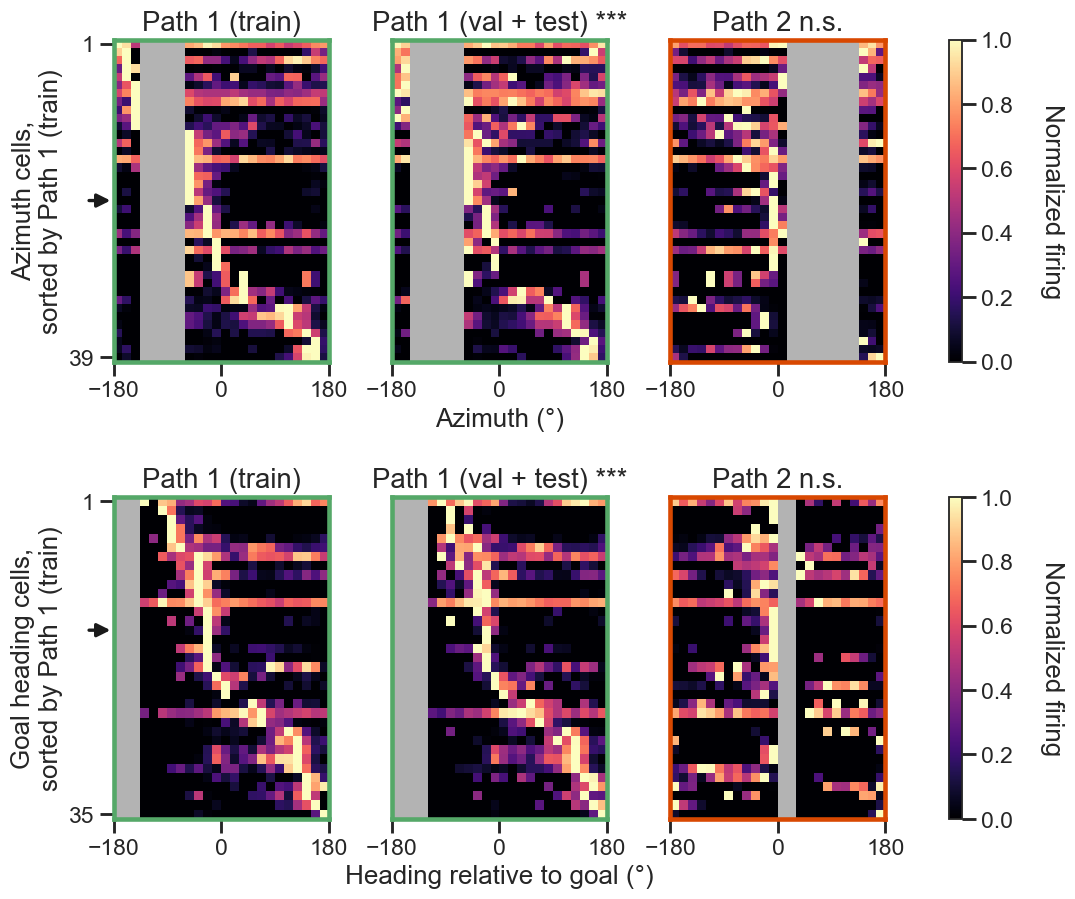

ED Fig 5 — 1_32622_231009 (rew→rew), the Figure 3D panels on two heading axes: Paths 1-2 = clusters [16, 15], Path 1 split 10 train / 9 held out, 24 ring bins over [-180, 180). Cells are per-axis (cross-validated circular tuning), not the 47 place cells of Fig 3D: 39 azimuth, 35 rel.
Peak-heading order vs the Path-1 (train) sort — Fisher-Lee circular rank correlation (one-sided label-permutation p, 2000 iterations):
   axis               panel  n     r stars         P
azimuth Path 1 (val + test) 39 0.399   *** P < 0.001
azimuth              Path 2 39 0.037  n.s. P = 0.144
    rel Path 1 (val + test) 35 0.696   *** P < 0.001
    rel              Path 2 35 0.049  n.s. P = 0.105


In [806]:
# === Extended Data Figure 6 — the Figure 3D sequence on the two HEADING axes ===
# Figure 3D draws the place-cell sequence of one route's paths on a normalized-TIME axis,
# sorted by the Path-1 TRAIN map. This figure asks whether that sequence is really just
# inherited from the bat's heading, a behavioural variable that also evolves along a flight.
# Two readings of heading, one row of the same four panels each, on the SAME session, the same
# paths and the same train / held-out split as Figure 3:
#   a  allocentric AZIMUTH -- atan2 of horizontal velocity; it says nothing about where the
#      flight is going, so two paths can differ in it simply by facing different walls
#   b  GOAL HEADING -- the same heading taken relative to the reward feeder the flight lands
#      on (0 deg = flying straight at it, +-180 deg = straight away, +ve = aimed to its left).
#      Both paths of a route end on the same feeder, so this axis is common to them.
# Each row is drawn on the cells whose tuning to THAT axis is cross-validated-significant
# (`_ring_cells` in the Fig 3 cell, i.e. res_mp4['pc_head']), NOT on the place cells: selecting
# cells on a route-progress map and then asking about heading would beg the question.
# Titles carry the Fisher-Lee (1982) CIRCULAR rank correlation of that panel's peak-heading
# order against the Path-1-train order the rows are sorted by, with stars from the same
# label-permutation null as the Spearman rho in Fig 3D. Heading is circular, so a linear rank
# correlation on peak-BIN INDEX would not be rotation invariant (a path straddling the +-180
# deg seam would be distorted); the pairwise-sine statistic below is rank-based AND invariant
# to rotation of either variable. Ring maps, cell sets and both heading definitions come from
# the Fig 3 cell -- nothing here re-derives a Fig 3 quantity.
from scipy.stats import rankdata as _rankdata_az

ED5_SESSION = MP4_SESSION
# Path 1 and Path 2 only: the endpoint-matched pair every Fig 3 test actually runs on. Fig 3D's
# further paths are dropped here -- 3 and 4 end at the OTHER feeder of the route class, so their
# goal heading is anchored to a different reward and they are not a like-for-like control on
# this axis. Raise to see them (`_m4_sel` order = MP4_PATHS).
ED5_N_PATHS = 2
ED5_PATHS = list(_m4_sel[:ED5_N_PATHS])
ED5_ROWS = [('azimuth', 'Azimuth cells,\nsorted by Path 1 (train)', 'Azimuth (°)'),
            ('rel', 'Goal heading cells,\nsorted by Path 1 (train)',
             'Heading relative to goal (°)')]

_e5_d = session_data_cache[ED5_SESSION]['data']
_e5_dff = session_data_cache[ED5_SESSION]['df_flights']
_e5_nu = len(_e5_d['spike_times']); _e5_dt = 1.0 / _e5_d['Fs']
_e5_ctr = 0.5 * (AP_HEAD_EDGES[:-1] + AP_HEAD_EDGES[1:])   # ring bin centres (radians)


def _e5_ring_map(fldf, kind):
    """`head_maps` of the Fig 3 cell, outside `_route_example`: per-neuron firing rate
    (spikes/s) over the AP_N_HEAD ring of `kind`, occupancy-normalized, for one set of
    flights. Spike headings are interpolated from the unwrapped per-sample trace and
    re-wrapped. Bins the bat never occupied on these flights come back NaN rather than 0, so
    they are excluded from row-normalization and peak selection and read grey in the heatmap
    (`head_maps` fills them with 0 instead, which only matters for the cell selection)."""
    occ = np.zeros(AP_N_HEAD); sp = np.zeros((_e5_nu, AP_N_HEAD))
    for _, fr in fldf.iterrows():
        fs, fe = int(fr.f_start), int(fr.f_stop); ft = _e5_d['t'][fs:fe + 1]
        xyz = _e5_d['r'][fs:fe + 1]
        h = (_traj_azimuth(xyz) if kind == 'azimuth'
             else _rel_heading(xyz, _future_reward(ED5_SESSION, xyz)))
        ok = np.isfinite(h)
        if ok.sum() < 2:
            continue
        occ += np.histogram(h[ok], bins=AP_HEAD_EDGES)[0] * _e5_dt
        tk, hk = ft[ok], np.unwrap(h[ok])
        for u in range(_e5_nu):
            st = _e5_d['spike_times'][u]; stf = st[(st >= tk[0]) & (st <= tk[-1])]
            if len(stf):
                hs = (np.interp(stf, tk, hk) + np.pi) % (2 * np.pi) - np.pi
                sp[u] += np.histogram(hs, bins=AP_HEAD_EDGES)[0]
    rate = np.full((_e5_nu, AP_N_HEAD), np.nan)
    _occd = occ > 0
    rate[:, _occd] = sp[:, _occd] / occ[_occd]
    return rate


def _circ_rank_corr(a, b):
    """Fisher-Lee circular rank correlation between two sets of angles (radians): replace each
    cell's peak heading by its circular rank (uniform score C_i = 2*pi*rank_i/n) and correlate
    the two paths through r = sum_ij sin(C_i-C_j) sin(D_i-D_j) / sqrt(sum sin^2 . sum sin^2)."""
    n = len(a)
    Ca = 2 * np.pi * _rankdata_az(a, method='average') / n
    Cb = 2 * np.pi * _rankdata_az(b, method='average') / n
    sA = np.sin(Ca[:, None] - Ca[None, :]); sB = np.sin(Cb[:, None] - Cb[None, :])
    den = np.sqrt((sA ** 2).sum() * (sB ** 2).sum())
    return float((sA * sB).sum() / den) if den > 0 else np.nan


# --- the four flight sets, i.e. Figure 3D's four panels ------------------------------------
# `_route_example` shuffles Path 1's flights with random_state=seed_ and splits 50 / 25 / 25
# into train / valid / test, then sorts on train and holds out valid+test. That split is
# reconstructed here rather than assumed: the assert rebuilds the held-out normalized-time map
# and requires it to match the one `res_mp4` actually used.
_e5_ref_all = (_e5_dff[_e5_dff.cluster_id == res_mp4['REF']]
               .sample(frac=1.0, random_state=1).reset_index(drop=True))
_e5_tr = _e5_ref_all.iloc[:int(round(0.5 * len(_e5_ref_all)))]
_e5_held = _e5_ref_all.iloc[int(round(0.5 * len(_e5_ref_all))):]
_e5_split_err = float(np.abs(_m4_rate(_e5_d, _e5_held, _tc) - res_mp4['ref_time']).max())
assert _e5_split_err < 1e-9, (
    f'the reconstructed Path-1 train/held-out split disagrees with res_mp4 by '
    f'{_e5_split_err:.2e} — `_route_example` must have been called with seed_ != 1')

_e5_sets = ([('Path 1 (train)', _e5_tr, MP4_COLORS[0]),
             ('Path 1 (val + test)', _e5_held, MP4_COLORS[0]),
             ('Path 2', _e5_dff[_e5_dff.cluster_id == res_mp4['ALT']], MP4_COLORS[1])]
            + [(f'Path {_i + 3}', _e5_dff[_e5_dff.cluster_id == _c], MP4_COLORS[_i + 2])
               for _i, _c in enumerate(ED5_PATHS[2:])])

# --- ring maps, sort order and the per-panel circular rank correlation ---------------------
_e5_maps, _e5_order, _e5_cells, _e5_tests = {}, {}, {}, []
for _ri, (_kind, _ylab, _xlab) in enumerate(ED5_ROWS):
    _cells = np.asarray(res_mp4['pc_head'][_kind], dtype=int)
    _e5_cells[_kind] = _cells
    _e5_maps[_kind] = [_e5_ring_map(_fl, _kind) for _, _fl, _ in _e5_sets]
    _e5_order[_kind] = _cells
    if not len(_cells):
        continue
    # sorted by the Path-1 TRAIN peak (nanargmax over occupied bins only), exactly as Fig 3D
    # sorts its rows by the Path-1 train peak TIME
    _e5_order[_kind] = _cells[np.argsort(np.nanargmax(_e5_maps[_kind][0][_cells], axis=1))]
    _ref_pk = _e5_ctr[np.nanargmax(_e5_maps[_kind][0][_cells], axis=1)]
    for _pi, ((_name, _, _), _M) in enumerate(zip(_e5_sets, _e5_maps[_kind])):
        if _pi == 0:                    # the panel the sort comes from: r = 1 by construction
            _e5_tests.append(dict(axis=_kind, panel=_name, n=len(_cells), r=1.0, p=None))
            continue
        _y = _e5_ctr[np.nanargmax(_M[_cells], axis=1)]
        _r = _circ_rank_corr(_ref_pk, _y)
        # one generator per (axis, panel), so a panel's P does not depend on how many panels
        # precede it: adding or dropping a path leaves every other test's null untouched
        _rng_p = np.random.default_rng([1, _ri, _pi])
        _nul = [_circ_rank_corr(_ref_pk, _rng_p.permutation(_y)) for _ in range(AP_N_SHUF_SEQ)]
        _e5_tests.append(dict(axis=_kind, panel=_name, n=len(_cells), r=round(_r, 3),
                              p=float((1 + np.sum(np.asarray(_nul) >= _r)) / (len(_nul) + 1))))

# --- canvas: one row per heading axis, Figure 3D's four panels across ----------------------
_e5_cmap = plt.get_cmap('magma').copy(); _e5_cmap.set_bad('0.7')  # unoccupied ring bins -> grey
_e5_np = len(_e5_sets)
_e5_star = {(t['axis'], t['panel']): t for t in _e5_tests}
fig_ed5 = plt.figure(figsize=(3.35 * _e5_np + 1.2, 4.6 * len(ED5_ROWS)))
_gs5 = fig_ed5.add_gridspec(len(ED5_ROWS), 1, hspace=0.42)

for _ri, (_kind, _ylab, _xlab) in enumerate(ED5_ROWS):
    _order = _e5_order[_kind]
    # wspace 0.45, far above Fig 3D's 0.14: the +-180 edge labels are much wider than its
    # 0 / 0.5 / 1, and wspace is a fraction of the AVERAGE column width, which the two thin
    # colourbar columns drag well below a panel's own width
    _hg = _gs5[_ri].subgridspec(1, _e5_np + 2, width_ratios=[1] * _e5_np + [0.06, 0.22],
                                wspace=0.45)
    _axes = [fig_ed5.add_subplot(_hg[0, _i]) for _i in range(_e5_np)]
    _cax = fig_ed5.add_subplot(_hg[0, _e5_np])
    for _k, ((_name, _fl, _col), _M) in enumerate(zip(_e5_sets, _e5_maps[_kind])):
        _ax = _axes[_k]
        _ax.set_facecolor('0.7')   # backstop so masked NaN cells read grey, not white
        _H = (_M[_order] / np.maximum(np.nanmax(_M[_order], axis=1, keepdims=True), 1e-9)
              if len(_order) else _M[:0])
        sns.heatmap(_H, ax=_ax, cmap=_e5_cmap, vmin=0, vmax=1, cbar=False,
                    xticklabels=False, yticklabels=False)
        _t = _e5_star.get((_kind, _name))
        _ax.set_title(_name if _t is None or _t['p'] is None
                      else f"{_name} {ph.stars_for_p(_t['p']) or 'n.s.'}")
        for _sp in _ax.spines.values():        # frame each panel in its path colour, as Fig 3D
            _sp.set_visible(True); _sp.set_color(_col); _sp.set_linewidth(3.0)
        _ax.set_xticks([0, AP_N_HEAD / 2, AP_N_HEAD])
        _ax.set_xticklabels(['−180', '0', '180'], rotation=0)
        _ax.set_xlabel(_xlab if _k == _e5_np // 2 else '')  # one x label per row, in the middle
        if _k == 0 and len(_order):
            _ax.set_ylabel(_ylab)
            _ax.set_yticks([0.5, len(_order) - 0.5])
            _ax.set_yticklabels(['1', str(len(_order))], rotation=0)
        else:
            _ax.set_ylabel('')
    _row = np.where(np.asarray(_order) == MP4_UNITS[0])[0]
    if len(_row):                              # arrowhead on Fig 3's highlighted unit
        _axes[0].annotate('', xy=(0, _row[0] + 0.5), xytext=(-18, 0), textcoords='offset points',
                          xycoords='data', va='center', annotation_clip=False, zorder=6,
                          arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2))
    if len(_order):
        _cb = fig_ed5.colorbar(_axes[-1].collections[0], cax=_cax)
        _cb.set_label('Normalized firing', rotation=270, labelpad=18, va='bottom')
    else:
        _cax.axis('off')

ph.save_fig(fig_ed5, 'edfig6_azimuth'); plt.show()

print(f'ED Fig 6 — {ED5_SESSION[8:]} ({MP4_ROUTE}), the Figure 3D panels on two heading axes: '
      f'Paths 1-{len(ED5_PATHS)} = clusters {ED5_PATHS}, Path 1 split {len(_e5_tr)} train / '
      f'{len(_e5_held)} held out, {AP_N_HEAD} ring bins over [-180, 180). Cells are per-axis '
      f'(cross-validated circular tuning), not the {res_mp4["n_place"]} place cells of Fig 3D: '
      + ', '.join(f'{len(v)} {k}' for k, v in _e5_cells.items()) + '.')
print('Peak-heading order vs the Path-1 (train) sort — Fisher-Lee circular rank correlation '
      f'(one-sided label-permutation p, {AP_N_SHUF_SEQ} iterations):')
print(pd.DataFrame([t for t in _e5_tests if t['p'] is not None])
      .assign(stars=lambda d: d['p'].map(lambda p: ph.stars_for_p(p) or 'n.s.'),
              P=lambda d: d['p'].map(ph.fmt_p))[['axis', 'panel', 'n', 'r', 'stars', 'P']]
      .to_string(index=False))


**Extended Data Figure 6 | Generalization of place-cell sequences is not inherited from flight heading.** (A) Firing-rate sequences on an azimuth axis (horizontal flight heading, 24 bins spanning $-180$ to $180^\circ$) rather than normalized time, on the Path 1 training flights (\textit{left}), the held-out Path 1 validation + test flights (\textit{middle}) and all Path 2 flights (\textit{right}) of Figure \ref{fig:fig3}. Rows are the $n$ = 39 azimuth-tuned cells. Grey bins were never occupied on those flights and are excluded from normalization and peak selection. The arrowhead marks the example unit of Figure \ref{fig:fig3}B, C. Panel titles carry the Fisher--Lee circular rank correlation between that panel's azimuth-peak order and the Path-1-training order the rows are sorted by, against a label-permutation null. Azimuth-peak order is preserved within Path 1 (train vs. held-out $r$ = 0.399, $P = 5.00 \times 10^{-4}$) but not between Path 1 and Path 2 ($r$ = 0.037, $P$ = 0.14) -- the opposite of the normalized-time result in Figure \ref{fig:fig3}D, I. (B) As (A), for goal heading on $n$ = 35 goal-heading-tuned cells. Both paths of the route land on the same feeder, so this axis is common to them; nevertheless goal-heading-peak order is again preserved within Path 1 ($r$ = 0.696, $P = 5.00 \times 10^{-4}$) and not between Path 1 and Path 2 ($r$ = 0.049, $P$ = 0.10). Permutation tests use 2,000 iterations. See also Figure \ref{fig:fig3}.

---
## Extended Data Figure 7 — same route, different paths (other examples)

The other four same-route different-path pairs, each arranged identically to
Figure 3 and labeled by bat.

In [ ]:
# === Extended Data Figure 7: Figure 3's rows 1-3, TWO paths, on the other curated sessions ===
# ED Fig 7 used to be three calls to `plot_route_example` -- the OLD three-row Fig 3 composite,
# which carried ONE shuffle histogram (normalized time) and no goal-heading matrix. Figure 3 is
# now `fig3_multipath`, so this cell redraws Figure 3's rows 1-3 panel for panel, on two paths:
#
#   row 1  A top-down, 2 paths      | C raster + PSTH | D three sequence heatmaps (Path 1 train,
#                                     Path 1 held out, Path 2), sorted on Path 1 (train), each
#                                     carrying its peak-order rho against that sort
#   row 2  B 3-D physical rate map  | E PV corr (Path 1 x Path 2) | F 3-D distance between the
#                                     same bin pairs | G |delta heading| relative to the goal
#   row 3  J 3-D latent rate map    | H mean PV corr vs lag, 3 quantities | I the peak-order
#                                     shuffle test of each of those three
#
# Column 1 is the highlighted unit in three renderings, the physical map (B) directly above its
# latent twin (J) under one shared rate scale, so between those two panels only the coordinate
# system changes -- Figure 3's B-beside-J grammar. The latent is the 3-D PCA of the Twin encode
# latent fit PER ENVIRONMENT (`_rm_lat3`), the same basis the Wasserstein / Jaccard indices are
# computed in, so an outdoor session is drawn in the outdoor basis. It exists only for flights
# in the TEST split, so J rests on many fewer flights than B, which uses every flight;
# `rm_latent_unit_panel` prints the count for each path every time it draws.
#
# WHAT IS NEW relative to the old ED Fig 7: the goal-heading matrix (G), and the two extra
# shuffle histograms in I -- azimuth and goal heading beside the motif axis -- so the row reads
# as "the sequence is preserved along the motif and along NEITHER heading" rather than as a
# single test. H already carried all three lag curves; I now matches it one for one.
#
# WHAT IS NOT REDRAWN: Figure 3's rows 4-5. Those are population summaries over every session
# (the binned physical-vs-latent rate-map indices and the bin-free latent z), not a property of
# the example, so they would come out identical in every panel of this figure.
#
# NO SECOND IMPLEMENTATION. Every panel is drawn by Figure 3's own `_m4_*` helper and every
# number is the Path-1-vs-Path-2 output of `_route_example` that ED Fig 7 already reported --
# this cell only rearranges them onto Figure 3's canvas and adds the two heading histograms,
# which `_route_example` was already computing for panel H's curves.
#
# WHICH SESSIONS. `ED6_PAIRS` (cell `9e5b5918`) still holds the curated pairs, but one of them
# -- Dataset_1_32622_231009, clusters 15 vs 16 -- is now EXACTLY Figure 3's Path 1 vs Path 2,
# so drawing it here would repeat the main figure with a different highlighted unit. It is
# dropped by the (session, cluster-pair) comparison below rather than by hand, so the set
# follows whatever `MP4_SESSION` / `MP4_PATHS` become. What remains is the two examples the
# caption describes: bat 32622 (Dataset_1_32622_231010) and bat 14445 (Dataset_2_14445_231209).
# Gaussian SD, in ARC-LENGTH samples, for `_route_example`'s `smooth_traj`. A mean path is
# sampled uniformly in normalized TIME, and the bat spends the last tenth of a flight landing:
# a tenth of the 100 samples describe half a percent of the path, so the average of two dozen
# settling manoeuvres is drawn at full weight. On this session's Path 1 that is an 8 cm arc up
# and back down -- 435 deg of cumulative turn over the last 15 samples. Smoothing in arc length
# takes that to 12 deg (the same SD applied to the samples only reaches 125 deg), while moving
# no point of any drawn path by more than 12 cm and shortening it by at most 2.4%. It reaches
# only the mean-path geometry (panels A, B, F, G and the heading re-indexing behind H/I); the
# rate maps, place cells, ring maps and every shuffle null stay on the raw per-flight tracking.
# Set to None to turn it off.
ED6_SMOOTH_TRAJ = 1.5
ED6_FS = MP4_FS                # Fig 3's font sizes; the `_m4_*` panels read `_m4_fs` directly
ED6_FIGSIZE = (21, 15)         # a little wider than Fig 3: column 1 now carries the raster too
# FIVE columns, not four: column 1 is an empty SPACER whose only job is to widen the gutter
# between the single-unit column and the population read-outs. `wspace` is one number for the
# whole grid, so a column of its own is the only declarative way to open up one gutter -- the
# trade is that this gutter then costs two wspace gaps plus the spacer, which is why wspace is
# pulled in a little from Fig 3's 0.52 to pay for it.
ED6_WIDTH_RATIOS = [1.05, 0.06, 1.00, 1.00, 1.40]
ED6_WSPACE, ED6_HSPACE = 0.40, 0.42
ED6_MARGINS = dict(left=0.045, right=0.975, top=0.95, bottom=0.05)
# (J) is enlarged past its gridspec cell in the final pass, as in Fig 3: (left, right, vertical)
# growth in figure fractions. Growth is LEFT-only -- the right edge has to stay put or the
# '5 a.u.' note that sits just outside it is pushed toward the next column.
ED6_LATENT_GROW = (0.035, 0.0, 0.016)
# Latent scale-bar length, in latent units. `_m4_panel_latent`'s own rule (a round number
# at or below a third of the widest span) picks 5 here, which is long against a panel this
# size; 3 reads as a scale bar rather than as a fourth trajectory.
ED6_LATENT_BAR = 3.0
# Figure fractions to drop row 1 by, closing the gap to row 2 (hspace is one number for the
# whole grid). MP4_ROW1_DROP re-scaled for a 3-row canvas: with fewer rows each row is a larger
# fraction of the figure, so the gap to close is larger in the same units.
ED6_ROW1_DROP = 0.020


def _ed6_disp(res, merge_alt=None):
    """Figure 3's per-path `disp` list for the two-path case, straight out of `_route_example`.

    `_m4_display` rebuilds every rate from the flight table one cluster at a time, which cannot
    express a MERGED Path 2. No curated pair merges any more (`ED6_PAIRS` dropped the Dataset_2
    merge over a tracking artefact in the extra cluster), but `_route_example` still takes
    `merge_alt`, so this keeps the general case rather than silently drawing half a path.
    `res` already carries the identical quantities for both paths -- `ref_time_disp` /
    `ref_time_hi_disp` are the all-flight Path-1 rates `_m4_display` would compute (Figure 3
    asserts exactly that equality), and `alt_time` / `alt_time_hi` are the merged Path-2 ones --
    so this reuses them and nothing is computed twice.
    """
    _dff = session_data_cache[res['session']]['df_flights']
    _spec = [(res['REF'], 'Path 1', [int(res['REF'])], res['traj_ref'],
              res['ref_time_disp'], res['ref_time_hi_disp'], res['neu_ref']),
             (res['ALT'], 'Path 2', [int(res['ALT'])] + [int(c) for c in (merge_alt or [])],
              res['traj_alt'], res['alt_time'], res['alt_time_hi'], res['neu_alt'])]
    return [dict(cluster=int(_c), label=_lab, n=int(_dff.cluster_id.isin(_ids).sum()),
                 flights=_dff[_dff.cluster_id.isin(_ids)], traj=_tj,
                 route=_m4_route_of(res['session'], int(_c)),
                 rate40=_r40, rate_hi=_rhi, rec={res['neuron']: _rec})
            for _c, _lab, _ids, _tj, _r40, _rhi, _rec in _spec]


def _ed6_rate_cbars(fig, cell, disp, rnorm):
    """Figure 3's rate strip under the 3-D map: one horizontal colourbar per path colormap, all
    on the map's own `rnorm`, ticks and label on the bottom bar only."""
    _cbg = cell.subgridspec(len(disp), 1, hspace=0.4)
    for _i, _p in enumerate(disp):
        _sm = plt.cm.ScalarMappable(cmap=MP4_CMAPS[_i], norm=rnorm); _sm.set_array([])
        _cb = fig.colorbar(_sm, cax=fig.add_subplot(_cbg[_i]), orientation='horizontal')
        _cb.ax.xaxis.set_ticks_position('bottom')
        _cb.ax.tick_params(labelsize=ED6_FS['tick'] - 3)
        if _i == len(disp) - 1:
            _cb.set_label('Firing rate (spks/s)', fontsize=ED6_FS['label'])
        else:
            _cb.set_ticks([])


def plot_edfig6(res, disp, neuron, save_name, order_tests):
    """Figure 3's rows 1-3 on a 3 x 5 canvas (col 1 is a spacer) for one two-path example."""
    _sess = res['session']
    fig = plt.figure(figsize=ED6_FIGSIZE)
    gs = fig.add_gridspec(3, 5, width_ratios=ED6_WIDTH_RATIOS, hspace=ED6_HSPACE,
                          wspace=ED6_WSPACE, **ED6_MARGINS)
    # --- column 0: the highlighted unit, top-down then physical then latent ---
    _m4_panel_A(fig.add_subplot(gs[0, 0]), disp)
    # ONE rate scale for both 3-D panels: between them only the coordinate system may change
    _rnorm = plt.Normalize(0.0, max([float(_p['rate40'][neuron].max()) for _p in disp] + [1e-6]))
    _bg = gs[1, 0].subgridspec(2, 1, height_ratios=[1, 0.16], hspace=0.0)
    _ax_b = fig.add_subplot(_bg[0], projection='3d'); _ax_b.computed_zorder = False
    _m4_panel_3d(_ax_b, disp, neuron, _rnorm)
    # the rate key sits under B and serves J as well — they share `_rnorm`
    _ed6_rate_cbars(fig, _bg[1], disp, _rnorm)
    _ax_l = fig.add_subplot(gs[2, 0], projection='3d'); _ax_l.computed_zorder = False
    _m4_panel_latent(_ax_l, _sess, disp, neuron, _rnorm, length=ED6_LATENT_BAR)
    # --- row 1: the raster beside A, then the sequence heatmaps ---
    _m4_panel_raster(fig, gs[0, 2], disp, neuron)
    _cax_d, _axes_d = _m4_panel_heatmaps(fig, gs[0, 3:], res, disp, neuron, order_tests)
    # --- row 2: the three (Path-1 bin x Path-2 bin) matrices. One subgridspec across the three
    # columns, not one matrix per column: the parent columns have different widths and a square
    # heatmap in a wider cell comes out a bigger square, so E, F and G would not match.
    _msub = gs[1, 2:5].subgridspec(1, 3, wspace=0.50)
    _m4_matrix(fig.add_subplot(_msub[0, 0]), res['PV'], 'coolwarm', 'PV correlation', center=0)
    _m4_matrix(fig.add_subplot(_msub[0, 1]), res['pv_dist'], 'viridis_r', '3-D distance (m)',
               ylabel=False)
    # G may carry blank (NaN) rows or columns that Figure 3's does not: `_rel_heading` leaves
    # the bearing undefined within AP_REL_MIN_D of the goal, and these examples are loops that
    # come back to the SAME feeder, so their first time bins sit on top of it. Those bins are
    # dropped from the goal-heading curve in H and its test in I as well, by the same rule.
    _cax_g = _m4_matrix(fig.add_subplot(_msub[0, 2]), _m4_goal_heading_mat(res, _sess),
                        'viridis_r', '|heading| relative to goal (°)', vmin=0, vmax=180,
                        cbar_ticks=[0, 45, 90, 135, 180], ylabel=False)
    # --- row 3: the lag curves beside the latent map, then one shuffle test per quantity. The
    # three histograms share the last two columns, so each is ~2/3 of a column wide.
    _m4_panel_lag(fig, fig.add_subplot(gs[2, 2]), res)
    _hsub = gs[2, 3:5].subgridspec(1, len(MP4_QUANTITIES), wspace=0.30)
    _t = res.get('tests') or {}
    for _qi, (_qk, _qlab, _qcol, _qxl) in enumerate(MP4_QUANTITIES):
        _o = (dict(rho=_t.get('rho'), null=_t.get('null1'), p=_t.get('p_order')) if _qk == 'motif'
              else (res.get('head_order') or {}).get(_qk) or {})
        _m4_panel_null(fig.add_subplot(_hsub[0, _qi]), _o.get('rho'), _o.get('null'),
                       _o.get('p'), _qcol, _qlab, _qxl, ylabel=(_qi == 0))
    for _ax in fig.axes:            # one tick size for every panel, colourbars included
        _ax.tick_params(labelsize=ED6_FS['tick'])
    # --- final alignment pass, as in Figure 3: slide the WHOLE heatmap block right until its
    # colourbar sits over G's, and drop row 1 by ED6_ROW1_DROP. Needs the laid-out positions,
    # so it runs after a draw (an equal-aspect axes only takes its final shape then).
    fig.canvas.draw()
    _dx = _cax_g.get_position().x0 - _cax_d.get_position().x0
    for _ax_r1 in [_cax_d] + list(_axes_d):
        _p = _ax_r1.get_position()
        _ax_r1.set_position([_p.x0 + _dx, _p.y0 - ED6_ROW1_DROP, _p.width, _p.height])
    _p = _ax_l.get_position()            # (J) bigger than its cell, overflowing to the left
    _ax_l.set_position([_p.x0 - ED6_LATENT_GROW[0], _p.y0 - ED6_LATENT_GROW[2],
                        _p.width + ED6_LATENT_GROW[0] + ED6_LATENT_GROW[1],
                        _p.height + 2 * ED6_LATENT_GROW[2]])
    ph.save_fig(fig, save_name); plt.show()


# --------------------------------------------------------------- run it ------------------
def _ed6_tail_turn(traj, n=15):
    """Total turning (degrees) over the last `n` samples of a path.

    The CUMULATIVE turn, not the worst single step: the landing artefact this smoothing exists
    for is a short arc traversed over many samples, so it shows up as hundreds of degrees summed
    over a tail that covers a few centimetres, while no single step need be extreme. Arc-length
    smoothing also re-spaces the samples, which makes a max-per-step comparison between raw and
    smoothed meaningless (equal steps spread the same curvature evenly); the sum does not care.
    """
    _v = np.diff(np.asarray(traj, float), axis=0)
    _u = _v / np.maximum(np.linalg.norm(_v, axis=1, keepdims=True), 1e-12)
    return float(np.degrees(np.arccos(np.clip((_u[:-1] * _u[1:]).sum(1), -1, 1)))[-n:].sum())


def _ed6_report_smoothing(res, spec):
    """Print what `ED6_SMOOTH_TRAJ` actually did to this example's mean paths, so the smoothing
    is auditable rather than invisible: the turn accumulated over the landing tail before and
    after, and how far the filter moved the path. Path 2 is skipped when it is a merge — there
    is then no single raw cluster path to compare against."""
    if not ED6_SMOOTH_TRAJ:
        return
    _ci = session_data_cache[res['session']]['cluster_info']
    _pairs = [('Path 1', _ci[res['REF']]['mean_traj'], res['traj_ref'])]
    if not spec['merge_alt']:
        _pairs.append(('Path 2', _ci[res['ALT']]['mean_traj'], res['traj_alt']))
    for _lab, _raw, _sm in _pairs:
        print('  %s mean path: turn over the last 15 samples %.0f° → %.0f°, moved ≤ %.3f m '
              '(σ = %g arc-length samples)'
              % (_lab, _ed6_tail_turn(_raw), _ed6_tail_turn(_sm),
                 float(np.linalg.norm(_sm - np.asarray(_raw, float), axis=1).max()),
                 ED6_SMOOTH_TRAJ))


def _ed6_is_fig3_pair(spec):
    """Is this curated pair the one Figure 3 already draws as its Path 1 vs Path 2?"""
    return (spec['session'] == MP4_SESSION and not spec['merge_alt']
            and {spec['cluster_a'], spec['cluster_b']} == set((MP4_PATHS or [])[:2]))


ED6_SPECS = [_s for _s in ED6_PAIRS if not _ed6_is_fig3_pair(_s)]
for _s in ED6_PAIRS:
    if _ed6_is_fig3_pair(_s):
        print('  [%s cl %d/%d skipped: this pair IS Figure 3\'s Path 1 vs Path 2]'
              % (_s['session'][8:], _s['cluster_a'], _s['cluster_b']))

ed6_records = []
# `ed6_results` keeps each example's `_route_example` output, so a panel can be re-drawn or
# interrogated afterwards without paying for the shuffle tests a second time.
ed6_results = []
for _spec in ED6_SPECS:
    _res6 = _route_example(
        0, merge_alt=_spec['merge_alt'], force_neuron=_spec['unit'],
        smooth_traj=ED6_SMOOTH_TRAJ,
        pairs_df=pd.DataFrame([_pair_row(_spec['session'], _spec['cluster_a'],
                                         _spec['cluster_b'])]))
    _disp6 = _ed6_disp(_res6, _spec['merge_alt'])
    _ord6 = _m4_order_tests(_res6, _disp6)
    _ed6_report_smoothing(_res6, _spec)
    print('\n%s (bat %s) — %s: Path 1 = cl %d (%d flights), Path 2 = cl %s (%d flights), '
          'Fréchet %.2f m; %d place cells, ring-tuned %s; highlighted unit %d'
          % (_res6['session'][8:], _res6['bat'], _res6['route'], _disp6[0]['cluster'],
             _disp6[0]['n'], [_disp6[1]['cluster']] + list(_spec['merge_alt'] or []),
             _disp6[1]['n'], _res6['frechet'], _res6['n_place'],
             {k: len(v) for k, v in _res6['pc_head'].items()}, _spec['unit']))
    plot_edfig6(_res6, _disp6, _res6['neuron'], f"edfig7_route_example_{_spec['session']}",
                _ord6)
    ed6_records += [dict(session=_res6['session'][8:], **_r)
                    for _r in _m4_stat_table(_res6, _ord6)]
    ed6_results.append(dict(spec=_spec, res=_res6, disp=_disp6, order=_ord6))
if ed6_records:
    print('\nED Fig 7 — the same read-outs Figure 3 reports, per example (one-sided '
          'permutation / shuffle / bootstrap p). The highlighted unit enters none of them:')
    ph.p_table(ed6_records)

**Extended Data Figure 7 | Additional examples of similar single-neuron tuning along geometrically different paths that share an origin and destination.** Each subpanel as in Figure \ref{fig:fig3}A–J. Per example, the peak-order correlations of (D), the near-versus-far PV tests of (H) and the peak-order shuffle tests of (I): (i) bat 32622, reward $\to$ reward, Path 1 = 43 flights vs. Path 2 = 13 flights, Fréchet distance 1.97 m, $n$ = 35 place cells (24 azimuth-, 22 goal-heading-tuned) — peak-order $\rho$ against the Path 1 training sort 0.765 held out ($P = 5.00 \times 10^{-4}$) and 0.580 on Path 2 ($P = 1.50 \times 10^{-3}$); PV near-vs-far +0.461 ($P = 5.00 \times 10^{-4}$) on normalized time, +0.052 ($P$ = 0.38) on azimuth and +0.143 ($P$ = 0.071) on goal heading, the paired contrasts being +0.202 ($P = 6.0 \times 10^{-3}$) and +0.201 ($P = 8.0 \times 10^{-3}$); peak-order Spearman $\rho$ = 0.513 ($P = 2.00 \times 10^{-3}$) between the held-out Path 1 flights and Path 2, against circular $\rho$ = $-0.238$ (azimuth, $P$ = 0.998) and $-0.061$ (goal heading, $P$ = 0.85). (ii) bat 14445, reward $\to$ perch, 28 vs. 6 flights, Fréchet distance 2.36 m, $n$ = 85 place cells (36 azimuth-, 47 goal-heading-tuned) — peak-order $\rho$ 0.747 held out and 0.429 on Path 2 (both $P = 5.00 \times 10^{-4}$); PV near-vs-far +0.323 ($P = 5.00 \times 10^{-4}$), $-0.081$ ($P$ = 0.91) and +0.117 ($P$ = 0.030), the paired contrasts being +0.209 ($P = 1.00 \times 10^{-3}$) and +0.099 ($P$ = 0.032); peak-order Spearman $\rho$ = 0.493 ($P = 5.00 \times 10^{-4}$), against circular $\rho$ = $-0.041$ ($P$ = 0.88) and $-0.119$ ($P$ = 0.998). See also Figure \ref{fig:fig3}.

---
## Figure 4 — Readout weights surface correlations in spatial and non-spatial activity

**a** PC1 of the readout-weight matrix vs mean firing rate, per session (vs random-direction null). **b** Residual-readout hierarchical clustering as a vertical stack (dendrogram over the cosine-similarity matrix over the residual readout-weight matrix, 64-d latent vertical). **c** Spatial information per readout cluster. **d** Example neural$\to$position attribution (Jacobian) matrix over time (upper = future/prospective, lower = past/retrospective). **e** Future-past attribution index by cluster. **f** Example sleep-matched session: Non-flight FR, Sleep FR (near-identical), residual readout, rate-map and coupling similarity matrices. **g** MRM marginal $R^{2}$ of each predictor against non-flight rest. **h** MRM unique (semipartial) $R^{2}$ of each predictor against non-flight rest. **i** The same unique $R^{2}$ against sleep noise correlations (sleep-matched sessions only). **j** Residual readouts predict CA1 vs CA3 membership (per-session SVM swarm vs chance = 0.5). **k** MRM unique $R^{2}$ within CA1 vs CA3 for all three predictors, with the predictor $\times$ subregion interaction.

> Panels **f–k** build the rate-map, non-flight-rest and coupling similarity streams directly (rate maps from flight spikes; non-flight from a per-session `Data_Prep` load; coupling from the GLM+history+coupling checkpoint). The **sleep** matrix (2nd panel of **f**) matches flight units to Dataset_0 sleep units via UnitMatch `MatchTable.csv` files (guarded — skipped if those / the Dataset_0 spike files are absent); panel **f** is restricted to those matched neurons so Non-flight FR and Sleep FR are directly comparable.

In [593]:
# === Figure 4 foundation: per-neuron readout weights + metadata + subregion ===
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# Per-neuron table: unit-normed readout rows, pType, probe, position, mean FR.
_rows, _W = [], []
for sn in dataloaders['test']:
    W = bat_former.readouts[sn][0].weight.detach().cpu().numpy()   # (K, D)
    pos = np.asarray(meta_info_dict['neuron_position'][sn])
    ptype = np.asarray(meta_info_dict['pType'][sn])
    probe = np.asarray(meta_info_dict['probe_id'][sn])
    # mean FR from test spikes
    yl, ml = [], []
    for b in dataloaders['test'][sn]:
        yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    ya, ma = np.vstack(yl), np.vstack(ml)
    mfr = ya[ma == 1.0].mean(0) / bin_width
    for u in range(W.shape[0]):
        pt = ptype[u] if not isinstance(ptype[u], np.ndarray) else 'filtered'
        _rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, pType=str(pt),
                          probe_id=int(probe[u]), lateral=float(pos[u, 0]),
                          depth=float(pos[u, 1]), mean_fr=float(mfr[u])))
    _W.append(W)
readout_df = pd.DataFrame(_rows)
W_all = np.vstack(_W)
readout_df['readout_weight'] = list(W_all / np.linalg.norm(W_all, axis=1, keepdims=True))

# Attach joint per-neuron corr/FDE (computed for Fig 1g/h).
_jm = encode_metrics_df[encode_metrics_df['model'] == 'joint'][['session', 'unit', 'corr', 'fde']]
readout_df = readout_df.merge(_jm.rename(columns={'corr': 'corr_all', 'fde': 'fde_all'}),
                              on=['session', 'unit'], how='left')


# --- Subregion (CA1/CA3) from per-(bat,probe) depth clumps (internals recipe) ---
CLUMP_HW, PEAK_DIST, HBIN, SM_SIGMA, PROM = 300, 450, 25, 200, 0.04


def detect_clumps(depths):
    if len(depths) < 5:
        return np.array([])
    lo = np.floor(depths.min() / HBIN) * HBIN
    hi = np.ceil(depths.max() / HBIN) * HBIN + HBIN
    counts, edges = np.histogram(depths, bins=np.arange(lo, hi, HBIN))
    centers = 0.5 * (edges[:-1] + edges[1:])
    sm = gaussian_filter1d(counts.astype(float), sigma=SM_SIGMA / HBIN)
    if sm.max() == 0:
        return np.array([])
    padded = np.concatenate([[0.0], sm, [0.0]])
    pk, _ = find_peaks(padded, distance=max(1, PEAK_DIST // HBIN), prominence=PROM * sm.max())
    pk = pk - 1
    pk = pk[(pk >= 0) & (pk < len(sm))]
    if len(pk) == 0:
        pk = np.array([int(np.argmax(sm))])
    if len(pk) > 2:
        pk = pk[np.argsort(sm[pk])[::-1][:2]]
    return np.sort(centers[pk])


def _window(peak, lo, hi):
    a, b = peak - CLUMP_HW, peak + CLUMP_HW
    if b > hi:
        b, a = hi, hi - 2 * CLUMP_HW
    elif a < lo:
        a, b = lo, lo + 2 * CLUMP_HW
    return a, b


readout_df['subregion'] = None
for (bat, probe), grp in readout_df.groupby(['bat', 'probe_id']):
    d = grp['depth'].values
    peaks = detect_clumps(d)
    if len(d) == 0 or len(peaks) == 0:
        continue
    dlo, dhi = float(np.nanmin(d)), float(np.nanmax(d))
    labels = np.array([None] * len(d), dtype=object)
    if len(peaks) == 1:
        a, b = _window(peaks[0], dlo, dhi)
        labels[(d >= a) & (d <= b)] = 'CA1'
    else:
        ventral, dorsal = peaks[0], peaks[-1]
        la, lb = _window(dorsal, dlo, dhi)
        va, vb = _window(ventral, dlo, dhi)
        if vb > la:
            vb, va = la, la - 2 * CLUMP_HW
        labels[(d >= la) & (d <= lb)] = 'CA1'
        labels[(d >= va) & (d <= vb)] = 'CA3'
    readout_df.loc[grp.index, 'subregion'] = labels


def residual_readout(W, fr):
    """Orthogonalize unit-normed readout rows W against the population mean-FR axis (rank-1 deflation), renormalise."""
    ax = W.T @ (fr - fr.mean())
    n = np.linalg.norm(ax)
    Wr = W - np.outer(W @ (ax / n), ax / n) if n > 0 else W.copy()
    rn = np.linalg.norm(Wr, axis=1, keepdims=True); rn[rn == 0] = 1.0
    return Wr / rn


# Well-fit cells (fde_all > 0: encoding model beats the mean-rate baseline), residual readout per session.
clu_df = readout_df[readout_df['fde_all'] > 0.0].copy().reset_index(drop=True)
clu_df['readout_weight_residual'] = clu_df['readout_weight']
for _, grp in clu_df.groupby('session'):
    Wr = residual_readout(np.stack(grp['readout_weight'].values), grp['mean_fr'].values)
    for j, ix in zip(range(len(grp)), grp.index):
        clu_df.at[ix, 'readout_weight_residual'] = Wr[j]
print('readout_df:', len(readout_df), 'neurons |', readout_df['subregion'].notna().sum(),
      'with subregion | clu_df well-fit:', len(clu_df))

readout_df: 3080 neurons | 2938 with subregion | clu_df well-fit: 2147


In [594]:
# === Figure 4b clustering step (compute once; the plotting cell only draws) ===
# Hierarchical clustering of the firing-rate-residual read-out weights across well-fit
# neurons. Produces the leaf order, per-neuron cluster labels, ordered similarity /
# weight matrices, and the dendrogram link-colour map consumed by the Fig 4 plotting
# cell (and by ED Fig 8, which reuses CLUSTER_ORDER / CLUSTER_PALETTE / clu_df['cluster']).
from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import pdist
import matplotlib.colors as mcolors

Wr = np.stack(clu_df['readout_weight_residual'].values)       # (N, D), unit-normed
dist = pdist(Wr, metric='cosine')
Z = linkage(dist, method='average')
# Cut the tree fine, then keep only well-populated clusters (matches internals.ipynb:
# the residual read-outs over-split into many singletons, so a low fixed N_CLUSTERS
# lumps distinct groups together). CLUSTER_ORDER is the `included` subset (clusters with
# >= MIN_NEURONS members); every other cluster is greyed out in the dendrogram/strip and
# dropped from the per-cluster panels (here + ED Fig 8, which reuse CLUSTER_ORDER).
N_CLUSTERS = 12
MIN_NEURONS = 200
clu_df['cluster'] = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
_clu_sizes = clu_df['cluster'].value_counts()
CLUSTER_ORDER = sorted(_clu_sizes[_clu_sizes >= MIN_NEURONS].index.astype(int).tolist())
CLUSTER_PALETTE = ph.cluster_palette(CLUSTER_ORDER)
CLUSTER_GREY = (0.7, 0.7, 0.7)
order = dendrogram(Z, no_plot=True)['leaves']
sim_ord = (Wr @ Wr.T)[np.ix_(order, order)]
Wr_ord = Wr[order]
clus_ord = clu_df['cluster'].values[order]
N, D = Wr_ord.shape                                            # neurons, latent dims (64)
XSPAN = 10 * N                                                 # scipy leaf spacing (5,15,...)
# Colour each dendrogram link by its cluster, but only for `included` clusters (grey
# otherwise), so the tree matches the strip + boxplots. A merge keeps a cluster colour
# only when both of its children carry that same cluster label.
_labels_clu = clu_df['cluster'].values
_n_leaf = Z.shape[0] + 1
_node_clu = {i: int(_labels_clu[i]) for i in range(_n_leaf)}
for _i in range(Z.shape[0]):
    _ca, _cb = _node_clu.get(int(Z[_i, 0])), _node_clu.get(int(Z[_i, 1]))
    _node_clu[_n_leaf + _i] = _ca if (_ca is not None and _ca == _cb) else None


def _dendro_link_color(k):
    """Cluster colour for dendrogram link `k`; grey for excluded/mixed clusters."""
    c = _node_clu.get(k)
    return mcolors.to_hex(CLUSTER_PALETTE[c]) if c in CLUSTER_PALETTE else '0.6'


print('cluster sizes:', clu_df['cluster'].value_counts().sort_index().to_dict())
print(f'included clusters (>= {MIN_NEURONS} neurons): {CLUSTER_ORDER}')


cluster sizes: {1: 464, 2: 40, 3: 29, 4: 308, 5: 151, 6: 134, 7: 315, 8: 46, 9: 14, 10: 410, 11: 217, 12: 19}
included clusters (>= 200 neurons): [1, 4, 7, 10, 11]


In [595]:
# === Fig 4d/e data: neural->position attribution (input-gradient Jacobian) ===
# Ported from internals.ipynb (prosp_attribution / attr_example_matrix). The encoder is a
# NON-causal transformer, so rate at time i can draw on position at past AND future j. For
# each test flight we take the input-gradient attribution A[i, n, j] = ||d rate(i,n)/d pos(j)||
# (norm over x,y,z), and summarise each neuron by the scale-free future-past contrast
# (UP - LO)/(UP + LO) of the upper (future, j>i) vs lower (past) triangle, excluding
# |i-j| <= EXCL bins around the diagonal. UP/LO sums are POOLED across all test flights.
# >0 = prospective.
#
# CACHED under ./out/fig4_cache/ in TWO parts: the expensive per-neuron future-past sweep
# (fig4_attr_lookup) and the cheap single-flight example matrix (fig4_attr_example). Splitting
# them means changing the example selection does NOT invalidate the costly sweep. Keys capture
# the joint checkpoint (path + size + mtime), the test session set, T_MAX / EXCL, bin width,
# and (for the lookup) the well-fit neuron list. Set FIG4_FORCE = True to force recompute.
import os, pickle, hashlib
import torch
T_MAX, EXCL = 200, 2
attr_excl_s = float(EXCL * bin_width)   # exclusion half-band (s) either side of the diagonal (= 200 ms)

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute + save."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


def _cuda_clear():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _flight_attr_sums(sn, x0, m0, vi):
    """Per-neuron pooled future(UP)/past(LO) position-attribution sums for one flight."""
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)   # (Tv, n)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)             # (Tv, n, T, beh)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()               # (Tv, n, Tv)
    del J, rows_t
    _cuda_clear()
    Tv = len(vi)
    jj = np.arange(Tv)[None, :] - np.arange(Tv)[:, None]      # j - i
    up, lo = jj > EXCL, jj < -EXCL                            # future / past position
    return (A * up[:, None, :]).sum((0, 2)), (A * lo[:, None, :]).sum((0, 2))


def _flight_attr_matrix(sn, x0, m0, vi):
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()
    del J, rows_t
    _cuda_clear()
    return A


# --- Part 1: per-neuron future-past index over every test flight (expensive; cached) ---
_lookup_key = dict(
    kind='fig4_attr_lookup_v1', joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(dataloaders['test'].keys()),
    t_max=int(T_MAX), excl=int(EXCL), bin_width=float(bin_width),
    units=tuple((str(s), int(u)) for s, u in zip(clu_df['session'], clu_df['unit'])),
)


def _compute_lookup():
    bat_former.eval()
    attr_lookup = {}
    for sn in dataloaders['test']:
        up_tot = lo_tot = None
        n_done = 0
        for batch in dataloaders['test'][sn]:
            Xb, Mb = batch.behavior.to(device), batch.mask.to(device)
            for b in range(Xb.shape[0]):
                vi = np.where(batch.mask[b].numpy() == 1.0)[0]
                if len(vi) < 2 * EXCL + 3:
                    continue
                vi = vi[:T_MAX]
                try:
                    us, ls = _flight_attr_sums(sn, Xb[b].detach(), Mb[b:b + 1], vi)
                except RuntimeError as e:
                    print(f'    {sn} flight {n_done}: skipped ({str(e)[:40]})')
                    _cuda_clear()
                    continue
                up_tot = us if up_tot is None else up_tot + us
                lo_tot = ls if lo_tot is None else lo_tot + ls
                n_done += 1
            del Xb, Mb
            _cuda_clear()
        if up_tot is not None:
            with np.errstate(divide='ignore', invalid='ignore'):
                attr_lookup[sn] = np.where(up_tot + lo_tot > 0,
                                           (up_tot - lo_tot) / (up_tot + lo_tot), np.nan)
        print(f'  {sn}: attribution over {n_done} flights')
    return attr_lookup


attr_lookup = _fig4_cache('fig4_attr_lookup', _lookup_key, _compute_lookup)
clu_df['future_idx'] = [attr_lookup[s][int(u)] if (s in attr_lookup and int(u) < len(attr_lookup[s]))
                        else np.nan for s, u in zip(clu_df['session'], clu_df['unit'])]

# --- Part 2: example matrix — illustrative neuron FIXED BY HAND, longest valid test flight
#     in that session (cheap; cached per selected neuron). Chosen: Dataset_3_00000_240404
#     neuron 5 (cluster 5, future_idx ~ +0.11) as a clear prospective example. ---
attr_ex_sn, attr_ex_unit = 'Dataset_3_00000_240404', 5
_exq = clu_df[(clu_df['session'] == attr_ex_sn) & (clu_df['unit'] == attr_ex_unit)]
_ex = _exq.iloc[0] if len(_exq) else dict(future_idx=np.nan)
_ex_key = dict(kind='fig4_attr_example_v1', joint=_ckpt_sig(JOINT_CKPT),
               sn=attr_ex_sn, unit=attr_ex_unit, t_max=int(T_MAX), bin_width=float(bin_width))


def _compute_example():
    bat_former.eval()
    _best = None
    for batch in dataloaders['test'][attr_ex_sn]:
        for b in range(batch.behavior.shape[0]):
            vi = np.where(batch.mask[b].numpy() == 1.0)[0]
            if _best is None or len(vi) > _best[0]:
                _best = (len(vi), batch.behavior[b].detach().to(device),
                         batch.mask[b:b + 1].to(device), vi[:T_MAX])
    A = _flight_attr_matrix(attr_ex_sn, _best[1], _best[2], _best[3])
    return A[:, attr_ex_unit, :]


attr_ex_matrix = np.asarray(_fig4_cache('fig4_attr_example', _ex_key, _compute_example))
attr_ex_ext = float(attr_ex_matrix.shape[0] * bin_width)   # seconds (scalar for imshow extent)
print(f'attribution example: {attr_ex_sn} neuron {attr_ex_unit} '
      f'(future_idx={float(_ex["future_idx"]):+.3f}, fixed example); '
      f'{int(clu_df["future_idx"].notna().sum())} neurons with attribution')

  [cache hit] fig4_attr_lookup
  [cache hit] fig4_attr_example
attribution example: Dataset_3_00000_240404 neuron 5 (future_idx=+0.130, fixed example); 2147 neurons with attribution


In [596]:
# === Fig 4 data streams (panels c, f–k): rate maps, non-flight rest corr, coupling ===
# Ported from internals.ipynb (rate maps, non-flight Data_Prep load, coupling GLM).
from digitalbat.datasets.data import Data_Prep_for_Raw
from notebook_helpers import loc_bin_width_rm

# (1) Per-neuron 2D rate maps (observed spikes / occupancy) per session.
session_rate_maps, session_occ = {}, {}
for sn, sd in dataloaders['test'].items():
    Xl, yl, ml = [], [], []
    for b in sd:
        Xl.append(b.behavior.numpy()); yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    Xa, ya, ma = np.vstack(Xl), np.vstack(yl), np.vstack(ml)
    bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
    xlim, ylim = meta_info_dict['r_lim'][sn][0], meta_info_dict['r_lim'][sn][1]
    xe = np.arange(xlim[0], xlim[1] + loc_bin_width_rm, loc_bin_width_rm)
    ye = np.arange(ylim[0], ylim[1] + loc_bin_width_rm, loc_bin_width_rm)
    v = ma == 1.0
    lx = Xa[:, :, 0][v] * bs[0, 0, 0] + bm[0, 0, 0]
    ly = Xa[:, :, 1][v] * bs[0, 0, 1] + bm[0, 0, 1]
    spk = ya[v]
    occ, _, _ = np.histogram2d(lx, ly, bins=[xe, ye])
    under = occ < 3
    maps = np.full((spk.shape[1], (len(xe) - 1) * (len(ye) - 1)), np.nan)
    for u in range(spk.shape[1]):
        wsum, _, _ = np.histogram2d(lx, ly, bins=[xe, ye], weights=spk[:, u])
        with np.errstate(divide='ignore', invalid='ignore'):
            rm = wsum / (occ * bin_width)
        rm[under] = np.nan
        maps[u] = rm.ravel()
    session_rate_maps[sn] = maps
    session_occ[sn] = occ.ravel()

# (2) Non-flight rest correlation matrices (raw counts) per session.
nonflight_corr = {}
for sn in session_names:
    folder = data_config['parent_folder'] + sn
    su = data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    kw = dict(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
              use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
              use_ripple_flag=False, spike_count_flag=True, bin_width=bin_width)
    try:
        dpf = Data_Prep_for_Raw(only_flight_flag=True, **kw)
        dpf.get_all_behavior(); dpf.get_all_spike()
        dpa = Data_Prep_for_Raw(only_flight_flag=False, **kw)
        dpa.get_all_behavior(); allspk = dpa.get_all_spike()
        nf = np.setdiff1d(np.arange(allspk.shape[1]), dpf.flight_ind)
        nonflight_corr[sn] = np.corrcoef(allspk[:, nf])
    except Exception as exc:
        print(f'  [nonflight skip {sn}] {type(exc).__name__}: {exc}')

# (3) Pairwise coupling similarity from the GLM+hist+coupling checkpoint.
session_coupling_sim = {}
COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_zbasis17.pth'
if os.path.exists(COUP_CKPT):
    cs = torch.load(COUP_CKPT, map_location='cpu', weights_only=False)
    kint = cs['coup_basis'].numpy().sum(0) * bin_width
    for k, v in cs.items():
        if k.startswith('coup_weights.'):
            _csn = k.split('coup_weights.', 1)[1]
            if _csn not in session_names:   # ckpt spans 24 trained sessions; keep only the 17 used here
                continue
            K = v.numpy() @ kint
            np.fill_diagonal(K, 0.0)
            Csym = 0.5 * (K + K.T); np.fill_diagonal(Csym, 0.0)
            session_coupling_sim[_csn] = Csym
print(f'streams: {len(session_rate_maps)} rate-map, {len(nonflight_corr)} non-flight, '
      f'{len(session_coupling_sim)} coupling sessions')


def ratemap_corr_matrix(maps):
    """Pairwise Pearson r between neurons' rate maps over jointly-valid bins."""
    n = maps.shape[0]
    C = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i, n):
            m = np.isfinite(maps[i]) & np.isfinite(maps[j])
            if m.sum() >= 5 and maps[i, m].std() > 0 and maps[j, m].std() > 0:
                C[i, j] = C[j, i] = np.corrcoef(maps[i, m], maps[j, m])[0, 1]
    return C


session_sleep_corr = {}   # populated by the sleep-matching cell below


def session_matrices(sn):
    """Well-fit-neuron submatrices (nonflight, residual readout, rate map, coupling)
    for one session, all ordered by the session's clu_df units. Missing streams -> None."""
    grp = clu_df[clu_df['session'] == sn]
    units = grp['unit'].to_numpy()
    if len(units) < 6 or sn not in nonflight_corr:
        return None
    Wr = np.stack(grp['readout_weight_residual'].values)
    out = dict(units=units, grp=grp,
               nonflight=nonflight_corr[sn][np.ix_(units, units)],
               residual=Wr @ Wr.T,
               ratemap=ratemap_corr_matrix(session_rate_maps[sn][units]),
               coupling=(session_coupling_sim[sn][np.ix_(units, units)]
                         if sn in session_coupling_sim else None),
               sleep=session_sleep_corr.get(sn))
    return out


streams: 17 rate-map, 17 non-flight, 17 coupling sessions


In [597]:
# === Fig 4g sleep matrix: match flight units to Dataset_0 sleep units (UnitMatch) ===
# Ported from internals.ipynb. For each flight session with a sleep pair, map its
# Kilosort cluster ids to the sleep-session (Dataset_0) cluster ids via UnitMatch
# MatchTables, bin the sleep spikes, and build a per-session sleep FR-correlation
# matrix over the well-fit (clu_df) neurons (NaN where unmatched / silent). Guarded:
# sessions without MatchTable / Dataset_0 SU files are skipped.
from pathlib import Path
from scipy.io import loadmat

UM_ROOT = Path('/mnt/s5adam/Angelo/NP_datasets/UnitMatch')
SLEEP_PAIRS = {
    'Dataset_3_00000_240403': 'Dataset_0_00000_240403',
    'Dataset_3_00000_240404': 'Dataset_0_00000_240404',
    'Dataset_3_14543_240420': 'Dataset_0_14543_240420',
    'Dataset_3_29959_240403': 'Dataset_0_29959_240403',
    'Dataset_3_29959_240404': 'Dataset_0_29959_240404',
}


def _load_match_table(animal, date, probe):
    p = UM_ROOT / 'matches' / f'{animal}_{date}' / f'probe{probe}' / 'MatchTable.csv'
    return pd.read_csv(p) if p.is_file() else None


def _build_flight_to_sleep_map(animal, date):
    mapping = {}
    for probe in (1, 2, 3):
        df = _load_match_table(animal, date, probe)
        if df is None:
            continue
        cross = df[(df['RecSes 1'] != df['RecSes 2']) & (df['Matches'] == 1) & (df['RecSes 1'] == 1)]
        best = cross.sort_values('UM Probabilities', ascending=False).drop_duplicates('ID2', keep='first')
        for _, r in best.iterrows():
            mapping[(probe, int(r['ID2']))] = int(r['ID1'])
    return mapping


def _flight_cluster_ids(sn):
    dp = Data_Prep_for_Raw(
        parent_folder=data_config['parent_folder'] + '/' + sn,
        su_file_path=data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat',
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, only_flight_flag=True)
    dp.get_all_behavior(); dp.get_all_spike()
    return dp.cluster_id, dp.probe_id + 1   # data.py 0-indexed; UnitMatch uses probe 1..3


def _bin_ds0_spikes(ds0_session, sleep_clu_per_probe):
    binned = {}
    for probe in (1, 2, 3):
        wanted = sleep_clu_per_probe.get(probe)
        if not wanted:
            continue
        path = f"{data_config['parent_folder']}/To_transfer/out_Gunits_probe{probe}_{ds0_session}.mat"
        if not Path(path).is_file():
            continue
        ou = loadmat(path)['out_Gunits']
        all_cids = np.array([int(x[0][0, 0]) for x in ou['cluster_id']])
        all_times_s = [x[0][:, 0] / 1e6 for x in ou['spikeTimes_usec']]
        t_end = max((t.max() for t in all_times_s if len(t)), default=0.0) + bin_width
        edges = np.arange(0, t_end + bin_width, bin_width)
        out = np.zeros((len(wanted), len(edges) - 1), dtype=np.int32)
        for i, cid in enumerate(wanted):
            idx = np.where(all_cids == cid)[0]
            if len(idx):
                out[i] = np.histogram(all_times_s[idx[0]], bins=edges)[0]
        binned[probe] = out
    if not binned:
        return {}
    common = min(a.shape[1] for a in binned.values())
    return {p: a[:, :common] for p, a in binned.items()}


for sn, ds0 in SLEEP_PAIRS.items():
    grp = clu_df[clu_df['session'] == sn]
    if len(grp) < 3:
        continue
    animal, date = sn.split('_')[2], sn.split('_')[3]
    try:
        cid_full, pid_full = _flight_cluster_ids(sn)
        units = grp['unit'].to_numpy()
        if units.max() >= len(cid_full):
            continue
        fcid, fpid = cid_full[units], pid_full[units]
        fts = _build_flight_to_sleep_map(animal, date)
        if not fts:
            print(f'  [sleep skip {sn}] no MatchTable'); continue
        matched = [fts.get((int(fpid[i]), int(fcid[i]))) for i in range(len(units))]
        pos = [i for i, m in enumerate(matched) if m is not None]
        if len(pos) < 3:
            print(f'  [sleep {sn}] only {len(pos)} matched'); continue
        per_probe = {p: [] for p in (1, 2, 3)}
        for i in pos:
            per_probe[int(fpid[i])].append(int(matched[i]))
        binned = _bin_ds0_spikes(ds0, {p: l for p, l in per_probe.items() if l})
        if not binned:
            print(f'  [sleep skip {sn}] no Dataset_0 SU mats'); continue
        rows, cur = [], {p: 0 for p in (1, 2, 3)}
        for i in pos:
            p = int(fpid[i]); rows.append(binned[p][cur[p]]); cur[p] += 1
        sleep_mat = np.vstack(rows)
        C = np.full((len(units), len(units)), np.nan)
        var = sleep_mat.var(1); nz = var > 0
        idx_pos = np.array(pos)[nz]
        if len(idx_pos) >= 2:
            C[np.ix_(idx_pos, idx_pos)] = np.corrcoef(sleep_mat[nz])
        session_sleep_corr[sn] = C
        print(f'  sleep {sn}: {len(pos)} matched, {sleep_mat.shape[1] * bin_width / 60:.1f} min')
    except Exception as exc:
        print(f'  [sleep skip {sn}] {type(exc).__name__}: {exc}')
print(f'sleep matrices for {len(session_sleep_corr)} sessions')


  sleep Dataset_3_00000_240403: 57 matched, 71.3 min
  sleep Dataset_3_00000_240404: 37 matched, 71.4 min
  sleep Dataset_3_14543_240420: 43 matched, 85.2 min
  sleep Dataset_3_29959_240403: 68 matched, 71.3 min
  [sleep Dataset_3_29959_240404] only 1 matched
sleep matrices for 4 sessions


In [598]:
# === Figure 4j statistics: CA1/CA3 SVM + shared cache helpers ===
# CA1 vs CA3 balanced-accuracy SVM for panel j, plus the cache helpers and
# content hashes reused by the MRM cell (fig4_mrm_r2). The Mantel / partial-Mantel analysis has
# been REPLACED by MRM (multiple regression on distance matrices); see the fig4_mrm_r2 cell.
#
# CACHED under ./out/fig4_cache/fig4_svm.pkl. The key captures the joint checkpoint (path+size+
# mtime), the sessions, and a content hash of the residual readouts / subregion labels; retrain
# or change population -> recompute, otherwise load instantly. Set FIG4_FORCE = True to force.
import os, pickle, hashlib
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_predict, cross_val_score)
from sklearn.metrics import balanced_accuracy_score

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    """(basename, size, mtime) of a checkpoint file (None if missing) — cheap identity."""
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _arr_hash(a):
    return hashlib.md5(np.ascontiguousarray(np.asarray(a, dtype=float)).tobytes()).hexdigest()


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute and
    save. Nothing is recomputed unless the key (model ckpt / params / population) changes."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


SUB_MIN_NEURONS = 10  # min neurons per (session, subregion) for a stable per-subregion MRM
_COUP_CKPT = COUP_CKPT if 'COUP_CKPT' in dir() else None
_residuals_hash = _arr_hash(np.vstack(clu_df['readout_weight_residual'].values))
_subregion_sig = tuple(clu_df['subregion'].fillna('none').astype(str).tolist())


# --- Panel j: CA1 vs CA3 SVM ---
SVM_N_REPEATS = 20   # repeated stratified CV so per-session accuracy isn't hostage to one split
_svm_key = dict(
    kind='fig4_svm_v4',
    joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    seed=int(seed), n_repeats=int(SVM_N_REPEATS),
    svm=f'rbf|class_weight=balanced|GridSearchCV(C=logspace(-3,3,7))|'
        f'RepeatedStratifiedKFold(n_repeats={SVM_N_REPEATS})+cross_val_score|rs={int(seed)}',
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_svm():
    # j: residual readouts predict CA1 vs CA3 membership. Per session, nested-CV RBF SVM
    # with class_weight='balanced', C tuned by inner GridSearchCV over logspace(-3, 3, 7).
    # The observed per-session balanced accuracy is the MEAN over a RepeatedStratifiedKFold
    # outer loop (SVM_N_REPEATS repeats) so it does not hinge on a single fold split.
    g_rows = []
    for sn, grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby('session'):
        y = (grp['subregion'] == 'CA1').astype(int).values
        if len(np.unique(y)) < 2 or np.bincount(y).min() < SUB_MIN_NEURONS:  # floor matches the CA1/CA3 MRM (SUB_MIN_NEURONS=10)
            continue
        Xg = np.stack(grp['readout_weight_residual'].values)
        n_splits = int(min(5, np.bincount(y).min()))
        inner_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        outer_cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=SVM_N_REPEATS,
                                           random_state=seed)
        _pipe = Pipeline([('scaler', StandardScaler()),
                          ('svc', SVC(kernel='rbf', class_weight='balanced'))])
        _nested = GridSearchCV(_pipe, {'svc__C': np.logspace(-3, 3, 7)}, cv=inner_cv,
                               scoring='balanced_accuracy', n_jobs=-1)
        obs = float(cross_val_score(_nested, Xg, y, cv=outer_cv,
                                    scoring='balanced_accuracy').mean())
        g_rows.append(dict(session=sn, bat=parse_bat(sn), bal_acc=obs))
    return dict(g_df=pd.DataFrame(g_rows))


_svm = _fig4_cache('fig4_svm', _svm_key, _compute_svm)
g_df = _svm['g_df']

print(f'Fig 4 stats ready: {len(g_df)} SVM sessions')

  [cache hit] fig4_svm
Fig 4 stats ready: 15 SVM sessions


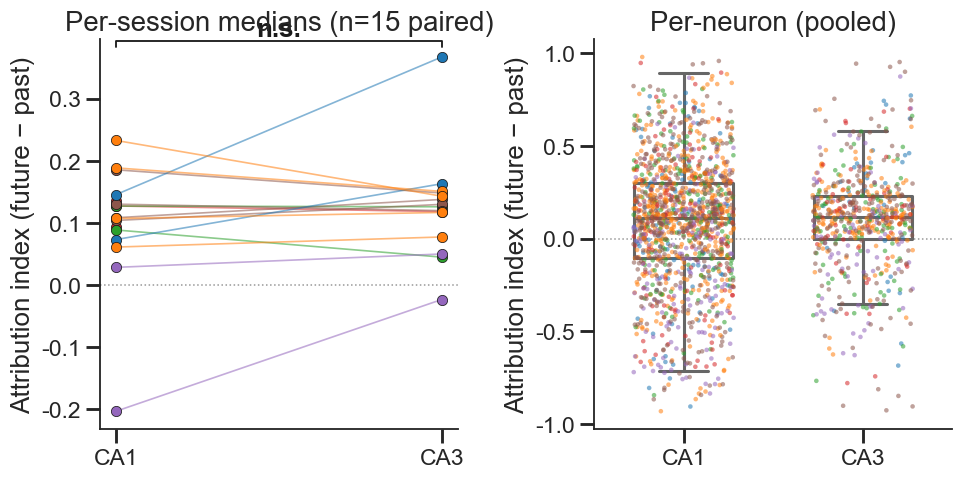

Attribution index (future − past) — CA1 vs CA3:
  neurons: CA1 n=1427 (median +0.110), CA3 n=610 (median +0.113)
  session medians: CA1 +0.108 vs CA3 +0.126 | paired Wilcoxon n=15, p=0.5614 n.s.
  prospective? (session medians vs 0): CA1 n=17 p=0.0026 **; CA3 n=15 p=0.0001 ***


In [599]:
# === Figure 4 (extra): attribution index (prospective coding) for CA1 vs CA3 cells ===
# Attribution index = clu_df['future_idx'], the scale-free future-minus-past position-
# attribution contrast (>0 prospective, <0 retrospective) from the fig4_attribution cell.
# Quantified CA1 vs CA3 at the SESSION level (nonparametric), matching the Fig 4 / ED Fig 8
# CA1/CA3 convention: aggregate per (session, subregion) over neurons (>= SUB_MIN_NEURONS),
# paired Wilcoxon across sessions present in both subregions, per-bat coloured points.
from scipy.stats import wilcoxon as _wilcoxon_ai
_MIN_N = globals().get('SUB_MIN_NEURONS', 10)

_ai = clu_df[clu_df['subregion'].isin(['CA1', 'CA3']) & clu_df['future_idx'].notna()].copy()
_ai['bat_str'] = _ai['session'].apply(parse_bat).astype(str)  # string bat id to match bat_palette() keys
# per-(session, subregion) median attribution over neurons; keep groups with a stable count
_ai_rows = []
for (sn, sr), grp in _ai.groupby(['session', 'subregion']):
    if len(grp) < _MIN_N:
        continue
    _ai_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                         attr_idx=float(grp['future_idx'].median()), n=len(grp)))
ai_sub_df = pd.DataFrame(_ai_rows)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw=dict(wspace=0.38))
# (A) session-level paired CA1 vs CA3 (one line per session, coloured by bat) + bracket
ph.paired_lines(axA, ai_sub_df, 'attr_idx', 'subregion', ['CA1', 'CA3'])
r_paired = ph.paired_session_test(ai_sub_df, 'attr_idx', 'subregion', 'CA1', 'CA3')  # med_a=CA1, med_b=CA3
ph.sig_bracket(axA, 0, 1, r_paired['p'], show_ns=True)
axA.axhline(0, color='0.6', ls=':', lw=1, zorder=0)  # 0 = balanced past/future
axA.set(ylabel='attribution index (future − past)', xlabel='',
        title=f'per-session medians (n={r_paired["n"]} paired)')
# (B) pooled neuron-level distribution by subregion, points coloured by bat
sns.boxplot(data=_ai, x='subregion', y='future_idx', order=['CA1', 'CA3'], ax=axB,
            showfliers=False, width=0.55, fill=False, color='0.4')
sns.stripplot(data=_ai, x='subregion', y='future_idx', order=['CA1', 'CA3'], hue='bat_str',
              palette=ph.bat_palette(), ax=axB, size=3, alpha=0.55, jitter=0.28, legend=False)
axB.axhline(0, color='0.6', ls=':', lw=1, zorder=0)
axB.set(ylabel='attribution index (future − past)', xlabel='', title='per-neuron (pooled)')
ph.save_fig(fig, 'fig4_attr_index_ca1_ca3'); plt.show()

# --- stats: paired CA1 vs CA3 (headline), plus one-sample (session medians vs 0) per subregion
#     to ask whether each subregion is significantly prospective/retrospective ---
def _vs0(sr):
    v = ai_sub_df.loc[ai_sub_df['subregion'] == sr, 'attr_idx'].to_numpy()
    if len(v) < 1 or np.all(v == 0):
        return len(v), np.nan
    return len(v), float(_wilcoxon_ai(v, alternative='two-sided').pvalue)


_ns = lambda p: ph.stars_for_p(p) or 'n.s.'
_neu_med = _ai.groupby('subregion')['future_idx'].median()
_n_ca1, _n_ca3 = int((_ai.subregion == 'CA1').sum()), int((_ai.subregion == 'CA3').sum())
n1, p1 = _vs0('CA1'); n3, p3 = _vs0('CA3')
print('Attribution index (future − past) — CA1 vs CA3:')
print(f'  neurons: CA1 n={_n_ca1} (median {_neu_med.get("CA1", float("nan")):+.3f}), '
      f'CA3 n={_n_ca3} (median {_neu_med.get("CA3", float("nan")):+.3f})')
print(f'  session medians: CA1 {r_paired["med_a"]:+.3f} vs CA3 {r_paired["med_b"]:+.3f} | '
      f'paired Wilcoxon n={r_paired["n"]}, p={r_paired["p"]:.4f} {_ns(r_paired["p"])}')
print(f'  prospective? (session medians vs 0): CA1 n={n1} p={p1:.4f} {_ns(p1)}; '
      f'CA3 n={n3} p={p3:.4f} {_ns(p3)}')


In [600]:
# === Figure 4 g–k data: MRM (R^2 / unique R^2) — replaces the (partial) Mantel analysis ===
# Multiple regression on distance matrices (MRM). For every session the non-flight rest noise-
# correlation (upper triangle, rank-z) is regressed on the three flight predictors — residual-
# readout cosine, rate-map correlation, symmetric coupling — and we report, per predictor:
#   * marginal R^2  -- predictor entered ALONE (simple rank R^2 of that similarity matrix)
#   * unique  R^2   -- semipartial: full 3-predictor model minus the model with that predictor
#                      dropped, i.e. its contribution "holding the other two fixed"
# Every R^2 also carries its OWN P and its own null mean, from a Freedman-Lane permutation test
# (nh.freedman_lane_r2): the reduced-model residuals are relabeled as a MATRIX (rows and columns
# jointly), so the exchangeable unit is the neuron and the pair-level dependence structure is
# preserved. For the marginal R^2 the reduced model is the intercept, so that null reduces to a
# plain Mantel relabeling. All vectors are rank-standardized (nh.zrank), so the MRM is the
# multiple-regression generalization of the Spearman Mantel. This is the COVARIATE-ONLY MRM
# (conditioning is on the three flight predictors; no probe/distance/FR nuisance regressors).
# CA1/CA3 rows repeat the joint MRM within each subregion (unique R^2 per predictor).
# Cached under ./out/fig4_cache/.
from scipy.stats import wilcoxon as _wilcoxon
from notebook_helpers import zrank as _zrank, ols_r2 as _ols_r2, freedman_lane_r2 as _fl_r2

MRM_MIN_PAIRS = 30
MRM_N_PERM = 2000    # neuron-relabeling permutations per (session, predictor, metric)
_MRM_PREDS = ['residual readout', 'rate map', 'coupling']


def _finite_node_subset(mats):
    """Neurons to keep so that EVERY surviving off-diagonal pair is finite in EVERY matrix.
    The permutation null relabels neurons, so non-finite pairs must be removed by dropping
    whole rows/columns rather than by masking individual pairs (as the pre-permutation version
    did). Greedy: repeatedly drop the neuron sitting in the most non-finite pairs."""
    B = np.ones(mats[0].shape, dtype=bool)
    for M in mats:
        B &= np.isfinite(M)
    np.fill_diagonal(B, True)
    keep = np.ones(len(B), dtype=bool)
    while keep.any():
        bad = (~B[np.ix_(keep, keep)]).sum(1)
        if bad.max() == 0:
            break
        keep[np.flatnonzero(keep)[int(np.argmax(bad))]] = False
    return keep


def _mrm_session_r2(y_mat, pred_mats, rng, metrics=('marginal', 'unique'),
                    n_perm=MRM_N_PERM, min_pairs=MRM_MIN_PAIRS):
    """Marginal and/or unique (semipartial) R^2 for each of the 3 flight predictors, each with
    its own Freedman-Lane P and the mean of its permutation null (intercept-only base; no
    nuisance). Takes the n x n matrices (the null permutes neurons, not pairs). Rank-z
    everything; None if too few pairs survive."""
    keep = _finite_node_subset([y_mat] + [pred_mats[k] for k in _MRM_PREDS])
    n = int(keep.sum())
    iu, ju = np.triu_indices(n, 1)
    if len(iu) < min_pairs:
        return None
    sl = np.ix_(keep, keep)
    y = _zrank(y_mat[sl][iu, ju])
    P = {k: _zrank(pred_mats[k][sl][iu, ju]) for k in _MRM_PREDS}
    one = np.ones((len(iu), 1))
    rec = dict(total=_ols_r2(y, np.column_stack([one] + [P[k] for k in _MRM_PREDS])),
               n_pairs=len(iu), n_units=n, n_units_all=int(len(keep)))
    for k in _MRM_PREDS:
        others = [P[m] for m in _MRM_PREDS if m != k]
        for metric in metrics:
            X = np.column_stack([one] + (others if metric == 'unique' else []) + [P[k]])
            r2, p_perm, null = _fl_r2(y, X, X.shape[1] - 1, rng, n_perm, n)
            rec[f'{metric}_{k}'] = r2
            rec[f'{metric}_{k}_p'] = p_perm
            rec[f'{metric}_{k}_null'] = float(np.mean(null))
    return rec


# The key hashes the REGRESSAND itself (not just the session list), so changing how the
# non-flight matrices are built -- e.g. raw vs sqrt counts -- invalidates the cache instead of
# silently returning R^2 computed against the previous version.
_mrm_r2_key = dict(
    kind='fig4_mrm_r2_covonly_perm_v2',
    joint=_ckpt_sig(JOINT_CKPT), coupling=_ckpt_sig(_COUP_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    nonflight=tuple((sn, _arr_hash(np.nan_to_num(C)))
                    for sn, C in sorted(nonflight_corr.items())),
    bin_width=float(bin_width), min_pairs=int(MRM_MIN_PAIRS), sub_floor=int(SUB_MIN_NEURONS),
    n_perm=int(MRM_N_PERM), seed=int(seed),
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_mrm_r2():
    _rng = np.random.default_rng(seed)
    main_rows, region_rows = [], []
    for sn in nonflight_corr:
        M = session_matrices(sn)
        if M is None or M['coupling'] is None or M['ratemap'] is None:
            continue
        rec = _mrm_session_r2(M['nonflight'],
                              {'residual readout': M['residual'],
                               'rate map': M['ratemap'],
                               'coupling': M['coupling']}, _rng)
        if rec is not None:
            for k in _MRM_PREDS:
                for metric in ('marginal', 'unique'):
                    main_rows.append(dict(session=sn, bat=parse_bat(sn), metric=metric,
                                          predictor=k, r2=rec[f'{metric}_{k}'],
                                          r2_null=rec[f'{metric}_{k}_null'],
                                          p_perm=rec[f'{metric}_{k}_p'],
                                          n_units=rec['n_units'],
                                          n_units_all=rec['n_units_all']))

        # --- CA1/CA3-restricted joint MRM (unique R^2 per predictor) ---
        grp = clu_df[clu_df['session'] == sn]
        for sr in ('CA1', 'CA3'):
            g = grp[grp['subregion'] == sr]
            if len(g) < SUB_MIN_NEURONS or sn not in session_coupling_sim:
                continue
            units = g['unit'].to_numpy()
            Wr = np.stack(g['readout_weight_residual'].values)
            rec = _mrm_session_r2(nonflight_corr[sn][np.ix_(units, units)],
                                  {'residual readout': Wr @ Wr.T,
                                   'rate map': ratemap_corr_matrix(session_rate_maps[sn][units]),
                                   'coupling': session_coupling_sim[sn][np.ix_(units, units)]},
                                  _rng, metrics=('unique',))
            if rec is None:
                continue
            for k in _MRM_PREDS:
                region_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                                        predictor=k, metric='unique', r2=rec[f'unique_{k}'],
                                        r2_null=rec[f'unique_{k}_null'],
                                        p_perm=rec[f'unique_{k}_p'],
                                        n_units=rec['n_units'], n_units_all=rec['n_units_all']))
    main = pd.DataFrame(main_rows)
    region = pd.DataFrame(region_rows)
    for df in (main, region):
        if len(df):
            df['predictor'] = pd.Categorical(df['predictor'], _MRM_PREDS, ordered=True)
    return dict(mrm_r2_main=main, mrm_r2_region=region)


_mrm_r2_blob = _fig4_cache('fig4_mrm_r2', _mrm_r2_key, _compute_mrm_r2)
mrm_r2_main = _mrm_r2_blob['mrm_r2_main']
mrm_r2_region = _mrm_r2_blob['mrm_r2_region']
_mrm_nu = (mrm_r2_main[mrm_r2_main['metric'] == 'unique']
           .drop_duplicates('session')[['n_units', 'n_units_all']].sum())
print(f'MRM R^2 ready: {mrm_r2_main["session"].nunique()} sessions (main), '
      f'{mrm_r2_region["session"].nunique()} sessions with CA1/CA3 breakdown; '
      f'{MRM_N_PERM} Freedman-Lane permutations per test '
      f'({_mrm_nu["n_units"]}/{_mrm_nu["n_units_all"]} neurons kept after dropping units '
      f'with non-finite pairs).')


def _perm_vs_null(_d, **_extra):
    """Population summary for one (metric, predictor) or (subregion, predictor) cell: every
    session's observed R^2 against the MEAN of its own permutation null (paired Wilcoxon
    across sessions), plus how many sessions clear their individual Freedman-Lane test."""
    _d = _d.sort_values('session')
    _obs, _nul = _d['r2'].to_numpy(), _d['r2_null'].to_numpy()
    _p = (float(_wilcoxon(_obs, _nul, alternative='two-sided').pvalue)
          if len(_obs) and np.any(_obs != _nul) else np.nan)
    return dict(**_extra, n=len(_obs), med_obs=float(np.median(_obs)),
                med_null=float(np.median(_nul)), p=_p,
                n_sess_p05=int((_d['p_perm'] < 0.05).sum()),
                med_p_perm=float(np.median(_d['p_perm'])))


# Printed here rather than in the fig4_merged stats block so the permutation inference can be
# inspected without re-rendering the whole figure.
print('\nFig 4 g/h - MRM R^2 vs its own permutation null (per-session observed vs null mean, '
      'paired Wilcoxon; n_sess_p05 = sessions with individual Freedman-Lane P < 0.05):')
ph.p_table([_perm_vs_null(mrm_r2_main[(mrm_r2_main['metric'] == _metric) &
                                      (mrm_r2_main['predictor'] == _pred)],
                          metric=_metric, predictor=_pred)
            for _metric in ('marginal', 'unique') for _pred in _MRM_PREDS])
print('\nFig 4k - CA1/CA3 unique R^2 vs its own permutation null (per-session observed vs '
      'null mean, paired Wilcoxon):')
ph.p_table([_perm_vs_null(mrm_r2_region[(mrm_r2_region['subregion'] == _sr) &
                                        (mrm_r2_region['predictor'] == _pred)],
                          subregion=_sr, predictor=_pred)
            for _sr in ('CA1', 'CA3') for _pred in _MRM_PREDS])

# --- Sleep counterpart (Fig 4 sleep panel): the same MRM against SLEEP correlations ---
# Identical machinery, with the REGRESSAND swapped from the non-flight WAKING rest matrix to the
# SLEEP (Dataset_0) matrix built by the UnitMatch cell. Only the sleep-matched sessions qualify,
# and within them only the neurons matched across the two recordings: unmatched rows/columns of
# the sleep matrix are NaN, so _finite_node_subset drops them automatically. The other three
# matrices come from session_matrices() in the same clu_df row order, so positional slicing keeps
# the CA1/CA3-restricted versions aligned (and is exactly the submatrix the waking loop rebuilds).
#
# Only n = 4 sessions survive the matching, so every session-level test on these values is
# PARAMETRIC (paired t-tests). The signed-rank test used for the waking panels cannot reach
# P < 0.05 two-sided at n = 4 -- its smallest attainable P is 0.125 -- so it would render every
# comparison vacuously n.s. regardless of effect size.
from scipy.stats import ttest_rel as _ttest_rel


def _paired_session_t(df, value_col, cond_col, cond_a, cond_b, session_col='session'):
    """Paired t-test on per-session values -- parametric counterpart of ph.paired_session_test."""
    piv = (df.groupby([session_col, cond_col], observed=True)[value_col].mean()
             .unstack(cond_col))
    if cond_a not in piv or cond_b not in piv:
        return dict(n=0, p=np.nan, t=np.nan, mean_a=np.nan, mean_b=np.nan)
    pair = piv[[cond_a, cond_b]].dropna()
    a, b = pair[cond_a].to_numpy(), pair[cond_b].to_numpy()
    if len(a) < 2 or np.allclose(a, b):
        return dict(n=len(a), p=np.nan, t=np.nan,
                    mean_a=float(np.mean(a)) if len(a) else np.nan,
                    mean_b=float(np.mean(b)) if len(b) else np.nan)
    _r = _ttest_rel(a, b)
    return dict(n=len(a), p=float(_r.pvalue), t=float(_r.statistic),
                mean_a=float(a.mean()), mean_b=float(b.mean()))


def _perm_vs_null_t(_d, **_extra):
    """Parametric counterpart of _perm_vs_null: observed R^2 vs the mean of its own
    Freedman-Lane null, paired t-test across sessions."""
    _d = _d.sort_values('session')
    _obs, _nul = _d['r2'].to_numpy(), _d['r2_null'].to_numpy()
    _p = (float(_ttest_rel(_obs, _nul).pvalue)
          if len(_obs) >= 2 and not np.allclose(_obs, _nul) else np.nan)
    return dict(**_extra, n=len(_obs), mean_obs=float(np.mean(_obs)) if len(_obs) else np.nan,
                mean_null=float(np.mean(_nul)) if len(_nul) else np.nan, p=_p,
                n_sess_p05=int((_d['p_perm'] < 0.05).sum()))


_sleep_mrm_key = dict(
    kind='fig4_mrm_r2_sleep_v1',
    joint=_ckpt_sig(JOINT_CKPT), coupling=_ckpt_sig(_COUP_CKPT),
    sessions=sorted(session_sleep_corr.keys()),
    sleep=tuple((sn, _arr_hash(np.nan_to_num(C))) for sn, C in sorted(session_sleep_corr.items())),
    bin_width=float(bin_width), min_pairs=int(MRM_MIN_PAIRS), sub_floor=int(SUB_MIN_NEURONS),
    n_perm=int(MRM_N_PERM), seed=int(seed),
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_sleep_mrm():
    _rng = np.random.default_rng(seed)
    main_rows, region_rows = [], []
    for sn in sorted(session_sleep_corr):
        M = session_matrices(sn)
        if M is None or M.get('sleep') is None or M['coupling'] is None or M['ratemap'] is None:
            continue
        preds = {'residual readout': M['residual'], 'rate map': M['ratemap'],
                 'coupling': M['coupling']}
        rec = _mrm_session_r2(M['sleep'], preds, _rng)
        if rec is not None:
            for k in _MRM_PREDS:
                for metric in ('marginal', 'unique'):
                    main_rows.append(dict(session=sn, bat=parse_bat(sn), metric=metric,
                                          predictor=k, r2=rec[f'{metric}_{k}'],
                                          r2_null=rec[f'{metric}_{k}_null'],
                                          p_perm=rec[f'{metric}_{k}_p'],
                                          n_units=rec['n_units'],
                                          n_units_all=rec['n_units_all']))

        # --- CA1/CA3-restricted joint MRM (unique R^2 per predictor); not plotted, printed below ---
        _sr_lab = M['grp']['subregion'].to_numpy()
        _matched = np.isfinite(np.diag(M['sleep']))
        for sr in ('CA1', 'CA3'):
            loc = np.flatnonzero((_sr_lab == sr) & _matched)
            if len(loc) < SUB_MIN_NEURONS:
                continue
            sl = np.ix_(loc, loc)
            rec = _mrm_session_r2(M['sleep'][sl], {k: v[sl] for k, v in preds.items()},
                                  _rng, metrics=('unique',))
            if rec is None:
                continue
            for k in _MRM_PREDS:
                region_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                                        predictor=k, metric='unique', r2=rec[f'unique_{k}'],
                                        r2_null=rec[f'unique_{k}_null'],
                                        p_perm=rec[f'unique_{k}_p'],
                                        n_units=rec['n_units'], n_units_all=rec['n_units_all']))
    main, region = pd.DataFrame(main_rows), pd.DataFrame(region_rows)
    for df in (main, region):
        if len(df):
            df['predictor'] = pd.Categorical(df['predictor'], _MRM_PREDS, ordered=True)
    return dict(sleep_mrm_main=main, sleep_mrm_region=region)


_sleep_mrm_blob = _fig4_cache('fig4_mrm_r2_sleep', _sleep_mrm_key, _compute_sleep_mrm)
sleep_mrm_main = _sleep_mrm_blob['sleep_mrm_main']
sleep_mrm_region = _sleep_mrm_blob['sleep_mrm_region']
_sl_nu = (sleep_mrm_main[sleep_mrm_main['metric'] == 'unique']
          .drop_duplicates('session')[['n_units', 'n_units_all']].sum())
print(f'\nSleep MRM ready: {sleep_mrm_main["session"].nunique()} sleep-matched sessions '
      f'({_sl_nu["n_units"]}/{_sl_nu["n_units_all"]} neurons kept after UnitMatch + finite-pair '
      f'filtering), {sleep_mrm_region["session"].nunique()} with a CA1/CA3 breakdown.')
print('\nSleep MRM - R^2 vs its own permutation null (per-session observed vs null mean, '
      'paired t-test; n_sess_p05 = sessions with individual Freedman-Lane P < 0.05):')
ph.p_table([_perm_vs_null_t(sleep_mrm_main[(sleep_mrm_main['metric'] == _metric) &
                                           (sleep_mrm_main['predictor'] == _pred)],
                            metric=_metric, predictor=_pred)
            for _metric in ('marginal', 'unique') for _pred in _MRM_PREDS])
print('\nSleep MRM - CA1/CA3 unique R^2 (not plotted): pairwise predictors, then vs their own '
      'permutation null (paired t-tests):')
ph.p_table([dict(subregion=_sr, comparison=f'{_MRM_PREDS[_a]} vs {_MRM_PREDS[_b]}',
                 **_paired_session_t(sleep_mrm_region[sleep_mrm_region['subregion'] == _sr],
                                     'r2', 'predictor', _MRM_PREDS[_a], _MRM_PREDS[_b]))
            for _sr in ('CA1', 'CA3') for _a, _b in [(0, 1), (1, 2), (0, 2)]])
ph.p_table([_perm_vs_null_t(sleep_mrm_region[(sleep_mrm_region['subregion'] == _sr) &
                                             (sleep_mrm_region['predictor'] == _pred)],
                            subregion=_sr, predictor=_pred)
            for _sr in ('CA1', 'CA3') for _pred in _MRM_PREDS])


  [cache hit] fig4_mrm_r2
MRM R^2 ready: 17 sessions (main), 17 sessions with CA1/CA3 breakdown; 2000 Freedman-Lane permutations per test (2105/2147 neurons kept after dropping units with non-finite pairs).

Fig 4 g/h - MRM R^2 vs its own permutation null (per-session observed vs null mean, paired Wilcoxon; n_sess_p05 = sessions with individual Freedman-Lane P < 0.05):
  metric        predictor  n  med_obs  med_null         p  n_sess_p05  med_p_perm stars         P
marginal residual readout 17   0.0338 0.0004034 1.526e-05          17   0.0004998   *** P < 0.001
marginal         rate map 17   0.0172  0.000274 1.526e-05          15   0.0004998   *** P < 0.001
marginal         coupling 17    0.022 0.0003758 3.052e-05          16   0.0004998   *** P < 0.001
  unique residual readout 17   0.0146 0.0004263 1.526e-05          17   0.0004998   *** P < 0.001
  unique         rate map 17 0.006548 0.0002722 0.0002899          14   0.0004998   *** P < 0.001
  unique         coupling 17 0.006174 0.

,subregion,predictor,n,mean_obs,mean_null,p,n_sess_p05,stars,P
0,CA1,residual readout,4,0.009423,0.002418,0.200412,1,,P = 0.200
1,CA1,rate map,4,0.002160,0.002443,0.870811,1,,P = 0.871
2,CA1,coupling,4,0.001188,0.002807,0.207470,0,,P = 0.207
3,CA3,residual readout,3,0.014863,0.009386,0.592620,1,,P = 0.593
4,CA3,rate map,3,0.043842,0.009924,0.312272,1,,P = 0.312
5,CA3,coupling,3,0.002572,0.010286,0.099468,0,,P = 0.099


/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/seaborn/categorical.py:3399: UserWarning:

23.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.



Fig 4f - Dataset_3_29959_240403: non-flight vs sleep FR-corr agreement r=0.360 over 2278 pairs (should be near 1)


/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helper

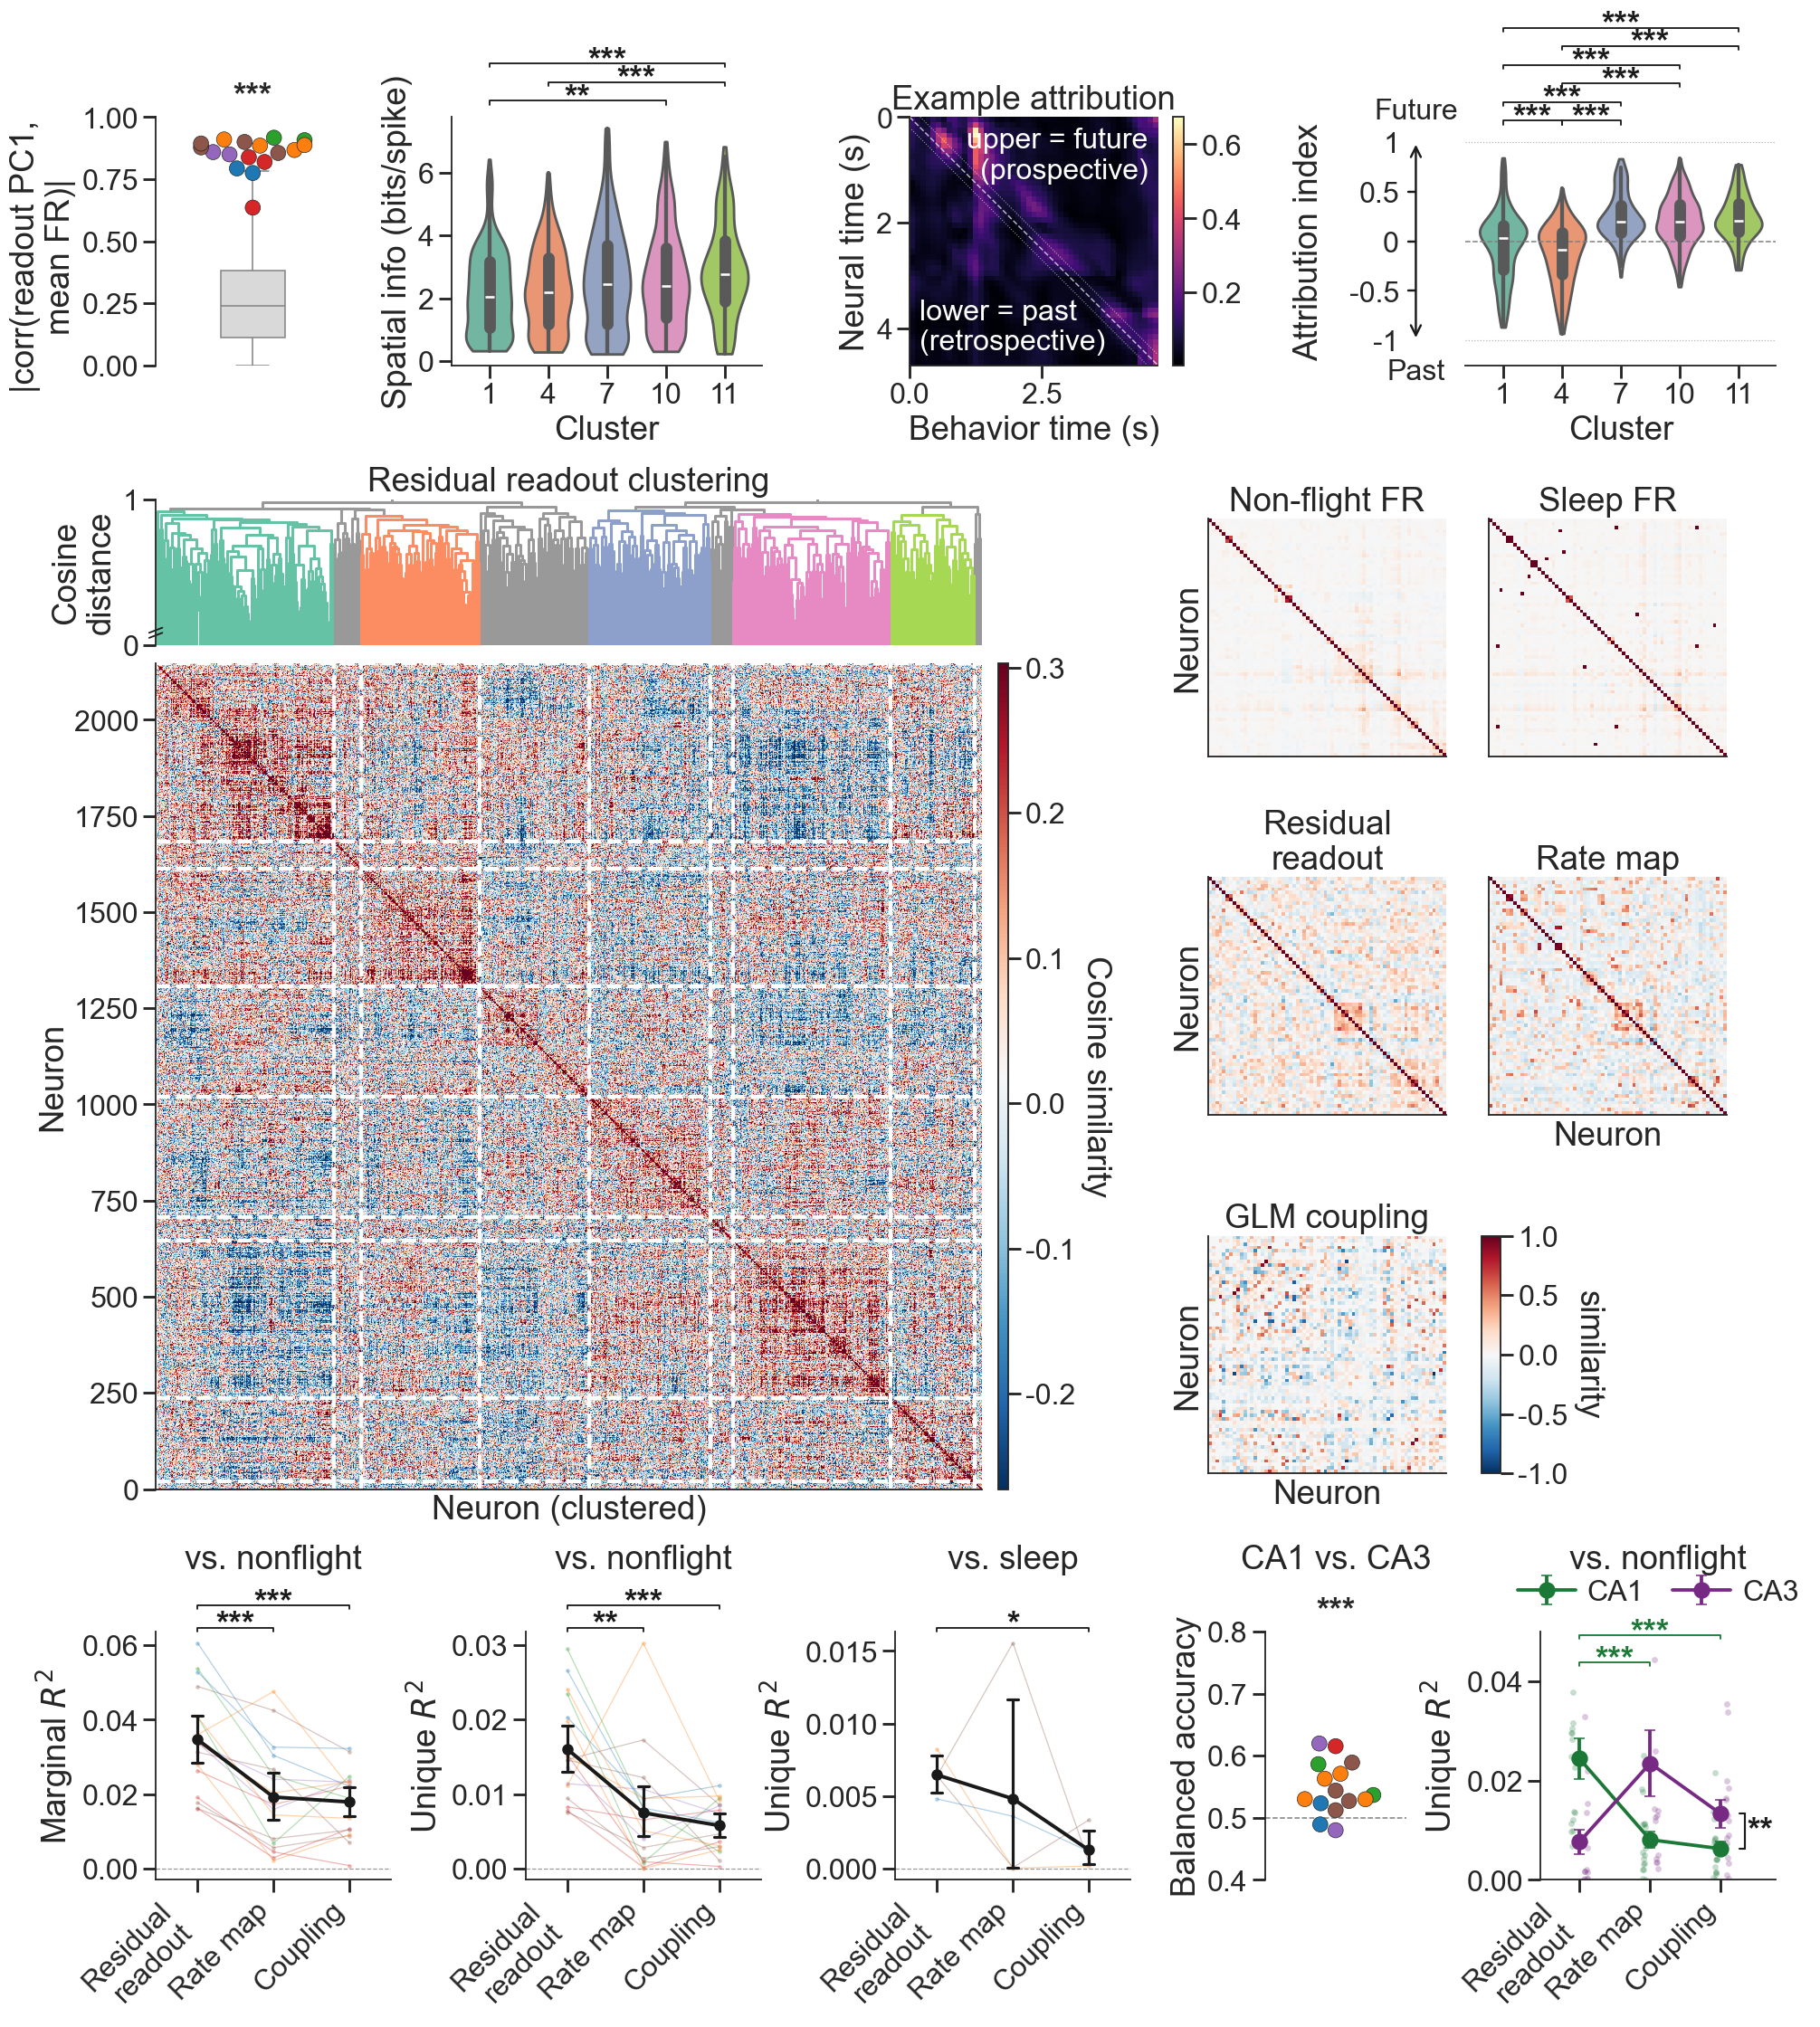


Fig 4a - |corr(PC1, mean FR)| vs random-direction null (per session, two-sided Wilcoxon):
                 comparison  n  median  median_null         p stars         P
PC1 corr vs random-dir null 17  0.8672       0.2405 1.526e-05   *** P < 0.001

Fig 4 g/h - MRM (covariate) marginal & unique R^2, residual readout vs competitors (per session):
                    comparison  n         p  med_a  med_b stars         P
marginal: residual vs rate map 17 0.0002136 0.0338 0.0172   *** P < 0.001
marginal: residual vs coupling 17 1.526e-05 0.0338  0.022   *** P < 0.001
                  comparison  n         p  med_a    med_b stars         P
unique: residual vs rate map 17  0.003845 0.0146 0.006548    ** P = 0.004
unique: residual vs coupling 17 1.526e-05 0.0146 0.006174   *** P < 0.001

Fig 4i (sleep panel) - unique R^2 against SLEEP correlations, residual readout vs competitors (per-session PAIRED t-test; these ARE the plotted brackets):
                          comparison  n       p      t

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:300: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helper

,comparison,n_a,n_b,p,stars,P
0,cluster 4 vs 7,308,315,0.000000e+00,***,P < 0.001
1,cluster 4 vs 10,308,410,3.015706e-40,***,P < 0.001
2,cluster 4 vs 11,308,217,3.510364e-36,***,P < 0.001
3,cluster 1 vs 7,464,315,2.313509e-30,***,P < 0.001
4,cluster 1 vs 10,464,410,9.553949e-23,***,P < 0.001
5,cluster 1 vs 11,464,217,3.415392e-21,***,P < 0.001
6,cluster 1 vs 4,464,308,7.092983e-05,***,P < 0.001
7,cluster 7 vs 10,315,410,5.369082e-02,,P = 0.054
8,cluster 10 vs 11,410,217,4.769975e-01,,P = 0.477
9,cluster 7 vs 11,315,217,4.769975e-01,,P = 0.477


In [601]:
# === Figure 4 (a-k) on a single canvas ===
# Layout (three bands):
#   row 1 : [ a | c | d | e ]   a=PC1/FR (narrow); c=spatial info; d=attribution example; e=attribution index
#   row 2 : [ b | f ]   b=dendrogram + cosine-similarity square (major-cluster boundaries dashed white);
#           f = 5 similarity matrices in a 3x2 grid (+cbar), to the right of b
#   row 3 : [ g=marginal R^2 | h=unique R^2 vs non-flight | i=unique R^2 vs sleep |
#             j=CA1-vs-CA3 decoding (narrow) | k=predictor x subregion interaction ]
# Clustering (Z, order, sim_ord, Wr_ord, clus_ord, N, D, XSPAN, CLUSTER_ORDER, CLUSTER_PALETTE,
# CLUSTER_GREY, _dendro_link_color) comes from the fig4_cluster cell; the SVM stats (g_df)
# from fig4_stats; the MRM R^2 (mrm_r2_main, mrm_r2_region) from the fig4_mrm_r2 cell; the attribution
# (attr_ex_matrix, attr_ex_ext, attr_excl_s, clu_df['future_idx']) from the fig4_attribution cell.
from itertools import combinations
from sklearn.decomposition import PCA as _PCA
from scipy.spatial.distance import squareform
from scipy.stats import kruskal as _kw, mannwhitneyu as _mwu, wilcoxon as _wil, f as _sp_f

FS = dict(title=24, label=24, tick=21, star=24)   # +2 pt across the board
plt.rcParams['mathtext.fontset'] = 'dejavusans'   # Arial-like math font (matches body text)
PRED_ORDER = ['residual readout', 'rate map', 'coupling']


def _star_only(ax, p, x=0, yfrac=1.02):
    """Significance asterisk (no bracket) near the top of the data."""
    s = ph.stars_for_p(p)
    if s:
        lo, hi = ax.get_ylim()
        ax.text(x, lo + yfrac * (hi - lo), s, ha='center', va='bottom',
                fontsize=FS['star'], fontweight='bold')


def _pairwise_cluster_brackets(ax, df, val_col, order, *, base=1.05, step=0.075):
    """Holm-corrected pairwise Mann-Whitney across clusters. Significant pairs are drawn as
    ph.sig_bracket, packed onto as few horizontal levels as possible: a bracket reuses a level
    only if its x-span does not overlap any bracket already placed there (else it goes higher)."""
    pv = {}
    for a, b in combinations(range(len(order)), 2):
        xa = df.loc[df['cluster'] == order[a], val_col].dropna().values
        xb = df.loc[df['cluster'] == order[b], val_col].dropna().values
        pv[(a, b)] = (_mwu(xa, xb, alternative='two-sided').pvalue
                      if len(xa) >= 3 and len(xb) >= 3 else np.nan)
    real = sorted([(k, p) for k, p in pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
    run, adj = 0.0, {}
    for i, (k, p) in enumerate(real):
        run = max(run, (len(real) - i) * p)
        adj[k] = min(run, 1.0)
    sig = sorted([k for k in adj if adj[k] < 0.05], key=lambda k: (k[1] - k[0], k))
    levels = []                                        # each entry = list of (a, b) spans on that line
    for (a, b) in sig:
        lvl = next((i for i, spans in enumerate(levels)
                    if all(b <= s or a >= e for (s, e) in spans)), None)   # touching brackets (shared endpoint) share a level -> side by side
        if lvl is None:
            levels.append([(a, b)]); lvl = len(levels) - 1
        else:
            levels[lvl].append((a, b))
        ph.sig_bracket(ax, a, b, adj[(a, b)], base=base + lvl * step, star_gap=-0.05, fontsize=FS['star'])   # tight star + compact stack
    return adj


def _cluster_dist(ax, df, val_col, ylabel, *, bracket_base=1.02):
    """Identical per-cluster box + individual-neuron dots + pairwise brackets style,
    shared by the spatial-info (c) and future-past (e) panels."""
    ph.cat_violin(ax, df, 'cluster', val_col, CLUSTER_ORDER, CLUSTER_PALETTE, trim_outliers=True)
    _pairwise_cluster_brackets(ax, df, val_col, CLUSTER_ORDER, base=bracket_base)
    ax.set_xlabel('cluster', fontsize=FS['label'])
    ax.set_ylabel(ylabel, fontsize=FS['label'])
    ax.tick_params(labelsize=FS['tick'])


fig4 = plt.figure(figsize=(21, 23))
outer = fig4.add_gridspec(5, 1, height_ratios=[1, 0.16, 4, 0.18, 1], hspace=0.15)   # row1 | spacer | row2 | spacer | row3

# ---- row 1: a (PC1/FR) | c (spatial info) | d (attribution example) | e (attribution index), horizontal ----
gs_top = outer[0].subgridspec(1, 5, width_ratios=[1.0, 1.6, 1.75, 0.3, 1.6], wspace=0.42)  # col 3 = spacer -> extra gap before e
ax_a = fig4.add_subplot(gs_top[0, 0])
ax_c = fig4.add_subplot(gs_top[0, 1])          # c: spatial information
ax_d = fig4.add_subplot(gs_top[0, 2])          # d: example attribution matrix
ax_e = fig4.add_subplot(gs_top[0, 4])          # e: future-past attribution index

# ---- row 2: b (dendrogram + square cos-sim) on the left | f (5 similarity matrices in a 3x2 grid) on the right ----
gs_r2 = outer[2].subgridspec(1, 4, width_ratios=[11.0, 2.5, 6.9, 0.4], wspace=0.05)        # B (left-aligned) | wider gap | F 3x2 (+cbar) | margin
gs_b = gs_r2[0, 0].subgridspec(2, 1, height_ratios=[0.28, 1.6], hspace=0.03)              # dendro + cos-sim (square via box_aspect), left-aligned
ax_b_dendro = fig4.add_subplot(gs_b[0])
ax_b_sim = fig4.add_subplot(gs_b[1])
gs_f = gs_r2[0, 2].subgridspec(3, 2, hspace=0.3, wspace=0.18)                             # 5 matrices in a 3x2 grid (bottom-right cell holds the cbar inset)
ax_f = [fig4.add_subplot(gs_f[_r, _cc]) for _r, _cc in [(0, 0), (0, 1), (1, 0), (1, 1), (2, 0)]]   # panel f is a list of 5 axes

# ---- row 3: g=marginal R^2 | h=unique R^2 (non-flight) | i=unique R^2 (sleep) | j=CA1-vs-CA3 decoding (narrow) | k=predictor x subregion interaction ----
gs_bot = outer[4].subgridspec(1, 5, width_ratios=[1.0, 1.0, 1.0, 0.6, 1.0], wspace=0.62)
ax_g = fig4.add_subplot(gs_bot[0, 0])
ax_h = fig4.add_subplot(gs_bot[0, 1])
ax_i = fig4.add_subplot(gs_bot[0, 2])   # same unique R^2, regressand = SLEEP correlations
ax_j = fig4.add_subplot(gs_bot[0, 3])          # balanced-accuracy CA1-vs-CA3 decoding
ax_k = fig4.add_subplot(gs_bot[0, 4])        # predictor x subregion interaction
_LOWER_TITLES = []      # (ax, text) for titles whose lower-case 'vs.' must survive capitalisation

# --- a: PC1 of readout weights correlates with mean firing rate (vs a random-direction null) ---
_rec = []
for sn, grp in clu_df.groupby('session'):
    W = np.stack(grp['readout_weight'].values)
    if len(grp) < 4:
        continue
    pc1 = _PCA(n_components=1, random_state=seed).fit_transform(W).ravel()
    r = np.corrcoef(pc1, grp['mean_fr'].values)[0, 1]
    _rec.append(dict(session=sn, bat=parse_bat(sn), r=abs(r)))
pc1_fr_df = pd.DataFrame(_rec)
# grey null boxplot: |corr(mean FR, 100 random readout-space directions)| per session
_rng_a = np.random.default_rng(seed)
_null_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wa = np.stack(grp['readout_weight'].values); fra = grp['mean_fr'].values
    dirs = _rng_a.standard_normal((100, Wa.shape[1]))
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    proj = Wa @ dirs.T                                        # (K, 100)
    for _kk in range(dirs.shape[0]):
        if proj[:, _kk].std() > 0:
            _null_rows.append(dict(session=sn, r=abs(np.corrcoef(proj[:, _kk], fra)[0, 1])))
null_a_df = pd.DataFrame(_null_rows)
_null_med = null_a_df.groupby('session')['r'].median()
_pc1_ser = pc1_fr_df.set_index('session')['r']
_common = _pc1_ser.index.intersection(_null_med.index)
_p_a = (_wil(_pc1_ser.loc[_common].values - _null_med.loc[_common].values, alternative='two-sided').pvalue
        if len(_common) >= 3 else np.nan)
sns.boxplot(y=null_a_df['r'], color='0.85', width=0.5, showfliers=False, ax=ax_a, zorder=0)
sns.swarmplot(data=pc1_fr_df, y='r', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(pc1_fr_df['bat'])],
              size=11, edgecolor='k', linewidth=0.4, ax=ax_a, legend=False, zorder=3)
ax_a.set(xlabel='', xticks=[], xlim=(-0.75, 0.75))
ax_a.set_ylabel('|corr(readout PC1,\nmean FR)|', fontsize=FS['label'], y=0.44)
ax_a.set_ylim(0, 1)
ax_a.tick_params(labelsize=FS['tick'])
ax_a.spines['bottom'].set_visible(False)
_star_only(ax_a, _p_a)                                        # PC1 > random-direction null (bat legend is in Fig 1a)

# --- j: residual readouts predict CA1 vs CA3 membership (per-session SVM swarm; bottom row) ---
# One balanced-accuracy point per session (coloured by bat); chance = 0.5 (dashed).
# Computed in fig4_stats.
if len(g_df):
    sns.swarmplot(data=g_df, y='bal_acc', hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in bats if b in set(g_df['bat'])], size=11,
                  edgecolor='k', linewidth=0.4, ax=ax_j, legend=False)
    ax_j.axhline(0.5, color='0.5', ls='--', lw=1, zorder=0)   # chance line
    _res_j = ph.onesample_session_test(g_df, 'bal_acc', popmean=0.5)
    ax_j.set(xlim=(-0.75, 0.75), xticks=[], ylim=(0.4, 0.8))
    _star_only(ax_j, _res_j['p'])
else:                                                          # no session has both regions
    _res_j = dict(p=np.nan, n=0)
    ax_j.set_title('(no dual-region session)', fontsize=FS['label'])
ax_j.set_ylabel('Balanced accuracy', fontsize=FS['label'])
ax_j.set_title('CA1 vs. CA3', fontsize=FS['title'], y=1.22)     # row-3 titles share this height
_LOWER_TITLES.append((ax_j, 'CA1 vs. CA3'))
ax_j.tick_params(labelsize=FS['tick'])
ax_j.spines['bottom'].set_visible(False)

# --- b: residual-readout clustering (dendrogram / cosine similarity / weights, stacked) ---
dendrogram(Z, ax=ax_b_dendro, no_labels=True, link_color_func=_dendro_link_color)
ax_b_dendro.set(xlim=(0, XSPAN), ylim=(0.5, 1.0), xticks=[])
ax_b_dendro.set_yticks([0.5, 1.0]); ax_b_dendro.set_yticklabels(['0', '1'])   # 0.5 relabelled 0 (axis break)
ax_b_dendro.set_ylabel('cosine\ndistance', fontsize=FS['label'])
ax_b_dendro.set_title('Residual readout clustering', fontsize=FS['title'])
ax_b_dendro.tick_params(labelsize=FS['tick'])
for s in ('top', 'right', 'bottom'):
    ax_b_dendro.spines[s].set_visible(False)
_bk = dict(transform=ax_b_dendro.transAxes, color='k', clip_on=False, lw=1.2)   # axis-break marks (bottom)
ax_b_dendro.plot([-0.008, 0.008], [0.05, 0.085], **_bk)
ax_b_dendro.plot([-0.008, 0.008], [0.085, 0.12], **_bk)
# color scale constrained to the 2.5-97.5 percentiles of the OFF-DIAGONAL cosine
# similarities (the diagonal self-similarity is a trivial 1.0 that would clamp the scale)
_cos_off = sim_ord[~np.eye(sim_ord.shape[0], dtype=bool)]
_cos_lo, _cos_hi = np.nanpercentile(_cos_off, [2.5, 97.5])
im_b = ax_b_sim.imshow(sim_ord, cmap='RdBu_r', vmin=_cos_lo, vmax=_cos_hi, aspect='auto',
                    interpolation='nearest', extent=(0, XSPAN, 0, N), origin='upper')   # diagonal TL->BR
ax_b_sim.set(xlim=(0, XSPAN), xticks=[])
ax_b_sim.set_xlabel('neuron (clustered)', fontsize=FS['label'])
ax_b_sim.set_ylabel('neuron', fontsize=FS['label'])
ax_b_sim.tick_params(labelsize=FS['tick'])
ax_b_sim.set_box_aspect(1)                                     # force the cosine-similarity matrix square
# dashed white lines at the boundaries between the major (included) neuron clusters, along both axes
_maj_blocks = sorted((int(np.where(clus_ord == _c)[0].min()), int(np.where(clus_ord == _c)[0].max()))
                     for _c in CLUSTER_ORDER if (clus_ord == _c).any())
_maj_edges = sorted({_e for (_mn, _mx) in _maj_blocks for _e in (_mn / N, (_mx + 1) / N)})  # both ends of each major cluster
for _fb in _maj_edges:
    ax_b_sim.plot([_fb, _fb], [0, 1], transform=ax_b_sim.transAxes, color='w', ls='--', lw=2.8)          # vertical
    ax_b_sim.plot([0, 1], [1 - _fb, 1 - _fb], transform=ax_b_sim.transAxes, color='w', ls='--', lw=2.8)  # horizontal (origin='upper')
_cb_b = fig4.colorbar(im_b, cax=ax_b_sim.inset_axes([1.02, 0.0, 0.012, 1.0]))   # offset further right
_cb_b.set_label('Cosine similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cb_b.ax.tick_params(labelsize=FS['tick'])

# --- f: example sleep-matched session — 5 similarity matrices, common (non-flight) order ---
# Restrict to neurons matched to the sleep (Dataset_0) session so Non-flight FR and Sleep FR
# are on IDENTICAL neurons/order (they should be near-indistinguishable). All five share the
# [-1, 1] scale, sorted by the non-flight-rest clustering; a single "similarity" colourbar.


def _matched_idx(sn):
    M = session_matrices(sn)
    if M is None or M.get('sleep') is None:
        return None
    good = np.isfinite(np.diag(M['sleep']))
    return np.where(good)[0] if good.sum() >= 3 else None


_c_cand = [(s, _matched_idx(s)) for s in session_sleep_corr]
_c_cand = [(s, idx) for s, idx in _c_cand if idx is not None]
f_last_im = None
if _c_cand:
    ex_session, ex_idx = max(_c_cand, key=lambda t: len(t[1]))
    Mc = session_matrices(ex_session)

    def _sub(m):
        return None if m is None else m[np.ix_(ex_idx, ex_idx)]
    nf_c, sl_c = _sub(Mc['nonflight']), _sub(Mc['sleep'])
    dmat = 1 - np.abs(np.nan_to_num(nf_c, nan=0.0)); np.fill_diagonal(dmat, 0.0)
    order_c = (dendrogram(linkage(squareform(dmat, checks=False), method='average'),
                          no_plot=True)['leaves'] if len(ex_idx) >= 2 else list(range(len(ex_idx))))
    cmats = [('Non-flight FR', nf_c), ('Sleep FR', sl_c), ('Residual\nreadout', _sub(Mc['residual'])),
             ('Rate map', _sub(Mc['ratemap'])), ('GLM coupling', _sub(Mc['coupling']))]
    for _fi, (ax, (name, mat)) in enumerate(zip(ax_f, cmats)):   # 3x2 row-major: Non-flight Sleep / Residual Rate / GLM -
        if mat is None:
            ax.axis('off'); ax.set_title(f'{name}\n(unavailable)', fontsize=FS['label']); continue
        Mo = mat[np.ix_(order_c, order_c)]
        if name == 'GLM coupling':                      # normalise coupling to [-1, 1]
            _s = np.nanmax(np.abs(Mo)) or 1.0
            Mo = Mo / _s
        f_last_im = ax.imshow(Mo, cmap='RdBu_r', vmin=-1, vmax=1, aspect='equal',
                              interpolation='nearest')
        ax.set(xticks=[], yticks=[]); ax.set_box_aspect(1)
        ax.set_title(name, fontsize=FS['label'])
        if _fi in (0, 2, 4):                            # left column -> "Neuron" ylabel
            ax.set_ylabel('Neuron', fontsize=FS['label'])
        if _fi in (3, 4):                               # bottom matrix of each column -> "Neuron" xlabel
            ax.set_xlabel('Neuron', fontsize=FS['label'])
    if f_last_im is not None:                           # single shared colourbar, labelled "similarity"
        cax_f = ax_f[4].inset_axes([1.15, 0.0, 0.08, 1.0])                    # vertical cbar next to GLM coupling
        _cb_f = fig4.colorbar(f_last_im, cax=cax_f)
        _cb_f.set_label('similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cb_f.ax.tick_params(labelsize=FS['tick'])
    _iu = np.triu_indices(len(ex_idx), 1)
    _a, _b = nf_c[np.ix_(order_c, order_c)][_iu], sl_c[np.ix_(order_c, order_c)][_iu]
    _ok = np.isfinite(_a) & np.isfinite(_b)
    _rc = np.corrcoef(_a[_ok], _b[_ok])[0, 1] if _ok.sum() > 2 else np.nan
    print(f'Fig 4f - {ex_session}: non-flight vs sleep FR-corr agreement r={_rc:.3f} '
          f'over {int(_ok.sum())} pairs (should be near 1)')
else:
    for ax in ax_f:
        ax.axis('off')
    ex_session = None
    print('Fig 4f - no sleep-matched session available')

# --- g/h/i: MRM vs variables — marginal R^2 (g) + unique R^2 against non-flight rest (h) and
# against sleep (i), bottom row ---
# Faint per-session lines with small dots across the three flight predictors (coloured by bat,
# the same BAT_PALETTE in all three so a bat keeps its colour between the non-flight and sleep
# panels), overlaid with the across-session mean +/- 95% CI in black -- i.e. the same
# ph.paired_lineplot style as Fig 1's session panels, with the residual-readout reference
# bracketed against each competitor.
# marginal = predictor entered alone; unique = its semipartial in the joint 3-predictor model.
# The two waking panels use the session-level paired Wilcoxon; the sleep panel uses a paired
# t-test, since only n = 4 sessions survive the UnitMatch sleep pairing and the signed-rank test
# cannot reach P < 0.05 two-sided there (smallest attainable P = 0.125). Titles name the
# REGRESSAND each R^2 is computed against; they are collected in _LOWER_TITLES and re-applied
# after ph.capitalize_labels so the leading 'vs.' stays lower-case in the body font.
_mrm_xlabels = ['Residual\nreadout', 'rate map', 'coupling']
for _ax, _src, _metric, _ylab, _title, _test in [
        (ax_g, mrm_r2_main, 'marginal', 'Marginal $R^2$', 'vs. nonflight',
         ph.paired_session_test),
        (ax_h, mrm_r2_main, 'unique', 'Unique $R^2$', 'vs. nonflight',
         ph.paired_session_test),
        (ax_i, sleep_mrm_main, 'unique', 'Unique $R^2$', 'vs. sleep',
         _paired_session_t)]:
    _sub = _src[_src['metric'] == _metric]
    ph.paired_lineplot(_ax, _sub, 'predictor', 'r2', PRED_ORDER, palette=BAT_PALETTE, set_xticklabels=False)
    _ax.axhline(0, color='0.6', ls='--', lw=0.8)
    _ax.set(xlabel='')
    _ax.set_ylabel(_ylab, fontsize=FS['label'])
    _ax.set_xlim(-0.55, 2.55)
    _ax.tick_params(labelsize=FS['tick'])
    _ax.set_xticklabels(_mrm_xlabels, rotation=45, ha='right', fontsize=FS['tick'])
    if _title:
        _ax.set_title(_title, fontsize=FS['title'], y=1.22)   # clear of the two bracket levels
        _LOWER_TITLES.append((_ax, _title))
    _lvl = 0
    for _j, _comp in [(1, 'rate map'), (2, 'coupling')]:
        _r = _test(_sub, 'r2', 'predictor', 'residual readout', _comp)
        if ph.stars_for_p(_r['p']):
            ph.sig_bracket(_ax, 0, _j, _r['p'], base=1.0 + _lvl * 0.09, star_gap=-0.05, fontsize=FS['star']); _lvl += 1
# --- k: predictor x subregion interaction — unique R^2 crossover between CA1 and CA3 ---
# Interaction plot: mean +/- SEM unique R^2 across sessions at each predictor, one line per subregion
# (distinct green/purple palette), with light per-session points. Annotated with the CA1 simple effect
# (residual readout > rate map & coupling; nonparametric paired Wilcoxon) and the two-way RM-ANOVA
# predictor x subregion interaction P (Greenhouse-Geisser corrected, complete-case sessions).
SUBREGION_PALETTE = {'CA1': '#1b7837', 'CA3': '#762a83'}      # green / purple, distinct from BAT_PALETTE
_K_DODGE = 0.18                                               # +/- 0.09 about each predictor
_K_MEAN_LW = 2.6                                              # = ph.paired_lineplot's mean_lw (panels g-i)
_rng_k = np.random.default_rng(seed)
for _sr, _off in [('CA1', -_K_DODGE / 2), ('CA3', _K_DODGE / 2)]:
    d = mrm_r2_region[mrm_r2_region['subregion'] == _sr]
    _xj = d['predictor'].map({p: i for i, p in enumerate(PRED_ORDER)}).astype(float).to_numpy()
    ax_k.scatter(_xj + _off + _rng_k.uniform(-0.03, 0.03, len(_xj)), d['r2'].to_numpy(),
                   s=20, color=SUBREGION_PALETTE[_sr], alpha=0.25, linewidths=0, zorder=1)
# Means drawn with exactly the sns.pointplot styling ph.paired_lineplot uses for the g-i mean
# overlay (line width, marker = 2.4x that, cap size in category units, error-bar width 0.8x),
# only dodged by subregion and coloured by it rather than black. Error bars stay +/- SEM.
sns.pointplot(data=mrm_r2_region, x='predictor', y='r2', order=PRED_ORDER,
              hue='subregion', hue_order=list(SUBREGION_PALETTE), palette=SUBREGION_PALETTE,
              dodge=_K_DODGE, estimator='mean', errorbar='se', linewidth=_K_MEAN_LW,
              markersize=_K_MEAN_LW * 2.4, capsize=0.14,
              err_kws={'linewidth': _K_MEAN_LW * 0.8}, zorder=10, legend=False, ax=ax_k)
ax_k.set_xlabel('')                                           # pointplot inherits it from the column name
ax_k.set_ylim(0, 0.05)
ax_k.set_xticks(range(len(PRED_ORDER)))
ax_k.set_xticklabels(_mrm_xlabels, rotation=45, ha='right', fontsize=FS['tick'])
ax_k.set_xlim(-0.55, 2.78)
ax_k.set_ylabel('Unique $R^2$', fontsize=FS['label'])
ax_k.tick_params(labelsize=FS['tick'])
ax_k.legend(handles=[plt.Line2D([], [], color=_c, marker='o', lw=_K_MEAN_LW,
                               ms=_K_MEAN_LW * 2.4, mew=_K_MEAN_LW * 0.75, label=_s)
                     for _s, _c in SUBREGION_PALETTE.items()],
              fontsize=FS['tick'], loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
              columnspacing=1.0, frameon=False, handletextpad=0.4)
ax_k.set_title('vs. nonflight', fontsize=FS['title'], y=1.22)   # above the CA1/CA3 legend
_LOWER_TITLES.append((ax_k, 'vs. nonflight'))
# CA1 simple effect: residual readout > rate map & coupling (paired Wilcoxon, drawn in the CA1 colour)
_ca1 = mrm_r2_region[mrm_r2_region['subregion'] == 'CA1']
for _bi, _base in ((1, 0.86), (2, 0.97)):
    _r = ph.paired_session_test(_ca1, 'r2', 'predictor', PRED_ORDER[0], PRED_ORDER[_bi])
    if ph.stars_for_p(_r['p']):
        ph.sig_bracket(ax_k, 0, _bi, _r['p'], base=_base, star_gap=-0.05,
                       color=SUBREGION_PALETTE['CA1'], fontsize=FS['star'])
# two-way repeated-measures ANOVA predictor x subregion interaction (complete-case sessions in both
# regions); self-contained (reproduces pingouin's Greenhouse-Geisser p, no external dependency).
_both = set(_ca1['session']) & set(mrm_r2_region[mrm_r2_region['subregion'] == 'CA3']['session'])


def _ortho_contrasts(_k):
    return np.linalg.svd(np.ones((1, _k)))[2][1:].T          # (k, k-1) orthonormal, orthogonal to ones


def _rm_interaction_p(_Y):                                   # _Y: (n_subj, nA, nB), balanced complete-case
    _n, _a, _b = _Y.shape
    _gm = _Y.mean(); _Ma = _Y.mean((0, 2)); _Mb = _Y.mean((0, 1)); _Ms = _Y.mean((1, 2))
    _Mab = _Y.mean(0); _Msa = _Y.mean(2); _Msb = _Y.mean(1)
    _ss_ab = _n * ((_Mab - _Ma[:, None] - _Mb[None, :] + _gm) ** 2).sum()
    _yhat = (_Msa[:, :, None] + _Msb[:, None, :] + _Mab[None, :, :]
             - _Ms[:, None, None] - _Ma[None, :, None] - _Mb[None, None, :] + _gm)
    _ss_abs = ((_Y - _yhat) ** 2).sum()
    _df1 = (_a - 1) * (_b - 1); _df2 = _df1 * (_n - 1)
    _F = (_ss_ab / _df1) / (_ss_abs / _df2)
    _C = np.kron(_ortho_contrasts(_a), _ortho_contrasts(_b))
    _S = np.atleast_2d(np.cov(_Y.reshape(_n, _a * _b) @ _C, rowvar=False))
    _eps = min(1.0, max((np.trace(_S) ** 2) / (_df1 * np.sum(_S * _S)), 1.0 / _df1))
    return _F, float(_sp_f.sf(_F, _df1 * _eps, _df2 * _eps))


try:
    _bs = sorted(_both)
    _Yint = np.array([[[mrm_r2_region[(mrm_r2_region['session'] == _s) &
                                      (mrm_r2_region['predictor'] == _p) &
                                      (mrm_r2_region['subregion'] == _sr)]['r2'].iloc[0]
                        for _sr in ('CA1', 'CA3')] for _p in PRED_ORDER] for _s in _bs])
    _F_int, _p_int = _rm_interaction_p(_Yint)
except Exception as _e:
    _F_int, _p_int = np.nan, np.nan
# black asterisks for the interaction, beside a vertical bracket connecting the CA1 and CA3 lines on
# the RIGHT (at the coupling predictor).
_pk = len(PRED_ORDER) - 1
_ca1_c = mrm_r2_region[(mrm_r2_region['subregion'] == 'CA1') & (mrm_r2_region['predictor'] == PRED_ORDER[_pk])]['r2'].mean()
_ca3_c = mrm_r2_region[(mrm_r2_region['subregion'] == 'CA3') & (mrm_r2_region['predictor'] == PRED_ORDER[_pk])]['r2'].mean()
_ylo, _yhi = sorted([_ca1_c, _ca3_c])
_xb, _cap = _pk + 0.34, 0.08
ax_k.plot([_xb, _xb], [_ylo, _yhi], color='k', lw=1.4, clip_on=False)
ax_k.plot([_xb - _cap, _xb], [_yhi, _yhi], color='k', lw=1.4, clip_on=False)
ax_k.plot([_xb - _cap, _xb], [_ylo, _ylo], color='k', lw=1.4, clip_on=False)
ax_k.text(_xb + 0.03, (_ylo + _yhi) / 2, ph.stars_for_p(_p_int) or 'n.s.', ha='left', va='center',
            color='k', fontsize=FS['star'], fontweight='bold', clip_on=False)

# --- c: spatial information (bits/spike) per neuron, by readout cluster ---
def spatial_info(rmap, occ):
    p = occ / occ.sum()
    valid = np.isfinite(rmap) & (occ > 0)
    r = rmap[valid]; pv = p[valid]
    mr = np.nansum(pv * r)
    if mr <= 0:
        return np.nan
    ratio = r / mr
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.nansum(pv * ratio * np.log2(ratio, where=ratio > 0)))


si_rows = []
for sn, grp in clu_df.groupby('session'):
    maps, occ = session_rate_maps[sn], session_occ[sn]
    for _, row in grp.iterrows():
        si_rows.append(dict(cluster=row['cluster'], bat=row['bat'],
                            si=spatial_info(maps[row['unit']], occ)))
si_df = pd.DataFrame(si_rows).dropna(subset=['si'])
si_df = si_df[si_df['cluster'].isin(CLUSTER_ORDER)]
_cluster_dist(ax_c, si_df, 'si', 'spatial info (bits/spike)', bracket_base=1.05)   # same style as e, dots = neurons
groups = [si_df.loc[si_df['cluster'] == c, 'si'].values for c in CLUSTER_ORDER]
groups = [g for g in groups if len(g) > 1]
p_si = _kw(*groups).pvalue if len(groups) >= 2 else np.nan

# --- d: example neural->position attribution matrix (input-gradient Jacobian) ---
im_d = ax_d.imshow(attr_ex_matrix, origin='upper', aspect='equal', cmap='magma',
                  extent=[0, attr_ex_ext, attr_ex_ext, 0], interpolation='nearest')
ax_d.plot([0, attr_ex_ext], [0, attr_ex_ext], color='w', lw=1.0, ls='--', alpha=0.7)          # i = j
ax_d.plot([attr_excl_s, attr_ex_ext], [0, attr_ex_ext - attr_excl_s],                          # +200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_d.plot([0, attr_ex_ext - attr_excl_s], [attr_excl_s, attr_ex_ext],                          # -200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_d.text(0.96, 0.96, 'upper = future\n(prospective)', transform=ax_d.transAxes,               # top-right
          ha='right', va='top', color='w', fontsize=FS['tick'])
ax_d.text(0.04, 0.04, 'lower = past\n(retrospective)', transform=ax_d.transAxes,               # bottom-left
          ha='left', va='bottom', color='w', fontsize=FS['tick'])
ax_d.set_xlabel('behavior time (s)', fontsize=FS['label'])
ax_d.set_ylabel('neural time (s)', fontsize=FS['label'])
ax_d.set_title('Example attribution', fontsize=FS['title'])
ax_d.tick_params(labelsize=FS['tick'])
_cb_d = fig4.colorbar(im_d, cax=ax_d.inset_axes([1.06, 0.0, 0.045, 1.0]))   # separate cbar ax
# attribution colourbar left unlabelled (per request)
_cb_d.ax.tick_params(labelsize=FS['tick'])

# --- e: future-past attribution index by readout cluster (>0 prospective) ---
attr_df = clu_df.dropna(subset=['future_idx']).copy()
attr_df = attr_df[attr_df['cluster'].isin(CLUSTER_ORDER)]
ax_e.axhline(0, color='0.5', ls='--', lw=1)
_cluster_dist(ax_e, attr_df, 'future_idx', 'Attribution index', bracket_base=0.97)   # stars lowered onto the plot
ax_e.set_ylim(-1.25, 1.25)
ax_e.axhline(1.0, color='0.7', ls=':', lw=0.8); ax_e.axhline(-1.0, color='0.7', ls=':', lw=0.8)
ax_e.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax_e.set_yticklabels(['-1', '-0.5', '0', '0.5', '1'], fontsize=FS['tick'])
# detach the y-axis from the x-axis and render it as a double-headed arrow, Future (top) / Past (bottom) at the ends
ax_e.spines['left'].set_visible(False)
ax_e.tick_params(axis='y', length=0, pad=48)
_tr_e = ax_e.get_yaxis_transform()                                   # x in axes fraction, y in data
ax_e.annotate('', xy=(-0.16, 1.0), xytext=(-0.16, -1.0), xycoords=_tr_e,
              arrowprops=dict(arrowstyle='<->', lw=1.6, color='k'), annotation_clip=False)
for _yt in (-0.5, 0.0, 0.5):                                         # tick marks on the arrow (not at the endpoints)
    ax_e.plot([-0.16, -0.185], [_yt, _yt], transform=_tr_e, color='k', lw=1.6, clip_on=False)
ax_e.text(-0.16, 1.18, 'Future', transform=_tr_e, ha='center', va='bottom', fontsize=FS['tick'])
ax_e.text(-0.16, -1.18, 'Past', transform=_tr_e, ha='center', va='top', fontsize=FS['tick'])
ax_e.yaxis.labelpad = 18   # push "Attribution index" out past the tick numbers (which now sit left of the arrow)

# c/d/e now live in row 1 next to panel A; no manual nudge needed.
# Uniform font sizes (panel A's sizes) on every data axis: ticks = FS['tick'], as a final guard.
for _axf in (ax_a, ax_j, ax_k, ax_b_dendro, ax_b_sim, ax_c, ax_e, ax_g, ax_h,
             ax_i):
    _axf.tick_params(labelsize=FS['tick'])
ph.capitalize_labels(fig4)                       # normal auto-capitalisation pass...
for _axt, _txt in _LOWER_TITLES:                 # ...then restore 'vs.' / 'CA1 vs. CA3' verbatim
    _axt.title.set_text(_txt)                    # in place, so the custom title y survives
ph.save_fig(fig4, 'fig4_full', capitalize=False); plt.show()
print('\nFig 4a - |corr(PC1, mean FR)| vs random-direction null (per session, two-sided Wilcoxon):')
ph.p_table([dict(comparison='PC1 corr vs random-dir null', n=len(_common),
                 median=float(_pc1_ser.loc[_common].median()),
                 median_null=float(_null_med.loc[_common].median()), p=_p_a)])
print('\nFig 4 g/h - MRM (covariate) marginal & unique R^2, residual readout vs competitors (per session):')
for _metric in ('marginal', 'unique'):
    _sub = mrm_r2_main[mrm_r2_main['metric'] == _metric]
    ph.p_table([dict(comparison=f'{_metric}: residual vs {_comp}',
                     **{_k: _v for _k, _v in ph.paired_session_test(
                         _sub, 'r2', 'predictor', 'residual readout', _comp).items()
                        if _k in ('n', 'p', 'med_a', 'med_b')})
                for _comp in ('rate map', 'coupling')])
print('\nFig 4i (sleep panel) - unique R^2 against SLEEP correlations, residual readout vs '
      'competitors (per-session PAIRED t-test; these ARE the plotted brackets):')
_sub_sl = sleep_mrm_main[sleep_mrm_main['metric'] == 'unique']
ph.p_table([dict(comparison=f'unique (sleep): residual vs {_comp}',
                 **_paired_session_t(_sub_sl, 'r2', 'predictor', 'residual readout', _comp))
            for _comp in ('rate map', 'coupling')])
print('\nFig 4k - MRM within subregion: unique R^2 pairwise predictor tests (per session):')
ph.p_table([dict(subregion=_sr, comparison=f'{PRED_ORDER[_a]} vs {PRED_ORDER[_b]}',
                 **{_k: _v for _k, _v in ph.paired_session_test(
                     mrm_r2_region[mrm_r2_region['subregion'] == _sr],
                     'r2', 'predictor', PRED_ORDER[_a], PRED_ORDER[_b]).items()
                    if _k in ('n', 'p', 'med_a', 'med_b')})
            for _sr in ('CA1', 'CA3') for _a, _b in [(0, 1), (1, 2), (0, 2)]])
print('\nFig 4k - predictor x subregion RM-ANOVA interaction (complete-case sessions):')
ph.p_table([dict(comparison='predictor x subregion interaction', p=_p_int, n_sessions=len(_both))])
print('\nFig 4j - CA1-vs-CA3 decoding: per-session SVM balanced accuracy (Wilcoxon vs 0.5):')
ph.p_table([dict(comparison='SVM CA1 vs CA3', n_sessions=len(g_df),
                 median_bal_acc=float(g_df['bal_acc'].median()) if len(g_df) else np.nan,
                 **{'p': _res_j['p'], 'wilcoxon_vs_0.5_n': _res_j['n']})])
print('\nFig 4c - spatial info by cluster (Kruskal-Wallis):')
ph.p_table([dict(comparison='spatial info ~ cluster', p=p_si)])
print('\nFig 4c - spatial info, pairwise clusters (Holm-corrected two-sided Mann-Whitney U; these ARE the plotted brackets):')
_c_pv = {}
for _a, _b in combinations(range(len(CLUSTER_ORDER)), 2):
    _xa = si_df.loc[si_df['cluster'] == CLUSTER_ORDER[_a], 'si'].dropna().values
    _xb = si_df.loc[si_df['cluster'] == CLUSTER_ORDER[_b], 'si'].dropna().values
    _c_pv[(_a, _b)] = (_mwu(_xa, _xb, alternative='two-sided').pvalue if len(_xa) >= 3 and len(_xb) >= 3 else np.nan)
_c_real = sorted([(k, p) for k, p in _c_pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
_c_run, _c_adj = 0.0, {}
for _i, (_k, _p) in enumerate(_c_real):
    _c_run = max(_c_run, (len(_c_real) - _i) * _p); _c_adj[_k] = min(_c_run, 1.0)
ph.p_table([dict(comparison=f'cluster {CLUSTER_ORDER[_k[0]]} vs {CLUSTER_ORDER[_k[1]]}',
                 n_a=int((si_df['cluster'] == CLUSTER_ORDER[_k[0]]).sum()),
                 n_b=int((si_df['cluster'] == CLUSTER_ORDER[_k[1]]).sum()), p=_c_adj[_k])
            for _k in sorted(_c_adj, key=lambda k: _c_adj[k])])
print('\nFig 4e - future-past index, one-sample Wilcoxon vs 0 (per session):')
ph.p_table([dict(comparison='future-past vs 0', **ph.onesample_session_test(attr_df, 'future_idx'))])
print('\nFig 4e - future-past index, pairwise clusters (Holm-corrected two-sided Mann-Whitney U; these ARE the plotted brackets):')
_e_pv = {}
for _a, _b in combinations(range(len(CLUSTER_ORDER)), 2):
    _xa = attr_df.loc[attr_df['cluster'] == CLUSTER_ORDER[_a], 'future_idx'].dropna().values
    _xb = attr_df.loc[attr_df['cluster'] == CLUSTER_ORDER[_b], 'future_idx'].dropna().values
    _e_pv[(_a, _b)] = (_mwu(_xa, _xb, alternative='two-sided').pvalue if len(_xa) >= 3 and len(_xb) >= 3 else np.nan)
_e_real = sorted([(k, p) for k, p in _e_pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
_e_run, _e_adj = 0.0, {}
for _i, (_k, _p) in enumerate(_e_real):
    _e_run = max(_e_run, (len(_e_real) - _i) * _p); _e_adj[_k] = min(_e_run, 1.0)
ph.p_table([dict(comparison=f'cluster {CLUSTER_ORDER[_k[0]]} vs {CLUSTER_ORDER[_k[1]]}',
                 n_a=int((attr_df['cluster'] == CLUSTER_ORDER[_k[0]]).sum()),
                 n_b=int((attr_df['cluster'] == CLUSTER_ORDER[_k[1]]).sum()), p=_e_adj[_k])
            for _k in sorted(_e_adj, key=lambda k: _e_adj[k])])

**Figure 4 | Neuronal readout weights encapsulate known and novel biological structure.** (A) The absolute Pearson correlation between the first principal component (PC1) of each session's readout weight matrix and that session's per-neuron mean firing rate (FR; one point per session, colored by bat; n = 17 sessions). Gray box = random-direction null per session; two-sided Wilcoxon signed-rank test comparing the observed per-session absolute correlation to its null median ($P = 1.53 \times 10^{-5}$). (B) Hierarchical clustering (average linkage, cosine distance) of the residual readout weights (each neuron's unit-normed readout vector orthogonalized against the population mean-firing-rate axis) across the 2,147 well-fit neurons (Poisson FDE $> 0$). Dendrogram (\textit{top}) and neuron$\times$neuron cosine-similarity matrix (\textit{bottom}), sharing the cluster-ordered neuron axis; dashed white lines mark the boundaries between the five well-populated clusters (colored). (C) Spatial information (bits/spike) per neuron, grouped by readout cluster. Kruskal–Wallis test across clusters overall ($P = 3.59 \times 10^{-6}$); brackets show Holm-corrected pairwise two-sided Mann–Whitney U tests (n = 211–454 neurons per cluster): cluster 11 carries more spatial information than clusters 1 and 4, and cluster 10 more than cluster 1 (1 vs 11 $P = 9.8 \times 10^{-6}$; 4 vs 11 $P = 4.6 \times 10^{-4}$; 1 vs 10 $P = 4.2 \times 10^{-3}$), while the remaining pairs do not differ (1 vs 7 $P = 0.084$; 4 vs 10 $P = 0.088$; 7 vs 11 $P = 0.13$; 10 vs 11 $P = 0.15$; 4 vs 7 $P = 0.28$; 1 vs 4 and 7 vs 10 $P = 0.76$). (D) Example neural$\to$position attribution (Jacobian) matrix over time for one test flight; upper triangle = future position (prospective), lower = past (retrospective). Color = $\|\partial\,\mathrm{rate}/\partial\,\mathrm{position}\|_{2}$; dashed line = neural time equals behavior time; dotted lines = $\pm$200 ms exclusion band around the diagonal. (E) Future-past attribution index (pooled across test flights; $>0$ = prospective) per neuron, grouped by readout cluster; dashed line at 0; $\pm$1 marked. Brackets are Holm-corrected pairwise two-sided Mann–Whitney U tests between readout clusters (n = 217–464 neurons per cluster): clusters 1 and 4 each differ significantly from clusters 7, 10 and 11 and from one another (1 vs 4 $P = 7.1 \times 10^{-5}$; 4 vs 7 $P < 10^{-300}$, 4 vs 10 $P = 3.0 \times 10^{-40}$, 4 vs 11 $P = 3.5 \times 10^{-36}$; 1 vs 7 $P = 2.3 \times 10^{-30}$, 1 vs 10 $P = 9.6 \times 10^{-23}$, 1 vs 11 $P = 3.4 \times 10^{-21}$), whereas clusters 7, 10 and 11 do not differ (7 vs 10 $P = 0.054$; 10 vs 11 and 7 vs 11 $P = 0.48$). (F) Example sleep-matched session: non-flight FR, sleep FR, residual-readout, rate-map and GLM-coupling similarity matrices over matched neurons, sorted by the non-flight rest clustering order on a common color scale. (G) Multiple regression on similarity matrices (MRM): marginal $R^{2}$ of each predictor (residual readout, rate map, coupling) entered alone. Brackets: paired session-level two-sided Wilcoxon signed-rank tests of each competitor vs the residual readout reference (residual readout vs rate map $P = 2.14 \times 10^{-4}$, vs coupling $P = 1.53 \times 10^{-5}$; n = 17 sessions). (H) MRM unique (semipartial) $R^{2}$ of each predictor, holding the other two fixed (residual readout vs rate map $P = 3.85 \times 10^{-3}$, vs coupling $P = 1.53 \times 10^{-5}$; n = 17 sessions). (I) The same unique (semipartial) $R^{2}$, but with the regressand swapped from non-flight rest to sleep noise correlations, over the n = 4 sessions with a matched sleep recording (202 of 487 well-fit neurons matched across the two recordings; 3 bats). Because n = 4 is too small for a signed-rank test, the brackets here are paired session-level two-sided \textit{t}-tests: residual readout vs rate map $P = 0.701$, vs coupling $P = 0.0205$. Compared with its own Freedman–Lane permutation null (paired \textit{t}-test of each session's observed unique $R^{2}$ against the mean of its own null), only the residual readout is significant ($P = 9.96 \times 10^{-3}$; rate map $P = 0.398$, coupling $P = 0.818$). (J) A per-session RBF SVC classifies CA1 vs CA3 membership from residual readouts; one balanced-accuracy point per session (colored by bat) across the n = 15 sessions with at least 10 neurons per region, session-level two-sided Wilcoxon signed-rank test vs chance = 0.5 ($P = 4.27 \times 10^{-4}$). (K) MRM unique (semipartial) $R^{2}$ of each predictor computed separately within CA1 (green) and CA3 (purple); points = individual sessions, lines = mean $\pm$ SEM. Green brackets: the CA1 simple effect (residual readout $>$ competitors), paired session-level two-sided Wilcoxon signed-rank tests (residual readout vs rate map $P = 1.53 \times 10^{-4}$, vs coupling $P = 2.90 \times 10^{-4}$; n = 17 sessions with sufficient CA1 neurons). Black asterisks beside the vertical bracket connecting the CA1 and CA3 lines mark the two-way repeated-measures ANOVA predictor $\times$ subregion interaction (Greenhouse–Geisser corrected $F_{2,28} = 8.83$, $P = 2.65 \times 10^{-3}$; n = 15 sessions present in both regions). Comparing each session's observed unique $R^{2}$ with the mean of its own Freedman-Lane permutation null (paired session-level two-sided Wilcoxon signed-rank tests; parentheses give the number of sessions individually significant at permutation $P < 0.05$) yields, in CA1, residual readout $P = 1.53 \times 10^{-5}$ (16/17 sessions), rate map $P = 7.63 \times 10^{-5}$ (13/17) and coupling $P = 6.56 \times 10^{-4}$ (10/17); in CA3, residual readout $P = 0.252$ (6/15), rate map $P = 6.10 \times 10^{-5}$ (8/15) and coupling $P = 2.63 \times 10^{-3}$ (10/15). See also Figure~\ref{fig:S7}.

---
## Extended Data Figure 8 — readout-cluster comparisons

**a** Residual readouts less orthogonal than shuffle. **b** Orthogonality does not differ CA1 vs CA3. **c** Cluster composition: session $\times$ cluster (top) and bat $\times$ cluster (bottom) fraction heatmaps. **d–g** Per readout-cluster: mean FR (**d**), Poisson FDE (**e**), fraction CA1 (**f**), correlation (**g**). **h–i** Rate-map correlation (**h**) and physical distance along the shank (**i**), within vs across cluster. All panels are on the joint model.

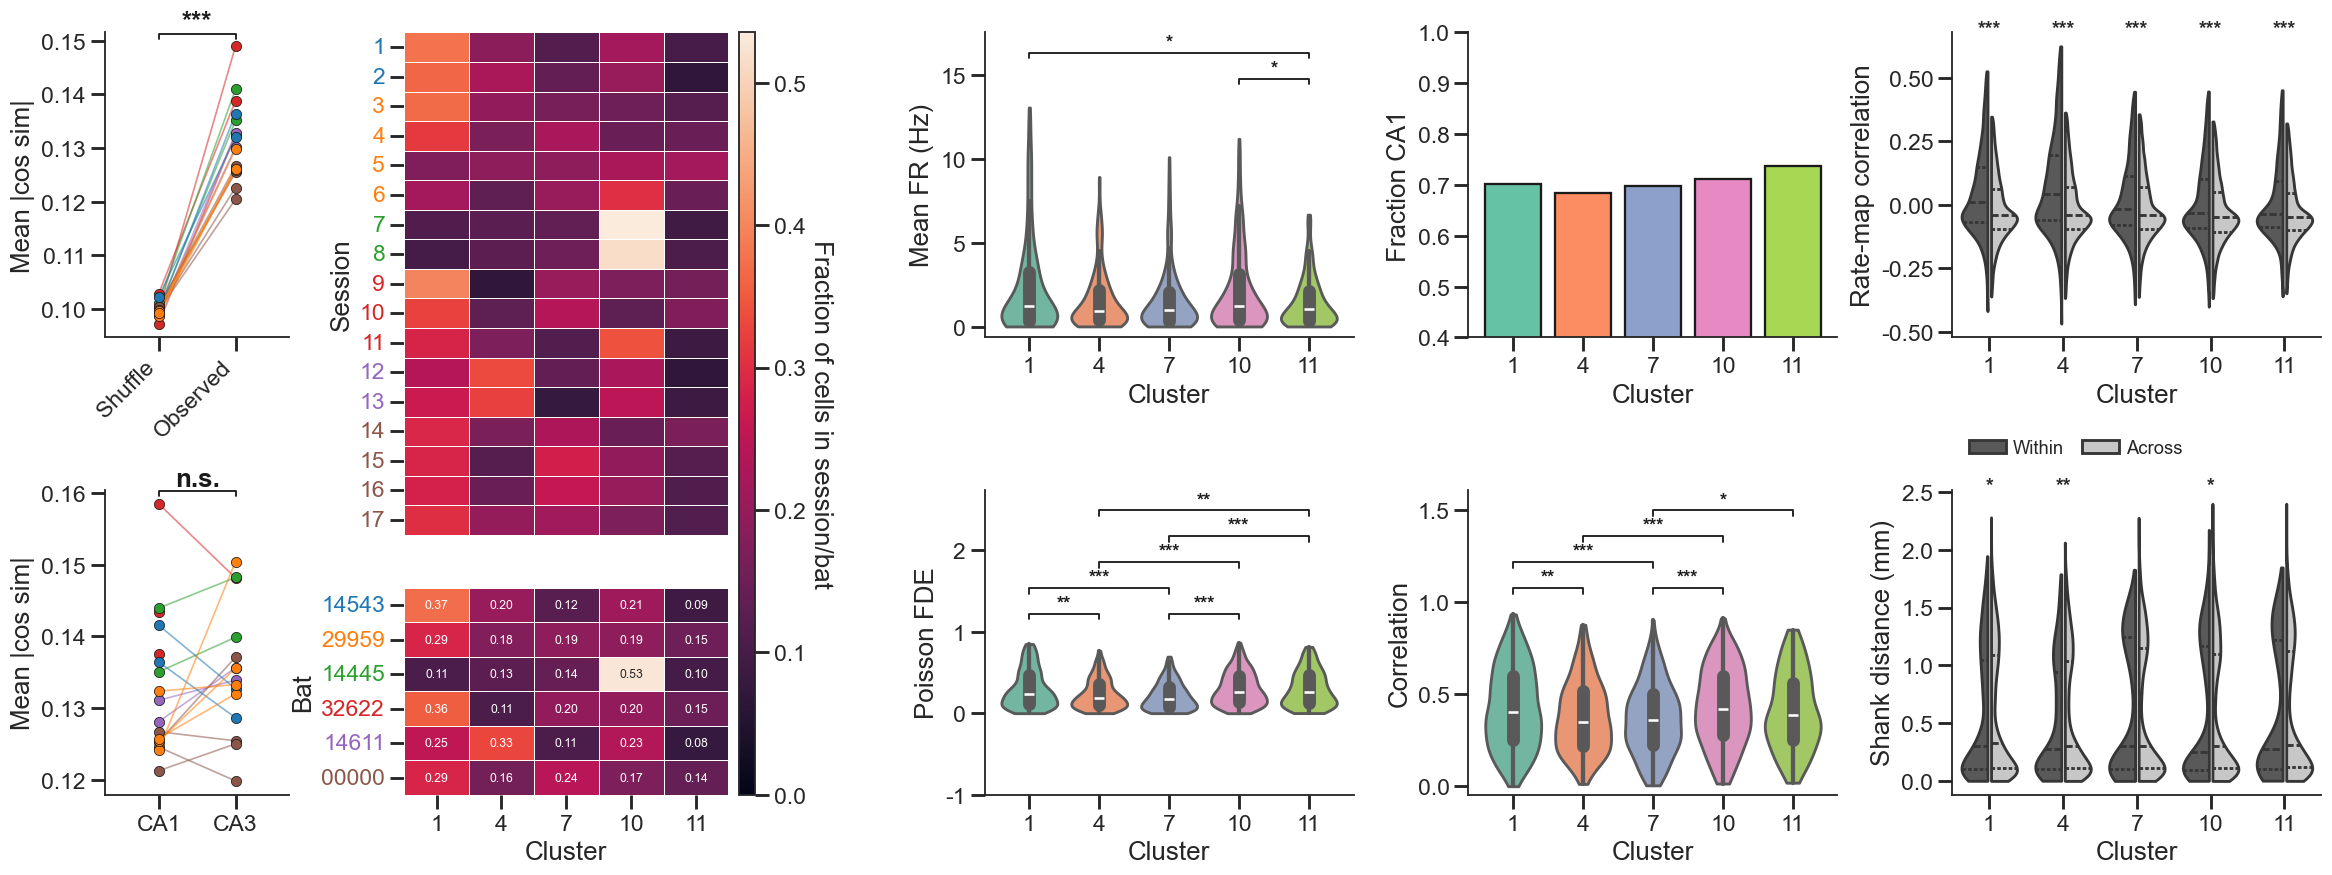

ED Fig 6 — panel statistics:
                  panel                   test          p          comparison   n  stat  med_a   med_b stars         P
                      c chi2 session x cluster  2.046e-23                 NaN NaN   NaN    NaN     NaN   *** P < 0.001
                      c     chi2 bat x cluster  9.149e-32                 NaN NaN   NaN    NaN     NaN   *** P < 0.001
                      a                    NaN  1.526e-05 observed vs shuffle  17     0 0.1301 0.09971   *** P < 0.001
                      b                    NaN     0.3303          CA3 vs CA1  15    42 0.1339  0.1281       P = 0.330
           Mean FR (Hz)         Kruskal-Wallis     0.1552                 NaN NaN   NaN    NaN     NaN       P = 0.155
           Mean FR (Hz)             MWU 1 vs 4     0.3088                 NaN NaN   NaN    NaN     NaN       P = 0.309
           Mean FR (Hz)             MWU 1 vs 7     0.3783                 NaN NaN   NaN    NaN     NaN       P = 0.378
           Mean FR 

,panel,test,p,comparison,n,stat,med_a,med_b,stars,P
0,c,chi2 session x cluster,2.045631e-23,NaN,NaN,NaN,NaN,NaN,***,P < 0.001
1,c,chi2 bat x cluster,9.148810e-32,NaN,NaN,NaN,NaN,NaN,***,P < 0.001
2,a,NaN,1.525879e-05,observed vs shuffle,17.0,0.0,0.130120,0.09971,***,P < 0.001
3,b,NaN,3.302612e-01,CA3 vs CA1,15.0,42.0,0.133894,0.12809,,P = 0.330
4,Mean FR (Hz),Kruskal-Wallis,1.552009e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.155
5,Mean FR (Hz),MWU 1 vs 4,3.087931e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.309
6,Mean FR (Hz),MWU 1 vs 7,3.783140e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.378
7,Mean FR (Hz),MWU 1 vs 10,6.622265e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.662
8,Mean FR (Hz),MWU 1 vs 11,1.270638e-02,NaN,NaN,NaN,NaN,NaN,*,P = 0.013
9,Mean FR (Hz),MWU 4 vs 7,8.967407e-01,NaN,NaN,NaN,NaN,NaN,,P = 0.897


In [47]:
# === Extended Data Figure 8 (a-i) on a single canvas ===
# Layout (column-major lettering); first column is half-width, a thin spacer
# column (col 2) sets the panel-c heatmaps off from the box panels:
#   col 0 (half): a orthogonality vs shuffle | b CA1/CA3 orthogonality
#   col 1       : c session x cluster (top) + bat x cluster (bottom) heatmaps (shared cbar)
#   col 3       : d mean FR | e FDE   (per readout cluster, pairwise MWU brackets)
#   col 4       : f fraction CA1 | g corr
#   col 5       : h rate-map corr | i shank distance  (within vs across, per cluster)
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu, fisher_exact, chi2_contingency

WA_PAL = {'within': '0.35', 'across': '0.78'}   # within/across hue (not canonical)


def cluster_brackets(ax, pair_ps):
    """Stacked significance brackets over a categorical (cluster) x-axis.

    ``pair_ps`` is a list of ``(i, j, p)``. Significant pairs (p<.05) are packed
    into rows greedily so brackets spanning non-overlapping x-ranges (e.g.
    adjacent pairs) share a row, and the whole stack floats in the top margin of
    the axes (headroom added below). Stars sit snug just above their own bracket.
    """
    sig = [(i, j, p) for i, j, p in pair_ps if np.isfinite(p) and p < 0.05]
    if not sig:
        return
    rows = []                                    # each row: list of occupied (x1,x2)
    def assign(x1, x2):
        for r, ivs in enumerate(rows):
            if all(x2 < a - 0.25 or x1 > b + 0.25 for a, b in ivs):
                ivs.append((x1, x2)); return r
        rows.append([(x1, x2)]); return len(rows) - 1
    placed = [(i, j, p, assign(i, j))            # short spans first -> lowest rows
              for i, j, p in sorted(sig, key=lambda t: (t[1] - t[0], t[0]))]
    nrows = len(rows)
    row_h, pad, bh = 0.085, 0.04, 0.018
    zone = min(0.55, pad + nrows * row_h)        # axes-fraction reserved above data
    y0, y1 = ax.get_ylim()                        # push data down into (1-zone)
    ax.set_ylim(y0, y0 + (y1 - y0) / (1 - zone))
    trans = ax.get_xaxis_transform()             # x data, y axes-fraction
    ybase = 1 - zone + pad
    for i, j, p, r in placed:
        y = ybase + r * row_h
        ax.plot([i, i, j, j], [y, y + bh, y + bh, y], transform=trans,
                lw=1.2, color='k', clip_on=False)
        ax.text((i + j) / 2, y + bh + 0.004, ph.stars_for_p(p), transform=trans,
                ha='center', va='bottom', fontsize=12, fontweight='bold',
                color='k', clip_on=False)

fig_ed8 = plt.figure(figsize=(26, 9))
gs_ed8 = fig_ed8.add_gridspec(2, 6, width_ratios=[0.5, 0.95, 0, 1, 1, 1], hspace=0.5, wspace=0.42)
A_a = fig_ed8.add_subplot(gs_ed8[0, 0]); A_b = fig_ed8.add_subplot(gs_ed8[1, 0])
A_c = fig_ed8.add_subplot(gs_ed8[0, 3]); A_d = fig_ed8.add_subplot(gs_ed8[1, 3])
A_e = fig_ed8.add_subplot(gs_ed8[0, 4]); A_f = fig_ed8.add_subplot(gs_ed8[1, 4])
A_g = fig_ed8.add_subplot(gs_ed8[0, 5]); A_h = fig_ed8.add_subplot(gs_ed8[1, 5])
cats = CLUSTER_ORDER
ed8_p = []

# --- c, d: cluster-composition heatmaps stacked in column 1 with a single shared
#           colour scale.  Rows are sessions (c) or bats (d), columns are the five
#           included readout clusters; each row is the fraction of that session's /
#           bat's well-fit cells falling in each cluster (rows sum to 1). Row
#           (y-tick) labels are coloured by bat. ---
clu_df['bat'] = clu_df['session'].map(parse_bat)
BAT_PAL = ph.bat_palette()
_incl = clu_df[clu_df['cluster'].isin(cats)]
bats_ed = [b for b in BAT_PAL if b in set(_incl['bat'])]         # canonical bat order
_bo = {b: i for i, b in enumerate(bats_ed)}
sess_meta = _incl[['session', 'bat']].drop_duplicates()
sess_meta = sess_meta.assign(_bo=sess_meta['bat'].map(_bo)).sort_values(['_bo', 'session'])
sess_order = sess_meta['session'].tolist()
sess_n = pd.crosstab(_incl['session'], _incl['cluster']).reindex(index=sess_order, columns=cats, fill_value=0)
bat_n = pd.crosstab(_incl['bat'], _incl['cluster']).reindex(index=bats_ed, columns=cats, fill_value=0)
sess_frac = sess_n.div(sess_n.sum(axis=1), axis=0)              # per-session row -> fraction
bat_frac = bat_n.div(bat_n.sum(axis=1), axis=0)
vmax = float(max(sess_frac.to_numpy().max(), bat_frac.to_numpy().max()))
gs_comp = gs_ed8[:, 1].subgridspec(2, 2, width_ratios=[1, 0.05],
                                   height_ratios=[len(sess_order), len(bats_ed) + 1],
                                   hspace=0.15, wspace=0.06)
A_comp_s = fig_ed8.add_subplot(gs_comp[0, 0])                   # c: session x cluster
A_comp_b = fig_ed8.add_subplot(gs_comp[1, 0])                   # d: bat x cluster
cax_comp = fig_ed8.add_subplot(gs_comp[:, 1])
hm_kw = dict(cmap='rocket', vmin=0, vmax=vmax, linewidths=0.5, linecolor='w', cbar=False)
sns.heatmap(sess_frac, ax=A_comp_s, **hm_kw)
A_comp_s.set(xlabel='', ylabel='session')
A_comp_s.set_yticklabels([str(i) for i in range(1, len(sess_order) + 1)], rotation=0)
A_comp_s.tick_params(axis='x', labelbottom=False, bottom=False)
for _t, _s in zip(A_comp_s.get_yticklabels(), sess_order):
    _t.set_color(BAT_PAL[parse_bat(_s)])
sns.heatmap(bat_frac, ax=A_comp_b, annot=True, fmt='.2f', annot_kws={'fontsize': 8}, **hm_kw)
A_comp_b.set(xlabel='cluster', ylabel='bat')
A_comp_b.set_yticklabels(bats_ed, rotation=0)
for _t, _b in zip(A_comp_b.get_yticklabels(), bats_ed):
    _t.set_color(BAT_PAL[_b])
_cbar = fig_ed8.colorbar(A_comp_b.collections[0], cax=cax_comp)
_cbar.set_label('Fraction of cells in session/bat', rotation=270, labelpad=18)
ed8_p.append(dict(panel='c', test='chi2 session x cluster',
                  p=chi2_contingency(sess_n.values)[1] if (sess_n.values.sum(1) > 0).all() else np.nan))
ed8_p.append(dict(panel='c', test='chi2 bat x cluster',
                  p=chi2_contingency(bat_n.values)[1] if (bat_n.values.sum(1) > 0).all() else np.nan))

# --- a: residual-readout orthogonality (mean |cos|) vs chance ---
rng = np.random.default_rng(seed)
orth = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    obs = np.abs((Wr @ Wr.T)[iu]).mean()
    R = rng.standard_normal((len(grp), Wr.shape[1]))
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    cha = np.abs((R @ R.T)[iu]).mean()
    orth.append(dict(session=sn, bat=parse_bat(sn), observed=obs, chance=cha))
orth_df = pd.DataFrame(orth)
orth_long = orth_df.melt(['session', 'bat'], ['chance', 'observed'], 'kind', 'v')
ph.paired_lines(A_a, orth_long, 'v', 'kind', ['chance', 'observed'])
ra = ph.paired_session_test(orth_long, 'v', 'kind', 'observed', 'chance')
ph.sig_bracket(A_a, 0, 1, ra['p'])
A_a.set(ylabel='mean |cos sim|')
A_a.set_xticklabels(['shuffle', 'observed'], rotation=45, ha='right')  # data key = 'chance'
A_a.set_xlim(-0.7, 1.7)                                # widen so the points sit inward
ed8_p.append(dict(panel='a', comparison='observed vs shuffle', **ra))

# --- b: within-subregion orthogonality, CA1 vs CA3 (paired by session) ---
subo = []
for (sn, sr), grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby(['session', 'subregion']):
    if len(grp) < SUB_MIN_NEURONS:   # >=10 neurons per subregion, matching Fig 4 CA1/CA3
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    subo.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                     morth=np.abs((Wr @ Wr.T)[iu]).mean()))
subo_df = pd.DataFrame(subo)
ph.paired_lines(A_b, subo_df, 'morth', 'subregion', ['CA1', 'CA3'])
rb = ph.paired_session_test(subo_df, 'morth', 'subregion', 'CA3', 'CA1')
ph.sig_bracket(A_b, 0, 1, rb['p'], show_ns=True)      # annotate n.s.
A_b.set(ylabel='mean |cos sim|')
A_b.set_xlim(-0.7, 1.7)                                # widen so the points sit inward
ed8_p.append(dict(panel='b', comparison='CA3 vs CA1', **rb))

# --- c, d, e: per-cluster mean FR / FDE / corr (Kruskal-Wallis omnibus +
#              pairwise Mann-Whitney brackets between every significant pair) ---
clu_df['is_ca1'] = (clu_df['subregion'] == 'CA1').astype(float)
clu_df.loc[~clu_df['subregion'].isin(['CA1', 'CA3']), 'is_ca1'] = np.nan
for ax, (col, ylab, clip) in zip([A_c, A_d, A_f],
                                 [('mean_fr', 'Mean FR (Hz)', False),
                                  ('fde_all', 'Poisson FDE', True),
                                  ('corr_all', 'Correlation', False)]):
    ph.cat_violin(ax, clu_df, 'cluster', col, cats, CLUSTER_PALETTE, trim_outliers=True)
    ax.set(xlabel='cluster', ylabel=ylab)
    if clip:
        ax.set_ylim(-1, 1)                       # FDE display floored at -1
    vals = {c: clu_df.loc[clu_df['cluster'] == c, col].dropna().values for c in cats}
    grps = [vals[c] for c in cats if len(vals[c]) > 1]
    p_kw = kruskal(*grps).pvalue if len(grps) >= 2 else np.nan
    ed8_p.append(dict(panel=ylab, test='Kruskal-Wallis', p=p_kw))
    pair_ps = []
    for i, j in combinations(range(len(cats)), 2):
        a, b = vals[cats[i]], vals[cats[j]]
        if len(a) < 2 or len(b) < 2:
            continue
        pp = mannwhitneyu(a, b, alternative='two-sided').pvalue
        ed8_p.append(dict(panel=ylab, test=f'MWU {cats[i]} vs {cats[j]}', p=pp))
        pair_ps.append((i, j, pp))
    cluster_brackets(ax, pair_ps)

# --- f: fraction CA1 per cluster (y-axis starts at 0.4); per-cluster Fisher ---
frac = clu_df.groupby('cluster')['is_ca1'].mean().reindex(cats)
A_e.bar(range(len(cats)), frac.values, color=[CLUSTER_PALETTE[c] for c in cats], edgecolor='k')
A_e.set(xticks=range(len(cats)), xticklabels=cats, xlabel='cluster', ylabel='Fraction CA1')
A_e.set_ylim(0.4, 1.0)
ca1n = clu_df.groupby('cluster')['is_ca1'].agg(n_ca1='sum', n=lambda s: s.notna().sum())
tot_ca1, tot_n = ca1n['n_ca1'].sum(), ca1n['n'].sum()
tab = np.array([[ca1n.loc[c, 'n_ca1'], ca1n.loc[c, 'n'] - ca1n.loc[c, 'n_ca1']] for c in cats])
p_chi = chi2_contingency(tab)[1] if (tab.sum(1) > 0).all() else np.nan
ed8_p.append(dict(panel='Fraction CA1', test='chi2 across clusters', p=p_chi))
trans_f = A_e.get_xaxis_transform()
for xi, c in enumerate(cats):
    a1 = ca1n.loc[c, 'n_ca1']; a0 = ca1n.loc[c, 'n'] - a1
    b1 = tot_ca1 - a1; b0 = (tot_n - ca1n.loc[c, 'n']) - b1
    p = fisher_exact([[a1, a0], [b1, b0]])[1]
    ed8_p.append(dict(panel=f'Fraction CA1:cluster {c}', test='Fisher vs rest', p=p))
    s = ph.stars_for_p(p)
    if s:
        A_e.text(xi, 0.96, s, transform=trans_f, ha='center', va='bottom',
                 fontsize=12, fontweight='bold', clip_on=False)


def _within_across(ax, data, ycol, ylabel, panel, *, legend=False):
    """Boxplot of within- vs across-cluster values per cluster (x), one star
    over each cluster from a within-vs-across Mann-Whitney (no bracket)."""
    _vd = ph.tukey_trim(data, ycol, ['cluster', 'kind'])   # showfliers=False analogue (display only)
    sns.violinplot(data=_vd, x='cluster', y=ycol, order=cats, hue='kind',
                   hue_order=['within', 'across'], palette=WA_PAL,
                   split=True, inner='quartile', cut=0, density_norm='width',
                   gap=0.12, ax=ax)
    trans = ax.get_xaxis_transform()
    for xi, c in enumerate(cats):
        w = data.loc[(data['cluster'] == c) & (data['kind'] == 'within'), ycol].dropna().values
        a = data.loc[(data['cluster'] == c) & (data['kind'] == 'across'), ycol].dropna().values
        p = mannwhitneyu(w, a, alternative='two-sided').pvalue if len(w) > 1 and len(a) > 1 else np.nan
        ed8_p.append(dict(panel=f'{panel}:cluster {c}', test='MWU within vs across', p=p))
        s = ph.stars_for_p(p)
        if s:
            ax.text(xi, 0.98, s, transform=trans, ha='center', va='bottom',
                    fontsize=13, fontweight='bold', clip_on=False)
    ax.set(xlabel='cluster', ylabel=ylabel)
    if legend:
        ax.legend(title='', loc='upper left', bbox_to_anchor=(0.0, -0.28), ncol=2,
                  fontsize=12, frameon=False, columnspacing=1.0, handletextpad=0.4)
    elif ax.legend_ is not None:
        ax.legend_.remove()


# --- g: rate-map correlation, within vs across cluster, per cluster ---
rm_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 2:
        continue
    units = grp['unit'].to_numpy(); cl = grp['cluster'].to_numpy()
    Cm = ratemap_corr_matrix(session_rate_maps[sn][units])
    iu, ju = np.triu_indices(len(units), 1)
    v = Cm[iu, ju]; ok = np.isfinite(v)
    for ci, cj, val in zip(cl[iu][ok], cl[ju][ok], v[ok]):
        if ci == cj:
            rm_rows.append((ci, 'within', val))
        else:
            rm_rows.append((ci, 'across', val)); rm_rows.append((cj, 'across', val))
rmc_df = pd.DataFrame(rm_rows, columns=['cluster', 'kind', 'r'])
_within_across(A_g, rmc_df, 'r', 'Rate-map correlation', 'h', legend=True)

# --- h: physical distance along shank, within vs across cluster, per cluster ---
dist_rows = []
for (sn, pr), grp in clu_df.groupby(['session', 'probe_id']):
    if len(grp) < 2:
        continue
    xy = grp[['lateral', 'depth']].to_numpy(); cl = grp['cluster'].to_numpy()
    iu, ju = np.triu_indices(len(grp), k=1)
    d = np.linalg.norm(xy[iu] - xy[ju], axis=1) / 1000.0          # µm -> mm
    for ci, cj, val in zip(cl[iu], cl[ju], d):
        if ci == cj:
            dist_rows.append((ci, 'within', val))
        else:
            dist_rows.append((ci, 'across', val)); dist_rows.append((cj, 'across', val))
dist_df = pd.DataFrame(dist_rows, columns=['cluster', 'kind', 'd'])
_within_across(A_h, dist_df, 'd', 'Shank distance (mm)', 'i')

ph.save_fig(fig_ed8, 'edfig8_full'); plt.show()
print('ED Fig 8 — panel statistics:'); ph.p_table(ed8_p)

**Extended Data Figure 8 | Residual readout cluster comparisons.** (A) Residual readout weights are less orthogonal (higher within-session mean absolute cosine similarity) than random unit vectors of matched dimension. Each line is one session (colored by bat), plotted as the per-session mean; observed versus shuffle compared by two-sided paired Wilcoxon signed-rank test on per-session values ($P = 1.53 \times 10^{-5}$; n = 17 sessions). (B) Orthogonality (within-subregion mean absolute cosine similarity) does not differ between CA1 and CA3; two-sided paired Wilcoxon signed-rank, $P = 0.330$, n.s.; n = 15 sessions with $\ge$10 neurons per subregion. (C) Fraction of each session's (top) or each bat's (bottom) well-fit neurons (Poisson FDE > 0), restricted to the five analyzed readout clusters, falling in each cluster. (D–G) Mean firing rate, fraction of CA1 neurons, Poisson FDE, and Pearson correlation per cluster. For (E), $\chi^{2}$ test of independence across clusters as omnibus, $P = 0.775$; two-sided Fisher's exact test of each cluster's CA1/CA3 split versus the pooled remaining clusters, all n.s.). For other panels, Kruskal–Wallis omnibus across clusters; brackets mark every significant pairwise two-sided Mann–Whitney U comparison. Mean FR: omnibus $P = 0.155$ (n.s.); significant pairs 1 vs 11 $P = 0.0127$, 10 vs 11 $P = 0.0279$. Poisson FDE: omnibus $P = 2.91 \times 10^{-8}$; significant pairs 1 vs 4 $P = 0.0026$, 1 vs 7 $P = 1.70 \times 10^{-5}$, 4 vs 10 $P = 3.18 \times 10^{-5}$, 4 vs 11 $P = 0.00462$, 7 vs 10 $P = 5.40 \times 10^{-8}$, 7 vs 11 $P = 8.23 \times 10^{-5}$. Pearson correlation: omnibus $P = 3.87 \times 10^{-5}$; significant pairs 1 vs 4 $P = 0.00457$, 1 vs 7 $P = 3.48 \times 10^{-4}$, 4 vs 10 $P = 4.84 \times 10^{-4}$, 7 vs 10 $P = 2.60 \times 10^{-5}$, 7 vs 11 $P = 0.0379$). (H–I) Rate-map correlation (H) and physical distance along the shank (I, mm) for neuron pairs within versus across cluster, shown per cluster, with a two-sided Mann–Whitney U comparing within versus across. (H) Cluster 1 $P = 2.19 \times 10^{-185}$, 4 $P = 3.13 \times 10^{-133}$, 7 $P = 3.65 \times 10^{-26}$, 10 $P = 4.31 \times 10^{-52}$, 11 $P = 4.40 \times 10^{-17}$. (I) Cluster 1 $P = 0.0118$, 4 $P = 0.00157$, 7 $P = 0.384$ (n.s.), 10 $P = 0.0264$, 11 $P = 0.834$ (n.s.).

## Extended Data Table 1 — Auxiliary masking-task sweep

Joint **Twin** model trained from scratch (1000 epochs, early stopping) at the
`base_6.3` hyperparameters (L4 / d64 / ff64, lr 4.5e-3, weight decay 3e-4, lam 0.61,
pos_weight 0.84), over `encode`+`decode` plus **every subset (0–4) of the four auxiliary
self-supervised masking tasks** `{within, cross, forecast, forecast_stim}` — 16
combinations. Scheme sampling weights are fixed at `w_encode`=1.93, `w_decode`=2.83, with
the **total auxiliary-task probability held constant** across combinations by setting
`w_aux = 0.67·3 / n_aux` (so `n_aux`=3 recovers 0.67 each). Models are selected on the
**validation** joint score `0.5·FDE/0.1 - 0.5·err/0.3`; the test column is shown for
reference. Reproduction / training code: `joint-encode-decode.ipynb` §6.8, which writes
`./out/joint/joint_scheme_sweep.pkl`. For reference, the warm-started fine-tune scores
test joint 0.127 and the `base_6.3` consensus 0.064.

In [ ]:
# === Extended Data Table 1: auxiliary masking-task sweep ===
# Loads the 16-combo sweep produced by joint-encode-decode.ipynb section 6.8 and tabulates
# it. Each combo = encode+decode plus a subset of {within, cross, forecast, forecast_stim},
# trained from scratch (1000 ep, early stopping) at the base_6.3 hyperparameters; scheme
# weights w_encode=1.93, w_decode=2.83 fixed, total aux probability held constant via
# w_aux = 0.67*3/n_aux. Model selection is on validation joint (test shown for reference).
_sweep = pd.read_pickle('./out/joint/joint_scheme_sweep.pkl')
_rows = []
for _key, _rec in _sweep.items():
    _aux = [s for s in _rec['schemes'] if s not in ('encode', 'decode')]
    _rows.append({
        'auxiliary tasks': ' + '.join(_aux) if _aux else '(none)',
        'n_aux': _rec['n_aux'],
        'w_aux': round(_rec['w_aux'], 3),
        'decode err (m)': _rec['test']['err'],
        'encode FDE': _rec['test']['fde'],
        'joint (valid)': _rec['valid']['joint'],
        'joint (test)': _rec['test']['joint'],
    })
ed_table1 = (pd.DataFrame(_rows)
             .sort_values('joint (valid)', ascending=False)
             .reset_index(drop=True))
ed_table1.index += 1                       # 1-based rank
ed_table1.to_csv('out/figures/ed_table1_scheme_sweep.csv')
print(f'Extended Data Table 1 - auxiliary masking-task sweep of the {OUR_MODEL} model')
print('(model selection on validation joint; 16 combos, base_6.3 hyperparameters)')
# --- LaTeX version for the manuscript: writes out/figures/ed_table1_scheme_sweep.tex ---
# booktabs only (no siunitx); swap table -> table* for a two-column layout.
_TEX_CAPTION = (
    r'\textbf{Extended Data Table 1 $|$ Auxiliary masking-task sweep.} '
    r'The joint Twin model was trained from scratch (1{,}000 epochs, early stopping, 4 transformer layers, latent dimension $d = 64$, feed-forward width 64, learning rate $4.5 \times 10^{-3}$, weight decay $3 \times 10^{-4}$, decoding weight $\lambda = 0.61$, positive weight 0.84) on the \texttt{encode} and \texttt{decode} tasks plus every subset (0--4) of the four auxiliary self-supervised masking tasks \texttt{within}, \texttt{cross} (also called \texttt{infill} in the main text), \texttt{forecast} and \texttt{forecast\_stim} --- 16 combinations in total. Scheme sampling weights are fixed at $w_{\mathrm{encode}} = 1.93$ and $w_{\mathrm{decode}} = 2.83$, and the total auxiliary-task probability is held constant across combinations by setting $w_{\mathrm{aux}} = 0.67 \times 3 / n_{\mathrm{aux}}$. Rows are ranked by the validation joint score $0.5 \, (\mathrm{FDE}/0.1) - 0.5 \, (\mathrm{err}/0.3)$, which is the model-selection criterion; the decode error, encode FDE and joint score in the remaining columns are held-out test values, shown for reference only. The combination with the best validation score is shown in bold. For reference, the further fine-tuning the parameters of the \texttt{cross} model reaches a test joint score of $0.127$.')


def _tex_num(v, nd=4):
    """Fixed-width number with a proper math minus sign."""
    return (r'$-$' if v < 0 else '') + f'{abs(v):.{nd}f}'


def _tex_tasks(s):
    return s if s == '(none)' else ' + '.join(r'\texttt{' + t.replace('_', r'\_') + '}'
                                              for t in s.split(' + '))


_tex_rows = []
for _rank, _r in ed_table1.iterrows():
    _cells = [str(_rank), _tex_tasks(_r['auxiliary tasks']), str(int(_r['n_aux'])),
              f"{_r['w_aux']:.3f}", _tex_num(_r['decode err (m)']), _tex_num(_r['encode FDE']),
              _tex_num(_r['joint (valid)']), _tex_num(_r['joint (test)'])]
    if _rank == 1:                                   # best validation joint
        _cells = [r'\textbf{' + _c + '}' for _c in _cells]
    _tex_rows.append('  ' + ' & '.join(_cells) + r' \\')

_tex = '\n'.join([
    r'% Extended Data Table 1 -- auxiliary masking-task sweep.',
    r'% Requires \usepackage{booktabs} and \usepackage{array}. Use table* if two-column.',
    r'\begin{table}[htbp]',
    r'\centering',
    r'\small',
    r'\setlength{\tabcolsep}{4pt}',
    r'\caption{' + _TEX_CAPTION + '}',
    r'\label{tab:S1}',
    r'\begin{tabular}{c>{\raggedright\arraybackslash}p{3.6cm}ccrrrr}',   # p{} wraps the task list
    r'\toprule',
    r'Rank & Auxiliary tasks & $n_{\mathrm{aux}}$ & $w_{\mathrm{aux}}$ & Decode err.\ (m) & '
    r'Encode FDE & Joint (valid) & Joint (test) \\',
    r'\midrule',
    *_tex_rows,
    r'\bottomrule',
    r'\end{tabular}',
    r'\end{table}',
])
with open('out/figures/ed_table1_scheme_sweep.tex', 'w') as _fh:
    _fh.write(_tex + '\n')
print('\nwrote out/figures/ed_table1_scheme_sweep.tex')
ed_table1.round(4)

Extended Data Table 1 - auxiliary masking-task sweep of the Twin model
(model selection on validation joint; 16 combos, base_6.3 hyperparameters)


,auxiliary tasks,n_aux,w_aux,decode err (m),encode FDE,joint (valid),joint (test)
1,cross,1,2.010,0.2812,0.1093,0.0747,0.0781
2,within + cross + forecast + forecast_stim,4,0.503,0.2859,0.1139,0.0387,0.0929
3,within + forecast_stim,2,1.005,0.2878,0.1159,0.0309,0.0997
4,within + cross,2,1.005,0.2806,0.1099,0.0236,0.0815
5,cross + forecast_stim,2,1.005,0.2940,0.1084,0.0223,0.0518
6,cross + forecast,2,1.005,0.2900,0.1088,0.0108,0.0605
7,within + cross + forecast,3,0.670,0.2769,0.1129,0.0071,0.1032
8,(none),0,0.000,0.2951,0.1029,-0.0087,0.0228
9,within + forecast,2,1.005,0.3045,0.1052,-0.0094,0.0185
10,within + cross + forecast_stim,3,0.670,0.2863,0.1152,-0.0116,0.0989
